In [1]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4: DIABETES
# STEP 01 - DATASET_REF CONSTRUCTION AND MINIMAL AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

RAW_FILE = ROOT / "data" / "raw" / "diabetes.csv"

REFERENCE_DIR = ROOT / "data" / "reference"
RESULTS_DIR = ROOT / "results" / "01_reference"

REFERENCE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REF_FILE = REFERENCE_DIR / "Dataset_REF.csv"


# ============================================================
# 2. EXPECTED SCHEMA
# ============================================================

EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

TARGET = "Outcome"

FEATURES = [c for c in EXPECTED_COLUMNS if c != TARGET]


# ============================================================
# 3. FILE HASH FUNCTION
# ============================================================

def sha256_file(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(block)

    return sha256.hexdigest()


# ============================================================
# 4. LOAD RAW DATASET
# ============================================================

if not RAW_FILE.exists():
    raise FileNotFoundError(
        f"Raw dataset not found:\n{RAW_FILE}"
    )

df_raw = pd.read_csv(RAW_FILE)

print("Dataset loaded successfully.")
print("Shape:", df_raw.shape)


# ============================================================
# 5. SCHEMA VALIDATION
# ============================================================

actual_columns = list(df_raw.columns)

if actual_columns != EXPECTED_COLUMNS:
    raise ValueError(
        "Unexpected dataset schema.\n"
        f"Expected: {EXPECTED_COLUMNS}\n"
        f"Found:    {actual_columns}"
    )

print("\nSchema validation: PASS")


# ============================================================
# 6. BASIC INTEGRITY CHECKS
# ============================================================

n_rows = len(df_raw)
n_columns = df_raw.shape[1]

duplicate_rows = int(df_raw.duplicated().sum())

missing_counts = df_raw.isna().sum()
missing_total = int(missing_counts.sum())

print("\nRows:", n_rows)
print("Columns:", n_columns)
print("Duplicate rows:", duplicate_rows)
print("Missing values:", missing_total)


# ============================================================
# 7. TARGET VALIDATION
# ============================================================

target_values = sorted(df_raw[TARGET].dropna().unique().tolist())

if not set(target_values).issubset({0, 1}):
    raise ValueError(
        f"Unexpected Outcome values: {target_values}"
    )

target_summary = (
    df_raw[TARGET]
    .value_counts(dropna=False)
    .rename_axis("Outcome")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    100 * target_summary["count"] / n_rows
)

print("\nTarget distribution:")
print(target_summary)


# ============================================================
# 8. FEATURE SUMMARY
# ============================================================

summary_rows = []

for col in df_raw.columns:

    s = df_raw[col]

    summary_rows.append({
        "feature": col,
        "dtype": str(s.dtype),
        "n": int(len(s)),
        "non_missing": int(s.notna().sum()),
        "missing": int(s.isna().sum()),
        "missing_percent": float(
            100 * s.isna().mean()
        ),
        "unique_values": int(s.nunique(dropna=True)),
        "minimum": float(s.min()) if pd.api.types.is_numeric_dtype(s) else None,
        "maximum": float(s.max()) if pd.api.types.is_numeric_dtype(s) else None,
        "mean": float(s.mean()) if pd.api.types.is_numeric_dtype(s) else None,
        "median": float(s.median()) if pd.api.types.is_numeric_dtype(s) else None
    })

feature_summary = pd.DataFrame(summary_rows)


# ============================================================
# 9. MISSING-VALUE SUMMARY
# ============================================================

missing_summary = pd.DataFrame({
    "feature": df_raw.columns,
    "missing_count": [
        int(df_raw[c].isna().sum())
        for c in df_raw.columns
    ],
    "missing_percent": [
        float(100 * df_raw[c].isna().mean())
        for c in df_raw.columns
    ]
})


# ============================================================
# 10. CREATE Dataset_REF
# ============================================================

# IMPORTANT:
# No cleaning
# No imputation
# No deletion
# No outlier modification
# No artificial missing-value injection

df_ref = df_raw.copy(deep=True)

df_ref.to_csv(
    REF_FILE,
    index=False
)


# ============================================================
# 11. HASHES
# ============================================================

raw_sha256 = sha256_file(RAW_FILE)
ref_sha256 = sha256_file(REF_FILE)

print("\nRAW SHA-256:")
print(raw_sha256)

print("\nDataset_REF SHA-256:")
print(ref_sha256)


# ============================================================
# 12. EXPORT TABLES
# ============================================================

feature_summary.to_csv(
    RESULTS_DIR / "step01_feature_summary.csv",
    index=False
)

missing_summary.to_csv(
    RESULTS_DIR / "step01_missing_summary.csv",
    index=False
)

target_summary.to_csv(
    RESULTS_DIR / "step01_target_summary.csv",
    index=False
)


# ============================================================
# 13. METADATA / TRACEABILITY
# ============================================================

metadata = {

    "case_study": "CASE_STUDY_4_DIABETES",

    "step": "STEP_01_REFERENCE",

    "created_utc": datetime.now(timezone.utc).isoformat(),

    "raw_file": str(RAW_FILE),

    "reference_file": str(REF_FILE),

    "raw_sha256": raw_sha256,

    "dataset_ref_sha256": ref_sha256,

    "rows": n_rows,

    "columns": n_columns,

    "features": FEATURES,

    "target": TARGET,

    "target_values": target_values,

    "duplicate_rows_observed": duplicate_rows,

    "missing_values_observed": missing_total,

    # Epistemic / experimental safeguards
    "rows_deleted": 0,

    "duplicates_removed": False,

    "missing_values_imputed": False,

    "missing_values_injected": False,

    "outliers_modified": False,

    "measurements_corrected": False,

    "feature_engineering_applied": False,

    "dq_intervention_applied": False,

    "notes": (
        "Dataset_REF is created without any data-quality "
        "intervention. Observed values are described but are "
        "not classified as errors or anomalies at this stage."
    )
}

with open(
    RESULTS_DIR / "step01_dataset_ref_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

df_check = pd.read_csv(REF_FILE)

assert df_check.shape == df_raw.shape
assert list(df_check.columns) == list(df_raw.columns)

print("\n========================================")
print("STEP 01 COMPLETED")
print("========================================")

print("Dataset_REF:", REF_FILE)
print("Shape:", df_ref.shape)
print("Missing values:", missing_total)
print("Duplicate rows:", duplicate_rows)

print("\nNo DQ intervention applied.")

Dataset loaded successfully.
Shape: (768, 9)

Schema validation: PASS

Rows: 768
Columns: 9
Duplicate rows: 0
Missing values: 0

Target distribution:
   Outcome  count  percentage
0        0    500   65.104167
1        1    268   34.895833

RAW SHA-256:
e25ebf48cce3c03cacbbdd007e356ad0a2f7818747cf471f79371f9753869697

Dataset_REF SHA-256:
43b6df3b2bb01723f93555969194a0712cf5319df1a74ecb1c8f4f56f0c23a1e

STEP 01 COMPLETED
Dataset_REF: C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\data\reference\Dataset_REF.csv
Shape: (768, 9)
Missing values: 0
Duplicate rows: 0

No DQ intervention applied.


In [2]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4: DIABETES
# STEP 02 - STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import json
from sklearn.model_selection import train_test_split
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = ROOT / "data" / "reference" / "Dataset_REF.csv"

RESULTS_DIR = ROOT / "results" / "01_reference"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. PARAMETERS
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

RANDOM_STATE = 42

TRAIN_RATIO = 0.60
VALIDATION_RATIO = 0.20
TEST_RATIO = 0.20


# ============================================================
# 3. HASH FUNCTION
# ============================================================

def sha256_file(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(block)

    return sha256.hexdigest()


# ============================================================
# 4. LOAD Dataset_REF
# ============================================================

df = pd.read_csv(REF_FILE)

print("Dataset_REF loaded.")
print("Shape:", df.shape)

ref_sha256 = sha256_file(REF_FILE)

print("Dataset_REF SHA-256:")
print(ref_sha256)


# ============================================================
# 5. FIRST SPLIT
#    60% TRAIN / 40% TEMP
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    stratify=df[TARGET],
    random_state=RANDOM_STATE
)


# ============================================================
# 6. SECOND SPLIT
#    TEMP -> 20% VALIDATION / 20% TEST
# ============================================================

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df[TARGET],
    random_state=RANDOM_STATE
)


# ============================================================
# 7. SORT BY ORIGINAL ROW INDEX
# ============================================================

train_df = train_df.sort_index()
validation_df = validation_df.sort_index()
test_df = test_df.sort_index()


# ============================================================
# 8. VERIFY DISJOINT SETS
# ============================================================

train_idx = set(train_df.index)
validation_idx = set(validation_df.index)
test_idx = set(test_df.index)

assert train_idx.isdisjoint(validation_idx)
assert train_idx.isdisjoint(test_idx)
assert validation_idx.isdisjoint(test_idx)

assert (
    len(train_df)
    + len(validation_df)
    + len(test_df)
    == len(df)
)

print("\nSplit integrity: PASS")


# ============================================================
# 9. CREATE SPLIT ASSIGNMENT TABLE
# ============================================================

split_assignment = pd.DataFrame(
    index=df.index
)

split_assignment["row_id"] = df.index
split_assignment["split"] = None

split_assignment.loc[train_df.index, "split"] = "TRAIN"
split_assignment.loc[validation_df.index, "split"] = "VALIDATION"
split_assignment.loc[test_df.index, "split"] = "TEST"

assert split_assignment["split"].isna().sum() == 0


# ============================================================
# 10. SPLIT SUMMARY
# ============================================================

summary_rows = []

for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", validation_df),
    ("TEST", test_df)
]:

    n = len(split_df)

    counts = split_df[TARGET].value_counts().to_dict()

    n0 = int(counts.get(0, 0))
    n1 = int(counts.get(1, 0))

    summary_rows.append({
        "split": split_name,
        "n": n,
        "percentage_dataset": 100 * n / len(df),

        "outcome_0": n0,
        "outcome_1": n1,

        "outcome_0_percent": 100 * n0 / n,
        "outcome_1_percent": 100 * n1 / n
    })

split_summary = pd.DataFrame(summary_rows)

print("\nSplit summary:")
print(split_summary.to_string(index=False))


# ============================================================
# 11. EXPORT SPLIT ASSIGNMENT
# ============================================================

SPLIT_FILE = RESULTS_DIR / "step02_split_assignment.csv"

split_assignment.to_csv(
    SPLIT_FILE,
    index=False
)

SUMMARY_FILE = RESULTS_DIR / "step02_split_summary.csv"

split_summary.to_csv(
    SUMMARY_FILE,
    index=False
)


# ============================================================
# 12. HASH SPLIT ASSIGNMENT
# ============================================================

split_sha256 = sha256_file(SPLIT_FILE)


# ============================================================
# 13. METADATA
# ============================================================

metadata = {

    "case_study": "CASE_STUDY_4_DIABETES",

    "step": "STEP_02_DATA_SPLIT",

    "created_utc": datetime.now(timezone.utc).isoformat(),

    "dataset_ref": str(REF_FILE),

    "dataset_ref_sha256": ref_sha256,

    "split_assignment_file": str(SPLIT_FILE),

    "split_assignment_sha256": split_sha256,

    "target": TARGET,

    "features": FEATURES,

    "random_state": RANDOM_STATE,

    "stratification_variable": TARGET,

    "train_ratio_requested": TRAIN_RATIO,

    "validation_ratio_requested": VALIDATION_RATIO,

    "test_ratio_requested": TEST_RATIO,

    "train_n": len(train_df),

    "validation_n": len(validation_df),

    "test_n": len(test_df),

    "test_usage_policy": (
        "TEST is reserved for final frozen experimental "
        "comparisons and must not be used for SHAP feature "
        "selection or candidate-action selection."
    ),

    "missing_values_imputed": False,

    "missing_values_injected": False,

    "rows_deleted": 0,

    "dq_intervention_applied": False
}


with open(
    RESULTS_DIR / "step02_split_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 14. FINAL OUTPUT
# ============================================================

print("\n========================================")
print("STEP 02 COMPLETED")
print("========================================")

print("TRAIN:", len(train_df))
print("VALIDATION:", len(validation_df))
print("TEST:", len(test_df))

print("\nSplit assignment SHA-256:")
print(split_sha256)

print("\nNo missing-value injection.")
print("No imputation.")
print("No DQ intervention.")
print("TEST reserved for final frozen comparison.")

Dataset_REF loaded.
Shape: (768, 9)
Dataset_REF SHA-256:
43b6df3b2bb01723f93555969194a0712cf5319df1a74ecb1c8f4f56f0c23a1e

Split integrity: PASS

Split summary:
     split   n  percentage_dataset  outcome_0  outcome_1  outcome_0_percent  outcome_1_percent
     TRAIN 460           59.895833        299        161          65.000000          35.000000
VALIDATION 154           20.052083        100         54          64.935065          35.064935
      TEST 154           20.052083        101         53          65.584416          34.415584

STEP 02 COMPLETED
TRAIN: 460
VALIDATION: 154
TEST: 154

Split assignment SHA-256:
d73c2d002470e090517582f2cccc9b1c074c130458d45b6482ba5cdcc5b4f497

No missing-value injection.
No imputation.
No DQ intervention.
TEST reserved for final frozen comparison.


Dataset_REF loaded: (768, 9)
Split assignment loaded: (768, 2)

TRAIN: (460, 8)
VALIDATION: (154, 8)
TEST: (154, 8)

Split integrity: PASS
Missing values: 0
DQ intervention: NONE

Best iteration: 71
Final tree count: 72

Model_REF SHA-256:
6463fa6cccfbb1fc1032d8eaf01d9f17ebd66659786feca60b8893659aefcfe7

Performance_REF:
     split   n  roc_auc  accuracy  balanced_accuracy  precision   recall       f1  tn  fp  fn  tp
     TRAIN 460 0.987017  0.952174           0.938844   0.966443 0.894410 0.929032 294   5  17 144
VALIDATION 154 0.942222  0.870130           0.857407   0.814815 0.814815 0.814815  90  10  10  44


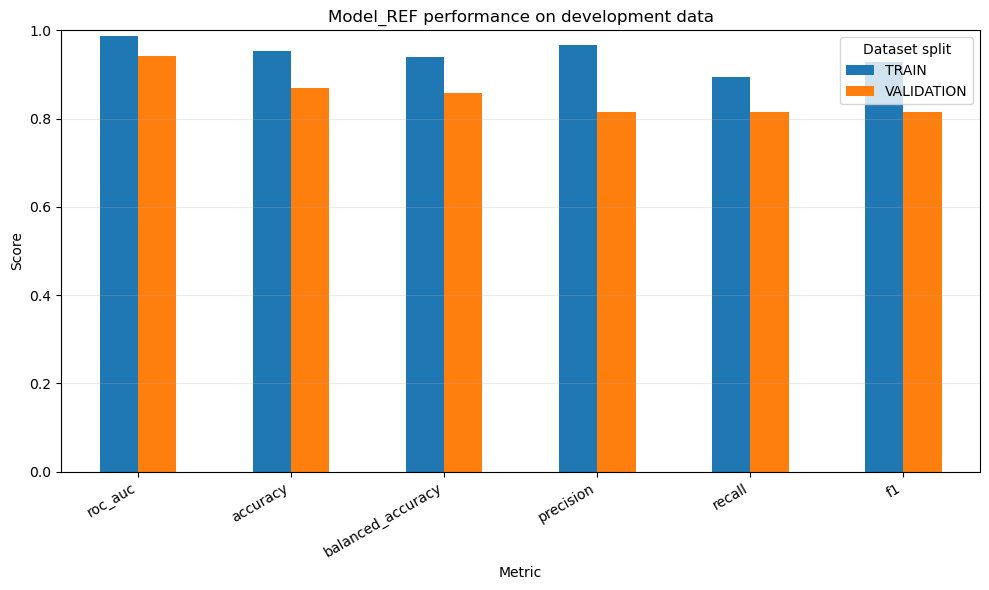

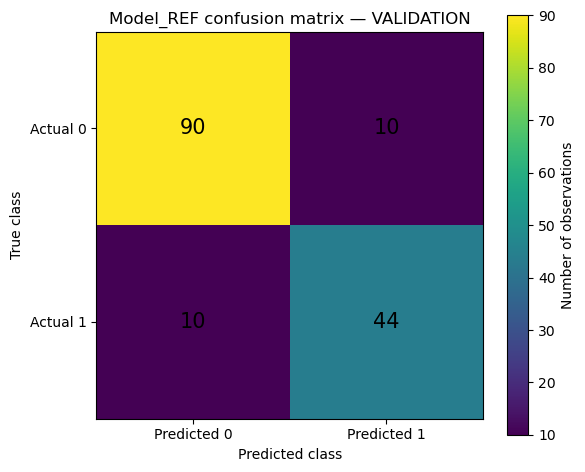

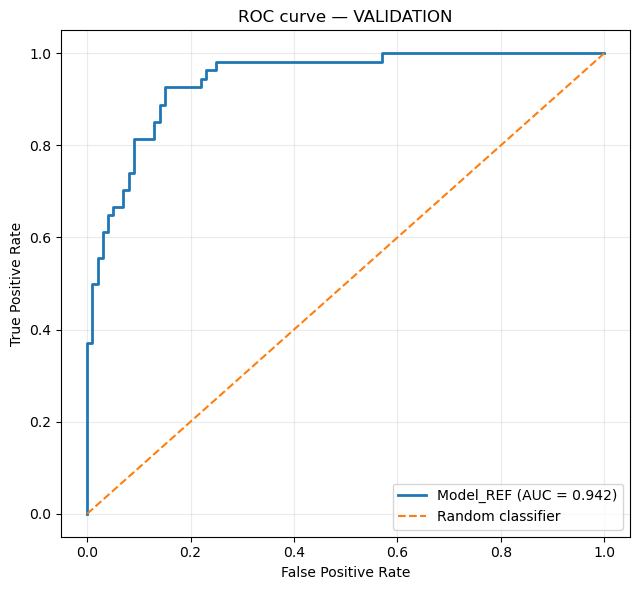


STEP 03 COMPLETED
OK - Model_REF.cbm
OK - step03_model_ref_metrics.csv
OK - step03_model_ref_predictions.csv
OK - table_step03_performance_ref.csv
OK - table_step03_confusion_matrix.csv
OK - figure_step03_performance_ref.png
OK - figure_step03_performance_ref.pdf
OK - figure_step03_confusion_matrix_validation.png
OK - figure_step03_confusion_matrix_validation.pdf
OK - figure_step03_roc_validation.png
OK - figure_step03_roc_validation.pdf
OK - step03_model_ref_metadata.json
OK - step03_documentary_manifest.json

TEST evaluated: NO
Missing injection: NO
DQ intervention: NONE


In [6]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4: DIABETES
# STEP 03 - MODEL_REF + PERFORMANCE + DOCUMENTATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import hashlib
from datetime import datetime, timezone

from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT / "data" / "reference" / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT / "results" / "01_reference"
    / "step02_split_assignment.csv"
)

MODEL_DIR = ROOT / "models" / "Model_REF"
RESULTS_DIR = ROOT / "results" / "02_model_ref"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

for directory in [
    MODEL_DIR,
    RESULTS_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODEL_DIR / "Model_REF.cbm"


# ============================================================
# 2. CONFIGURATION
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

RANDOM_STATE = 42


# ============================================================
# 3. HASH FUNCTION
# ============================================================

def sha256_file(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha256.update(block)

    return sha256.hexdigest()


# ============================================================
# 4. LOAD DATA
# ============================================================

if not REF_FILE.exists():
    raise FileNotFoundError(
        f"Dataset_REF not found:\n{REF_FILE}"
    )

if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Split file not found:\n{SPLIT_FILE}"
    )

df = pd.read_csv(REF_FILE)

split_assignment = pd.read_csv(SPLIT_FILE)

assert len(df) == len(split_assignment)

assert np.array_equal(
    split_assignment["row_id"].to_numpy(),
    np.arange(len(df))
)

print("Dataset_REF loaded:", df.shape)
print("Split assignment loaded:", split_assignment.shape)


# ============================================================
# 5. RECONSTRUCT FIXED SPLITS
# ============================================================

split = split_assignment["split"]

train_df = df.loc[
    split == "TRAIN"
].copy()

validation_df = df.loc[
    split == "VALIDATION"
].copy()

test_df = df.loc[
    split == "TEST"
].copy()


X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]


print("\nTRAIN:", X_train.shape)
print("VALIDATION:", X_validation.shape)
print("TEST:", X_test.shape)


# ============================================================
# 6. INTEGRITY CHECKS
# ============================================================

assert len(X_train) == 460
assert len(X_validation) == 154
assert len(X_test) == 154

assert X_train.isna().sum().sum() == 0
assert X_validation.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("\nSplit integrity: PASS")
print("Missing values: 0")
print("DQ intervention: NONE")


# ============================================================
# 7. TRAIN Model_REF
# ============================================================

model = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    l2_leaf_reg=3,
    verbose=False,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_validation, y_validation),
    early_stopping_rounds=100,
    verbose=False
)


best_iteration = model.get_best_iteration()

print("\nBest iteration:", best_iteration)


# ============================================================
# 8. SHRINK MODEL
# ============================================================

if best_iteration is not None and best_iteration >= 0:

    model.shrink(
        ntree_end=best_iteration + 1
    )

print(
    "Final tree count:",
    model.tree_count_
)


# ============================================================
# 9. SAVE MODEL
# ============================================================

model.save_model(
    str(MODEL_FILE)
)

model_sha256 = sha256_file(
    MODEL_FILE
)

print("\nModel_REF SHA-256:")
print(model_sha256)


# ============================================================
# 10. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    X,
    y,
    split_name
):

    probabilities = (
        model.predict_proba(X)[:, 1]
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = {

        "split": split_name,

        "n": len(y),

        "roc_auc":
            roc_auc_score(
                y,
                probabilities
            ),

        "accuracy":
            accuracy_score(
                y,
                predictions
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y,
                predictions
            ),

        "precision":
            precision_score(
                y,
                predictions,
                zero_division=0
            ),

        "recall":
            recall_score(
                y,
                predictions,
                zero_division=0
            ),

        "f1":
            f1_score(
                y,
                predictions,
                zero_division=0
            ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

    predictions_df = pd.DataFrame({

        "row_id": X.index,

        "split": split_name,

        "y_true":
            y.to_numpy(),

        "y_probability":
            probabilities,

        "y_pred":
            predictions
    })

    return (
        metrics,
        predictions_df
    )


# ============================================================
# 11. TRAIN + VALIDATION PERFORMANCE
# TEST IS NOT EVALUATED
# ============================================================

train_metrics, train_predictions = evaluate_model(
    model,
    X_train,
    y_train,
    "TRAIN"
)

val_metrics, val_predictions = evaluate_model(
    model,
    X_validation,
    y_validation,
    "VALIDATION"
)


metrics_df = pd.DataFrame([
    train_metrics,
    val_metrics
])

predictions_df = pd.concat(
    [
        train_predictions,
        val_predictions
    ],
    ignore_index=True
)


print("\nPerformance_REF:")
print(
    metrics_df.to_string(
        index=False
    )
)


# ============================================================
# 12. SAVE RAW RESULTS
# ============================================================

METRICS_FILE = (
    RESULTS_DIR /
    "step03_model_ref_metrics.csv"
)

PREDICTIONS_FILE = (
    RESULTS_DIR /
    "step03_model_ref_predictions.csv"
)

metrics_df.to_csv(
    METRICS_FILE,
    index=False
)

predictions_df.to_csv(
    PREDICTIONS_FILE,
    index=False
)


# ============================================================
# 13. PUBLICATION TABLES
# ============================================================

performance_table = metrics_df[
    [
        "split",
        "n",
        "roc_auc",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1"
    ]
].copy()

performance_table.to_csv(
    TABLES_DIR /
    "table_step03_performance_ref.csv",
    index=False
)


confusion_table = metrics_df[
    [
        "split",
        "tn",
        "fp",
        "fn",
        "tp"
    ]
].copy()

confusion_table.to_csv(
    TABLES_DIR /
    "table_step03_confusion_matrix.csv",
    index=False
)


# ============================================================
# 14. FIGURE 1 - PERFORMANCE COMPARISON
# ============================================================

plot_metrics = [
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]

plot_df = (
    performance_table
    .set_index("split")[plot_metrics]
    .T
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

plot_df.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Model_REF performance on development data"
)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")

ax.set_ylim(0, 1)

ax.legend(
    title="Dataset split"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "figure_step03_performance_ref.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR /
    "figure_step03_performance_ref.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 15. FIGURE 2 - VALIDATION CONFUSION MATRIX
# ============================================================

cm_validation = np.array([
    [
        val_metrics["tn"],
        val_metrics["fp"]
    ],
    [
        val_metrics["fn"],
        val_metrics["tp"]
    ]
])


fig, ax = plt.subplots(
    figsize=(6, 5)
)

image = ax.imshow(
    cm_validation
)

for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            cm_validation[i, j],
            ha="center",
            va="center",
            fontsize=15
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Predicted 0",
    "Predicted 1"
])

ax.set_yticklabels([
    "Actual 0",
    "Actual 1"
])

ax.set_xlabel(
    "Predicted class"
)

ax.set_ylabel(
    "True class"
)

ax.set_title(
    "Model_REF confusion matrix — VALIDATION"
)

fig.colorbar(
    image,
    ax=ax,
    label="Number of observations"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "figure_step03_confusion_matrix_validation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR /
    "figure_step03_confusion_matrix_validation.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 16. FIGURE 3 - VALIDATION ROC CURVE
# ============================================================

val_probabilities = (
    model.predict_proba(
        X_validation
    )[:, 1]
)

fpr, tpr, thresholds = roc_curve(
    y_validation,
    val_probabilities
)

val_auc = roc_auc_score(
    y_validation,
    val_probabilities
)


fig, ax = plt.subplots(
    figsize=(6.5, 6)
)

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Model_REF (AUC = {val_auc:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "ROC curve — VALIDATION"
)

ax.legend(
    loc="lower right"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "figure_step03_roc_validation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR /
    "figure_step03_roc_validation.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 17. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_03_MODEL_REF",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "dataset_ref_sha256":
        sha256_file(
            REF_FILE
        ),

    "split_assignment_sha256":
        sha256_file(
            SPLIT_FILE
        ),

    "algorithm":
        "CatBoostClassifier",

    "features":
        FEATURES,

    "target":
        TARGET,

    "random_state":
        RANDOM_STATE,

    "train_n":
        len(X_train),

    "validation_n":
        len(X_validation),

    "test_n_reserved":
        len(X_test),

    "best_iteration":
        int(best_iteration),

    "final_tree_count":
        int(model.tree_count_),

    "classification_threshold":
        0.5,

    "model_sha256":
        model_sha256,

    "test_evaluated":
        False,

    "missing_values_imputed":
        False,

    "missing_values_injected":
        False,

    "dq_intervention_applied":
        False,

    "documentary_outputs": {

        "tables": 2,

        "figures": 3,

        "figure_formats": [
            "PNG_300_DPI",
            "PDF_VECTOR"
        ]
    }
}


with open(
    RESULTS_DIR /
    "step03_model_ref_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 18. DOCUMENTARY MANIFEST
# ============================================================

manifest = {

    "step":
        "STEP_03_MODEL_REF",

    "raw_results": [
        "step03_model_ref_metrics.csv",
        "step03_model_ref_predictions.csv"
    ],

    "tables": [
        "tables/table_step03_performance_ref.csv",
        "tables/table_step03_confusion_matrix.csv"
    ],

    "figures": [
        "figures/figure_step03_performance_ref",
        "figures/figure_step03_confusion_matrix_validation",
        "figures/figure_step03_roc_validation"
    ],

    "test_used":
        False
}


with open(
    RESULTS_DIR /
    "step03_documentary_manifest.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 19. FINAL VERIFICATION
# ============================================================

expected_files = [

    MODEL_FILE,

    METRICS_FILE,

    PREDICTIONS_FILE,

    TABLES_DIR /
    "table_step03_performance_ref.csv",

    TABLES_DIR /
    "table_step03_confusion_matrix.csv",

    FIGURES_DIR /
    "figure_step03_performance_ref.png",

    FIGURES_DIR /
    "figure_step03_performance_ref.pdf",

    FIGURES_DIR /
    "figure_step03_confusion_matrix_validation.png",

    FIGURES_DIR /
    "figure_step03_confusion_matrix_validation.pdf",

    FIGURES_DIR /
    "figure_step03_roc_validation.png",

    FIGURES_DIR /
    "figure_step03_roc_validation.pdf",

    RESULTS_DIR /
    "step03_model_ref_metadata.json",

    RESULTS_DIR /
    "step03_documentary_manifest.json"
]


print("\n========================================")
print("STEP 03 COMPLETED")
print("========================================")

for file in expected_files:

    print(
        "OK" if file.exists()
        else "MISSING",
        "-",
        file.name
    )

print("\nTEST evaluated: NO")
print("Missing injection: NO")
print("DQ intervention: NONE")

Dataset_REF loaded: (768, 9)
Split assignment loaded: (768, 2)

VALIDATION: (154, 8)
TEST accessed: NO

Model_REF loaded successfully.
Tree count: 72

Model_REF SHA-256:
6463fa6cccfbb1fc1032d8eaf01d9f17ebd66659786feca60b8893659aefcfe7

SHAP matrix shape: (154, 8)

SHAP additivity check:
Maximum absolute error: 2.220446049250313e-15
Mean absolute error: 5.525657492893915e-16
Tolerance: 1e-06
Additivity: PASS

OFFICIAL SHAP RANKING — VALIDATION
 rank                  feature  mean_abs_shap  relative_importance_percent  cumulative_importance_percent  selected_F_IMPORTANT
    1                  Insulin       1.203018                    42.141305                      42.141305                  True
    2                  Glucose       0.550327                    19.277770                      61.419076                  True
    3            SkinThickness       0.340204                    11.917214                      73.336289                  True
    4                      BMI       0.19

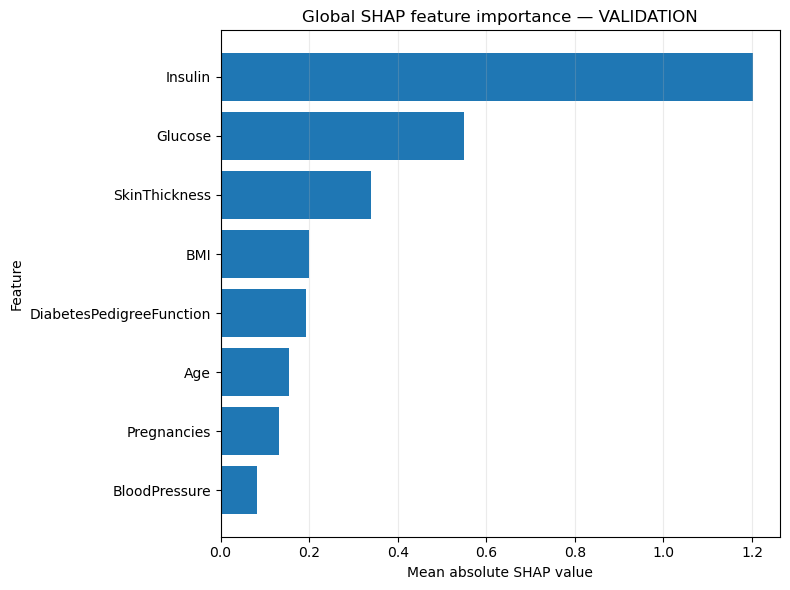

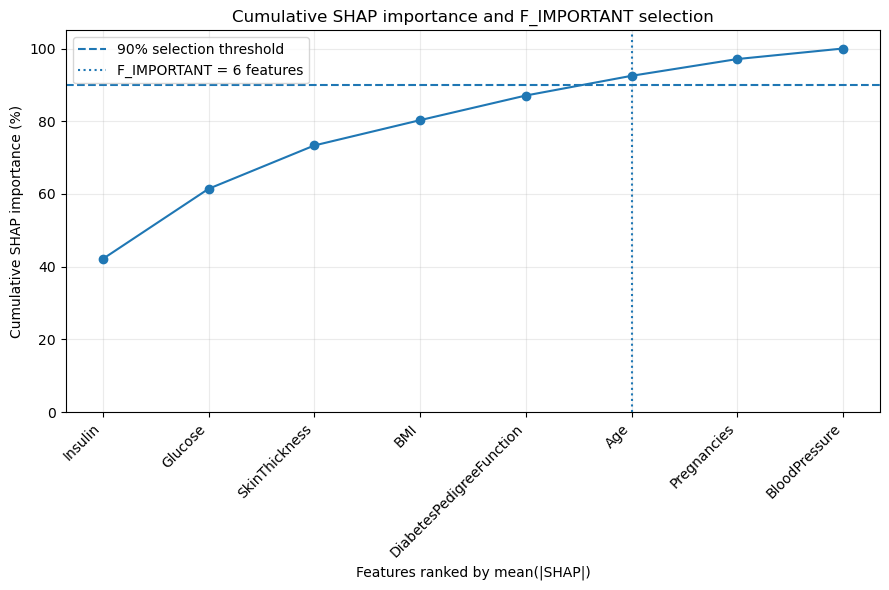

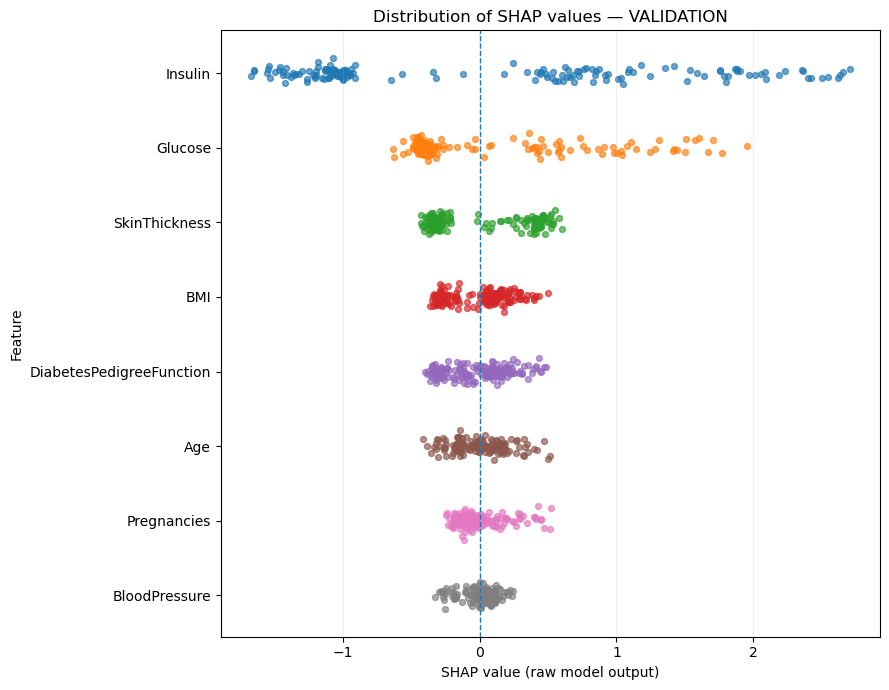


STEP 04 COMPLETED
OK - step04_shap_values_validation.csv
OK - step04_shap_importance.csv
OK - step04_f_important.csv
OK - table_step04_shap_ranking.csv
OK - figure_step04_shap_importance.png
OK - figure_step04_shap_importance.pdf
OK - figure_step04_shap_cumulative.png
OK - figure_step04_shap_cumulative.pdf
OK - figure_step04_shap_beeswarm.png
OK - figure_step04_shap_beeswarm.pdf
OK - step04_xai_ref_metadata.json
OK - step04_documentary_manifest.json

Official F_IMPORTANT:
['Insulin', 'Glucose', 'SkinThickness', 'BMI', 'DiabetesPedigreeFunction', 'Age']

TEST accessed: NO
Dependency analysis: NO
Documentary knowledge used: NO
DQ intervention: NONE


In [7]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4: DIABETES
# STEP 04 - XAI_REF / SHAP ON VALIDATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import hashlib
from datetime import datetime, timezone

from catboost import CatBoostClassifier, Pool


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT / "data" / "reference" / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT / "results" / "01_reference"
    / "step02_split_assignment.csv"
)

MODEL_FILE = (
    ROOT / "models" / "Model_REF" / "Model_REF.cbm"
)

RESULTS_DIR = ROOT / "results" / "03_xai_ref"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

for directory in [
    RESULTS_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. CONFIGURATION
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

SHAP_SELECTION_THRESHOLD = 0.90


# ============================================================
# 3. HASH FUNCTION
# ============================================================

def sha256_file(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha256.update(block)

    return sha256.hexdigest()


# ============================================================
# 4. CHECK REQUIRED FILES
# ============================================================

for file in [
    REF_FILE,
    SPLIT_FILE,
    MODEL_FILE
]:

    if not file.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{file}"
        )


# ============================================================
# 5. LOAD DATA
# ============================================================

df = pd.read_csv(
    REF_FILE
)

split_assignment = pd.read_csv(
    SPLIT_FILE
)

assert len(df) == len(split_assignment)

assert np.array_equal(
    split_assignment["row_id"].to_numpy(),
    np.arange(len(df))
)

print(
    "Dataset_REF loaded:",
    df.shape
)

print(
    "Split assignment loaded:",
    split_assignment.shape
)


# ============================================================
# 6. RECONSTRUCT VALIDATION ONLY
# ============================================================

validation_mask = (
    split_assignment["split"] == "VALIDATION"
)

validation_df = df.loc[
    validation_mask
].copy()

X_validation = validation_df[
    FEATURES
].copy()

y_validation = validation_df[
    TARGET
].copy()


assert len(X_validation) == 154

assert (
    X_validation.isna()
    .sum()
    .sum()
    == 0
)


print(
    "\nVALIDATION:",
    X_validation.shape
)

print(
    "TEST accessed: NO"
)


# ============================================================
# 7. LOAD FROZEN Model_REF
# ============================================================

model = CatBoostClassifier()

model.load_model(
    str(MODEL_FILE)
)


print(
    "\nModel_REF loaded successfully."
)

print(
    "Tree count:",
    model.tree_count_
)


# ============================================================
# 8. HASHES
# ============================================================

dataset_sha256 = sha256_file(
    REF_FILE
)

split_sha256 = sha256_file(
    SPLIT_FILE
)

model_sha256 = sha256_file(
    MODEL_FILE
)


print(
    "\nModel_REF SHA-256:"
)

print(
    model_sha256
)


# ============================================================
# 9. CATBOOST POOL
# ============================================================

validation_pool = Pool(
    data=X_validation,
    label=y_validation,
    feature_names=FEATURES
)


# ============================================================
# 10. CALCULATE TREE SHAP
#
# CatBoost returns:
#
# n rows x (n_features + 1)
#
# Last column = expected/base value
# ============================================================

shap_raw = model.get_feature_importance(
    validation_pool,
    type="ShapValues"
)


expected_shape = (
    len(X_validation),
    len(FEATURES) + 1
)

assert (
    shap_raw.shape
    == expected_shape
)


shap_values = shap_raw[
    :,
    :-1
]

base_values = shap_raw[
    :,
    -1
]


print(
    "\nSHAP matrix shape:",
    shap_values.shape
)


# ============================================================
# 11. SHAP ADDITIVITY CHECK
#
# CatBoost SHAP for binary classification is expressed
# in raw prediction / log-odds space.
#
# raw_prediction should equal:
#
# base_value + sum(SHAP_i)
# ============================================================

raw_predictions = np.asarray(
    model.predict(
        validation_pool,
        prediction_type="RawFormulaVal"
    )
).reshape(-1)


shap_reconstructed = (
    base_values
    +
    shap_values.sum(axis=1)
)


additivity_errors = np.abs(
    raw_predictions
    -
    shap_reconstructed
)


max_additivity_error = float(
    np.max(
        additivity_errors
    )
)

mean_additivity_error = float(
    np.mean(
        additivity_errors
    )
)


ADDITIVITY_TOLERANCE = 1e-6

additivity_pass = bool(
    max_additivity_error
    <= ADDITIVITY_TOLERANCE
)


print(
    "\nSHAP additivity check:"
)

print(
    "Maximum absolute error:",
    max_additivity_error
)

print(
    "Mean absolute error:",
    mean_additivity_error
)

print(
    "Tolerance:",
    ADDITIVITY_TOLERANCE
)

print(
    "Additivity:",
    "PASS"
    if additivity_pass
    else "FAIL"
)


if not additivity_pass:

    raise RuntimeError(
        "SHAP additivity check failed."
    )


# ============================================================
# 12. SAVE SHAP VALUES
# ============================================================

shap_df = pd.DataFrame(
    shap_values,
    columns=[
        f"SHAP_{feature}"
        for feature in FEATURES
    ],
    index=X_validation.index
)

shap_df.insert(
    0,
    "row_id",
    X_validation.index
)

shap_df["base_value"] = (
    base_values
)

shap_df["raw_prediction"] = (
    raw_predictions
)

shap_df[
    "shap_reconstructed_raw_prediction"
] = shap_reconstructed

shap_df[
    "additivity_absolute_error"
] = additivity_errors


SHAP_VALUES_FILE = (
    RESULTS_DIR
    / "step04_shap_values_validation.csv"
)

shap_df.to_csv(
    SHAP_VALUES_FILE,
    index=False
)


# ============================================================
# 13. GLOBAL SHAP IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        shap_values
    ),
    axis=0
)


importance_df = pd.DataFrame({

    "feature":
        FEATURES,

    "mean_abs_shap":
        mean_abs_shap
})


importance_df = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


total_shap = (
    importance_df[
        "mean_abs_shap"
    ].sum()
)


importance_df[
    "relative_importance"
] = (
    importance_df[
        "mean_abs_shap"
    ]
    /
    total_shap
)


importance_df[
    "relative_importance_percent"
] = (
    importance_df[
        "relative_importance"
    ]
    * 100
)


importance_df[
    "cumulative_importance"
] = (
    importance_df[
        "relative_importance"
    ].cumsum()
)


importance_df[
    "cumulative_importance_percent"
] = (
    importance_df[
        "cumulative_importance"
    ]
    * 100
)


importance_df[
    "rank"
] = (
    np.arange(
        1,
        len(importance_df) + 1
    )
)


# ============================================================
# 14. SELECT F_IMPORTANT
#
# Smallest ranked set whose cumulative importance >= 90%
# ============================================================

threshold_positions = np.where(
    importance_df[
        "cumulative_importance"
    ].to_numpy()
    >= SHAP_SELECTION_THRESHOLD
)[0]


if len(threshold_positions) == 0:

    cutoff_index = (
        len(importance_df) - 1
    )

else:

    cutoff_index = int(
        threshold_positions[0]
    )


n_important = (
    cutoff_index + 1
)


importance_df[
    "selected_F_IMPORTANT"
] = False

importance_df.loc[
    :cutoff_index,
    "selected_F_IMPORTANT"
] = True


F_IMPORTANT = (
    importance_df.loc[
        importance_df[
            "selected_F_IMPORTANT"
        ],
        "feature"
    ]
    .tolist()
)


selected_cumulative = float(
    importance_df.loc[
        cutoff_index,
        "cumulative_importance"
    ]
)


print(
    "\n========================================"
)

print(
    "OFFICIAL SHAP RANKING — VALIDATION"
)

print(
    "========================================"
)

print(
    importance_df[
        [
            "rank",
            "feature",
            "mean_abs_shap",
            "relative_importance_percent",
            "cumulative_importance_percent",
            "selected_F_IMPORTANT"
        ]
    ].to_string(
        index=False
    )
)


print(
    "\nF_IMPORTANT:"
)

print(
    F_IMPORTANT
)

print(
    "\nNumber of important features:",
    n_important
)

print(
    "Selected cumulative importance:",
    f"{selected_cumulative * 100:.6f}%"
)


# ============================================================
# 15. SAVE IMPORTANCE
# ============================================================

IMPORTANCE_FILE = (
    RESULTS_DIR
    / "step04_shap_importance.csv"
)

importance_df.to_csv(
    IMPORTANCE_FILE,
    index=False
)


# ============================================================
# 16. SAVE F_IMPORTANT
# ============================================================

f_important_df = (
    importance_df.loc[
        importance_df[
            "selected_F_IMPORTANT"
        ],
        [
            "rank",
            "feature",
            "mean_abs_shap",
            "relative_importance_percent",
            "cumulative_importance_percent"
        ]
    ]
    .copy()
)


F_IMPORTANT_FILE = (
    RESULTS_DIR
    / "step04_f_important.csv"
)

f_important_df.to_csv(
    F_IMPORTANT_FILE,
    index=False
)


# ============================================================
# 17. PUBLICATION TABLE
# ============================================================

publication_table = (
    importance_df[
        [
            "rank",
            "feature",
            "mean_abs_shap",
            "relative_importance_percent",
            "cumulative_importance_percent",
            "selected_F_IMPORTANT"
        ]
    ]
    .copy()
)


publication_table.columns = [

    "Rank",

    "Feature",

    "MeanAbsSHAP",

    "RelativeImportancePercent",

    "CumulativeImportancePercent",

    "Selected_F_IMPORTANT"
]


PUBLICATION_TABLE_FILE = (
    TABLES_DIR
    / "table_step04_shap_ranking.csv"
)


publication_table.to_csv(
    PUBLICATION_TABLE_FILE,
    index=False
)


# ============================================================
# 18. FIGURE 1
# GLOBAL MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

plot_importance = (
    importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=True
    )
)


fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.barh(
    plot_importance[
        "feature"
    ],
    plot_importance[
        "mean_abs_shap"
    ]
)


ax.set_xlabel(
    "Mean absolute SHAP value"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Global SHAP feature importance — VALIDATION"
)


ax.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_importance.png",
    dpi=300,
    bbox_inches="tight"
)


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_importance.pdf",
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# ============================================================
# 19. FIGURE 2
# CUMULATIVE SHAP IMPORTANCE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)


x_positions = np.arange(
    1,
    len(importance_df) + 1
)


ax.plot(
    x_positions,
    importance_df[
        "cumulative_importance_percent"
    ],
    marker="o"
)


ax.axhline(
    y=90,
    linestyle="--",
    label="90% selection threshold"
)


ax.axvline(
    x=n_important,
    linestyle=":",
    label=f"F_IMPORTANT = {n_important} features"
)


ax.set_xticks(
    x_positions
)


ax.set_xticklabels(
    importance_df[
        "feature"
    ],
    rotation=45,
    ha="right"
)


ax.set_xlabel(
    "Features ranked by mean(|SHAP|)"
)

ax.set_ylabel(
    "Cumulative SHAP importance (%)"
)


ax.set_ylim(
    0,
    105
)


ax.set_title(
    "Cumulative SHAP importance and F_IMPORTANT selection"
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_cumulative.png",
    dpi=300,
    bbox_inches="tight"
)


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_cumulative.pdf",
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# ============================================================
# 20. FIGURE 3
# SHAP DISTRIBUTION / BEESWARM-LIKE PLOT
#
# Implemented directly from exact CatBoost SHAP values.
# No approximation of feature importance.
# ============================================================

ranking = (
    importance_df[
        "feature"
    ].tolist()
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


rng = np.random.default_rng(
    42
)


for position, feature in enumerate(
    ranking
):

    feature_index = (
        FEATURES.index(
            feature
        )
    )

    feature_shap = (
        shap_values[
            :,
            feature_index
        ]
    )

    jitter = rng.normal(
        loc=0,
        scale=0.07,
        size=len(feature_shap)
    )

    y_position = (
        len(ranking)
        - 1
        - position
    )

    ax.scatter(
        feature_shap,
        y_position + jitter,
        s=18,
        alpha=0.65
    )


ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)


ax.set_yticks(
    np.arange(
        len(ranking)
    )
)


ax.set_yticklabels(
    ranking[::-1]
)


ax.set_xlabel(
    "SHAP value (raw model output)"
)


ax.set_ylabel(
    "Feature"
)


ax.set_title(
    "Distribution of SHAP values — VALIDATION"
)


ax.grid(
    axis="x",
    alpha=0.20
)


plt.tight_layout()


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)


fig.savefig(
    FIGURES_DIR
    / "figure_step04_shap_beeswarm.pdf",
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# ============================================================
# 21. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_04_XAI_REF",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "xai_method":
        "CatBoost TreeSHAP",

    "xai_dataset":
        "VALIDATION",

    "validation_n":
        int(
            len(X_validation)
        ),

    "test_accessed":
        False,

    "dataset_ref_sha256":
        dataset_sha256,

    "split_assignment_sha256":
        split_sha256,

    "model_ref_sha256":
        model_sha256,

    "features_evaluated":
        FEATURES,

    "n_features":
        len(FEATURES),

    "shap_output_space":
        "RawFormulaVal / log-odds",

    "shap_selection_metric":
        "mean absolute SHAP",

    "selection_rule":
        (
            "Smallest ranked feature set "
            "reaching at least 90% cumulative "
            "mean absolute SHAP importance."
        ),

    "selection_threshold":
        SHAP_SELECTION_THRESHOLD,

    "n_important_features":
        n_important,

    "F_IMPORTANT":
        F_IMPORTANT,

    "selected_cumulative_importance":
        selected_cumulative,

    "additivity_tolerance":
        ADDITIVITY_TOLERANCE,

    "max_additivity_error":
        max_additivity_error,

    "mean_additivity_error":
        mean_additivity_error,

    "additivity_pass":
        additivity_pass,

    "missing_values_injected":
        False,

    "missing_values_imputed":
        False,

    "dq_intervention_applied":
        False,

    "dependency_analysis_performed":
        False,

    "documentary_knowledge_used":
        False
}


METADATA_FILE = (
    RESULTS_DIR
    / "step04_xai_ref_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 22. DOCUMENTARY MANIFEST
# ============================================================

manifest = {

    "step":
        "STEP_04_XAI_REF",

    "raw_results": [

        "step04_shap_values_validation.csv",

        "step04_shap_importance.csv",

        "step04_f_important.csv"
    ],

    "tables": [

        "tables/table_step04_shap_ranking.csv"
    ],

    "figures": [

        {
            "name":
                "figure_step04_shap_importance",

            "formats": [
                "PNG_300_DPI",
                "PDF_VECTOR"
            ]
        },

        {
            "name":
                "figure_step04_shap_cumulative",

            "formats": [
                "PNG_300_DPI",
                "PDF_VECTOR"
            ]
        },

        {
            "name":
                "figure_step04_shap_beeswarm",

            "formats": [
                "PNG_300_DPI",
                "PDF_VECTOR"
            ]
        }
    ],

    "test_used":
        False,

    "dependency_analysis":
        False,

    "dq_intervention":
        False
}


MANIFEST_FILE = (
    RESULTS_DIR
    / "step04_documentary_manifest.json"
)


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 23. FINAL VERIFICATION
# ============================================================

expected_files = [

    SHAP_VALUES_FILE,

    IMPORTANCE_FILE,

    F_IMPORTANT_FILE,

    PUBLICATION_TABLE_FILE,

    FIGURES_DIR
    / "figure_step04_shap_importance.png",

    FIGURES_DIR
    / "figure_step04_shap_importance.pdf",

    FIGURES_DIR
    / "figure_step04_shap_cumulative.png",

    FIGURES_DIR
    / "figure_step04_shap_cumulative.pdf",

    FIGURES_DIR
    / "figure_step04_shap_beeswarm.png",

    FIGURES_DIR
    / "figure_step04_shap_beeswarm.pdf",

    METADATA_FILE,

    MANIFEST_FILE
]


print(
    "\n========================================"
)

print(
    "STEP 04 COMPLETED"
)

print(
    "========================================"
)


for file in expected_files:

    status = (
        "OK"
        if file.exists()
        else "MISSING"
    )

    print(
        status,
        "-",
        file.name
    )


print(
    "\nOfficial F_IMPORTANT:"
)

print(
    F_IMPORTANT
)


print(
    "\nTEST accessed: NO"
)

print(
    "Dependency analysis: NO"
)

print(
    "Documentary knowledge used: NO"
)

print(
    "DQ intervention: NONE"
)

In [8]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# STEP 05 — DOCUMENTARY CORPUS PREPARATION
# ============================================================
#
# OBJECTIVE
# ---------
# Prepare the official documentary corpus for subsequent
# exhaustive semantic analysis by LLM-A.
#
# IMPORTANT
# ---------
# This step performs NO:
# - semantic search
# - keyword filtering
# - TF-IDF
# - BM25
# - embedding similarity
# - feature filtering
# - missing-value search
# - outlier search
# - action extraction
#
# It only prepares traceable 2-page documentary chunks.
# ============================================================

from pathlib import Path
import fitz
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

DOCUMENTS_ROOT = PROJECT_ROOT / "knowledge" / "documents"

PREPARED_ROOT = PROJECT_ROOT / "knowledge" / "prepared_documents"

TEXT_ROOT = PREPARED_ROOT / "chunks_text"
IMAGE_ROOT = PREPARED_ROOT / "page_images"
MANIFEST_ROOT = PREPARED_ROOT / "manifests"

RESULT_ROOT = PROJECT_ROOT / "results" / "04_document_preparation"

for folder in [
    PREPARED_ROOT,
    TEXT_ROOT,
    IMAGE_ROOT,
    MANIFEST_ROOT,
    RESULT_ROOT
]:
    folder.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. PARAMETERS
# ============================================================

CHUNK_SIZE_PAGES = 2

# 150 dpi is sufficient for subsequent multimodal LLM reading
IMAGE_DPI = 150

SUPPORTED_EXTENSIONS = {".pdf"}


# ============================================================
# 3. UTILITY FUNCTIONS
# ============================================================

def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)

    return h.hexdigest()


def safe_name(name):
    """
    Produce filesystem-safe identifier while keeping
    documentary traceability.
    """
    return "".join(
        c if c.isalnum() or c in "-_" else "_"
        for c in name
    ).strip("_")


# ============================================================
# 4. DISCOVER PDF DOCUMENTS
# ============================================================

pdf_files = sorted(
    [
        p for p in DOCUMENTS_ROOT.rglob("*")
        if p.is_file()
        and p.suffix.lower() in SUPPORTED_EXTENSIONS
    ]
)

if not pdf_files:
    raise FileNotFoundError(
        f"No PDF document found under:\n{DOCUMENTS_ROOT}"
    )

print("=" * 80)
print("STEP 05 — DOCUMENTARY CORPUS PREPARATION")
print("=" * 80)

print(f"\nDocuments found: {len(pdf_files)}")

for p in pdf_files:
    print(" -", p.relative_to(PROJECT_ROOT))


# ============================================================
# 5. OUTPUT STRUCTURES
# ============================================================

document_records = []
chunk_records = []


# ============================================================
# 6. PROCESS EACH DOCUMENT
# ============================================================

for doc_index, pdf_path in enumerate(pdf_files, start=1):

    document_id = f"DOC_{doc_index:03d}"

    document_name = pdf_path.name
    document_stem = safe_name(pdf_path.stem)

    print("\n" + "-" * 80)
    print(document_id, document_name)

    pdf = fitz.open(pdf_path)

    n_pages = len(pdf)

    document_hash = sha256_file(pdf_path)

    # --------------------------------------------------------
    # Document-specific directories
    # --------------------------------------------------------

    doc_text_dir = TEXT_ROOT / document_id
    doc_image_dir = IMAGE_ROOT / document_id

    doc_text_dir.mkdir(parents=True, exist_ok=True)
    doc_image_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # Document manifest
    # --------------------------------------------------------

    document_records.append({
        "document_id": document_id,
        "document_name": document_name,
        "relative_path": str(pdf_path.relative_to(PROJECT_ROOT)),
        "n_pages": n_pages,
        "sha256": document_hash
    })

    # --------------------------------------------------------
    # 2-page chunks
    # --------------------------------------------------------

    chunk_number = 0

    for start_idx in range(0, n_pages, CHUNK_SIZE_PAGES):

        chunk_number += 1

        end_idx = min(
            start_idx + CHUNK_SIZE_PAGES,
            n_pages
        )

        # Human-readable PDF page numbers
        start_page = start_idx + 1
        end_page = end_idx

        chunk_id = (
            f"{document_id}_"
            f"CHUNK_{chunk_number:04d}"
        )

        # ----------------------------------------------------
        # Extract text
        # ----------------------------------------------------

        text_parts = []

        image_paths = []

        for page_idx in range(start_idx, end_idx):

            page = pdf[page_idx]

            physical_page_number = page_idx + 1

            # Explicit page separator
            text_parts.append(
                f"\n\n"
                f"===== PDF PAGE "
                f"{physical_page_number} =====\n\n"
            )

            page_text = page.get_text("text")

            text_parts.append(page_text)

            # ------------------------------------------------
            # Render full PDF page
            # ------------------------------------------------

            pix = page.get_pixmap(dpi=IMAGE_DPI)

            image_filename = (
                f"{document_id}_"
                f"PAGE_{physical_page_number:04d}.png"
            )

            image_path = doc_image_dir / image_filename

            pix.save(str(image_path))

            image_paths.append(
                str(image_path.relative_to(PROJECT_ROOT))
            )

        full_text = "".join(text_parts)

        # ----------------------------------------------------
        # Save text chunk
        # ----------------------------------------------------

        text_filename = f"{chunk_id}.txt"

        text_path = doc_text_dir / text_filename

        text_path.write_text(
            full_text,
            encoding="utf-8"
        )

        # ----------------------------------------------------
        # Chunk hash
        # ----------------------------------------------------

        chunk_text_hash = hashlib.sha256(
            full_text.encode("utf-8")
        ).hexdigest()

        # ----------------------------------------------------
        # Chunk metadata
        # ----------------------------------------------------

        chunk_records.append({

            "chunk_id": chunk_id,

            "document_id": document_id,

            "document_name": document_name,

            "pdf_start_page": start_page,

            "pdf_end_page": end_page,

            "n_pages": end_page - start_page + 1,

            "text_path": str(
                text_path.relative_to(PROJECT_ROOT)
            ),

            "page_image_paths": json.dumps(
                image_paths,
                ensure_ascii=False
            ),

            "text_characters": len(full_text),

            "text_sha256": chunk_text_hash
        })

    pdf.close()

    print(
        f"Pages: {n_pages} | "
        f"Chunks: {chunk_number}"
    )


# ============================================================
# 7. CREATE MANIFESTS
# ============================================================

document_manifest = pd.DataFrame(document_records)

chunk_manifest = pd.DataFrame(chunk_records)


document_manifest_path = (
    RESULT_ROOT /
    "step05_document_manifest.csv"
)

chunk_manifest_path = (
    RESULT_ROOT /
    "step05_chunk_manifest.csv"
)


document_manifest.to_csv(
    document_manifest_path,
    index=False,
    encoding="utf-8-sig"
)

chunk_manifest.to_csv(
    chunk_manifest_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. STEP METADATA
# ============================================================

metadata = {

    "step": "STEP_05",

    "step_name":
        "Documentary corpus preparation",

    "timestamp_utc":
        datetime.now(timezone.utc).isoformat(),

    "project":
        "DEMARCHE_ENCAD3_CASE4_DIABETES",

    "input_root":
        str(DOCUMENTS_ROOT),

    "n_documents":
        len(document_manifest),

    "n_chunks":
        len(chunk_manifest),

    "chunk_size_pages":
        CHUNK_SIZE_PAGES,

    "page_image_dpi":
        IMAGE_DPI,

    "chunk_strategy":
        "non_overlapping_consecutive_physical_pdf_pages",

    "text_extraction":
        "PyMuPDF get_text('text')",

    "page_rendering":
        "PyMuPDF full-page rendering",

    "semantic_filtering_applied":
        False,

    "keyword_filtering_applied":
        False,

    "tfidf_applied":
        False,

    "bm25_applied":
        False,

    "embedding_similarity_applied":
        False,

    "feature_filtering_applied":
        False,

    "dq_problem_filtering_applied":
        False,

    "llm_analysis_applied":
        False,

    "dq_action_extracted":
        False,

    "test_dataset_accessed":
        False
}


metadata_path = (
    RESULT_ROOT /
    "step05_preparation_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 9. DOCUMENTARY MANIFEST
# ============================================================

documentary_manifest = {

    "step": "STEP_05",

    "purpose":
        "Prepare documentary evidence without "
        "semantic preselection.",

    "documents": document_records,

    "important_note":
        "No prior knowledge concerning Age, "
        "missing-value actions, outlier actions, "
        "or any expected documentary rule "
        "was used during corpus preparation."
}


documentary_manifest_path = (
    RESULT_ROOT /
    "step05_documentary_manifest.json"
)

with open(
    documentary_manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        documentary_manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 10. VALIDATION CHECKS
# ============================================================

expected_chunks = sum(
    (int(n) + CHUNK_SIZE_PAGES - 1)
    // CHUNK_SIZE_PAGES
    for n in document_manifest["n_pages"]
)

assert len(chunk_manifest) == expected_chunks


# Check all text files
for relative_path in chunk_manifest["text_path"]:

    p = PROJECT_ROOT / relative_path

    assert p.exists(), (
        f"Missing text chunk: {p}"
    )


# Check all images
for image_list_json in chunk_manifest["page_image_paths"]:

    image_list = json.loads(image_list_json)

    for relative_path in image_list:

        p = PROJECT_ROOT / relative_path

        assert p.exists(), (
            f"Missing page image: {p}"
        )


print("\n" + "=" * 80)
print("STEP 05 COMPLETED")
print("=" * 80)

print(
    f"Documents : {len(document_manifest)}"
)

print(
    f"Chunks    : {len(chunk_manifest)}"
)

print(
    f"Expected  : {expected_chunks}"
)

print("\nDocument manifest:")
print(document_manifest_path)

print("\nChunk manifest:")
print(chunk_manifest_path)

print("\nMetadata:")
print(metadata_path)

print("\nDocumentary manifest:")
print(documentary_manifest_path)

print("\nVALIDATION: PASS")
print("No semantic filtering was performed.")
print("No LLM analysis was performed.")
print("TEST dataset was NOT accessed.")

STEP 05 — DOCUMENTARY CORPUS PREPARATION

Documents found: 8
 - knowledge\documents\official_clinical\Cardiovascular Disease.pdf
 - knowledge\documents\official_clinical\guidance-on-global-monitoring-for-diabetes.pdf
 - knowledge\documents\official_clinical\steps-manual.pdf
 - knowledge\documents\official_clinical\Validation of Multi-State EHR-Based Network for Disease Surveillance (MENDS).pdf
 - knowledge\documents\official_clinical\WHO TECHNICAL blood.pdf
 - knowledge\documents\official_clinical\WHO-NMH-NVI-18.2-eng.pdf
 - knowledge\documents\official_clinical\WHO-NMH-NVI-19.8-eng.pdf
 - knowledge\documents\official_clinical\WHO-UCN-NCD-20.1-eng.pdf

--------------------------------------------------------------------------------
DOC_001 Cardiovascular Disease.pdf
Pages: 30 | Chunks: 15

--------------------------------------------------------------------------------
DOC_002 guidance-on-global-monitoring-for-diabetes.pdf
Pages: 94 | Chunks: 47

---------------------------------------

In [9]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# STEP 06A — PREPARATION OF LLM-A DOCUMENTARY INPUTS
# ============================================================
#
# PURPOSE
# -------
# Build the complete, frozen and traceable input corpus
# that will be submitted to LLM-A during STEP 06B.
#
# IMPORTANT
# ---------
# NO LLM call is performed here.
# NO semantic filtering is performed.
# ALL STEP-05 chunks are retained.
#
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP05_ROOT = (
    PROJECT_ROOT /
    "results" /
    "04_document_preparation"
)

PREPARED_ROOT = (
    PROJECT_ROOT /
    "knowledge" /
    "prepared_documents"
)

STEP06A_ROOT = (
    PROJECT_ROOT /
    "results" /
    "05_llma_preparation"
)

STEP06A_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FILES
# ============================================================

CHUNK_MANIFEST_PATH = (
    STEP05_ROOT /
    "step05_chunk_manifest.csv"
)

DOCUMENT_MANIFEST_PATH = (
    STEP05_ROOT /
    "step05_document_manifest.csv"
)

STEP05_METADATA_PATH = (
    STEP05_ROOT /
    "step05_preparation_metadata.json"
)


for required_file in [
    CHUNK_MANIFEST_PATH,
    DOCUMENT_MANIFEST_PATH,
    STEP05_METADATA_PATH
]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required STEP 05 artifact missing:\n"
            f"{required_file}"
        )


# ============================================================
# 3. LOAD STEP 05
# ============================================================

chunk_manifest = pd.read_csv(
    CHUNK_MANIFEST_PATH
)

document_manifest = pd.read_csv(
    DOCUMENT_MANIFEST_PATH
)

with open(
    STEP05_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:
    step05_metadata = json.load(f)


# ============================================================
# 4. VALIDATE STEP 05
# ============================================================

if len(chunk_manifest) != 395:
    raise ValueError(
        f"Expected 395 chunks from STEP 05, "
        f"found {len(chunk_manifest)}."
    )

if len(document_manifest) != 8:
    raise ValueError(
        f"Expected 8 documents, "
        f"found {len(document_manifest)}."
    )

if step05_metadata.get(
    "semantic_filtering_applied"
) is not False:
    raise ValueError(
        "STEP 05 semantic filtering state invalid."
    )

if step05_metadata.get(
    "llm_analysis_applied"
) is not False:
    raise ValueError(
        "STEP 05 already contains LLM analysis."
    )


# ============================================================
# 5. FROZEN XAI FEATURE SET
# ============================================================

F_IMPORTANT = [
    "Insulin",
    "Glucose",
    "SkinThickness",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]


# ============================================================
# 6. FROZEN DQ PROBLEM SET
# ============================================================

DQ_PROBLEMS = [
    "MISSING_VALUE",
    "POTENTIAL_OUTLIER"
]


# ============================================================
# 7. PROMPT VERSION
# ============================================================

PROMPT_VERSION = "LLMA_DOC_V1"

PROMPT_TEXT = r"""
DEMARCHE_ENCAD3 — DOCUMENTARY KNOWLEDGE EXTRACTION
ROLE: LLM-A
PROMPT VERSION: LLMA_DOC_V1

You are LLM-A in the documentary knowledge extraction stage
of DEMARCHE_ENCAD3.

The following predictive features were independently selected
by the reference XAI analysis:

- Insulin
- Glucose
- SkinThickness
- BMI
- DiabetesPedigreeFunction
- Age

TASK

Analyze the supplied documentary chunk exhaustively using:
1. its extracted text;
2. the original rendered page image(s).

For each feature listed above, determine whether the chunk
contains explicit or sufficiently direct documentary knowledge
concerning:

A. MISSING_VALUE
B. POTENTIAL_OUTLIER

POTENTIAL_OUTLIER includes documentary knowledge concerning
implausible, invalid, impossible, erroneous, questionable,
out-of-range or extreme observations only when the document
itself supports such an interpretation.

For relevant knowledge, distinguish:

1. DETECTION
   A criterion that identifies or detects a potential
   data-quality problem.

2. QUALIFICATION
   Knowledge that helps determine whether an observation
   should be regarded as erroneous, invalid, questionable,
   acceptable, etc.

3. ACTION
   An explicitly documented response to the problem.

Possible actions may include, but are not limited to:
RECOVER, CORRECT, IMPUTE, KEEP, FLAG, EXCLUDE, DOWNWEIGHT,
ROBUST_METHOD, REVIEW, ABSTAIN or another action explicitly
supported by the document.

EPISTEMIC RULES

- Missing does not automatically mean erroneous.
- An outlier does not automatically mean erroneous.
- Extreme does not automatically mean invalid.
- A clinical threshold is not automatically a data-quality
  validity threshold.
- A diagnostic threshold is not automatically an outlier rule.
- Do not invent a correction.
- Do not invent an action.
- Do not convert descriptive or clinical information into a
  data-quality rule unless the document supports that use.
- Do not assume that an action documented in one context is
  transferable to another context.
- Preserve all conditions, exceptions and limitations.
- DETECTION, QUALIFICATION and ACTION are distinct.
- The document is the knowledge source.
- You are an extraction and structuring mechanism, not the
  knowledge source.
- Use the page images when tables, figures, layout or content
  are not completely represented by extracted text.

RELEVANCE

A knowledge item is relevant only if a reasonable documentary
link exists between the chunk and at least one selected feature
AND one of the two DQ problems.

Do not force a feature association.

If a document uses a concept that clearly corresponds to a
selected feature under different terminology, record both the
dataset feature and the documentary term.

EVIDENCE

For every retained knowledge item:
- preserve a minimal supporting passage;
- identify the physical PDF page;
- identify whether evidence came from TEXT, TABLE, IMAGE,
  or MULTIMODAL content;
- preserve the documentary context;
- do not paraphrase the evidence field.

NO RELEVANT KNOWLEDGE

If the chunk contains no relevant knowledge for any selected
feature and either DQ problem, return:

status = NO_RELEVANT_KNOWLEDGE

Do not manufacture a positive result.

OUTPUT

Return only an object conforming to the supplied JSON schema.
""".strip()


# ============================================================
# 8. OUTPUT JSON SCHEMA
# ============================================================

OUTPUT_SCHEMA = {

    "type": "object",

    "required": [
        "chunk_id",
        "status",
        "knowledge_items"
    ],

    "properties": {

        "chunk_id": {
            "type": "string"
        },

        "status": {
            "type": "string",
            "enum": [
                "RELEVANT_KNOWLEDGE",
                "NO_RELEVANT_KNOWLEDGE"
            ]
        },

        "knowledge_items": {

            "type": "array",

            "items": {

                "type": "object",

                "required": [
                    "feature",
                    "documentary_term",
                    "dq_problem",
                    "rule_role",
                    "evidence",
                    "evidence_page",
                    "evidence_type",
                    "condition",
                    "action",
                    "action_conditions",
                    "context",
                    "limitations",
                    "llma_confidence"
                ],

                "properties": {

                    "feature": {
                        "type": "string",
                        "enum": F_IMPORTANT
                    },

                    "documentary_term": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "dq_problem": {
                        "type": "string",
                        "enum": DQ_PROBLEMS
                    },

                    "rule_role": {
                        "type": "string",
                        "enum": [
                            "DETECTION",
                            "QUALIFICATION",
                            "ACTION"
                        ]
                    },

                    "evidence": {
                        "type": "string"
                    },

                    "evidence_page": {
                        "type": "integer"
                    },

                    "evidence_type": {
                        "type": "string",
                        "enum": [
                            "TEXT",
                            "TABLE",
                            "IMAGE",
                            "MULTIMODAL"
                        ]
                    },

                    "condition": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "action": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "action_conditions": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "context": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "limitations": {
                        "type": [
                            "string",
                            "null"
                        ]
                    },

                    "llma_confidence": {
                        "type": "string",
                        "enum": [
                            "HIGH",
                            "MEDIUM",
                            "LOW"
                        ]
                    }
                },

                "additionalProperties": False
            }
        }
    },

    "additionalProperties": False
}


# ============================================================
# 9. SAVE FROZEN PROMPT
# ============================================================

PROMPT_PATH = (
    STEP06A_ROOT /
    "step06a_prompt_llma_v1.txt"
)

PROMPT_PATH.write_text(
    PROMPT_TEXT,
    encoding="utf-8"
)


# ============================================================
# 10. SAVE OUTPUT SCHEMA
# ============================================================

SCHEMA_PATH = (
    STEP06A_ROOT /
    "step06a_output_schema.json"
)

with open(
    SCHEMA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        OUTPUT_SCHEMA,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 11. HASH FROZEN PROMPT + SCHEMA
# ============================================================

PROMPT_SHA256 = hashlib.sha256(
    PROMPT_TEXT.encode("utf-8")
).hexdigest()

SCHEMA_CANONICAL = json.dumps(
    OUTPUT_SCHEMA,
    sort_keys=True,
    ensure_ascii=False
)

SCHEMA_SHA256 = hashlib.sha256(
    SCHEMA_CANONICAL.encode("utf-8")
).hexdigest()


# ============================================================
# 12. BUILD COMPLETE LLM-A INPUT
# ============================================================

jsonl_records = []
manifest_records = []


for _, row in chunk_manifest.iterrows():

    chunk_id = str(row["chunk_id"])

    document_id = str(row["document_id"])

    document_name = str(row["document_name"])

    start_page = int(
        row["pdf_start_page"]
    )

    end_page = int(
        row["pdf_end_page"]
    )

    # --------------------------------------------------------
    # Text
    # --------------------------------------------------------

    text_relative_path = Path(
        str(row["text_path"])
    )

    text_absolute_path = (
        PROJECT_ROOT /
        text_relative_path
    )

    if not text_absolute_path.exists():
        raise FileNotFoundError(
            f"Missing chunk text:\n"
            f"{text_absolute_path}"
        )

    chunk_text = text_absolute_path.read_text(
        encoding="utf-8"
    )

    # --------------------------------------------------------
    # Images
    # --------------------------------------------------------

    image_relative_paths = json.loads(
        row["page_image_paths"]
    )

    image_absolute_paths = []

    for relative_image in image_relative_paths:

        absolute_image = (
            PROJECT_ROOT /
            Path(relative_image)
        )

        if not absolute_image.exists():
            raise FileNotFoundError(
                f"Missing page image:\n"
                f"{absolute_image}"
            )

        image_absolute_paths.append(
            str(absolute_image)
        )

    # --------------------------------------------------------
    # Input object
    # --------------------------------------------------------

    input_object = {

        "chunk_id": chunk_id,

        "document": {
            "document_id": document_id,
            "document_name": document_name,
            "pdf_start_page": start_page,
            "pdf_end_page": end_page
        },

        "analysis_scope": {

            "features": F_IMPORTANT,

            "dq_problems": DQ_PROBLEMS
        },

        "prompt": {

            "version": PROMPT_VERSION,

            "sha256": PROMPT_SHA256
        },

        "output_schema": {

            "sha256": SCHEMA_SHA256
        },

        "content": {

            "text": chunk_text,

            "page_images": (
                image_absolute_paths
            )
        }
    }

    jsonl_records.append(
        input_object
    )

    # --------------------------------------------------------
    # Audit manifest
    # --------------------------------------------------------

    manifest_records.append({

        "chunk_id": chunk_id,

        "document_id": document_id,

        "document_name": document_name,

        "pdf_start_page": start_page,

        "pdf_end_page": end_page,

        "text_path": str(
            text_relative_path
        ),

        "n_page_images":
            len(image_absolute_paths),

        "prompt_version":
            PROMPT_VERSION,

        "prompt_sha256":
            PROMPT_SHA256,

        "schema_sha256":
            SCHEMA_SHA256,

        "llma_analysis_performed":
            False
    })


# ============================================================
# 13. WRITE JSONL
# ============================================================

JSONL_PATH = (
    STEP06A_ROOT /
    "step06a_llma_input.jsonl"
)

with open(
    JSONL_PATH,
    "w",
    encoding="utf-8"
) as f:

    for record in jsonl_records:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
        )

        f.write("\n")


# ============================================================
# 14. WRITE INPUT MANIFEST
# ============================================================

input_manifest = pd.DataFrame(
    manifest_records
)

MANIFEST_PATH = (
    STEP06A_ROOT /
    "step06a_llma_input_manifest.csv"
)

input_manifest.to_csv(
    MANIFEST_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. PREPARATION METADATA
# ============================================================

metadata = {

    "step":
        "STEP_06A",

    "step_name":
        "LLM-A input preparation",

    "timestamp_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "project":
        "DEMARCHE_ENCAD3_CASE4_DIABETES",

    "llm_role":
        "LLM-A",

    "llm_analysis_performed":
        False,

    "n_documents":
        len(document_manifest),

    "n_chunks":
        len(jsonl_records),

    "features":
        F_IMPORTANT,

    "dq_problems":
        DQ_PROBLEMS,

    "prompt_version":
        PROMPT_VERSION,

    "prompt_sha256":
        PROMPT_SHA256,

    "output_schema_sha256":
        SCHEMA_SHA256,

    "semantic_prefiltering":
        False,

    "keyword_prefiltering":
        False,

    "tfidf_prefiltering":
        False,

    "bm25_prefiltering":
        False,

    "embedding_prefiltering":
        False,

    "top_k_selection":
        False,

    "known_action_injected":
        False,

    "known_age_rule_injected":
        False,

    "test_dataset_accessed":
        False
}


METADATA_PATH = (
    STEP06A_ROOT /
    "step06a_preparation_metadata.json"
)

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 16. DOCUMENTARY TRACE MANIFEST
# ============================================================

documentary_manifest = {

    "step":
        "STEP_06A",

    "source_step":
        "STEP_05",

    "input_chunk_count":
        len(chunk_manifest),

    "output_llma_input_count":
        len(jsonl_records),

    "all_chunks_retained":
        len(chunk_manifest)
        == len(jsonl_records),

    "feature_source":
        "STEP_04_SHAP_REF",

    "features":
        F_IMPORTANT,

    "knowledge_source":
        "Original documentary corpus",

    "llm_is_knowledge_source":
        False,

    "prior_discovered_rules_provided_to_llma":
        False,

    "notes":
        (
            "STEP 06A performs preparation only. "
            "No documentary knowledge extraction "
            "has yet been performed."
        )
}


DOCUMENTARY_MANIFEST_PATH = (
    STEP06A_ROOT /
    "step06a_documentary_manifest.json"
)

with open(
    DOCUMENTARY_MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        documentary_manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 17. FINAL INTEGRITY CHECKS
# ============================================================

assert len(jsonl_records) == 395

assert len(input_manifest) == 395

assert input_manifest[
    "chunk_id"
].is_unique

assert (
    input_manifest[
        "llma_analysis_performed"
    ] == False
).all()

assert set(
    input_manifest["prompt_sha256"]
) == {PROMPT_SHA256}

assert set(
    input_manifest["schema_sha256"]
) == {SCHEMA_SHA256}


# Count JSONL physical lines
with open(
    JSONL_PATH,
    "r",
    encoding="utf-8"
) as f:

    jsonl_line_count = sum(
        1 for _ in f
    )

assert jsonl_line_count == 395


# ============================================================
# 18. SUMMARY
# ============================================================

print("=" * 80)

print(
    "STEP 06A — "
    "LLM-A INPUT PREPARATION"
)

print("=" * 80)

print(
    f"Documents       : "
    f"{len(document_manifest)}"
)

print(
    f"Input chunks    : "
    f"{len(chunk_manifest)}"
)

print(
    f"LLM-A inputs    : "
    f"{len(jsonl_records)}"
)

print(
    f"JSONL lines     : "
    f"{jsonl_line_count}"
)

print(
    f"Features        : "
    f"{len(F_IMPORTANT)}"
)

print(
    f"DQ problems     : "
    f"{len(DQ_PROBLEMS)}"
)

print(
    f"Prompt version  : "
    f"{PROMPT_VERSION}"
)

print(
    f"Prompt SHA256   : "
    f"{PROMPT_SHA256}"
)

print(
    f"Schema SHA256   : "
    f"{SCHEMA_SHA256}"
)

print("\nOutputs:")

print(JSONL_PATH)
print(MANIFEST_PATH)
print(PROMPT_PATH)
print(SCHEMA_PATH)
print(METADATA_PATH)
print(DOCUMENTARY_MANIFEST_PATH)

print("\nVALIDATION: PASS")

print(
    "All STEP-05 chunks were retained."
)

print(
    "No semantic prefiltering was performed."
)

print(
    "No prior Age rule was injected."
)

print(
    "No LLM analysis was performed."
)

print(
    "TEST dataset was NOT accessed."
)

STEP 06A — LLM-A INPUT PREPARATION
Documents       : 8
Input chunks    : 395
LLM-A inputs    : 395
JSONL lines     : 395
Features        : 6
DQ problems     : 2
Prompt version  : LLMA_DOC_V1
Prompt SHA256   : d17b7884cd914734d9402fedaec22317f0163b25fd33b251bdd7826a61db31d0
Schema SHA256   : 590cdcf33725d4184c591cad64c1473432a334c8622ca092f8b9cfc8e279f6d4

Outputs:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\05_llma_preparation\step06a_llma_input.jsonl
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\05_llma_preparation\step06a_llma_input_manifest.csv
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\05_llma_preparation\step06a_prompt_llma_v1.txt
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\05_llma_preparation\step06a_output_schema.json
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CA

In [ ]:
# fichier nesessaire : prepared_documents.zip   et   05_llma_preparation.zip
# fichier resultat : step06b_documentary_manifest.json    et   step06b_extraction_metadata.json  et  step06b_chunk_audit.csv
#                      step06b_llma_knowledge_candidates.csv   et    step06b_llma_results.jsonl

'''Prompt à envoyer pour lancer STEP 06B
Copiez simplement le texte suivant avec les deux ZIP :
Exécuter STEP 06B — LLM-A Documentary Knowledge Extraction.
Utiliser step06a_llma_input.jsonl comme registre exhaustif des entrées. Il contient exactement 395 chunks.
Pour chacun des 395 chunk_id, charger :
1. le texte complet du chunk indiqué dans les données préparées ;
2. toutes les images des pages associées au chunk.
Appliquer sans modification le prompt scientifique figé LLMA_DOC_V1 contenu dans step06a_prompt_llma_v1.txt, ainsi que le schéma step06a_output_schema.json.
Traiter les 395 chunks sans exception. Ne pas effectuer de préfiltrage par mot-clé, feature, similarité, TF-IDF, BM25, embeddings, Top-K ou connaissance préalable.
Produire exactement un résultat JSON par chunk_id, y compris lorsque le résultat est NO_RELEVANT_KNOWLEDGE.
Ne pas s'arrêter après le premier résultat pertinent ou non pertinent.
Pour les résultats RELEVANT_KNOWLEDGE, conserver strictement la provenance documentaire : document_id, chunk_id, pages physiques PDF, feature, terme documentaire, problème DQ, rôle de la règle, passage probant, type de preuve, condition, action éventuelle, contexte et limitations.
Ne pas utiliser de connaissance préalable concernant une règle attendue ou déjà connue. Les connaissances doivent être découvertes exclusivement à partir du corpus fourni.
À la fin, effectuer obligatoirement le contrôle d'exhaustivité :
input_chunks = 395
analyzed_chunks = 395
unique_chunk_ids = 395
missing_chunk_ids = 0
duplicate_chunk_ids = 0
schema_invalid_results = 0
Ne déclarer STEP 06B = PASS que si toutes ces conditions sont satisfaites.
Générer les artefacts :
step06b_llma_results.jsonl
step06b_llma_knowledge_candidates.csv
step06b_chunk_audit.csv
step06b_extraction_metadata.json
step06b_documentary_manifest.json
step06b_llma_results.jsonl doit contenir les 395 résultats, positifs comme négatifs. step06b_llma_knowledge_candidates.csv doit contenir uniquement les connaissances candidates issues des résultats RELEVANT_KNOWLEDGE.
Ne pas effectuer STEP 06C / LLM-B et ne pas construire KB_DOC à cette étape.'''

In [ ]:
# fichier nesessaire : prepared_documents.zip   et    step06b_llma_results.jsonl   et  step06b_llma_knowledge_candidates.csv 
# fichier resultat :  step06c_llmb_documentary_validation.jsonl   et  step06c_llmb_documentary_validation.csv
    


'''DEMARCHE_ENCAD3 — INDEPENDENT DOCUMENTARY KNOWLEDGE VALIDATION
ROLE: LLM-B
PROMPT VERSION: LLMB_DOC_VALIDATION_V1

You are LLM-B in the independent documentary validation stage
of DEMARCHE_ENCAD3.

LLM-A has previously extracted candidate documentary knowledge.
Your role is NOT to trust, reproduce, improve, or complete the
LLM-A interpretation.

Your role is to independently verify each candidate against its
original documentary evidence.

For each candidate, you are provided with:

1. the LLM-A candidate;
2. the original documentary chunk text;
3. the original rendered page image(s);
4. document, chunk and physical PDF page provenance.

TASK

Independently determine whether the original documentary evidence
supports the candidate knowledge proposed by LLM-A.

Validate separately:

A. FEATURE LINK

Determine whether the documentary evidence genuinely concerns
the specified dataset feature.

Do not force a feature association.

If the document uses different terminology, determine whether
the correspondence is sufficiently direct and record the
documentary term.

B. DQ PROBLEM

Determine whether the evidence genuinely concerns:

- MISSING_VALUE
or
- POTENTIAL_OUTLIER

Do not convert ordinary clinical, diagnostic or descriptive
information into a data-quality problem.

C. RULE ROLE

Determine whether the candidate is correctly classified as:

- DETECTION
- QUALIFICATION
- ACTION

These categories must remain distinct.

D. EVIDENCE SUPPORT

Verify that the supplied evidence actually exists in the
original source and supports the claimed knowledge.

Use both:
- extracted chunk text;
- rendered original page image(s).

Do not validate a candidate solely because LLM-A reported it.

E. ACTION SUPPORT

If an ACTION is proposed, determine whether the document
explicitly or sufficiently directly supports that action.

Do not invent an action.

In particular:

- FLAG must not automatically become EXCLUDE.
- EXCLUDE must not automatically become DELETE.
- MISSING_VALUE must not automatically become IMPUTE.
- POTENTIAL_OUTLIER must not automatically become CORRECT.
- REVIEW must not automatically become CORRECT.
- RECOVER must not automatically become IMPUTE.

F. CONDITIONS AND LIMITATIONS

Verify whether the candidate preserves the conditions,
exceptions, population, workflow and context of the source.

Identify any restriction necessary to prevent overgeneralization.

G. TRANSFERABILITY

Do NOT assume that documentary knowledge from the source context
is automatically applicable to the CASE_STUDY_4_DIABETES dataset.

Documentary validity and case-study applicability are distinct.

At this stage, evaluate documentary support only.

If the source rule is context-specific, explicitly preserve this
restriction.

EPISTEMIC RULES

- Observation is not automatically an anomaly.
- An anomaly is not automatically an error.
- Missing does not automatically mean erroneous.
- A statistical outlier is not automatically erroneous.
- Extreme does not automatically mean invalid.
- A clinical threshold is not automatically a DQ validity threshold.
- A diagnostic threshold is not automatically an outlier rule.
- Documentary knowledge does not automatically imply a correction rule.
- An action documented in one context is not automatically transferable.
- Do not invent missing documentary information.
- Do not use external knowledge to repair weak evidence.
- LLM-A output is a candidate, not evidence.
- The original document is the knowledge source.
- LLM-B is a validation mechanism, not a knowledge source.

VALIDATION DECISION

Assign exactly one final status to each candidate:

VALIDATED
    The original evidence directly supports the candidate as represented.

VALIDATED_WITH_RESTRICTION
    The core candidate is supported, but its interpretation,
    conditions, action, scope or context must be restricted or corrected.

REJECTED
    The original evidence does not sufficiently support the candidate.

For VALIDATED_WITH_RESTRICTION, explicitly state the corrected
interpretation.

For REJECTED, explicitly state the reason for rejection.

IMPORTANT

Do not create a new documentary rule that was not proposed by LLM-A.

Do not search for additional knowledge.

Do not evaluate predictive performance.

Do not construct KB_DOC.

Do not assess experimental effectiveness.

Do not access TEST data.

OUTPUT

Return exactly one validation result for every supplied LLM-A
candidate.

Preserve:
- candidate_id
- document_id
- chunk_id
- physical PDF page(s)
- feature
- documentary_term
- dq_problem
- proposed_rule_role
- proposed_action
- original evidence
- validation status
- corrected rule role if necessary
- corrected action if necessary
- restrictions
- validation reason
- LLM-B confidence

Do not omit a candidate.'''

In [2]:
import pandas as pd
from pathlib import Path

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

LLMA_FILE = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "llma"
    / "step06b_llma_knowledge_candidates.csv"
)

LLMB_FILE = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "llmb"
    / "step06c_llmb_documentary_validation.csv"
)

llma = pd.read_csv(LLMA_FILE)
llmb = pd.read_csv(LLMB_FILE)

print("========== LLM-A ==========")
print("Shape:", llma.shape)
print("\nColonnes:")
for i, col in enumerate(llma.columns):
    print(i, repr(col))

print("\nPremière ligne:")
print(llma.iloc[0].to_dict())

print("\n\n========== LLM-B ==========")
print("Shape:", llmb.shape)
print("\nColonnes:")
for i, col in enumerate(llmb.columns):
    print(i, repr(col))

print("\nPremière ligne:")
print(llmb.iloc[0].to_dict())

========== LLM-A ==========
Shape: (6, 18)

Colonnes:
0 'document_id'
1 'document_name'
2 'chunk_id'
3 'pdf_start_page'
4 'pdf_end_page'
5 'feature'
6 'documentary_term'
7 'dq_problem'
8 'rule_role'
9 'evidence'
10 'evidence_page'
11 'evidence_type'
12 'condition'
13 'action'
14 'action_conditions'
15 'context'
16 'limitations'
17 'llma_confidence'

Première ligne:
{'document_id': 'DOC_003', 'document_name': 'steps-manual.pdf', 'chunk_id': 'DOC_003_CHUNK_0112', 'pdf_start_page': 223, 'pdf_end_page': 224, 'feature': 'Age', 'documentary_term': 'Age', 'dq_problem': 'MISSING_VALUE', 'rule_role': 'DETECTION', 'evidence': 'Records with either age or sex missing or age out of the age range of the survey receive a value of 2.', 'evidence_page': 224, 'evidence_type': 'MULTIMODAL', 'condition': 'Age is missing (the sentence jointly covers missing age or sex; retained here only for the explicit age case).', 'action': nan, 'action_conditions': nan, 'context': 'WHO STEPS mandatory Valid flag used t

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 07 - KB_DOC CONSOLIDATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

LLMA_FILE = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "llma"
    / "step06b_llma_knowledge_candidates.csv"
)

LLMB_FILE = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "llmb"
    / "step06c_llmb_documentary_validation.csv"
)

OUT_DIR = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "consolidated"
)

RESULT_DIR = ROOT / "results" / "08_kb_doc"

OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. LOAD INPUTS
# ============================================================

if not LLMA_FILE.exists():
    raise FileNotFoundError(
        f"Missing LLM-A file:\n{LLMA_FILE}"
    )

if not LLMB_FILE.exists():
    raise FileNotFoundError(
        f"Missing LLM-B file:\n{LLMB_FILE}"
    )

llma = pd.read_csv(LLMA_FILE)
llmb = pd.read_csv(LLMB_FILE)

print("==========================================")
print("INPUT CONTROL")
print("==========================================")
print("LLM-A candidates :", len(llma))
print("LLM-B validations:", len(llmb))

if len(llma) != 6:
    raise ValueError(
        f"Expected 6 LLM-A candidates, found {len(llma)}"
    )

if len(llmb) != 6:
    raise ValueError(
        f"Expected 6 LLM-B validations, found {len(llmb)}"
    )


# ============================================================
# 3. REQUIRED COLUMNS
# ============================================================

required_llma = [
    "document_id",
    "document_name",
    "chunk_id",
    "pdf_start_page",
    "pdf_end_page",
    "feature",
    "documentary_term",
    "dq_problem",
    "rule_role",
    "evidence",
    "evidence_page",
    "evidence_type",
    "condition",
    "action",
    "action_conditions",
    "context",
    "limitations",
    "llma_confidence"
]

required_llmb = [
    "candidate_id",
    "document_id",
    "document_name",
    "chunk_id",
    "feature",
    "documentary_term",
    "dq_problem",
    "proposed_rule_role",
    "proposed_action",
    "original_evidence",
    "evidence_page",
    "validation_status",
    "corrected_rule_role",
    "corrected_action",
    "restrictions",
    "validation_reason",
    "llmb_confidence"
]

missing_a = [
    c for c in required_llma
    if c not in llma.columns
]

missing_b = [
    c for c in required_llmb
    if c not in llmb.columns
]

if missing_a:
    raise ValueError(
        f"Missing LLM-A columns: {missing_a}"
    )

if missing_b:
    raise ValueError(
        f"Missing LLM-B columns: {missing_b}"
    )


# ============================================================
# 4. NORMALIZATION FUNCTION
# ============================================================

def norm_text(value):
    """
    Normalize text only for deterministic matching.
    Original values are preserved in output.
    """

    if pd.isna(value):
        return ""

    return " ".join(
        str(value)
        .strip()
        .split()
    )


def norm_page(value):
    """
    Normalize page number so 224 and 224.0 match.
    """

    if pd.isna(value):
        return ""

    try:
        return str(int(float(value)))
    except Exception:
        return norm_text(value)


# ============================================================
# 5. BUILD DETERMINISTIC COMPOSITE KEY
# ============================================================

def build_key_llma(row):

    fields = [
        norm_text(row["document_id"]),
        norm_text(row["chunk_id"]),
        norm_text(row["feature"]),
        norm_text(row["dq_problem"]),
        norm_text(row["rule_role"]),
        norm_page(row["evidence_page"]),
        norm_text(row["evidence"])
    ]

    return "||".join(fields)


def build_key_llmb(row):

    fields = [
        norm_text(row["document_id"]),
        norm_text(row["chunk_id"]),
        norm_text(row["feature"]),
        norm_text(row["dq_problem"]),
        norm_text(row["proposed_rule_role"]),
        norm_page(row["evidence_page"]),
        norm_text(row["original_evidence"])
    ]

    return "||".join(fields)


llma["_match_key"] = llma.apply(
    build_key_llma,
    axis=1
)

llmb["_match_key"] = llmb.apply(
    build_key_llmb,
    axis=1
)


# ============================================================
# 6. VERIFY KEY UNIQUENESS
# ============================================================

if llma["_match_key"].duplicated().any():

    dup = llma[
        llma["_match_key"].duplicated(
            keep=False
        )
    ]

    raise ValueError(
        "Composite key is not unique in LLM-A.\n"
        + dup.to_string()
    )


if llmb["_match_key"].duplicated().any():

    dup = llmb[
        llmb["_match_key"].duplicated(
            keep=False
        )
    ]

    raise ValueError(
        "Composite key is not unique in LLM-B.\n"
        + dup.to_string()
    )


# ============================================================
# 7. VERIFY EXACT CORRESPONDENCE
# ============================================================

keys_a = set(llma["_match_key"])
keys_b = set(llmb["_match_key"])

only_a = keys_a - keys_b
only_b = keys_b - keys_a

if only_a or only_b:

    print("\nERROR: LLM-A / LLM-B correspondence failed.")

    print(
        "LLM-A candidates without LLM-B match:",
        len(only_a)
    )

    print(
        "LLM-B validations without LLM-A match:",
        len(only_b)
    )

    raise ValueError(
        "The 6 candidates cannot be matched "
        "deterministically."
    )


print("\nComposite-key correspondence: PASS")
print("Matched candidates           :", len(keys_a))


# ============================================================
# 8. MERGE LLM-A + LLM-B
# ============================================================

merged = llma.merge(
    llmb,
    on="_match_key",
    how="inner",
    suffixes=("_llma", "_llmb"),
    validate="one_to_one"
)

if len(merged) != 6:
    raise ValueError(
        f"Expected 6 merged candidates, "
        f"found {len(merged)}"
    )


# ============================================================
# 9. VALIDATION STATUS CONTROL
# ============================================================

merged["validation_status"] = (
    merged["validation_status"]
    .astype(str)
    .str.strip()
    .str.upper()
)

ALLOWED_STATUS = {
    "VALIDATED",
    "VALIDATED_WITH_RESTRICTION",
    "REJECTED"
}

unknown_status = (
    set(merged["validation_status"])
    - ALLOWED_STATUS
)

if unknown_status:
    raise ValueError(
        f"Unknown validation status: "
        f"{unknown_status}"
    )


status_counts = (
    merged["validation_status"]
    .value_counts()
    .to_dict()
)

print("\n==========================================")
print("LLM-B DECISIONS")
print("==========================================")

for status in [
    "VALIDATED",
    "VALIDATED_WITH_RESTRICTION",
    "REJECTED"
]:
    print(
        f"{status:28s}: "
        f"{status_counts.get(status, 0)}"
    )


# ============================================================
# 10. BUILD CONSOLIDATED KB_DOC
# ============================================================

retained = merged[
    merged["validation_status"].isin(
        [
            "VALIDATED",
            "VALIDATED_WITH_RESTRICTION"
        ]
    )
].copy()

rejected = merged[
    merged["validation_status"] == "REJECTED"
].copy()


# ============================================================
# 11. CREATE FINAL DOCUMENTARY KNOWLEDGE FIELDS
# ============================================================

def choose_final_value(
    row,
    corrected_column,
    original_column
):
    """
    LLM-B correction has priority when supplied.
    Otherwise retain original LLM-A value.
    """

    corrected = row.get(
        corrected_column,
        np.nan
    )

    if (
        pd.notna(corrected)
        and str(corrected).strip() != ""
    ):
        return corrected

    return row.get(
        original_column,
        np.nan
    )


retained["final_rule_role"] = retained.apply(
    lambda row: choose_final_value(
        row,
        "corrected_rule_role",
        "rule_role"
    ),
    axis=1
)


retained["final_action"] = retained.apply(
    lambda row: choose_final_value(
        row,
        "corrected_action",
        "action"
    ),
    axis=1
)


# ============================================================
# 12. ASSIGN STABLE KB_DOC IDS
# ============================================================

retained = retained.sort_values(
    by=[
        "document_id_llma",
        "chunk_id_llma",
        "evidence_page_llma",
        "rule_role"
    ],
    kind="stable"
).reset_index(drop=True)


retained.insert(
    0,
    "knowledge_id",
    [
        f"KBDOC_{i:03d}"
        for i in range(
            1,
            len(retained) + 1
        )
    ]
)


# ============================================================
# 13. ADD EPISTEMIC / EXPERIMENTAL STATUS
# ============================================================

retained["knowledge_source"] = "DOCUMENT"

retained["epistemic_status"] = np.where(
    retained["validation_status"]
    == "VALIDATED",

    "DOCUMENTARY_KNOWLEDGE_VALIDATED",

    "DOCUMENTARY_KNOWLEDGE_VALIDATED_WITH_RESTRICTION"
)

# Very important:
# STEP 07 does NOT decide Pima applicability.

retained[
    "case_applicability_assessed"
] = False

retained[
    "experimental_executability_assessed"
] = False

retained[
    "selected_for_experiment"
] = False


# ============================================================
# 14. SELECT CLEAN KB_DOC COLUMNS
# ============================================================

kb_doc = pd.DataFrame({

    "knowledge_id":
        retained["knowledge_id"],

    "candidate_id":
        retained["candidate_id"],

    "document_id":
        retained["document_id_llma"],

    "document_name":
        retained["document_name_llma"],

    "chunk_id":
        retained["chunk_id_llma"],

    "pdf_start_page":
        retained["pdf_start_page"],

    "pdf_end_page":
        retained["pdf_end_page"],

    "evidence_page":
        retained["evidence_page_llma"],

    "feature":
        retained["feature_llma"],

    "documentary_term":
        retained["documentary_term_llma"],

    "dq_problem":
        retained["dq_problem_llma"],

    "llma_rule_role":
        retained["rule_role"],

    "final_rule_role":
        retained["final_rule_role"],

    "evidence":
        retained["evidence"],

    "evidence_type":
        retained["evidence_type_llma"],

    "condition":
        retained["condition"],

    "llma_action":
        retained["action"],

    "final_action":
        retained["final_action"],

    "action_conditions":
        retained["action_conditions"],

    "context":
        retained["context"],

    "llma_limitations":
        retained["limitations"],

    "llmb_restrictions":
        retained["restrictions"],

    "validation_status":
        retained["validation_status"],

    "validation_reason":
        retained["validation_reason"],

    "llma_confidence":
        retained["llma_confidence"],

    "llmb_confidence":
        retained["llmb_confidence"],

    "knowledge_source":
        retained["knowledge_source"],

    "epistemic_status":
        retained["epistemic_status"],

    "case_applicability_assessed":
        retained[
            "case_applicability_assessed"
        ],

    "experimental_executability_assessed":
        retained[
            "experimental_executability_assessed"
        ],

    "selected_for_experiment":
        retained[
            "selected_for_experiment"
        ]
})


# ============================================================
# 15. SAVE KB_DOC
# ============================================================

KB_DOC_CSV = OUT_DIR / "KB_DOC.csv"
KB_DOC_JSONL = OUT_DIR / "KB_DOC.jsonl"

kb_doc.to_csv(
    KB_DOC_CSV,
    index=False,
    encoding="utf-8-sig"
)


with open(
    KB_DOC_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in kb_doc.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None

            elif isinstance(
                value,
                (np.integer,)
            ):
                clean_record[key] = int(value)

            elif isinstance(
                value,
                (np.floating,)
            ):
                clean_record[key] = float(value)

            elif isinstance(
                value,
                (np.bool_,)
            ):
                clean_record[key] = bool(value)

            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# 16. SAVE AUDIT FILES
# ============================================================

AUDIT_FILE = (
    RESULT_DIR /
    "step07_consolidation_audit.csv"
)

REJECTED_FILE = (
    RESULT_DIR /
    "step07_rejected_candidates.csv"
)

merged.to_csv(
    AUDIT_FILE,
    index=False,
    encoding="utf-8-sig"
)

rejected.to_csv(
    REJECTED_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. SHA-256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


csv_sha = sha256_file(KB_DOC_CSV)
jsonl_sha = sha256_file(KB_DOC_JSONL)


# ============================================================
# 18. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_07_KB_DOC_CONSOLIDATION",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "llma_candidates":
        int(len(llma)),

    "llmb_validations":
        int(len(llmb)),

    "matched_candidates":
        int(len(merged)),

    "validated":
        int(
            status_counts.get(
                "VALIDATED", 0
            )
        ),

    "validated_with_restriction":
        int(
            status_counts.get(
                "VALIDATED_WITH_RESTRICTION",
                0
            )
        ),

    "rejected":
        int(
            status_counts.get(
                "REJECTED", 0
            )
        ),

    "kb_doc_entries":
        int(len(kb_doc)),

    "matching_method":
        (
            "DETERMINISTIC_COMPOSITE_KEY:"
            "document_id+chunk_id+feature+"
            "dq_problem+rule_role+"
            "evidence_page+evidence"
        ),

    "consolidation_policy": {

        "VALIDATED":
            "RETAIN",

        "VALIDATED_WITH_RESTRICTION":
            "RETAIN_WITH_LLM_B_RESTRICTIONS",

        "REJECTED":
            "EXCLUDE_FROM_KB_DOC"
    },

    "kb_doc_csv_sha256":
        csv_sha,

    "kb_doc_jsonl_sha256":
        jsonl_sha,

    "case_applicability_assessed":
        False,

    "experimental_executability_assessed":
        False,

    "test_dataset_accessed":
        False,

    "dq_intervention_applied":
        False
}


METADATA_FILE = (
    RESULT_DIR /
    "step07_kb_doc_metadata.json"
)

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 19. FINAL SCIENTIFIC INTEGRITY CHECK
# ============================================================

n_validated = status_counts.get(
    "VALIDATED", 0
)

n_restricted = status_counts.get(
    "VALIDATED_WITH_RESTRICTION", 0
)

n_rejected = status_counts.get(
    "REJECTED", 0
)

assert (
    n_validated
    + n_restricted
    + n_rejected
) == 6

assert len(merged) == 6

assert (
    len(kb_doc)
    ==
    n_validated + n_restricted
)

assert len(rejected) == n_rejected


# ============================================================
# 20. FINAL REPORT
# ============================================================

print("\n==========================================")
print("STEP 07 - KB_DOC CONSOLIDATION")
print("==========================================")

print("LLM-A candidates             :", len(llma))
print("LLM-B validations            :", len(llmb))
print("Deterministically matched    :", len(merged))

print(
    "VALIDATED                    :",
    n_validated
)

print(
    "VALIDATED_WITH_RESTRICTION   :",
    n_restricted
)

print(
    "REJECTED                     :",
    n_rejected
)

print(
    "KB_DOC entries               :",
    len(kb_doc)
)

print("\nKB_DOC:")
print(KB_DOC_CSV)

print("\nKB_DOC SHA-256:")
print(csv_sha)

print("\nTEST accessed                 : False")
print("DQ intervention applied       : False")

print("\nSTEP 07 = PASS")

INPUT CONTROL
LLM-A candidates : 6
LLM-B validations: 6

Composite-key correspondence: PASS
Matched candidates           : 6

LLM-B DECISIONS
VALIDATED                   : 2
VALIDATED_WITH_RESTRICTION  : 2
REJECTED                    : 2

STEP 07 - KB_DOC CONSOLIDATION
LLM-A candidates             : 6
LLM-B validations            : 6
Deterministically matched    : 6
VALIDATED                    : 2
VALIDATED_WITH_RESTRICTION   : 2
REJECTED                     : 2
KB_DOC entries               : 4

KB_DOC:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\knowledge\extracted\documentary_knowledge\consolidated\KB_DOC.csv

KB_DOC SHA-256:
ad0d23ba68c8e37f67baa1e7bad3fec7c2d9228202b2205fb4fa17ab6566a258

TEST accessed                 : False
DQ intervention applied       : False

STEP 07 = PASS


In [4]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 08 - KB_STAT + ACTION FEASIBILITY
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

DATA_FILE = (
    ROOT / "data" / "reference" / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT / "results" / "01_reference"
    / "step02_split_assignment.csv"
)

KB_DOC_FILE = (
    ROOT / "knowledge" / "extracted"
    / "documentary_knowledge" / "consolidated"
    / "KB_DOC.csv"
)

OUT_DIR = ROOT / "results" / "09_action_feasibility"
OUT_DIR.mkdir(parents=True, exist_ok=True)

KB_STAT_DIR = (
    ROOT / "knowledge" / "extracted"
    / "statistical_knowledge"
)

KB_STAT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(DATA_FILE)
split = pd.read_csv(SPLIT_FILE)
kb_doc = pd.read_csv(KB_DOC_FILE)

print("Dataset:", df.shape)
print("KB_DOC entries:", len(kb_doc))


# ------------------------------------------------------------
# 3. RECONSTRUCT DEVELOPMENT/TRAIN DATA
# ------------------------------------------------------------

# Identify split column
split_col = None

for c in ["split", "set", "partition", "subset"]:
    if c in split.columns:
        split_col = c
        break

if split_col is None:
    raise ValueError(
        f"Split column not found. "
        f"Available columns: {list(split.columns)}"
    )

# Identify row/index column
index_col = None

for c in [
    "row_id",
    "original_index",
    "index",
    "row_index"
]:
    if c in split.columns:
        index_col = c
        break

if index_col is None:
    raise ValueError(
        f"Row identifier not found. "
        f"Available columns: {list(split.columns)}"
    )

train_ids = split.loc[
    split[split_col].astype(str).str.upper() == "TRAIN",
    index_col
].astype(int)

train = df.iloc[train_ids].copy()

print("TRAIN rows:", len(train))


# ------------------------------------------------------------
# 4. MINIMAL KB_STAT FOR AGE
# ------------------------------------------------------------

FEATURE = "Age"

if FEATURE not in train.columns:
    raise ValueError("Age not found in dataset.")

age = train[FEATURE]

kb_stat = pd.DataFrame([{
    "feature": "Age",
    "n_train": int(len(age)),
    "missing_n": int(age.isna().sum()),
    "missing_rate": float(age.isna().mean()),

    "min": float(age.min()),
    "q1": float(age.quantile(.25)),
    "median": float(age.median()),
    "mean": float(age.mean()),
    "q3": float(age.quantile(.75)),
    "max": float(age.max()),
    "std": float(age.std()),

    "statistical_observation":
        "NO_NATURAL_MISSING_VALUE"
        if age.isna().sum() == 0
        else "NATURAL_MISSING_VALUES_PRESENT",

    "knowledge_source": "STATISTICAL",
    "dataset_scope": "TRAIN_ONLY"
}])


# ------------------------------------------------------------
# 5. SAVE KB_STAT
# ------------------------------------------------------------

KB_STAT_FILE = (
    KB_STAT_DIR /
    "KB_STAT.csv"
)

kb_stat.to_csv(
    KB_STAT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 6. DOCUMENTARY ACTION FEASIBILITY
# ------------------------------------------------------------

records = []

for _, row in kb_doc.iterrows():

    feature = row["feature"]
    dq_problem = row["dq_problem"]

    feature_available = (
        feature in df.columns
    )

    # Controlled experimental creation
    injectable = (
        feature_available
        and dq_problem == "MISSING_VALUE"
    )

    action = row.get(
        "final_action",
        np.nan
    )

    action_text = (
        ""
        if pd.isna(action)
        else str(action).strip().upper()
    )

    # Technical executability:
    # distinguish real data transformation from
    # detection/flag/recovery requiring external information.

    if action_text in ["FLAG", "EXCLUDE"]:
        executable = True
        executable_reason = (
            "Action can be operationalized on "
            "dataset rows after controlled missingness."
        )

    elif action_text == "RECOVER":
        executable = False
        executable_reason = (
            "Recovery requires information or "
            "interaction unavailable in the "
            "historical Pima dataset."
        )

    elif action_text in ["", "NAN", "NONE"]:
        executable = False
        executable_reason = (
            "Documentary entry does not prescribe "
            "an executable data action."
        )

    else:
        executable = False
        executable_reason = (
            "No directly executable transformation "
            "established at this stage."
        )

    go = (
        feature_available
        and injectable
        and executable
    )

    records.append({

        "knowledge_id":
            row["knowledge_id"],

        "candidate_id":
            row["candidate_id"],

        "feature":
            feature,

        "dq_problem":
            dq_problem,

        "validation_status":
            row["validation_status"],

        "final_rule_role":
            row["final_rule_role"],

        "final_action":
            action,

        "feature_available":
            feature_available,

        "natural_missing_n":
            int(
                train[feature].isna().sum()
            )
            if feature_available
            else np.nan,

        "controlled_problem_possible":
            injectable,

        "action_executable":
            executable,

        "executability_reason":
            executable_reason,

        "experimental_decision":
            "GO" if go else "NO_GO"
    })


feasibility = pd.DataFrame(records)


# ------------------------------------------------------------
# 7. SAVE FEASIBILITY TABLE
# ------------------------------------------------------------

FEASIBILITY_FILE = (
    OUT_DIR /
    "step08_action_feasibility.csv"
)

feasibility.to_csv(
    FEASIBILITY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 8. GLOBAL GO / NO-GO
# ------------------------------------------------------------

n_go = int(
    (feasibility["experimental_decision"] == "GO")
    .sum()
)

global_decision = (
    "GO"
    if n_go > 0
    else "NO_GO"
)


# ------------------------------------------------------------
# 9. METADATA
# ------------------------------------------------------------

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_08_KB_STAT_AND_ACTION_FEASIBILITY",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "statistical_scope":
        "TRAIN_ONLY",

    "features_statistically_characterized":
        ["Age"],

    "kb_doc_entries":
        int(len(kb_doc)),

    "candidate_actions_go":
        n_go,

    "global_experimental_decision":
        global_decision,

    "controlled_missing_injected":
        False,

    "test_dataset_accessed":
        False,

    "dq_intervention_applied":
        False
}

with open(
    OUT_DIR / "step08_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("\n======================================")
print("STEP 08 - KB_STAT + FEASIBILITY")
print("======================================")

print("\nAGE - TRAIN")
print(kb_stat.to_string(index=False))

print("\nACTION FEASIBILITY")
print(
    feasibility[
        [
            "knowledge_id",
            "feature",
            "dq_problem",
            "final_action",
            "action_executable",
            "experimental_decision"
        ]
    ].to_string(index=False)
)

print("\nCandidate actions GO :", n_go)
print("GLOBAL DECISION      :", global_decision)

print("\nMissing injected     : False")
print("TEST accessed        : False")
print("DQ intervention      : False")

print("\nSTEP 08 = PASS")

Dataset: (768, 9)
KB_DOC entries: 4
TRAIN rows: 460

STEP 08 - KB_STAT + FEASIBILITY

AGE - TRAIN
feature  n_train  missing_n  missing_rate  min   q1  median      mean   q3  max       std  statistical_observation knowledge_source dataset_scope
    Age      460          0           0.0 21.0 24.0    29.0 33.306522 40.0 81.0 11.633265 NO_NATURAL_MISSING_VALUE      STATISTICAL    TRAIN_ONLY

ACTION FEASIBILITY
knowledge_id feature    dq_problem final_action  action_executable experimental_decision
   KBDOC_001     Age MISSING_VALUE         FLAG               True                    GO
   KBDOC_002     Age MISSING_VALUE          NaN              False                 NO_GO
   KBDOC_003     Age MISSING_VALUE      RECOVER              False                 NO_GO
   KBDOC_004     Age MISSING_VALUE          NaN              False                 NO_GO

Candidate actions GO : 1
GLOBAL DECISION      : GO

Missing injected     : False
TEST accessed        : False
DQ intervention      : False

STEP

In [5]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 08B
#
# FORMALISATION DES REGLES KB_DOC + KB_STAT
#
# Objectif :
#   KB_DOC + KB_STAT
#           ↓
#   IF conditions THEN action
#           ↓
#       RULE_BASE
#
# IMPORTANT :
# - aucune valeur manquante n'est injectée
# - aucune correction n'est appliquée
# - aucun modèle n'est entraîné
# - TEST n'est pas utilisé
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

# KB_DOC déjà construite et validée
KB_DOC_FILE = (
    ROOT
    / "knowledge"
    / "extracted"
    / "documentary_knowledge"
    / "consolidated"
    / "KB_DOC.csv"
)

# Répertoire de sortie des règles
RULE_DIR = (
    ROOT
    / "knowledge"
    / "rules"
    / "action_rules"
)

# Résultats/audit de STEP 08B
RESULT_DIR = (
    ROOT
    / "results"
    / "09_action_feasibility"
    / "step08b_rule_formalization"
)

RULE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. PARAMETRES DU PROBLEME
# ============================================================

FEATURE = "Age"
DQ_PROBLEM = "MISSING_VALUE"


# ============================================================
# 3. CHARGEMENT KB_DOC
# ============================================================

if not KB_DOC_FILE.exists():
    raise FileNotFoundError(
        f"KB_DOC introuvable : {KB_DOC_FILE}"
    )

kb_doc = pd.read_csv(KB_DOC_FILE)

print("KB_DOC chargée :", KB_DOC_FILE)
print("Nombre d'entrées KB_DOC :", len(kb_doc))


# ============================================================
# 4. VERIFICATION DE LA CONNAISSANCE DOCUMENTAIRE
# ============================================================

required_columns = [
    "knowledge_id",
    "feature",
    "dq_problem"
]

missing_columns = [
    col for col in required_columns
    if col not in kb_doc.columns
]

if missing_columns:
    raise ValueError(
        "Colonnes manquantes dans KB_DOC : "
        + str(missing_columns)
    )


doc_age = kb_doc[
    (
        kb_doc["feature"]
        .astype(str)
        .str.strip()
        .eq(FEATURE)
    )
    &
    (
        kb_doc["dq_problem"]
        .astype(str)
        .str.strip()
        .eq(DQ_PROBLEM)
    )
].copy()

if len(doc_age) == 0:
    raise ValueError(
        "Aucune connaissance documentaire trouvée "
        "pour Age + MISSING_VALUE."
    )

print(
    "Connaissances documentaires "
    "Age/MISSING_VALUE :",
    len(doc_age)
)


# ============================================================
# 5. REGLE DOCUMENTAIRE
# ============================================================
#
# Connaissance établie précédemment :
#
# Age manquant
#      ↓
# Valid = 2
#      ↓
# observation non incluse dans l'analyse
#
# On conserve cette distinction dans la règle :
#   1. conséquence documentaire : Valid = 2
#   2. action expérimentale : EXCLUDE_FROM_ANALYSIS
# ============================================================

# Priorité à l'entrée documentaire explicitement liée
# à l'action FLAG/Valid=2 si elle existe.

doc_source = doc_age.copy()

if "final_action" in doc_source.columns:

    flag_rows = doc_source[
        doc_source["final_action"]
        .astype(str)
        .str.upper()
        .str.contains("FLAG", na=False)
    ]

    if len(flag_rows) > 0:
        doc_source = flag_rows

# Première entrée documentaire correspondante
doc_knowledge_id = str(
    doc_source.iloc[0]["knowledge_id"]
)

# Provenance facultative si disponible
document_id = (
    str(doc_source.iloc[0]["document_id"])
    if "document_id" in doc_source.columns
    else ""
)

chunk_id = (
    str(doc_source.iloc[0]["chunk_id"])
    if "chunk_id" in doc_source.columns
    else ""
)

evidence_page = (
    str(doc_source.iloc[0]["evidence_page"])
    if "evidence_page" in doc_source.columns
    else ""
)


rule_doc = {

    "rule_id":
        "R_DOC_001",

    "knowledge_id":
        doc_knowledge_id,

    "knowledge_source":
        "DOCUMENT",

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "condition_1":
        'feature == "Age"',

    "operator_1":
        "AND",

    "condition_2":
        'dq_problem == "MISSING_VALUE"',

    "operator_2":
        "AND",

    "condition_3":
        "is_missing(Age) == TRUE",

    "documentary_consequence":
        "Valid = 2",

    "action":
        "EXCLUDE_FROM_ANALYSIS",

    "rule_expression":
        (
            'IF feature == "Age" '
            'AND dq_problem == "MISSING_VALUE" '
            'AND is_missing(Age) == TRUE '
            'THEN Valid = 2 '
            'AND EXCLUDE_FROM_ANALYSIS'
        ),

    "document_id":
        document_id,

    "chunk_id":
        chunk_id,

    "evidence_page":
        evidence_page
}


# ============================================================
# 6. REGLES STATISTIQUES
# ============================================================
#
# Les trois méthodes statistiques ont déjà été retenues
# méthodologiquement avant l'expérience :
#
#   MEDIAN
#   KNN
#   ITERATIVE
#
# STEP 08B ne réévalue pas leur choix.
# Il formalise uniquement leurs règles.
# ============================================================

rule_median = {

    "rule_id":
        "R_STAT_001",

    "knowledge_id":
        "KBSTAT_001",

    "knowledge_source":
        "STATISTICAL",

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "condition_1":
        'feature == "Age"',

    "operator_1":
        "AND",

    "condition_2":
        'dq_problem == "MISSING_VALUE"',

    "operator_2":
        "AND",

    "condition_3":
        "is_missing(Age) == TRUE",

    "documentary_consequence":
        "",

    "action":
        "IMPUTE_MEDIAN",

    "rule_expression":
        (
            'IF feature == "Age" '
            'AND dq_problem == "MISSING_VALUE" '
            'AND is_missing(Age) == TRUE '
            'THEN IMPUTE Age USING MEDIAN'
        ),

    "document_id":
        "",

    "chunk_id":
        "",

    "evidence_page":
        ""
}


rule_knn = {

    "rule_id":
        "R_STAT_002",

    "knowledge_id":
        "KBSTAT_002",

    "knowledge_source":
        "STATISTICAL",

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "condition_1":
        'feature == "Age"',

    "operator_1":
        "AND",

    "condition_2":
        'dq_problem == "MISSING_VALUE"',

    "operator_2":
        "AND",

    "condition_3":
        "is_missing(Age) == TRUE",

    "documentary_consequence":
        "",

    "action":
        "IMPUTE_KNN",

    "rule_expression":
        (
            'IF feature == "Age" '
            'AND dq_problem == "MISSING_VALUE" '
            'AND is_missing(Age) == TRUE '
            'THEN IMPUTE Age USING KNN'
        ),

    "document_id":
        "",

    "chunk_id":
        "",

    "evidence_page":
        ""
}


rule_iterative = {

    "rule_id":
        "R_STAT_003",

    "knowledge_id":
        "KBSTAT_003",

    "knowledge_source":
        "STATISTICAL",

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "condition_1":
        'feature == "Age"',

    "operator_1":
        "AND",

    "condition_2":
        'dq_problem == "MISSING_VALUE"',

    "operator_2":
        "AND",

    "condition_3":
        "is_missing(Age) == TRUE",

    "documentary_consequence":
        "",

    "action":
        "IMPUTE_ITERATIVE",

    "rule_expression":
        (
            'IF feature == "Age" '
            'AND dq_problem == "MISSING_VALUE" '
            'AND is_missing(Age) == TRUE '
            'THEN IMPUTE Age USING ITERATIVE'
        ),

    "document_id":
        "",

    "chunk_id":
        "",

    "evidence_page":
        ""
}


# ============================================================
# 7. CONSTRUCTION DE LA RULE BASE
# ============================================================

rule_base = pd.DataFrame([

    rule_doc,
    rule_median,
    rule_knn,
    rule_iterative

])


# ============================================================
# 8. CONTROLES
# ============================================================

assert len(rule_base) == 4, (
    "La RULE_BASE doit contenir exactement 4 règles."
)

assert rule_base["rule_id"].is_unique, (
    "Les rule_id doivent être uniques."
)

assert set(rule_base["knowledge_source"]) == {
    "DOCUMENT",
    "STATISTICAL"
}

assert set(rule_base["action"]) == {

    "EXCLUDE_FROM_ANALYSIS",
    "IMPUTE_MEDIAN",
    "IMPUTE_KNN",
    "IMPUTE_ITERATIVE"

}

assert (
    rule_base["feature"] == FEATURE
).all()

assert (
    rule_base["dq_problem"] == DQ_PROBLEM
).all()


# ============================================================
# 9. SAUVEGARDE RULE BASE
# ============================================================

RULE_FILE = (
    RULE_DIR
    / "RULE_BASE_DQ_ACTION.csv"
)

rule_base.to_csv(
    RULE_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. VERSION JSON
# ============================================================

RULE_JSON_FILE = (
    RULE_DIR
    / "RULE_BASE_DQ_ACTION.json"
)

with open(
    RULE_JSON_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        rule_base.to_dict(
            orient="records"
        ),
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 11. VERSION TEXTE LISIBLE DES REGLES
# ============================================================

RULE_TXT_FILE = (
    RULE_DIR
    / "RULE_BASE_DQ_ACTION.txt"
)

with open(
    RULE_TXT_FILE,
    "w",
    encoding="utf-8"
) as f:

    for _, row in rule_base.iterrows():

        f.write(
            f"{row['rule_id']}\n"
        )

        f.write(
            f"Source: "
            f"{row['knowledge_source']}\n"
        )

        f.write(
            f"{row['rule_expression']}\n"
        )

        f.write(
            "-" * 70 + "\n"
        )


# ============================================================
# 12. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


rule_csv_sha = sha256_file(
    RULE_FILE
)

rule_json_sha = sha256_file(
    RULE_JSON_FILE
)


# ============================================================
# 13. METADATA / AUDIT
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_08B_RULE_FORMALIZATION",

    "objective":
        (
            "Formalize documentary and statistical "
            "knowledge as IF-THEN rules for the "
            "expert system."
        ),

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "n_rules":
        int(len(rule_base)),

    "n_documentary_rules":
        int(
            (
                rule_base[
                    "knowledge_source"
                ] == "DOCUMENT"
            ).sum()
        ),

    "n_statistical_rules":
        int(
            (
                rule_base[
                    "knowledge_source"
                ] == "STATISTICAL"
            ).sum()
        ),

    "actions":
        rule_base[
            "action"
        ].tolist(),

    "rule_base_csv_sha256":
        rule_csv_sha,

    "rule_base_json_sha256":
        rule_json_sha,

    "dataset_modified":
        False,

    "missing_values_injected":
        False,

    "correction_applied":
        False,

    "model_trained":
        False,

    "test_accessed":
        False,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step08b_rule_formalization_metadata.json"
)

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 14. TABLE POUR PUBLICATION
# ============================================================

publication_table = rule_base[
    [
        "rule_id",
        "knowledge_source",
        "feature",
        "dq_problem",
        "rule_expression"
    ]
].copy()

PUBLICATION_FILE = (
    RESULT_DIR
    / "step08b_rule_base_publication_table.csv"
)

publication_table.to_csv(
    PUBLICATION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. AFFICHAGE FINAL
# ============================================================

print("\n")
print("=" * 80)
print("STEP 08B - RULE FORMALIZATION")
print("=" * 80)

for _, row in rule_base.iterrows():

    print(
        f"\n{row['rule_id']} "
        f"[{row['knowledge_source']}]"
    )

    print(
        row["rule_expression"]
    )


print("\n" + "=" * 80)

print(
    "Nombre total de règles :",
    len(rule_base)
)

print(
    "Règles documentaires   :",
    (
        rule_base[
            "knowledge_source"
        ] == "DOCUMENT"
    ).sum()
)

print(
    "Règles statistiques    :",
    (
        rule_base[
            "knowledge_source"
        ] == "STATISTICAL"
    ).sum()
)

print("\nRULE_BASE CSV :")
print(RULE_FILE)

print("\nRULE_BASE JSON :")
print(RULE_JSON_FILE)

print("\nRULE_BASE TXT :")
print(RULE_TXT_FILE)

print("\nCSV SHA256 :")
print(rule_csv_sha)

print("\nJSON SHA256 :")
print(rule_json_sha)

print("\nDataset modified        : False")
print("Missing values injected : False")
print("Correction applied      : False")
print("Model trained           : False")
print("TEST accessed           : False")

print("\nSTEP 08B = PASS")

KB_DOC chargée : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\knowledge\extracted\documentary_knowledge\consolidated\KB_DOC.csv
Nombre d'entrées KB_DOC : 4
Connaissances documentaires Age/MISSING_VALUE : 4


STEP 08B - RULE FORMALIZATION

R_DOC_001 [DOCUMENT]
IF feature == "Age" AND dq_problem == "MISSING_VALUE" AND is_missing(Age) == TRUE THEN Valid = 2 AND EXCLUDE_FROM_ANALYSIS

R_STAT_001 [STATISTICAL]
IF feature == "Age" AND dq_problem == "MISSING_VALUE" AND is_missing(Age) == TRUE THEN IMPUTE Age USING MEDIAN

R_STAT_002 [STATISTICAL]
IF feature == "Age" AND dq_problem == "MISSING_VALUE" AND is_missing(Age) == TRUE THEN IMPUTE Age USING KNN

R_STAT_003 [STATISTICAL]
IF feature == "Age" AND dq_problem == "MISSING_VALUE" AND is_missing(Age) == TRUE THEN IMPUTE Age USING ITERATIVE

Nombre total de règles : 4
Règles documentaires   : 1
Règles statistiques    : 3

RULE_BASE CSV :
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CA

In [7]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 09
#
# CONTROLLED MISSINGNESS INJECTION
# + APPLICATION OF THE 4 EXPERT-SYSTEM RULES
#
# REF
#  |
#  | controlled MCAR injection on Age
#  v
# DQ
#  |
#  +--> DOC       : EXCLUDE_FROM_ANALYSIS
#  +--> MEDIAN    : IMPUTE_MEDIAN
#  +--> KNN       : IMPUTE_KNN
#  +--> ITERATIVE : IMPUTE_ITERATIVE
#
# PROTOCOL
# - Age missingness rate = 10%
# - Mechanism = MCAR
# - Random state = 42
# - Injection = TRAIN + VALIDATION only
# - TEST remains untouched
# - Same injected observations for all 4 actions
# - No predictive model is trained in STEP 09
# ============================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

from sklearn.impute import KNNImputer

# IterativeImputer requires this activation in sklearn
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT
    / "data"
    / "reference"
    / "Dataset_REF.csv"
)

RULE_FILE = (
    ROOT
    / "knowledge"
    / "rules"
    / "action_rules"
    / "RULE_BASE_DQ_ACTION.csv"
)

# STEP 02 frozen split
SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

# Experimental datasets
OUTPUT_DIR = (
    ROOT
    / "data"
    / "experimental"
)

# STEP 09 audit/results
AUDIT_DIR = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step09_dataset_generation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN EXPERIMENTAL PARAMETERS
# ============================================================

FEATURE = "Age"
TARGET = "Outcome"

DQ_PROBLEM = "MISSING_VALUE"

MISSING_RATE = 0.10
RANDOM_STATE = 42

EXPECTED_SPLIT_COUNTS = {
    "TRAIN": 460,
    "VAL": 154,
    "TEST": 154
}

EXPECTED_ACTIONS = {
    "EXCLUDE_FROM_ANALYSIS",
    "IMPUTE_MEDIAN",
    "IMPUTE_KNN",
    "IMPUTE_ITERATIVE"
}


# ============================================================
# 3. LOAD DATASET_REF
# ============================================================

if not REF_FILE.exists():

    raise FileNotFoundError(
        f"Dataset_REF introuvable : {REF_FILE}"
    )


df_ref = pd.read_csv(
    REF_FILE
)


print(
    "Dataset_REF :",
    df_ref.shape
)


if FEATURE not in df_ref.columns:

    raise ValueError(
        f"Feature absente : {FEATURE}"
    )


if TARGET not in df_ref.columns:

    raise ValueError(
        f"Target absent : {TARGET}"
    )


# Preserve original columns
ORIGINAL_COLUMNS = list(
    df_ref.columns
)


# Internal row identifier
df_ref = df_ref.copy()

df_ref["_row_id"] = np.arange(
    len(df_ref),
    dtype=int
)


# ============================================================
# 4. LOAD RULE BASE
# ============================================================

if not RULE_FILE.exists():

    raise FileNotFoundError(
        f"RULE_BASE introuvable : {RULE_FILE}"
    )


rule_base = pd.read_csv(
    RULE_FILE
)


print(
    "RULE_BASE :",
    len(rule_base),
    "règles"
)


required_rule_columns = {
    "rule_id",
    "knowledge_source",
    "feature",
    "dq_problem",
    "action"
}


missing_rule_columns = (
    required_rule_columns
    - set(rule_base.columns)
)


if missing_rule_columns:

    raise ValueError(
        "Colonnes manquantes dans RULE_BASE : "
        f"{missing_rule_columns}"
    )


found_actions = set(
    rule_base["action"]
    .astype(str)
    .str.strip()
)


if found_actions != EXPECTED_ACTIONS:

    raise ValueError(
        "\nRULE_BASE incompatible.\n"
        f"Expected : {EXPECTED_ACTIONS}\n"
        f"Found    : {found_actions}"
    )


# ============================================================
# 5. LOAD FROZEN SPLIT FROM STEP 02
# ============================================================

if not SPLIT_FILE.exists():

    raise FileNotFoundError(
        "\nLe split figé de STEP 02 est introuvable :\n"
        f"{SPLIT_FILE}\n\n"
        "STEP 09 refuse de recréer un nouveau split."
    )


split_df = pd.read_csv(
    SPLIT_FILE
)


print(
    "Frozen split retrouvé :",
    SPLIT_FILE
)


# ============================================================
# 6. IDENTIFY SPLIT COLUMNS
# ============================================================

cols_lower = {
    str(c).lower(): c
    for c in split_df.columns
}


# ---------- Row ID ----------

if "_row_id" in cols_lower:

    row_col = cols_lower["_row_id"]

elif "row_id" in cols_lower:

    row_col = cols_lower["row_id"]

elif "index" in cols_lower:

    row_col = cols_lower["index"]

else:

    raise ValueError(
        "Aucune colonne row_id/_row_id/index "
        "dans le fichier STEP 02."
    )


# ---------- Split ----------

if "split" in cols_lower:

    split_col = cols_lower["split"]

elif "set" in cols_lower:

    split_col = cols_lower["set"]

elif "subset" in cols_lower:

    split_col = cols_lower["subset"]

else:

    raise ValueError(
        "Aucune colonne split/set/subset "
        "dans le fichier STEP 02."
    )


split_map = (
    split_df[
        [row_col, split_col]
    ]
    .copy()
)


split_map.columns = [
    "_row_id",
    "_split"
]


# ============================================================
# 7. NORMALIZE SPLIT LABELS
# ============================================================
#
# IMPORTANT:
# STEP 02 uses VALIDATION.
#
# We DO NOT regenerate or change the split.
# We only normalize the textual label:
#
# VALIDATION -> VAL
# ============================================================

split_map["_split"] = (
    split_map["_split"]
    .astype(str)
    .str.upper()
    .str.strip()
)


split_map["_split"] = (
    split_map["_split"]
    .replace({
        "VALIDATION": "VAL"
    })
)


# ============================================================
# 8. BASIC SPLIT CHECKS
# ============================================================

if split_map["_row_id"].duplicated().any():

    raise ValueError(
        "Des _row_id dupliqués existent "
        "dans le split STEP 02."
    )


if len(split_map) != len(df_ref):

    raise ValueError(
        "\nNombre de lignes incompatible :\n"
        f"Dataset_REF = {len(df_ref)}\n"
        f"Split map   = {len(split_map)}"
    )


allowed_splits = {
    "TRAIN",
    "VAL",
    "TEST"
}


unexpected = (
    set(split_map["_split"])
    - allowed_splits
)


if unexpected:

    raise ValueError(
        f"Splits inattendus après normalisation : "
        f"{unexpected}"
    )


# ============================================================
# 9. ATTACH FROZEN SPLIT
# ============================================================

df_ref = df_ref.merge(
    split_map,
    on="_row_id",
    how="left",
    validate="one_to_one"
)


if df_ref["_split"].isna().any():

    raise ValueError(
        "Certaines observations n'ont pas de split."
    )


actual_counts = (
    df_ref["_split"]
    .value_counts()
    .to_dict()
)


print("\nSplit counts :")

print(
    df_ref["_split"]
    .value_counts()
)


for split_name, expected_n in (
    EXPECTED_SPLIT_COUNTS.items()
):

    actual_n = actual_counts.get(
        split_name,
        0
    )

    if actual_n != expected_n:

        raise ValueError(
            f"\nSplit {split_name} incorrect : "
            f"expected={expected_n}, "
            f"found={actual_n}"
        )


print(
    "\nFrozen split verification = PASS"
)


# ============================================================
# 10. VERIFY NATURAL MISSINGNESS
# ============================================================
#
# STEP 08 established:
# Age natural missing = 0
#
# Verify again before controlled injection.
# ============================================================

natural_missing = int(
    df_ref[FEATURE]
    .isna()
    .sum()
)


print(
    "\nNatural missing Age :",
    natural_missing
)


if natural_missing != 0:

    raise ValueError(
        f"\n{FEATURE} contains "
        f"{natural_missing} natural missing values.\n"
        "Controlled injection aborted."
    )


# ============================================================
# 11. EXTRACT TRAIN / VAL IDs
# ============================================================

train_ids = (
    df_ref.loc[
        df_ref["_split"] == "TRAIN",
        "_row_id"
    ]
    .to_numpy()
)


val_ids = (
    df_ref.loc[
        df_ref["_split"] == "VAL",
        "_row_id"
    ]
    .to_numpy()
)


test_ids = (
    df_ref.loc[
        df_ref["_split"] == "TEST",
        "_row_id"
    ]
    .to_numpy()
)


# ============================================================
# 12. NUMBER OF VALUES TO INJECT
# ============================================================

n_train_missing = int(
    round(
        len(train_ids)
        * MISSING_RATE
    )
)


n_val_missing = int(
    round(
        len(val_ids)
        * MISSING_RATE
    )
)


print(
    "\nTarget injected missing values:"
)

print(
    "TRAIN :",
    n_train_missing
)

print(
    "VAL   :",
    n_val_missing
)

print(
    "TEST  : 0"
)


# ============================================================
# 13. CREATE ONE CONTROLLED MCAR MASK
# ============================================================
#
# One random generator.
# One set of affected rows.
#
# This SAME mask is inherited by:
# DOC / MEDIAN / KNN / ITERATIVE.
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


train_missing_ids = rng.choice(
    train_ids,
    size=n_train_missing,
    replace=False
)


val_missing_ids = rng.choice(
    val_ids,
    size=n_val_missing,
    replace=False
)


injected_ids = np.concatenate(
    [
        train_missing_ids,
        val_missing_ids
    ]
)


# Safety: TEST must never appear
if np.intersect1d(
    injected_ids,
    test_ids
).size != 0:

    raise RuntimeError(
        "CRITICAL: TEST row selected for injection."
    )


# ============================================================
# 14. CREATE INJECTION LOG
# ============================================================

injection_log = (
    df_ref.loc[
        df_ref["_row_id"]
        .isin(injected_ids),
        [
            "_row_id",
            "_split",
            FEATURE
        ]
    ]
    .copy()
)


injection_log.rename(
    columns={
        FEATURE: "original_Age"
    },
    inplace=True
)


injection_log[
    "injected_Age"
] = np.nan


injection_log[
    "feature"
] = FEATURE


injection_log[
    "dq_problem"
] = DQ_PROBLEM


injection_log[
    "mechanism"
] = "MCAR"


injection_log[
    "missing_rate_target"
] = MISSING_RATE


injection_log[
    "random_state"
] = RANDOM_STATE


injection_log = (
    injection_log
    .sort_values(
        [
            "_split",
            "_row_id"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 15. CREATE DATASET_DQ
# ============================================================

df_dq = df_ref.copy()


injected_mask = (
    df_dq["_row_id"]
    .isin(injected_ids)
)


df_dq.loc[
    injected_mask,
    FEATURE
] = np.nan


# ============================================================
# 16. VERIFY DQ INJECTION
# ============================================================

train_missing_after = int(
    df_dq.loc[
        df_dq["_split"] == "TRAIN",
        FEATURE
    ]
    .isna()
    .sum()
)


val_missing_after = int(
    df_dq.loc[
        df_dq["_split"] == "VAL",
        FEATURE
    ]
    .isna()
    .sum()
)


test_missing_after = int(
    df_dq.loc[
        df_dq["_split"] == "TEST",
        FEATURE
    ]
    .isna()
    .sum()
)


assert (
    train_missing_after
    == n_train_missing
)


assert (
    val_missing_after
    == n_val_missing
)


assert (
    test_missing_after
    == 0
)


assert (
    len(injection_log)
    ==
    n_train_missing
    + n_val_missing
)


# ============================================================
# 17. FIRE EXPERT-SYSTEM RULES
# ============================================================
#
# Trigger:
#
# feature = Age
# AND
# dq_problem = MISSING_VALUE
# AND
# Age contains missing values
#
# ============================================================

problem_detected = (
    df_dq.loc[
        df_dq["_split"]
        .isin(["TRAIN", "VAL"]),
        FEATURE
    ]
    .isna()
    .any()
)


if not problem_detected:

    raise RuntimeError(
        "Age MISSING_VALUE problem not detected."
    )


fired_rules = rule_base[
    (
        rule_base["feature"]
        .astype(str)
        .str.strip()
        .eq(FEATURE)
    )
    &
    (
        rule_base["dq_problem"]
        .astype(str)
        .str.strip()
        .eq(DQ_PROBLEM)
    )
].copy()


if len(fired_rules) != 4:

    raise ValueError(
        "Expected 4 fired rules, "
        f"found {len(fired_rules)}."
    )


fired_rules[
    "trigger_status"
] = "FIRED"


# ============================================================
# 18. APPLY R_DOC_001
# ============================================================
#
# IF Age missing
# THEN Valid = 2
# AND EXCLUDE_FROM_ANALYSIS
#
# Important:
# Valid=2 is preserved in the audit representation.
# The analytical Dataset_DOC contains only retained rows.
# ============================================================

df_doc_work = df_dq.copy()


# Default analytical eligibility
df_doc_work["Valid"] = 1


doc_missing_mask = (
    df_doc_work[FEATURE]
    .isna()
    &
    df_doc_work["_split"]
    .isin(
        [
            "TRAIN",
            "VAL"
        ]
    )
)


df_doc_work.loc[
    doc_missing_mask,
    "Valid"
] = 2


# Trace of excluded observations
doc_exclusion_log = (
    df_doc_work.loc[
        doc_missing_mask,
        [
            "_row_id",
            "_split",
            FEATURE,
            "Valid"
        ]
    ]
    .copy()
)


doc_exclusion_log[
    "rule_id"
] = "R_DOC_001"


doc_exclusion_log[
    "action"
] = "EXCLUDE_FROM_ANALYSIS"


# Actual analytical DOC dataset
df_doc = (
    df_doc_work.loc[
        ~doc_missing_mask
    ]
    .copy()
)


# ============================================================
# 19. APPLY R_STAT_001 - MEDIAN
# ============================================================
#
# Median calculated ONLY from observed Age in DQ TRAIN.
#
# No VAL or TEST information is used to calculate it.
# ============================================================

df_median = df_dq.copy()


train_observed_age = (
    df_median.loc[
        df_median["_split"] == "TRAIN",
        FEATURE
    ]
    .dropna()
)


median_age = float(
    train_observed_age.median()
)


median_missing_mask = (
    df_median[FEATURE]
    .isna()
    &
    df_median["_split"]
    .isin(
        [
            "TRAIN",
            "VAL"
        ]
    )
)


df_median.loc[
    median_missing_mask,
    FEATURE
] = median_age


# ============================================================
# 20. FEATURES ALLOWED FOR MULTIVARIATE IMPUTATION
# ============================================================
#
# Outcome is deliberately excluded.
#
# _row_id and _split are metadata.
# ============================================================

imputation_features = [

    col
    for col in ORIGINAL_COLUMNS

    if col != TARGET

]


if TARGET in imputation_features:

    raise RuntimeError(
        "Outcome must not be used for imputation."
    )


# ============================================================
# 21. TRAIN / VAL MASKS
# ============================================================

train_mask = (
    df_dq["_split"]
    == "TRAIN"
)


val_mask = (
    df_dq["_split"]
    == "VAL"
)


# ============================================================
# 22. APPLY R_STAT_002 - KNN
# ============================================================
#
# KNN:
# - fitted on TRAIN only
# - applied to TRAIN and VAL
# - TEST untouched
#
# Only Age is copied back to the dataset.
# ============================================================

df_knn = df_dq.copy()


knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="uniform"
)


X_train_knn = (
    df_knn.loc[
        train_mask,
        imputation_features
    ]
    .copy()
)


X_val_knn = (
    df_knn.loc[
        val_mask,
        imputation_features
    ]
    .copy()
)


knn_imputer.fit(
    X_train_knn
)


X_train_knn_imp = (
    knn_imputer.transform(
        X_train_knn
    )
)


X_val_knn_imp = (
    knn_imputer.transform(
        X_val_knn
    )
)


X_train_knn_imp = pd.DataFrame(
    X_train_knn_imp,
    columns=imputation_features,
    index=X_train_knn.index
)


X_val_knn_imp = pd.DataFrame(
    X_val_knn_imp,
    columns=imputation_features,
    index=X_val_knn.index
)


# Copy back ONLY Age
df_knn.loc[
    train_mask,
    FEATURE
] = X_train_knn_imp[
    FEATURE
].to_numpy()


df_knn.loc[
    val_mask,
    FEATURE
] = X_val_knn_imp[
    FEATURE
].to_numpy()


# ============================================================
# 23. APPLY R_STAT_003 - ITERATIVE
# ============================================================
#
# Iterative:
# - fitted on TRAIN only
# - applied to TRAIN and VAL
# - Outcome excluded
# - TEST untouched
# - only Age copied back
# ============================================================

df_iterative = df_dq.copy()


iterative_imputer = IterativeImputer(
    random_state=RANDOM_STATE,
    max_iter=10,
    initial_strategy="median",
    sample_posterior=False
)


X_train_iter = (
    df_iterative.loc[
        train_mask,
        imputation_features
    ]
    .copy()
)


X_val_iter = (
    df_iterative.loc[
        val_mask,
        imputation_features
    ]
    .copy()
)


iterative_imputer.fit(
    X_train_iter
)


X_train_iter_imp = (
    iterative_imputer.transform(
        X_train_iter
    )
)


X_val_iter_imp = (
    iterative_imputer.transform(
        X_val_iter
    )
)


X_train_iter_imp = pd.DataFrame(
    X_train_iter_imp,
    columns=imputation_features,
    index=X_train_iter.index
)


X_val_iter_imp = pd.DataFrame(
    X_val_iter_imp,
    columns=imputation_features,
    index=X_val_iter.index
)


# Copy back ONLY Age
df_iterative.loc[
    train_mask,
    FEATURE
] = X_train_iter_imp[
    FEATURE
].to_numpy()


df_iterative.loc[
    val_mask,
    FEATURE
] = X_val_iter_imp[
    FEATURE
].to_numpy()


# ============================================================
# 24. VERIFY ALL ACTIONS
# ============================================================

# ---------- DQ ----------
dq_missing_train_val = int(
    df_dq.loc[
        df_dq["_split"]
        .isin(["TRAIN", "VAL"]),
        FEATURE
    ]
    .isna()
    .sum()
)


assert (
    dq_missing_train_val
    ==
    n_train_missing
    + n_val_missing
)


# ---------- DOC ----------
assert (
    df_doc[FEATURE]
    .isna()
    .sum()
    == 0
)


# ---------- MEDIAN / KNN / ITERATIVE ----------
for condition_name, temp_df in {

    "MEDIAN": df_median,
    "KNN": df_knn,
    "ITERATIVE": df_iterative

}.items():

    remaining_missing = int(
        temp_df.loc[
            temp_df["_split"]
            .isin(["TRAIN", "VAL"]),
            FEATURE
        ]
        .isna()
        .sum()
    )

    if remaining_missing != 0:

        raise RuntimeError(
            f"{condition_name}: "
            f"{remaining_missing} Age missing remain."
        )


# ============================================================
# 25. VERIFY THAT ONLY AGE WAS MODIFIED
# ============================================================
#
# Statistical methods must not accidentally alter
# other dataset variables.
# ============================================================

non_age_columns = [

    col
    for col in ORIGINAL_COLUMNS

    if col != FEATURE

]


for condition_name, temp_df in {

    "MEDIAN": df_median,
    "KNN": df_knn,
    "ITERATIVE": df_iterative

}.items():

    pd.testing.assert_frame_equal(

        df_dq[
            non_age_columns
        ].reset_index(drop=True),

        temp_df[
            non_age_columns
        ].reset_index(drop=True),

        check_dtype=False
    )


# ============================================================
# 26. VERIFY TEST IS STRICTLY UNCHANGED
# ============================================================

test_ref = (
    df_ref.loc[
        df_ref["_split"] == "TEST",
        ORIGINAL_COLUMNS
    ]
    .sort_index()
    .reset_index(drop=True)
)


for condition_name, temp_df in {

    "DQ": df_dq,
    "MEDIAN": df_median,
    "KNN": df_knn,
    "ITERATIVE": df_iterative

}.items():

    test_temp = (
        temp_df.loc[
            temp_df["_split"] == "TEST",
            ORIGINAL_COLUMNS
        ]
        .sort_index()
        .reset_index(drop=True)
    )

    pd.testing.assert_frame_equal(
        test_ref,
        test_temp,
        check_dtype=False
    )


# DOC must also retain all TEST observations unchanged
test_doc = (
    df_doc.loc[
        df_doc["_split"] == "TEST",
        ORIGINAL_COLUMNS
    ]
    .sort_index()
    .reset_index(drop=True)
)


pd.testing.assert_frame_equal(
    test_ref,
    test_doc,
    check_dtype=False
)


# ============================================================
# 27. COVERAGE
# ============================================================

n_train_val_ref = int(
    df_ref["_split"]
    .isin(["TRAIN", "VAL"])
    .sum()
)


n_train_val_doc = int(
    df_doc["_split"]
    .isin(["TRAIN", "VAL"])
    .sum()
)


coverage_doc = (
    n_train_val_doc
    /
    n_train_val_ref
)


coverage_table = pd.DataFrame([

    {
        "condition": "REF",
        "coverage_train_val": 1.0
    },

    {
        "condition": "DQ",
        "coverage_train_val": 1.0
    },

    {
        "condition": "DOC",
        "coverage_train_val": coverage_doc
    },

    {
        "condition": "MEDIAN",
        "coverage_train_val": 1.0
    },

    {
        "condition": "KNN",
        "coverage_train_val": 1.0
    },

    {
        "condition": "ITERATIVE",
        "coverage_train_val": 1.0
    }

])


# ============================================================
# 28. PREPARE DATASETS FOR EXPORT
# ============================================================
#
# Experimental ML datasets contain ONLY original variables.
#
# _row_id, _split and Valid remain in audit structures.
# ============================================================

export_ref = (
    df_ref[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


export_dq = (
    df_dq[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


export_doc = (
    df_doc[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


export_median = (
    df_median[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


export_knn = (
    df_knn[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


export_iterative = (
    df_iterative[
        ORIGINAL_COLUMNS
    ]
    .copy()
)


# ============================================================
# 29. DATASET OUTPUT PATHS
# ============================================================

dataset_files = {

    "REF":
        OUTPUT_DIR
        / "Dataset_REF_EXPERIMENT.csv",

    "DQ":
        OUTPUT_DIR
        / "Dataset_DQ.csv",

    "DOC":
        OUTPUT_DIR
        / "Dataset_DOC.csv",

    "MEDIAN":
        OUTPUT_DIR
        / "Dataset_MEDIAN.csv",

    "KNN":
        OUTPUT_DIR
        / "Dataset_KNN.csv",

    "ITERATIVE":
        OUTPUT_DIR
        / "Dataset_ITERATIVE.csv"

}


# ============================================================
# 30. SAVE SIX EXPERIMENTAL CONDITIONS
# ============================================================

export_ref.to_csv(
    dataset_files["REF"],
    index=False,
    encoding="utf-8-sig"
)


export_dq.to_csv(
    dataset_files["DQ"],
    index=False,
    encoding="utf-8-sig"
)


export_doc.to_csv(
    dataset_files["DOC"],
    index=False,
    encoding="utf-8-sig"
)


export_median.to_csv(
    dataset_files["MEDIAN"],
    index=False,
    encoding="utf-8-sig"
)


export_knn.to_csv(
    dataset_files["KNN"],
    index=False,
    encoding="utf-8-sig"
)


export_iterative.to_csv(
    dataset_files["ITERATIVE"],
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 31. SAVE AUDIT FILES
# ============================================================

injection_log.to_csv(
    AUDIT_DIR
    / "step09_injection_log.csv",
    index=False,
    encoding="utf-8-sig"
)


doc_exclusion_log.to_csv(
    AUDIT_DIR
    / "step09_doc_exclusion_log.csv",
    index=False,
    encoding="utf-8-sig"
)


fired_rules.to_csv(
    AUDIT_DIR
    / "step09_fired_rules.csv",
    index=False,
    encoding="utf-8-sig"
)


coverage_table.to_csv(
    AUDIT_DIR
    / "step09_coverage.csv",
    index=False,
    encoding="utf-8-sig"
)


split_map.to_csv(
    AUDIT_DIR
    / "step09_frozen_split_map.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 32. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(block)

    return h.hexdigest()


# ============================================================
# 33. COMPUTE DATASET HASHES
# ============================================================

dataset_hashes = {

    name:
        sha256_file(path)

    for name, path
    in dataset_files.items()

}


# ============================================================
# 34. BUILD EXPERIMENTAL SUMMARY
# ============================================================

def split_count(df, split_name):

    return int(
        (
            df["_split"]
            == split_name
        ).sum()
    )


summary = pd.DataFrame([

    {
        "condition": "REF",
        "action": "NONE",
        "total_rows":
            len(df_ref),
        "train_rows":
            split_count(df_ref, "TRAIN"),
        "val_rows":
            split_count(df_ref, "VAL"),
        "test_rows":
            split_count(df_ref, "TEST"),
        "age_missing_train": 0,
        "age_missing_val": 0,
        "age_missing_test": 0,
        "coverage_train_val": 1.0
    },

    {
        "condition": "DQ",
        "action": "INJECT_MCAR",
        "total_rows":
            len(df_dq),
        "train_rows":
            split_count(df_dq, "TRAIN"),
        "val_rows":
            split_count(df_dq, "VAL"),
        "test_rows":
            split_count(df_dq, "TEST"),
        "age_missing_train":
            n_train_missing,
        "age_missing_val":
            n_val_missing,
        "age_missing_test": 0,
        "coverage_train_val": 1.0
    },

    {
        "condition": "DOC",
        "action":
            "EXCLUDE_FROM_ANALYSIS",
        "total_rows":
            len(df_doc),
        "train_rows":
            split_count(df_doc, "TRAIN"),
        "val_rows":
            split_count(df_doc, "VAL"),
        "test_rows":
            split_count(df_doc, "TEST"),
        "age_missing_train": 0,
        "age_missing_val": 0,
        "age_missing_test": 0,
        "coverage_train_val":
            coverage_doc
    },

    {
        "condition": "MEDIAN",
        "action":
            "IMPUTE_MEDIAN",
        "total_rows":
            len(df_median),
        "train_rows":
            split_count(df_median, "TRAIN"),
        "val_rows":
            split_count(df_median, "VAL"),
        "test_rows":
            split_count(df_median, "TEST"),
        "age_missing_train": 0,
        "age_missing_val": 0,
        "age_missing_test": 0,
        "coverage_train_val": 1.0
    },

    {
        "condition": "KNN",
        "action":
            "IMPUTE_KNN",
        "total_rows":
            len(df_knn),
        "train_rows":
            split_count(df_knn, "TRAIN"),
        "val_rows":
            split_count(df_knn, "VAL"),
        "test_rows":
            split_count(df_knn, "TEST"),
        "age_missing_train": 0,
        "age_missing_val": 0,
        "age_missing_test": 0,
        "coverage_train_val": 1.0
    },

    {
        "condition": "ITERATIVE",
        "action":
            "IMPUTE_ITERATIVE",
        "total_rows":
            len(df_iterative),
        "train_rows":
            split_count(df_iterative, "TRAIN"),
        "val_rows":
            split_count(df_iterative, "VAL"),
        "test_rows":
            split_count(df_iterative, "TEST"),
        "age_missing_train": 0,
        "age_missing_val": 0,
        "age_missing_test": 0,
        "coverage_train_val": 1.0
    }

])


SUMMARY_FILE = (
    AUDIT_DIR
    / "step09_experimental_conditions.csv"
)


summary.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 35. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_09_CONTROLLED_DQ_AND_ACTIONS",

    "feature":
        FEATURE,

    "dq_problem":
        DQ_PROBLEM,

    "missingness_mechanism":
        "MCAR",

    "missing_rate_target":
        MISSING_RATE,

    "random_state":
        RANDOM_STATE,

    "split_source":
        str(SPLIT_FILE),

    "split_label_normalization":
        {
            "VALIDATION": "VAL"
        },

    "split_regenerated":
        False,

    "injection_scope":
        [
            "TRAIN",
            "VAL"
        ],

    "test_injection":
        False,

    "train_missing_injected":
        int(n_train_missing),

    "val_missing_injected":
        int(n_val_missing),

    "total_missing_injected":
        int(
            n_train_missing
            + n_val_missing
        ),

    "same_missingness_mask_for_actions":
        True,

    "median_train_value":
        median_age,

    "knn_parameters":
        {
            "n_neighbors": 5,
            "weights": "uniform"
        },

    "iterative_parameters":
        {
            "max_iter": 10,
            "random_state":
                RANDOM_STATE,
            "initial_strategy":
                "median",
            "sample_posterior":
                False
        },

    "target_used_for_imputation":
        False,

    "rules_fired":
        fired_rules[
            "rule_id"
        ].tolist(),

    "actions_applied":
        fired_rules[
            "action"
        ].tolist(),

    "coverage_doc_train_val":
        coverage_doc,

    "datasets":
        {

            name: {

                "path":
                    str(path),

                "sha256":
                    dataset_hashes[name]

            }

            for name, path
            in dataset_files.items()

        },

    "predictive_model_trained":
        False,

    "xai_computed":
        False,

    "test_modified":
        False,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()

}


METADATA_FILE = (
    AUDIT_DIR
    / "step09_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 36. FINAL REPORT
# ============================================================

print("\n")
print("=" * 90)

print(
    "STEP 09 - CONTROLLED DQ INJECTION "
    "+ ACTION APPLICATION"
)

print("=" * 90)


print("\n--- Frozen split ---")

print(
    "TRAIN :",
    len(train_ids)
)

print(
    "VAL   :",
    len(val_ids)
)

print(
    "TEST  :",
    len(test_ids)
)

print(
    "Split regenerated : False"
)


print("\n--- Injection protocol ---")

print(
    "Feature             :",
    FEATURE
)

print(
    "DQ problem          :",
    DQ_PROBLEM
)

print(
    "Mechanism           : MCAR"
)

print(
    "Target missing rate :",
    f"{MISSING_RATE:.1%}"
)

print(
    "Random state        :",
    RANDOM_STATE
)


print("\n--- Injected missing values ---")

print(
    "TRAIN :",
    n_train_missing,
    "/",
    len(train_ids),
    "=",
    f"{n_train_missing / len(train_ids):.2%}"
)

print(
    "VAL   :",
    n_val_missing,
    "/",
    len(val_ids),
    "=",
    f"{n_val_missing / len(val_ids):.2%}"
)

print(
    "TEST  : 0"
)

print(
    "TOTAL :",
    n_train_missing
    + n_val_missing
)


print("\n--- Rules fired ---")

for _, row in fired_rules.iterrows():

    print(
        row["rule_id"],
        "[",
        row["knowledge_source"],
        "] ->",
        row["action"]
    )


print("\n--- Statistical parameters ---")

print(
    "TRAIN median Age :",
    median_age
)

print(
    "KNN neighbors    : 5"
)

print(
    "KNN weights      : uniform"
)

print(
    "Iterative max_iter : 10"
)

print(
    "Outcome used for imputation : False"
)


print("\n--- Experimental conditions ---")

print(
    summary.to_string(
        index=False
    )
)


print("\n--- Coverage ---")

print(
    coverage_table.to_string(
        index=False
    )
)


print("\n--- Dataset SHA256 ---")

for name, sha in (
    dataset_hashes.items()
):

    print(
        f"{name:10s}: {sha}"
    )


print("\n--- Integrity checks ---")

print(
    "Frozen STEP02 split reused     : True"
)

print(
    "VALIDATION normalized to VAL   : True"
)

print(
    "Same injection mask            : True"
)

print(
    "Only Age corrected             : True"
)

print(
    "Outcome used for imputation    : False"
)

print(
    "TEST injected                  : False"
)

print(
    "TEST modified                  : False"
)

print(
    "Predictive model trained       : False"
)

print(
    "XAI computed                   : False"
)


print("\nFiles saved in:")

print(
    OUTPUT_DIR
)

print(
    AUDIT_DIR
)


print("\nSTEP 09 = PASS")

Dataset_REF : (768, 9)
RULE_BASE : 4 règles
Frozen split retrouvé : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\01_reference\step02_split_assignment.csv

Split counts :
_split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64

Frozen split verification = PASS

Natural missing Age : 0

Target injected missing values:
TRAIN : 46
VAL   : 15
TEST  : 0


STEP 09 - CONTROLLED DQ INJECTION + ACTION APPLICATION

--- Frozen split ---
TRAIN : 460
VAL   : 154
TEST  : 154
Split regenerated : False

--- Injection protocol ---
Feature             : Age
DQ problem          : MISSING_VALUE
Mechanism           : MCAR
Target missing rate : 10.0%
Random state        : 42

--- Injected missing values ---
TRAIN : 46 / 460 = 10.00%
VAL   : 15 / 154 = 9.74%
TEST  : 0
TOTAL : 61

--- Rules fired ---
R_DOC_001 [ DOCUMENT ] -> EXCLUDE_FROM_ANALYSIS
R_STAT_001 [ STATISTICAL ] -> IMPUTE_MEDIAN
R_STAT_002 [ STATISTICAL ] -> IMPUTE_KNN
R_STAT_003 [ ST

In [8]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 10
#
# COMPARATIVE PREDICTIVE EVALUATION OF DQ ACTIONS
#
# CONDITIONS:
#   REF
#   DQ
#   DOC
#   MEDIAN
#   KNN
#   ITERATIVE
#
# PRINCIPLES:
# - Same CatBoost model family
# - Same frozen hyperparameters
# - Same frozen STEP02 split
# - TRAIN for fitting
# - VAL for evaluation
# - TEST strictly not used
# - No XAI in this step
# - No action selection in this step
# ============================================================


from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

from catboost import CatBoostClassifier

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

DATA_DIR = (
    ROOT
    / "data"
    / "experimental"
)

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

MODEL_DIR = (
    ROOT
    / "models"
    / "Model_ACTIONS"
)

RESULT_DIR = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step10_predictive_evaluation"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. DATASET FILES
# ============================================================

DATASET_FILES = {

    "REF":
        DATA_DIR
        / "Dataset_REF_EXPERIMENT.csv",

    "DQ":
        DATA_DIR
        / "Dataset_DQ.csv",

    "DOC":
        DATA_DIR
        / "Dataset_DOC.csv",

    "MEDIAN":
        DATA_DIR
        / "Dataset_MEDIAN.csv",

    "KNN":
        DATA_DIR
        / "Dataset_KNN.csv",

    "ITERATIVE":
        DATA_DIR
        / "Dataset_ITERATIVE.csv"
}


# ============================================================
# 3. BASIC CONFIGURATION
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]


EXPECTED_ORIGINAL_ROWS = 768

EXPECTED_SPLIT_COUNTS = {
    "TRAIN": 460,
    "VAL": 154,
    "TEST": 154
}


# ============================================================
# 4. FROZEN MODEL_REF CONFIGURATION
# ============================================================
#
# Same configuration used in STEP 03.
#
# IMPORTANT:
# Model_REF stopped at tree_count = 72
# because best_iteration = 71.
#
# To make the action comparison strictly controlled,
# all comparative models use exactly 72 trees.
#
# Therefore:
# - no new early-stopping decision
# - no model-specific hyperparameter optimization
# - same model capacity for every condition
#
# ============================================================

MODEL_PARAMS = {

    "iterations": 72,

    "learning_rate": 0.03,

    "depth": 6,

    "loss_function": "Logloss",

    "eval_metric": "AUC",

    "random_seed": 42,

    "l2_leaf_reg": 3,

    "verbose": False,

    "allow_writing_files": False,

    "thread_count": 1
}


# ============================================================
# 5. REFERENCE PERFORMANCE FROM STEP 03
# ============================================================
#
# Frozen VAL metrics already obtained for Model_REF.
#
# These values are used as the reference anchor.
#
# ============================================================

REF_METRICS_FROZEN = {

    "roc_auc":
        0.942222,

    "accuracy":
        0.870130,

    "balanced_accuracy":
        0.857407,

    "precision":
        0.814815,

    "recall":
        0.814815,

    "f1":
        0.814815
}


# ============================================================
# 6. LOAD AND NORMALIZE FROZEN SPLIT
# ============================================================

if not SPLIT_FILE.exists():

    raise FileNotFoundError(
        f"Frozen split not found:\n{SPLIT_FILE}"
    )


split_df = pd.read_csv(
    SPLIT_FILE
)


cols_lower = {
    str(c).lower(): c
    for c in split_df.columns
}


# ---------- Row ID ----------

if "_row_id" in cols_lower:

    row_col = cols_lower["_row_id"]

elif "row_id" in cols_lower:

    row_col = cols_lower["row_id"]

elif "index" in cols_lower:

    row_col = cols_lower["index"]

else:

    raise ValueError(
        "No row identifier found "
        "in STEP02 split file."
    )


# ---------- Split column ----------

if "split" in cols_lower:

    split_col = cols_lower["split"]

elif "set" in cols_lower:

    split_col = cols_lower["set"]

elif "subset" in cols_lower:

    split_col = cols_lower["subset"]

else:

    raise ValueError(
        "No split column found "
        "in STEP02 split file."
    )


split_map = (
    split_df[
        [row_col, split_col]
    ]
    .copy()
)


split_map.columns = [
    "_row_id",
    "_split"
]


split_map["_split"] = (
    split_map["_split"]
    .astype(str)
    .str.upper()
    .str.strip()
    .replace({
        "VALIDATION": "VAL"
    })
)


# ============================================================
# 7. VERIFY FROZEN SPLIT
# ============================================================

if split_map["_row_id"].duplicated().any():

    raise ValueError(
        "Duplicate row IDs in frozen split."
    )


split_counts = (
    split_map["_split"]
    .value_counts()
    .to_dict()
)


for split_name, expected_n in (
    EXPECTED_SPLIT_COUNTS.items()
):

    actual_n = split_counts.get(
        split_name,
        0
    )

    if actual_n != expected_n:

        raise ValueError(
            f"{split_name}: "
            f"expected={expected_n}, "
            f"found={actual_n}"
        )


print(
    "Frozen split verification = PASS"
)

print(
    split_map["_split"]
    .value_counts()
)


# ============================================================
# 8. LOAD ALL EXPERIMENTAL DATASETS
# ============================================================

datasets = {}


for condition, file_path in (
    DATASET_FILES.items()
):

    if not file_path.exists():

        raise FileNotFoundError(
            f"{condition} dataset not found:\n"
            f"{file_path}"
        )

    df = pd.read_csv(
        file_path
    )

    missing_columns = (
        set(FEATURES + [TARGET])
        - set(df.columns)
    )

    if missing_columns:

        raise ValueError(
            f"{condition}: missing columns "
            f"{missing_columns}"
        )

    datasets[condition] = df.copy()

    print(
        f"{condition:10s}:",
        df.shape
    )


# ============================================================
# 9. RESTORE ROW IDs
# ============================================================
#
# REF, DQ, MEDIAN, KNN and ITERATIVE preserve all 768 rows
# in their original order.
#
# DOC contains 707 rows because 61 observations were excluded.
#
# For DOC, row identity is reconstructed using STEP09
# exclusion log.
# ============================================================


# ---------- Full datasets ----------

FULL_CONDITIONS = [
    "REF",
    "DQ",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


for condition in FULL_CONDITIONS:

    df = datasets[condition]

    if len(df) != EXPECTED_ORIGINAL_ROWS:

        raise ValueError(
            f"{condition}: expected "
            f"{EXPECTED_ORIGINAL_ROWS} rows, "
            f"found {len(df)}"
        )

    df["_row_id"] = np.arange(
        EXPECTED_ORIGINAL_ROWS,
        dtype=int
    )

    datasets[condition] = df


# ---------- DOC row identity ----------

DOC_EXCLUSION_FILE = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step09_dataset_generation"
    / "step09_doc_exclusion_log.csv"
)


if not DOC_EXCLUSION_FILE.exists():

    raise FileNotFoundError(
        "STEP09 DOC exclusion log not found:\n"
        f"{DOC_EXCLUSION_FILE}"
    )


doc_exclusion_log = pd.read_csv(
    DOC_EXCLUSION_FILE
)


if "_row_id" not in doc_exclusion_log.columns:

    raise ValueError(
        "_row_id missing from DOC exclusion log."
    )


excluded_doc_ids = set(
    doc_exclusion_log[
        "_row_id"
    ]
    .astype(int)
    .tolist()
)


all_ids = list(
    range(
        EXPECTED_ORIGINAL_ROWS
    )
)


retained_doc_ids = [

    row_id
    for row_id in all_ids

    if row_id not in excluded_doc_ids

]


if len(retained_doc_ids) != len(
    datasets["DOC"]
):

    raise ValueError(
        "\nDOC identity reconstruction failed.\n"
        f"Expected retained rows = "
        f"{len(retained_doc_ids)}\n"
        f"Dataset_DOC rows = "
        f"{len(datasets['DOC'])}"
    )


datasets["DOC"][
    "_row_id"
] = retained_doc_ids


# ============================================================
# 10. ATTACH FROZEN SPLIT TO EACH DATASET
# ============================================================

for condition in datasets:

    datasets[condition] = (
        datasets[condition]
        .merge(
            split_map,
            on="_row_id",
            how="left",
            validate="one_to_one"
        )
    )

    if (
        datasets[condition][
            "_split"
        ]
        .isna()
        .any()
    ):

        raise ValueError(
            f"{condition}: missing split assignment."
        )


# ============================================================
# 11. VERIFY CONDITION SIZES
# ============================================================

expected_condition_sizes = {

    "REF":
        (460, 154, 154),

    "DQ":
        (460, 154, 154),

    "DOC":
        (414, 139, 154),

    "MEDIAN":
        (460, 154, 154),

    "KNN":
        (460, 154, 154),

    "ITERATIVE":
        (460, 154, 154)
}


for condition, (
    expected_train,
    expected_val,
    expected_test
) in expected_condition_sizes.items():

    df = datasets[condition]

    actual_train = int(
        (
            df["_split"]
            == "TRAIN"
        ).sum()
    )

    actual_val = int(
        (
            df["_split"]
            == "VAL"
        ).sum()
    )

    actual_test = int(
        (
            df["_split"]
            == "TEST"
        ).sum()
    )

    if (
        actual_train != expected_train
        or actual_val != expected_val
        or actual_test != expected_test
    ):

        raise ValueError(
            f"\n{condition} split size mismatch:\n"
            f"TRAIN={actual_train}\n"
            f"VAL={actual_val}\n"
            f"TEST={actual_test}"
        )


print(
    "\nExperimental dataset split "
    "verification = PASS"
)


# ============================================================
# 12. TEST SEAL CHECK
# ============================================================
#
# We verify integrity structurally.
#
# IMPORTANT:
# TEST labels/features are NOT used for:
# - fitting
# - prediction
# - metric computation
# - model selection
#
# ============================================================

test_accessed_for_evaluation = False


# ============================================================
# 13. METRIC FUNCTION
# ============================================================

def compute_metrics(
    y_true,
    y_prob,
    threshold=0.5
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )
        .ravel()
    )

    return {

        "roc_auc":
            roc_auc_score(
                y_true,
                y_prob
            ),

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }


# ============================================================
# 14. SHA256 FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(block)

    return h.hexdigest()


# ============================================================
# 15. TRAIN / EVALUATE CONDITIONS
# ============================================================
#
# REF:
# We retrain REF using the frozen 72-tree configuration
# to verify reproducibility.
#
# DQ:
# CatBoost can handle missing numeric values directly.
#
# DOC:
# Missing-Age rows have already been excluded.
#
# MEDIAN/KNN/ITERATIVE:
# Age has already been imputed in STEP09.
#
# ============================================================

results = []

confusion_results = []

model_hashes = {}

trained_models = {}


CONDITIONS = [
    "REF",
    "DQ",
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


for condition in CONDITIONS:

    print(
        "\n",
        "=" * 70
    )

    print(
        "TRAINING CONDITION:",
        condition
    )

    print(
        "=" * 70
    )

    df = datasets[
        condition
    ]


    # ========================================================
    # TRAIN
    # ========================================================

    train_df = (
        df.loc[
            df["_split"]
            == "TRAIN"
        ]
        .copy()
    )


    X_train = (
        train_df[
            FEATURES
        ]
        .copy()
    )


    y_train = (
        train_df[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    val_df = (
        df.loc[
            df["_split"]
            == "VAL"
        ]
        .copy()
    )


    X_val = (
        val_df[
            FEATURES
        ]
        .copy()
    )


    y_val = (
        val_df[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    # ========================================================
    # MODEL
    # ========================================================

    model = CatBoostClassifier(
        **MODEL_PARAMS
    )


    model.fit(
        X_train,
        y_train
    )


    # ========================================================
    # VALIDATION PREDICTIONS ONLY
    # ========================================================

    val_prob = (
        model.predict_proba(
            X_val
        )[:, 1]
    )


    metrics = compute_metrics(
        y_true=y_val.to_numpy(),
        y_prob=val_prob,
        threshold=0.5
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    condition_model_dir = (
        MODEL_DIR
        / f"Model_{condition}"
    )


    condition_model_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    model_file = (
        condition_model_dir
        / f"Model_{condition}.cbm"
    )


    model.save_model(
        str(model_file)
    )


    model_sha = sha256_file(
        model_file
    )


    model_hashes[
        condition
    ] = model_sha


    trained_models[
        condition
    ] = model


    # ========================================================
    # COVERAGE
    # ========================================================

    if condition == "DOC":

        coverage_train = (
            len(train_df)
            / EXPECTED_SPLIT_COUNTS[
                "TRAIN"
            ]
        )

        coverage_val = (
            len(val_df)
            / EXPECTED_SPLIT_COUNTS[
                "VAL"
            ]
        )

    else:

        coverage_train = 1.0
        coverage_val = 1.0


    # ========================================================
    # RESULT
    # ========================================================

    result_row = {

        "condition":
            condition,

        "train_n":
            len(train_df),

        "val_n":
            len(val_df),

        "coverage_train":
            coverage_train,

        "coverage_val":
            coverage_val,

        "roc_auc":
            metrics[
                "roc_auc"
            ],

        "accuracy":
            metrics[
                "accuracy"
            ],

        "balanced_accuracy":
            metrics[
                "balanced_accuracy"
            ],

        "precision":
            metrics[
                "precision"
            ],

        "recall":
            metrics[
                "recall"
            ],

        "f1":
            metrics[
                "f1"
            ],

        "model_sha256":
            model_sha
    }


    results.append(
        result_row
    )


    confusion_results.append({

        "condition":
            condition,

        "tn":
            metrics["tn"],

        "fp":
            metrics["fp"],

        "fn":
            metrics["fn"],

        "tp":
            metrics["tp"],

        "validation_n":
            len(val_df)
    })


    print(
        f"TRAIN n : {len(train_df)}"
    )

    print(
        f"VAL n   : {len(val_df)}"
    )

    print(
        f"AUC     : "
        f"{metrics['roc_auc']:.6f}"
    )

    print(
        f"Accuracy: "
        f"{metrics['accuracy']:.6f}"
    )

    print(
        f"Bal.Acc.: "
        f"{metrics['balanced_accuracy']:.6f}"
    )

    print(
        f"Precision: "
        f"{metrics['precision']:.6f}"
    )

    print(
        f"Recall   : "
        f"{metrics['recall']:.6f}"
    )

    print(
        f"F1       : "
        f"{metrics['f1']:.6f}"
    )

    print(
        "Confusion:",
        f"TN={metrics['tn']}",
        f"FP={metrics['fp']}",
        f"FN={metrics['fn']}",
        f"TP={metrics['tp']}"
    )


# ============================================================
# 16. PERFORMANCE TABLE
# ============================================================

performance_df = pd.DataFrame(
    results
)


confusion_df = pd.DataFrame(
    confusion_results
)


# ============================================================
# 17. VERIFY REF REPRODUCIBILITY
# ============================================================
#
# Compare retrained REF against frozen STEP03 VAL metrics.
#
# Small numerical tolerance is allowed.
# ============================================================

ref_current = (
    performance_df.loc[
        performance_df[
            "condition"
        ] == "REF"
    ]
    .iloc[0]
)


REF_TOLERANCE = 1e-5


ref_reproducibility = {}


for metric_name, frozen_value in (
    REF_METRICS_FROZEN.items()
):

    current_value = float(
        ref_current[
            metric_name
        ]
    )

    delta = (
        current_value
        - frozen_value
    )

    ref_reproducibility[
        metric_name
    ] = {

        "frozen":
            frozen_value,

        "retrained":
            current_value,

        "delta":
            delta,

        "within_tolerance":
            bool(
                abs(delta)
                <= REF_TOLERANCE
            )
    }


ref_repro_pass = all(

    item[
        "within_tolerance"
    ]

    for item in (
        ref_reproducibility.values()
    )
)


# ============================================================
# 18. DELTA VS REF
# ============================================================

METRIC_COLUMNS = [

    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]


ref_values = (
    performance_df.loc[
        performance_df[
            "condition"
        ] == "REF",
        METRIC_COLUMNS
    ]
    .iloc[0]
)


for metric in METRIC_COLUMNS:

    performance_df[
        f"delta_{metric}_vs_REF"
    ] = (
        performance_df[
            metric
        ]
        -
        ref_values[
            metric
        ]
    )


# ============================================================
# 19. DELTA VS DQ
# ============================================================

dq_values = (
    performance_df.loc[
        performance_df[
            "condition"
        ] == "DQ",
        METRIC_COLUMNS
    ]
    .iloc[0]
)


for metric in METRIC_COLUMNS:

    performance_df[
        f"delta_{metric}_vs_DQ"
    ] = (
        performance_df[
            metric
        ]
        -
        dq_values[
            metric
        ]
    )


# ============================================================
# 20. ADD ACTION LABELS
# ============================================================

ACTION_LABELS = {

    "REF":
        "NONE",

    "DQ":
        "INJECT_MCAR",

    "DOC":
        "EXCLUDE_FROM_ANALYSIS",

    "MEDIAN":
        "IMPUTE_MEDIAN",

    "KNN":
        "IMPUTE_KNN",

    "ITERATIVE":
        "IMPUTE_ITERATIVE"
}


performance_df.insert(

    1,

    "action",

    performance_df[
        "condition"
    ].map(
        ACTION_LABELS
    )
)


# ============================================================
# 21. COMMON-POPULATION VALIDATION ANALYSIS
# ============================================================
#
# Important fairness control:
#
# DOC evaluates only 139 VAL observations.
#
# Therefore, in addition to the operational evaluation,
# we evaluate ALL models on the SAME 139 VAL observations
# retained by DOC.
#
# This does NOT replace the primary operational results.
# It is an additional controlled comparison.
#
# TEST remains untouched.
# ============================================================

doc_val_ids = set(

    datasets[
        "DOC"
    ]
    .loc[
        datasets[
            "DOC"
        ]["_split"]
        == "VAL",
        "_row_id"
    ]
    .astype(int)
    .tolist()

)


common_population_results = []


for condition in CONDITIONS:

    df = datasets[
        condition
    ]


    common_val = (
        df.loc[
            (
                df["_split"]
                == "VAL"
            )
            &
            (
                df["_row_id"]
                .isin(
                    doc_val_ids
                )
            )
        ]
        .copy()
    )


    if len(common_val) != 139:

        raise ValueError(
            f"{condition}: common VAL "
            f"population expected 139, "
            f"found {len(common_val)}"
        )


    X_common = (
        common_val[
            FEATURES
        ]
        .copy()
    )


    y_common = (
        common_val[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    common_prob = (
        trained_models[
            condition
        ]
        .predict_proba(
            X_common
        )[:, 1]
    )


    common_metrics = (
        compute_metrics(
            y_true=
                y_common.to_numpy(),

            y_prob=
                common_prob,

            threshold=0.5
        )
    )


    common_population_results.append({

        "condition":
            condition,

        "common_val_n":
            len(common_val),

        "roc_auc":
            common_metrics[
                "roc_auc"
            ],

        "accuracy":
            common_metrics[
                "accuracy"
            ],

        "balanced_accuracy":
            common_metrics[
                "balanced_accuracy"
            ],

        "precision":
            common_metrics[
                "precision"
            ],

        "recall":
            common_metrics[
                "recall"
            ],

        "f1":
            common_metrics[
                "f1"
            ],

        "tn":
            common_metrics[
                "tn"
            ],

        "fp":
            common_metrics[
                "fp"
            ],

        "fn":
            common_metrics[
                "fn"
            ],

        "tp":
            common_metrics[
                "tp"
            ]
    })


common_population_df = pd.DataFrame(
    common_population_results
)


# ============================================================
# 22. DELTAS ON COMMON POPULATION
# ============================================================

common_ref = (
    common_population_df.loc[
        common_population_df[
            "condition"
        ] == "REF",
        METRIC_COLUMNS
    ]
    .iloc[0]
)


common_dq = (
    common_population_df.loc[
        common_population_df[
            "condition"
        ] == "DQ",
        METRIC_COLUMNS
    ]
    .iloc[0]
)


for metric in METRIC_COLUMNS:

    common_population_df[
        f"delta_{metric}_vs_REF"
    ] = (
        common_population_df[
            metric
        ]
        -
        common_ref[
            metric
        ]
    )


    common_population_df[
        f"delta_{metric}_vs_DQ"
    ] = (
        common_population_df[
            metric
        ]
        -
        common_dq[
            metric
        ]
    )


# ============================================================
# 23. SAVE RESULTS
# ============================================================

PERFORMANCE_FILE = (
    RESULT_DIR
    / "step10_predictive_performance.csv"
)


CONFUSION_FILE = (
    RESULT_DIR
    / "step10_confusion_matrices.csv"
)


COMMON_FILE = (
    RESULT_DIR
    / "step10_common_population_performance.csv"
)


performance_df.to_csv(
    PERFORMANCE_FILE,
    index=False,
    encoding="utf-8-sig"
)


confusion_df.to_csv(
    CONFUSION_FILE,
    index=False,
    encoding="utf-8-sig"
)


common_population_df.to_csv(
    COMMON_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 24. PUBLICATION TABLE
# ============================================================

publication_columns = [

    "condition",
    "action",
    "val_n",
    "coverage_val",

    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",

    "delta_roc_auc_vs_REF",
    "delta_accuracy_vs_REF",
    "delta_balanced_accuracy_vs_REF",
    "delta_precision_vs_REF",
    "delta_recall_vs_REF",
    "delta_f1_vs_REF",

    "delta_roc_auc_vs_DQ",
    "delta_accuracy_vs_DQ",
    "delta_balanced_accuracy_vs_DQ",
    "delta_precision_vs_DQ",
    "delta_recall_vs_DQ",
    "delta_f1_vs_DQ"
]


publication_df = (
    performance_df[
        publication_columns
    ]
    .copy()
)


PUBLICATION_FILE = (
    RESULT_DIR
    / "step10_publication_table.csv"
)


publication_df.to_csv(
    PUBLICATION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 25. HASH RESULT FILES
# ============================================================

result_hashes = {

    "performance":
        sha256_file(
            PERFORMANCE_FILE
        ),

    "confusion":
        sha256_file(
            CONFUSION_FILE
        ),

    "common_population":
        sha256_file(
            COMMON_FILE
        ),

    "publication_table":
        sha256_file(
            PUBLICATION_FILE
        )
}


# ============================================================
# 26. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_10_PREDICTIVE_EVALUATION",

    "objective":
        (
            "Quantify the predictive impact of "
            "controlled DQ degradation and the "
            "four candidate DQ actions."
        ),

    "conditions":
        CONDITIONS,

    "target":
        TARGET,

    "features":
        FEATURES,

    "model_family":
        "CatBoostClassifier",

    "model_parameters":
        MODEL_PARAMS,

    "reference_tree_count":
        72,

    "reference_best_iteration_step03":
        71,

    "same_model_family":
        True,

    "same_hyperparameters":
        True,

    "hyperparameter_optimization":
        False,

    "evaluation_split":
        "VALIDATION",

    "validation_only":
        True,

    "test_accessed_for_evaluation":
        False,

    "test_predictions_generated":
        False,

    "test_metrics_computed":
        False,

    "xai_computed":
        False,

    "action_selected":
        False,

    "decision_made":
        False,

    "threshold":
        0.5,

    "primary_metrics":
        METRIC_COLUMNS,

    "doc_validation_coverage":
        float(
            performance_df.loc[
                performance_df[
                    "condition"
                ] == "DOC",
                "coverage_val"
            ].iloc[0]
        ),

    "common_population_analysis":
        True,

    "common_population_val_n":
        139,

    "ref_reproducibility":
        ref_reproducibility,

    "ref_reproducibility_pass":
        ref_repro_pass,

    "model_hashes":
        model_hashes,

    "result_hashes":
        result_hashes,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step10_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 27. FINAL REPORT
# ============================================================

print("\n")
print("=" * 100)

print(
    "STEP 10 - COMPARATIVE PREDICTIVE EVALUATION"
)

print("=" * 100)


print(
    "\nModel family : CatBoostClassifier"
)

print(
    "Iterations   :",
    MODEL_PARAMS["iterations"]
)

print(
    "Learning rate:",
    MODEL_PARAMS["learning_rate"]
)

print(
    "Depth        :",
    MODEL_PARAMS["depth"]
)

print(
    "Random seed  :",
    MODEL_PARAMS["random_seed"]
)

print(
    "Evaluation   : VALIDATION ONLY"
)

print(
    "TEST accessed for evaluation : False"
)


print(
    "\n--- REF reproducibility check ---"
)


for metric_name, item in (
    ref_reproducibility.items()
):

    print(
        f"{metric_name:20s} "
        f"frozen={item['frozen']:.6f} "
        f"retrained={item['retrained']:.6f} "
        f"delta={item['delta']:+.8f} "
        f"PASS={item['within_tolerance']}"
    )


print(
    "\nREF reproducibility PASS :",
    ref_repro_pass
)


print(
    "\n--- Primary operational performance ---"
)


display_columns = [

    "condition",
    "val_n",
    "coverage_val",
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]


print(
    performance_df[
        display_columns
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Delta vs REF ---"
)


delta_ref_columns = [

    "condition",
    "delta_roc_auc_vs_REF",
    "delta_accuracy_vs_REF",
    "delta_balanced_accuracy_vs_REF",
    "delta_precision_vs_REF",
    "delta_recall_vs_REF",
    "delta_f1_vs_REF"
]


print(
    performance_df[
        delta_ref_columns
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Delta vs DQ ---"
)


delta_dq_columns = [

    "condition",
    "delta_roc_auc_vs_DQ",
    "delta_accuracy_vs_DQ",
    "delta_balanced_accuracy_vs_DQ",
    "delta_precision_vs_DQ",
    "delta_recall_vs_DQ",
    "delta_f1_vs_DQ"
]


print(
    performance_df[
        delta_dq_columns
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Confusion matrices ---"
)


print(
    confusion_df.to_string(
        index=False
    )
)


print(
    "\n--- Common VAL population comparison ---"
)

print(
    "All models evaluated on the same "
    "139 observations retained by DOC."
)


print(
    common_population_df[
        [
            "condition",
            "common_val_n",
            "roc_auc",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Model SHA256 ---"
)


for condition, sha in (
    model_hashes.items()
):

    print(
        f"{condition:10s}: {sha}"
    )


print(
    "\n--- Integrity / methodological checks ---"
)

print(
    "Same model family           : True"
)

print(
    "Same hyperparameters        : True"
)

print(
    "New hyperparameter tuning   : False"
)

print(
    "TRAIN used for fitting      : True"
)

print(
    "VAL used for evaluation     : True"
)

print(
    "TEST predictions generated  : False"
)

print(
    "TEST metrics computed       : False"
)

print(
    "XAI computed                : False"
)

print(
    "Action selected             : False"
)

print(
    "Decision made               : False"
)


print(
    "\nResults saved in:"
)

print(
    RESULT_DIR
)


print(
    "\nModels saved in:"
)

print(
    MODEL_DIR
)


print(
    "\nSTEP 10 = PASS"
)

Frozen split verification = PASS
_split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64
REF       : (768, 9)
DQ        : (768, 9)
DOC       : (707, 9)
MEDIAN    : (768, 9)
KNN       : (768, 9)
ITERATIVE : (768, 9)

Experimental dataset split verification = PASS

TRAINING CONDITION: REF
TRAIN n : 460
VAL n   : 154
AUC     : 0.939630
Accuracy: 0.850649
Bal.Acc.: 0.833889
Precision: 0.792453
Recall   : 0.777778
F1       : 0.785047
Confusion: TN=89 FP=11 FN=12 TP=42

TRAINING CONDITION: DQ
TRAIN n : 460
VAL n   : 154
AUC     : 0.938148
Accuracy: 0.837662
Bal.Acc.: 0.819630
Precision: 0.773585
Recall   : 0.759259
F1       : 0.766355
Confusion: TN=88 FP=12 FN=13 TP=41

TRAINING CONDITION: DOC
TRAIN n : 414
VAL n   : 139
AUC     : 0.941258
Accuracy: 0.856115
Bal.Acc.: 0.839269
Precision: 0.787234
Recall   : 0.787234
F1       : 0.787234
Confusion: TN=82 FP=10 FN=10 TP=37

TRAINING CONDITION: MEDIAN
TRAIN n : 460
VAL n   : 154
AUC     : 0.937222
Accuracy: 0.837662
Bal.Acc.: 0.8

In [9]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 10 - CORRECTED VERSION
#
# PREDICTIVE EVALUATION OF DQ ACTIONS
# WITH MANDATORY MODEL_REF REPRODUCIBILITY GATE
#
# Conditions:
#   REF / DQ / DOC / MEDIAN / KNN / ITERATIVE
#
# IMPORTANT:
#   1. Reproduce Model_REF FIRST.
#   2. If REF reproduction fails -> STOP.
#   3. If PASS -> train all experimental conditions.
#   4. TEST is never used.
#   5. Produce raw results + publication tables + figures.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

import matplotlib.pyplot as plt

from catboost import CatBoostClassifier

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

DATA_DIR = ROOT / "data" / "experimental"

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

MODEL_DIR = (
    ROOT
    / "models"
    / "Model_ACTIONS"
    / "STEP10_CORRECTED"
)

RESULT_DIR = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

TABLE_DIR = RESULT_DIR / "tables"
FIGURE_DIR = RESULT_DIR / "figures"
FIGURE_DATA_DIR = RESULT_DIR / "figure_data"
AUDIT_DIR = RESULT_DIR / "audit"

for directory in [
    MODEL_DIR,
    RESULT_DIR,
    TABLE_DIR,
    FIGURE_DIR,
    FIGURE_DATA_DIR,
    AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 2. DATASETS
# ============================================================

DATASET_FILES = {

    "REF":
        DATA_DIR / "Dataset_REF_EXPERIMENT.csv",

    "DQ":
        DATA_DIR / "Dataset_DQ.csv",

    "DOC":
        DATA_DIR / "Dataset_DOC.csv",

    "MEDIAN":
        DATA_DIR / "Dataset_MEDIAN.csv",

    "KNN":
        DATA_DIR / "Dataset_KNN.csv",

    "ITERATIVE":
        DATA_DIR / "Dataset_ITERATIVE.csv"
}


CONDITIONS = [
    "REF",
    "DQ",
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


# ============================================================
# 3. FEATURES / TARGET
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]


# ============================================================
# 4. EXACT STEP 03 TRAINING PROTOCOL
# ============================================================
#
# Return to original protocol:
#
# iterations       = 2000
# learning_rate    = 0.03
# depth            = 6
# loss_function    = Logloss
# eval_metric      = AUC
# random_seed      = 42
# l2_leaf_reg      = 3
#
# Early stopping = 100
#
# eval_set = VALIDATION
# use_best_model = True
#
# ============================================================

MODEL_PARAMS = {

    "iterations": 2000,

    "learning_rate": 0.03,

    "depth": 6,

    "loss_function": "Logloss",

    "eval_metric": "AUC",

    "random_seed": 42,

    "l2_leaf_reg": 3,

    "verbose": False,

    "allow_writing_files": False,

    # Deterministic execution
    "thread_count": 1
}


EARLY_STOPPING_ROUNDS = 100

USE_BEST_MODEL = True


# ============================================================
# 5. FROZEN STEP 03 REFERENCE RESULTS
# ============================================================

REF_EXPECTED = {

    "best_iteration": 71,

    "tree_count": 72,

    "roc_auc": 0.942222,

    "accuracy": 0.870130,

    "balanced_accuracy": 0.857407,

    "precision": 0.814815,

    "recall": 0.814815,

    "f1": 0.814815,

    "tn": 90,

    "fp": 10,

    "fn": 10,

    "tp": 44
}


# Metrics printed in STEP03 were rounded to 6 decimals.
METRIC_TOLERANCE = 1e-6


# ============================================================
# 6. HELPERS
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def compute_metrics(
    y_true,
    y_prob,
    threshold=0.5
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {

        "roc_auc":
            float(
                roc_auc_score(
                    y_true,
                    y_prob
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "precision":
            float(
                precision_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    zero_division=0
                )
            ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


def train_model(
    X_train,
    y_train,
    X_val,
    y_val
):

    model = CatBoostClassifier(
        **MODEL_PARAMS
    )

    model.fit(

        X_train,
        y_train,

        eval_set=(
            X_val,
            y_val
        ),

        early_stopping_rounds=
            EARLY_STOPPING_ROUNDS,

        use_best_model=
            USE_BEST_MODEL,

        verbose=False
    )

    return model


# ============================================================
# 7. LOAD FROZEN SPLIT
# ============================================================

if not SPLIT_FILE.exists():

    raise FileNotFoundError(
        f"STEP02 split not found:\n{SPLIT_FILE}"
    )


split_df = pd.read_csv(
    SPLIT_FILE
)


cols_lower = {
    str(c).lower(): c
    for c in split_df.columns
}


if "_row_id" in cols_lower:

    row_col = cols_lower["_row_id"]

elif "row_id" in cols_lower:

    row_col = cols_lower["row_id"]

elif "index" in cols_lower:

    row_col = cols_lower["index"]

else:

    raise ValueError(
        "No row ID column found."
    )


if "split" in cols_lower:

    split_col = cols_lower["split"]

elif "set" in cols_lower:

    split_col = cols_lower["set"]

elif "subset" in cols_lower:

    split_col = cols_lower["subset"]

else:

    raise ValueError(
        "No split column found."
    )


split_map = (
    split_df[
        [row_col, split_col]
    ]
    .copy()
)


split_map.columns = [
    "_row_id",
    "_split"
]


split_map["_split"] = (
    split_map["_split"]
    .astype(str)
    .str.upper()
    .str.strip()
    .replace({
        "VALIDATION": "VAL"
    })
)


EXPECTED_SPLITS = {
    "TRAIN": 460,
    "VAL": 154,
    "TEST": 154
}


actual_split_counts = (
    split_map["_split"]
    .value_counts()
    .to_dict()
)


if actual_split_counts != EXPECTED_SPLITS:

    raise ValueError(
        "\nFrozen split mismatch.\n"
        f"Expected: {EXPECTED_SPLITS}\n"
        f"Found: {actual_split_counts}"
    )


print(
    "Frozen STEP02 split = PASS"
)

print(
    split_map["_split"]
    .value_counts()
)


# ============================================================
# 8. LOAD DATASETS
# ============================================================

datasets = {}


for condition, path in DATASET_FILES.items():

    if not path.exists():

        raise FileNotFoundError(
            f"{condition} missing:\n{path}"
        )

    df = pd.read_csv(
        path
    )

    required = set(
        FEATURES + [TARGET]
    )

    missing = (
        required
        - set(df.columns)
    )

    if missing:

        raise ValueError(
            f"{condition}: missing columns "
            f"{missing}"
        )

    datasets[condition] = df.copy()

    print(
        f"{condition:10s}: {df.shape}"
    )


# ============================================================
# 9. RESTORE ROW IDENTITIES
# ============================================================

FULL_CONDITIONS = [
    "REF",
    "DQ",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


for condition in FULL_CONDITIONS:

    if len(
        datasets[condition]
    ) != 768:

        raise ValueError(
            f"{condition}: expected 768 rows."
        )

    datasets[condition][
        "_row_id"
    ] = np.arange(
        768,
        dtype=int
    )


# ============================================================
# 10. RESTORE DOC ROW IDENTITIES
# ============================================================

DOC_EXCLUSION_FILE = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step09_dataset_generation"
    / "step09_doc_exclusion_log.csv"
)


if not DOC_EXCLUSION_FILE.exists():

    raise FileNotFoundError(
        f"DOC exclusion log missing:\n"
        f"{DOC_EXCLUSION_FILE}"
    )


doc_exclusion = pd.read_csv(
    DOC_EXCLUSION_FILE
)


excluded_ids = set(
    doc_exclusion[
        "_row_id"
    ]
    .astype(int)
)


retained_ids = [

    i
    for i in range(768)

    if i not in excluded_ids

]


if len(retained_ids) != len(
    datasets["DOC"]
):

    raise ValueError(
        "DOC row reconstruction failed."
    )


datasets["DOC"][
    "_row_id"
] = retained_ids


# ============================================================
# 11. ATTACH FROZEN SPLIT
# ============================================================

for condition in CONDITIONS:

    datasets[condition] = (
        datasets[condition]
        .merge(
            split_map,
            on="_row_id",
            how="left",
            validate="one_to_one"
        )
    )


# ============================================================
# 12. VERIFY EXPECTED CONDITION SIZES
# ============================================================

EXPECTED_CONDITION_SPLITS = {

    "REF":
        (460, 154, 154),

    "DQ":
        (460, 154, 154),

    "DOC":
        (414, 139, 154),

    "MEDIAN":
        (460, 154, 154),

    "KNN":
        (460, 154, 154),

    "ITERATIVE":
        (460, 154, 154)
}


for condition in CONDITIONS:

    df = datasets[
        condition
    ]

    counts = (

        int(
            (
                df["_split"]
                == "TRAIN"
            ).sum()
        ),

        int(
            (
                df["_split"]
                == "VAL"
            ).sum()
        ),

        int(
            (
                df["_split"]
                == "TEST"
            ).sum()
        )
    )

    if counts != (
        EXPECTED_CONDITION_SPLITS[
            condition
        ]
    ):

        raise ValueError(
            f"{condition}: split mismatch "
            f"{counts}"
        )


print(
    "\nExperimental split verification = PASS"
)


# ============================================================
# 13. MANDATORY REF REPRODUCTION
# ============================================================

print("\n")
print("=" * 90)
print("MANDATORY MODEL_REF REPRODUCTION")
print("=" * 90)


ref_df = datasets["REF"]


ref_train = (
    ref_df.loc[
        ref_df["_split"]
        == "TRAIN"
    ]
    .copy()
)


ref_val = (
    ref_df.loc[
        ref_df["_split"]
        == "VAL"
    ]
    .copy()
)


X_ref_train = (
    ref_train[
        FEATURES
    ]
    .copy()
)


y_ref_train = (
    ref_train[
        TARGET
    ]
    .astype(int)
    .copy()
)


X_ref_val = (
    ref_val[
        FEATURES
    ]
    .copy()
)


y_ref_val = (
    ref_val[
        TARGET
    ]
    .astype(int)
    .copy()
)


ref_model = train_model(

    X_ref_train,
    y_ref_train,

    X_ref_val,
    y_ref_val
)


ref_prob = (
    ref_model.predict_proba(
        X_ref_val
    )[:, 1]
)


ref_metrics = compute_metrics(
    y_ref_val.to_numpy(),
    ref_prob
)


ref_best_iteration = int(
    ref_model.get_best_iteration()
)


ref_tree_count = int(
    ref_model.tree_count_
)


# ============================================================
# 14. REF REPRODUCIBILITY CHECK
# ============================================================

ref_checks = {}


for metric in [
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]:

    expected = (
        REF_EXPECTED[
            metric
        ]
    )

    observed = (
        ref_metrics[
            metric
        ]
    )

    delta = (
        observed
        - expected
    )

    ref_checks[
        metric
    ] = {

        "expected":
            expected,

        "observed":
            observed,

        "delta":
            delta,

        "pass":
            bool(
                abs(delta)
                <= METRIC_TOLERANCE
            )
    }


for metric in [
    "tn",
    "fp",
    "fn",
    "tp"
]:

    ref_checks[
        metric
    ] = {

        "expected":
            REF_EXPECTED[
                metric
            ],

        "observed":
            ref_metrics[
                metric
            ],

        "pass":
            bool(
                ref_metrics[
                    metric
                ]
                ==
                REF_EXPECTED[
                    metric
                ]
            )
    }


ref_checks[
    "best_iteration"
] = {

    "expected":
        REF_EXPECTED[
            "best_iteration"
        ],

    "observed":
        ref_best_iteration,

    "pass":
        bool(
            ref_best_iteration
            ==
            REF_EXPECTED[
                "best_iteration"
            ]
        )
}


ref_checks[
    "tree_count"
] = {

    "expected":
        REF_EXPECTED[
            "tree_count"
        ],

    "observed":
        ref_tree_count,

    "pass":
        bool(
            ref_tree_count
            ==
            REF_EXPECTED[
                "tree_count"
            ]
        )
}


REF_REPRO_PASS = all(

    item["pass"]

    for item in (
        ref_checks.values()
    )
)


print(
    "\nExpected best iteration:",
    REF_EXPECTED[
        "best_iteration"
    ]
)

print(
    "Observed best iteration:",
    ref_best_iteration
)


print(
    "\nExpected tree count:",
    REF_EXPECTED[
        "tree_count"
    ]
)

print(
    "Observed tree count:",
    ref_tree_count
)


print(
    "\nREF metrics:"
)


for metric in [
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]:

    check = ref_checks[
        metric
    ]

    print(
        f"{metric:20s} "
        f"expected={check['expected']:.6f} "
        f"observed={check['observed']:.6f} "
        f"delta={check['delta']:+.8f} "
        f"PASS={check['pass']}"
    )


print(
    "\nREF confusion matrix:"
)

print(
    "Expected:",
    "TN=", REF_EXPECTED["tn"],
    "FP=", REF_EXPECTED["fp"],
    "FN=", REF_EXPECTED["fn"],
    "TP=", REF_EXPECTED["tp"]
)

print(
    "Observed:",
    "TN=", ref_metrics["tn"],
    "FP=", ref_metrics["fp"],
    "FN=", ref_metrics["fn"],
    "TP=", ref_metrics["tp"]
)


# ============================================================
# 15. SAVE REF REPRODUCTION AUDIT
# ============================================================

REF_AUDIT_FILE = (
    AUDIT_DIR
    / "step10_ref_reproducibility.json"
)


with open(
    REF_AUDIT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "protocol":
                MODEL_PARAMS,

            "early_stopping_rounds":
                EARLY_STOPPING_ROUNDS,

            "use_best_model":
                USE_BEST_MODEL,

            "checks":
                ref_checks,

            "ref_reproducibility_pass":
                REF_REPRO_PASS
        },
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 16. HARD GATE
# ============================================================
#
# DO NOT continue if Model_REF cannot be reproduced.
# ============================================================

if not REF_REPRO_PASS:

    print("\n")
    print("=" * 90)
    print("STEP 10 = HOLD")
    print("=" * 90)

    print(
        "\nModel_REF reproduction failed."
    )

    print(
        "Experimental models will NOT be trained."
    )

    print(
        "No comparative publication figures "
        "will be generated."
    )

    print(
        "\nAudit saved to:"
    )

    print(
        REF_AUDIT_FILE
    )

    raise RuntimeError(
        "\nSTEP 10 stopped by the "
        "Model_REF reproducibility gate."
    )


print(
    "\nMODEL_REF REPRODUCTION = PASS"
)


# ============================================================
# 17. SAVE REPRODUCED REF MODEL
# ============================================================

REF_MODEL_DIR = (
    MODEL_DIR
    / "Model_REF"
)

REF_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


REF_MODEL_FILE = (
    REF_MODEL_DIR
    / "Model_REF.cbm"
)


ref_model.save_model(
    str(
        REF_MODEL_FILE
    )
)


# ============================================================
# 18. TRAIN ALL CONDITIONS
# ============================================================

results = []

confusion_results = []

models = {
    "REF": ref_model
}

model_hashes = {
    "REF":
        sha256_file(
            REF_MODEL_FILE
        )
}


for condition in CONDITIONS:

    print("\n")
    print("=" * 70)

    print(
        "CONDITION:",
        condition
    )

    print("=" * 70)


    df = datasets[
        condition
    ]


    train_df = (
        df.loc[
            df["_split"]
            == "TRAIN"
        ]
        .copy()
    )


    val_df = (
        df.loc[
            df["_split"]
            == "VAL"
        ]
        .copy()
    )


    X_train = (
        train_df[
            FEATURES
        ]
        .copy()
    )


    y_train = (
        train_df[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    X_val = (
        val_df[
            FEATURES
        ]
        .copy()
    )


    y_val = (
        val_df[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    # --------------------------------------------------------
    # REF already trained by reproducibility gate
    # --------------------------------------------------------

    if condition == "REF":

        model = ref_model

    else:

        model = train_model(

            X_train,
            y_train,

            X_val,
            y_val
        )


        condition_model_dir = (
            MODEL_DIR
            / f"Model_{condition}"
        )


        condition_model_dir.mkdir(
            parents=True,
            exist_ok=True
        )


        model_file = (
            condition_model_dir
            / f"Model_{condition}.cbm"
        )


        model.save_model(
            str(
                model_file
            )
        )


        model_hashes[
            condition
        ] = sha256_file(
            model_file
        )


        models[
            condition
        ] = model


    # --------------------------------------------------------
    # VALIDATION prediction only
    # --------------------------------------------------------

    val_prob = (
        model.predict_proba(
            X_val
        )[:, 1]
    )


    metrics = compute_metrics(
        y_val.to_numpy(),
        val_prob
    )


    best_iteration = int(
        model.get_best_iteration()
    )


    tree_count = int(
        model.tree_count_
    )


    if condition == "DOC":

        coverage_train = (
            len(train_df) / 460
        )

        coverage_val = (
            len(val_df) / 154
        )

    else:

        coverage_train = 1.0
        coverage_val = 1.0


    results.append({

        "condition":
            condition,

        "train_n":
            len(train_df),

        "val_n":
            len(val_df),

        "coverage_train":
            coverage_train,

        "coverage_val":
            coverage_val,

        "best_iteration":
            best_iteration,

        "tree_count":
            tree_count,

        "roc_auc":
            metrics["roc_auc"],

        "accuracy":
            metrics["accuracy"],

        "balanced_accuracy":
            metrics[
                "balanced_accuracy"
            ],

        "precision":
            metrics["precision"],

        "recall":
            metrics["recall"],

        "f1":
            metrics["f1"]
    })


    confusion_results.append({

        "condition":
            condition,

        "validation_n":
            len(val_df),

        "tn":
            metrics["tn"],

        "fp":
            metrics["fp"],

        "fn":
            metrics["fn"],

        "tp":
            metrics["tp"]
    })


    print(
        "TRAIN n       :",
        len(train_df)
    )

    print(
        "VAL n         :",
        len(val_df)
    )

    print(
        "Best iteration:",
        best_iteration
    )

    print(
        "Tree count    :",
        tree_count
    )

    print(
        f"AUC           : "
        f"{metrics['roc_auc']:.6f}"
    )

    print(
        f"Accuracy      : "
        f"{metrics['accuracy']:.6f}"
    )

    print(
        f"Balanced Acc. : "
        f"{metrics['balanced_accuracy']:.6f}"
    )

    print(
        f"Precision     : "
        f"{metrics['precision']:.6f}"
    )

    print(
        f"Recall        : "
        f"{metrics['recall']:.6f}"
    )

    print(
        f"F1            : "
        f"{metrics['f1']:.6f}"
    )


# ============================================================
# 19. RESULTS TABLES
# ============================================================

performance_df = pd.DataFrame(
    results
)


confusion_df = pd.DataFrame(
    confusion_results
)


# ============================================================
# 20. ACTION LABELS
# ============================================================

ACTION_LABELS = {

    "REF":
        "NONE",

    "DQ":
        "INJECT_MCAR",

    "DOC":
        "EXCLUDE_FROM_ANALYSIS",

    "MEDIAN":
        "IMPUTE_MEDIAN",

    "KNN":
        "IMPUTE_KNN",

    "ITERATIVE":
        "IMPUTE_ITERATIVE"
}


performance_df.insert(

    1,

    "action",

    performance_df[
        "condition"
    ].map(
        ACTION_LABELS
    )
)


# ============================================================
# 21. DELTAS VS REF AND DQ
# ============================================================

METRICS = [

    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1"
]


ref_values = (

    performance_df.loc[
        performance_df[
            "condition"
        ] == "REF",
        METRICS
    ]
    .iloc[0]
)


dq_values = (

    performance_df.loc[
        performance_df[
            "condition"
        ] == "DQ",
        METRICS
    ]
    .iloc[0]
)


for metric in METRICS:

    performance_df[
        f"delta_{metric}_vs_REF"
    ] = (

        performance_df[
            metric
        ]
        -
        ref_values[
            metric
        ]
    )


    performance_df[
        f"delta_{metric}_vs_DQ"
    ] = (

        performance_df[
            metric
        ]
        -
        dq_values[
            metric
        ]
    )


# ============================================================
# 22. COMMON VAL POPULATION
# ============================================================
#
# Common population = the 139 VAL observations retained by DOC.
#
# This controls for the different DOC coverage.
# ============================================================

doc_val_ids = set(

    datasets["DOC"]
    .loc[
        datasets["DOC"][
            "_split"
        ] == "VAL",
        "_row_id"
    ]
    .astype(int)
)


common_results = []


for condition in CONDITIONS:

    df = datasets[
        condition
    ]


    common_val = (
        df.loc[
            (
                df["_split"]
                == "VAL"
            )
            &
            (
                df["_row_id"]
                .isin(
                    doc_val_ids
                )
            )
        ]
        .copy()
    )


    if len(common_val) != 139:

        raise ValueError(
            f"{condition}: expected "
            f"139 common VAL rows, "
            f"found {len(common_val)}"
        )


    X_common = (
        common_val[
            FEATURES
        ]
        .copy()
    )


    y_common = (
        common_val[
            TARGET
        ]
        .astype(int)
        .copy()
    )


    prob = (
        models[
            condition
        ]
        .predict_proba(
            X_common
        )[:, 1]
    )


    m = compute_metrics(
        y_common.to_numpy(),
        prob
    )


    common_results.append({

        "condition":
            condition,

        "n":
            139,

        "roc_auc":
            m["roc_auc"],

        "accuracy":
            m["accuracy"],

        "balanced_accuracy":
            m[
                "balanced_accuracy"
            ],

        "precision":
            m["precision"],

        "recall":
            m["recall"],

        "f1":
            m["f1"]
    })


common_df = pd.DataFrame(
    common_results
)


# ============================================================
# 23. SAVE RAW RESULTS
# ============================================================

RAW_PERFORMANCE_FILE = (
    RESULT_DIR
    / "step10_predictive_performance.csv"
)


performance_df.to_csv(
    RAW_PERFORMANCE_FILE,
    index=False,
    encoding="utf-8-sig"
)


CONFUSION_FILE = (
    RESULT_DIR
    / "step10_confusion_matrices.csv"
)


confusion_df.to_csv(
    CONFUSION_FILE,
    index=False,
    encoding="utf-8-sig"
)


COMMON_FILE = (
    RESULT_DIR
    / "step10_common_population_performance.csv"
)


common_df.to_csv(
    COMMON_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 24. PUBLICATION TABLE 1
#     PREDICTIVE PERFORMANCE
# ============================================================

publication_table_1 = (
    performance_df[
        [
            "condition",
            "action",
            "val_n",
            "coverage_val",
            "roc_auc",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "best_iteration",
            "tree_count"
        ]
    ]
    .copy()
)


publication_table_1[
    "coverage_val"
] *= 100


publication_table_1 = (
    publication_table_1
    .round({
        "coverage_val": 2,
        "roc_auc": 4,
        "accuracy": 4,
        "balanced_accuracy": 4,
        "precision": 4,
        "recall": 4,
        "f1": 4
    })
)


TABLE1_FILE = (
    TABLE_DIR
    / "Table_STEP10_Predictive_Performance.csv"
)


publication_table_1.to_csv(
    TABLE1_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 25. PUBLICATION TABLE 2
#     DELTAS VS REF / DQ
# ============================================================

delta_columns = [
    "condition"
]


for metric in METRICS:

    delta_columns.extend([
        f"delta_{metric}_vs_REF",
        f"delta_{metric}_vs_DQ"
    ])


publication_table_2 = (
    performance_df[
        delta_columns
    ]
    .copy()
    .round(4)
)


TABLE2_FILE = (
    TABLE_DIR
    / "Table_STEP10_Performance_Deltas.csv"
)


publication_table_2.to_csv(
    TABLE2_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 26. PUBLICATION TABLE 3
#     COMMON POPULATION
# ============================================================

publication_table_3 = (
    common_df
    .copy()
    .round(4)
)


TABLE3_FILE = (
    TABLE_DIR
    / "Table_STEP10_Common_Population.csv"
)


publication_table_3.to_csv(
    TABLE3_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 27. PUBLICATION TABLE 4
#     CONFUSION MATRICES
# ============================================================

TABLE4_FILE = (
    TABLE_DIR
    / "Table_STEP10_Confusion_Matrices.csv"
)


confusion_df.to_csv(
    TABLE4_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 28. FIGURE 1 DATA
# ============================================================

figure1_data = (
    performance_df[
        [
            "condition",
            "roc_auc",
            "accuracy",
            "balanced_accuracy",
            "f1"
        ]
    ]
    .copy()
)


FIG1_DATA_FILE = (
    FIGURE_DATA_DIR
    / "Figure_STEP10_01_data.csv"
)


figure1_data.to_csv(
    FIG1_DATA_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 29. FIGURE 1
#     PREDICTIVE PERFORMANCE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


plot_data = (
    figure1_data
    .set_index(
        "condition"
    )
)


plot_data.plot(
    kind="bar",
    ax=ax
)


ax.set_title(
    "Predictive performance across experimental conditions"
)

ax.set_xlabel(
    "Experimental condition"
)

ax.set_ylabel(
    "Metric value"
)

ax.set_ylim(
    0,
    1
)

ax.legend(
    title="Metric"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(
    rotation=0
)

plt.tight_layout()


FIG1_PNG = (
    FIGURE_DIR
    / "Figure_STEP10_01_Predictive_Performance.png"
)


FIG1_PDF = (
    FIGURE_DIR
    / "Figure_STEP10_01_Predictive_Performance.pdf"
)


plt.savefig(
    FIG1_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG1_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 30. FIGURE 2 DATA
#     DELTA F1 / AUC VS REF
# ============================================================

figure2_data = (
    performance_df[
        [
            "condition",
            "delta_roc_auc_vs_REF",
            "delta_f1_vs_REF"
        ]
    ]
    .copy()
)


FIG2_DATA_FILE = (
    FIGURE_DATA_DIR
    / "Figure_STEP10_02_data.csv"
)


figure2_data.to_csv(
    FIG2_DATA_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 31. FIGURE 2
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)


plot_delta = (
    figure2_data
    .set_index(
        "condition"
    )
)


plot_delta.plot(
    kind="bar",
    ax=ax
)


ax.axhline(
    0,
    linewidth=1
)


ax.set_title(
    "Predictive change relative to REF"
)

ax.set_xlabel(
    "Experimental condition"
)

ax.set_ylabel(
    "Delta"
)

ax.legend(
    title="Metric"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(
    rotation=0
)

plt.tight_layout()


FIG2_PNG = (
    FIGURE_DIR
    / "Figure_STEP10_02_Delta_vs_REF.png"
)


FIG2_PDF = (
    FIGURE_DIR
    / "Figure_STEP10_02_Delta_vs_REF.pdf"
)


plt.savefig(
    FIG2_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG2_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 32. FIGURE 3 DATA
#     COVERAGE
# ============================================================

figure3_data = (
    performance_df[
        [
            "condition",
            "coverage_val"
        ]
    ]
    .copy()
)


figure3_data[
    "coverage_percent"
] = (
    figure3_data[
        "coverage_val"
    ] * 100
)


FIG3_DATA_FILE = (
    FIGURE_DATA_DIR
    / "Figure_STEP10_03_data.csv"
)


figure3_data.to_csv(
    FIG3_DATA_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 33. FIGURE 3
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    figure3_data[
        "condition"
    ],
    figure3_data[
        "coverage_percent"
    ]
)


ax.set_title(
    "Validation coverage across experimental conditions"
)

ax.set_xlabel(
    "Experimental condition"
)

ax.set_ylabel(
    "Coverage (%)"
)

ax.set_ylim(
    0,
    105
)


for i, value in enumerate(
    figure3_data[
        "coverage_percent"
    ]
):

    ax.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )


plt.tight_layout()


FIG3_PNG = (
    FIGURE_DIR
    / "Figure_STEP10_03_Validation_Coverage.png"
)


FIG3_PDF = (
    FIGURE_DIR
    / "Figure_STEP10_03_Validation_Coverage.pdf"
)


plt.savefig(
    FIG3_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG3_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 34. HASH ALL MAIN OUTPUTS
# ============================================================

OUTPUT_FILES = [

    RAW_PERFORMANCE_FILE,
    CONFUSION_FILE,
    COMMON_FILE,

    TABLE1_FILE,
    TABLE2_FILE,
    TABLE3_FILE,
    TABLE4_FILE,

    FIG1_DATA_FILE,
    FIG2_DATA_FILE,
    FIG3_DATA_FILE,

    FIG1_PNG,
    FIG1_PDF,

    FIG2_PNG,
    FIG2_PDF,

    FIG3_PNG,
    FIG3_PDF
]


output_hashes = {

    str(path.relative_to(ROOT)):
        sha256_file(path)

    for path in OUTPUT_FILES
}


# ============================================================
# 35. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_10_CORRECTED_PREDICTIVE_EVALUATION",

    "objective":
        (
            "Evaluate the predictive impact of "
            "controlled DQ actions after mandatory "
            "reproduction of Model_REF."
        ),

    "conditions":
        CONDITIONS,

    "training_protocol":
        MODEL_PARAMS,

    "early_stopping_rounds":
        EARLY_STOPPING_ROUNDS,

    "use_best_model":
        USE_BEST_MODEL,

    "ref_reproducibility_pass":
        REF_REPRO_PASS,

    "ref_checks":
        ref_checks,

    "same_model_family":
        True,

    "same_training_protocol":
        True,

    "new_hyperparameter_tuning":
        False,

    "evaluation_split":
        "VALIDATION",

    "test_predictions_generated":
        False,

    "test_metrics_computed":
        False,

    "test_used_for_selection":
        False,

    "xai_computed":
        False,

    "action_selected":
        False,

    "common_population_analysis":
        True,

    "common_population_n":
        139,

    "publication_tables_generated":
        4,

    "publication_figures_generated":
        3,

    "figure_png_dpi":
        300,

    "figure_pdf_generated":
        True,

    "figure_source_data_saved":
        True,

    "model_hashes":
        model_hashes,

    "output_hashes":
        output_hashes,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step10_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 36. FINAL REPORT
# ============================================================

print("\n")
print("=" * 100)

print(
    "STEP 10 - CORRECTED PREDICTIVE EVALUATION"
)

print("=" * 100)


print(
    "\nModel_REF reproducibility : PASS"
)


print(
    "\n--- Predictive performance ---"
)


print(

    performance_df[
        [
            "condition",
            "train_n",
            "val_n",
            "coverage_val",
            "best_iteration",
            "tree_count",
            "roc_auc",
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Delta vs REF ---"
)


print(

    performance_df[
        [
            "condition",
            "delta_roc_auc_vs_REF",
            "delta_accuracy_vs_REF",
            "delta_balanced_accuracy_vs_REF",
            "delta_precision_vs_REF",
            "delta_recall_vs_REF",
            "delta_f1_vs_REF"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Delta vs DQ ---"
)


print(

    performance_df[
        [
            "condition",
            "delta_roc_auc_vs_DQ",
            "delta_accuracy_vs_DQ",
            "delta_balanced_accuracy_vs_DQ",
            "delta_precision_vs_DQ",
            "delta_recall_vs_DQ",
            "delta_f1_vs_DQ"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Common VAL population (n=139) ---"
)


print(
    common_df
    .round(6)
    .to_string(
        index=False
    )
)


print(
    "\n--- Documentary outputs ---"
)

print(
    "Publication tables : 4"
)

print(
    "Scientific figures : 3"
)

print(
    "PNG resolution     : 300 dpi"
)

print(
    "PDF figures        : True"
)

print(
    "Figure source CSV  : True"
)

print(
    "Hashes generated   : True"
)


print(
    "\n--- Integrity checks ---"
)

print(
    "REF reproduced             : True"
)

print(
    "Same model family          : True"
)

print(
    "Same training protocol     : True"
)

print(
    "New hyperparameter tuning  : False"
)

print(
    "TRAIN used for fitting     : True"
)

print(
    "VAL used for evaluation    : True"
)

print(
    "TEST predictions generated : False"
)

print(
    "TEST metrics computed      : False"
)

print(
    "XAI computed               : False"
)

print(
    "Action selected            : False"
)


print(
    "\nResults:"
)

print(
    RESULT_DIR
)


print(
    "\nSTEP 10 = PASS"
)

Frozen STEP02 split = PASS
_split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64
REF       : (768, 9)
DQ        : (768, 9)
DOC       : (707, 9)
MEDIAN    : (768, 9)
KNN       : (768, 9)
ITERATIVE : (768, 9)

Experimental split verification = PASS


MANDATORY MODEL_REF REPRODUCTION

Expected best iteration: 71
Observed best iteration: 71

Expected tree count: 72
Observed tree count: 72

REF metrics:
roc_auc              expected=0.942222 observed=0.942222 delta=+0.00000022 PASS=True
accuracy             expected=0.870130 observed=0.870130 delta=-0.00000013 PASS=True
balanced_accuracy    expected=0.857407 observed=0.857407 delta=+0.00000041 PASS=True
precision            expected=0.814815 observed=0.814815 delta=-0.00000019 PASS=True
recall               expected=0.814815 observed=0.814815 delta=-0.00000019 PASS=True
f1                   expected=0.814815 observed=0.814815 delta=-0.00000019 PASS=True

REF confusion matrix:
Expected: TN= 90 FP= 10 FN= 10 TP= 44
Observed:

In [11]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 11 - CORRECTED VERSION
#
# COMPARATIVE XAI AND EXPLANATION RELIABILITY
#
# CONDITIONS:
# REF / DQ / DOC / MEDIAN / KNN / ITERATIVE
#
# BLOCKS:
# A. TreeSHAP global explanation
# B. SHAP shift relative to REF and DQ
# C. Explanation stability under small perturbations
# D. TreeSHAP fidelity / additivity
#
# OUTPUTS:
# - raw CSV
# - publication-ready tables
# - PNG 300 dpi
# - vector PDF
# - figure source CSV
# - metadata
# - SHA256 hashes
#
# IMPORTANT:
# - Frozen STEP02 split reused
# - Existing STEP10 models reused
# - No new model training
# - TEST remains sealed
# - No action selection
#
# CORRECTION:
# Numerical matrices used for perturbation are explicitly
# converted to float before adding Gaussian noise.
# This removes pandas FutureWarning caused by assigning
# decimal values into int64 columns.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

import matplotlib.pyplot as plt

from catboost import CatBoostClassifier, Pool
from scipy.stats import spearmanr


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

DATA_DIR = (
    ROOT
    / "data"
    / "experimental"
)

MODEL_DIR = (
    ROOT
    / "models"
    / "Model_ACTIONS"
    / "STEP10_CORRECTED"
)

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

DOC_EXCLUSION_FILE = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step09_dataset_generation"
    / "step09_doc_exclusion_log.csv"
)

RESULT_DIR = (
    ROOT
    / "results"
    / "11_xai_reliability"
)

RAW_DIR = (
    RESULT_DIR
    / "raw"
)

TABLE_DIR = (
    RESULT_DIR
    / "tables"
)

FIGURE_DIR = (
    RESULT_DIR
    / "figures"
)

FIGURE_DATA_DIR = (
    RESULT_DIR
    / "figure_data"
)

AUDIT_DIR = (
    RESULT_DIR
    / "audit"
)

for directory in [
    RESULT_DIR,
    RAW_DIR,
    TABLE_DIR,
    FIGURE_DIR,
    FIGURE_DATA_DIR,
    AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 2. CONDITIONS
# ============================================================

CONDITIONS = [
    "REF",
    "DQ",
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

FULL_CONDITIONS = [
    "REF",
    "DQ",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

DATASET_FILES = {

    "REF":
        DATA_DIR
        / "Dataset_REF_EXPERIMENT.csv",

    "DQ":
        DATA_DIR
        / "Dataset_DQ.csv",

    "DOC":
        DATA_DIR
        / "Dataset_DOC.csv",

    "MEDIAN":
        DATA_DIR
        / "Dataset_MEDIAN.csv",

    "KNN":
        DATA_DIR
        / "Dataset_KNN.csv",

    "ITERATIVE":
        DATA_DIR
        / "Dataset_ITERATIVE.csv"
}


MODEL_FILES = {

    condition:
        MODEL_DIR
        / f"Model_{condition}"
        / f"Model_{condition}.cbm"

    for condition in CONDITIONS
}


# ============================================================
# 3. TARGET AND FEATURES
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]


# ============================================================
# 4. STABILITY PROTOCOL
# ============================================================
#
# Operational definition:
#
# Stability = similarity of explanations under small
# controlled numerical perturbations.
#
# Protocol:
# - 30 repetitions
# - Gaussian perturbation
# - sigma = 1% of TRAIN standard deviation
# - TRAIN SD calculated independently for each condition
# - missing values remain missing
# - Outcome never used or perturbed
# - common VAL population used for all conditions
#
# Metrics:
# - cosine similarity between local SHAP vectors
# - Spearman correlation between local SHAP vectors
#
# IMPORTANT:
# SHAP shift between REF and an action is NOT called stability.
# ============================================================

N_STABILITY_RUNS = 30

PERTURBATION_RATIO = 0.01

STABILITY_RANDOM_SEED = 42


# ============================================================
# 5. FIDELITY PROTOCOL
# ============================================================
#
# TreeSHAP local additivity:
#
# raw_model_output
#       ≈
# base_value + sum(SHAP_j)
#
# Fidelity error:
#
# abs(
#     raw_model_output
#     -
#     reconstructed_output
# )
#
# ============================================================

FIDELITY_TOLERANCE = 1e-8


# ============================================================
# 6. HELPER FUNCTIONS
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def cosine_similarity_rows(A, B):

    A = np.asarray(
        A,
        dtype=float
    )

    B = np.asarray(
        B,
        dtype=float
    )

    numerator = np.sum(
        A * B,
        axis=1
    )

    denominator = (
        np.linalg.norm(
            A,
            axis=1
        )
        *
        np.linalg.norm(
            B,
            axis=1
        )
    )

    result = np.ones(
        len(A),
        dtype=float
    )

    valid = (
        denominator > 0
    )

    result[valid] = (
        numerator[valid]
        /
        denominator[valid]
    )

    return result


def row_spearman(A, B):

    A = np.asarray(
        A,
        dtype=float
    )

    B = np.asarray(
        B,
        dtype=float
    )

    values = []

    for a, b in zip(A, B):

        if (
            np.std(a) == 0
            or
            np.std(b) == 0
        ):

            values.append(
                np.nan
            )

            continue

        rho, _ = spearmanr(
            a,
            b
        )

        values.append(
            rho
        )

    return np.asarray(
        values,
        dtype=float
    )


def get_shap(model, X):

    # Explicit float conversion ensures consistent
    # numerical representation for CatBoost/SHAP.
    X_numeric = (
        X[FEATURES]
        .copy()
        .astype(float)
    )

    pool = Pool(
        X_numeric,
        feature_names=FEATURES
    )

    shap_full = (
        model
        .get_feature_importance(
            pool,
            type="ShapValues"
        )
    )

    shap_values = (
        shap_full[:, :-1]
    )

    base_values = (
        shap_full[:, -1]
    )

    return (
        shap_values,
        base_values
    )


# ============================================================
# 7. LOAD FROZEN STEP02 SPLIT
# ============================================================

split_df = pd.read_csv(
    SPLIT_FILE
)

cols_lower = {
    str(c).lower(): c
    for c in split_df.columns
}


# ------------------------------------------------------------
# Detect row identifier
# ------------------------------------------------------------

if "_row_id" in cols_lower:

    row_col = (
        cols_lower["_row_id"]
    )

elif "row_id" in cols_lower:

    row_col = (
        cols_lower["row_id"]
    )

elif "index" in cols_lower:

    row_col = (
        cols_lower["index"]
    )

else:

    raise ValueError(
        "No row identifier found "
        "in STEP02 split."
    )


# ------------------------------------------------------------
# Detect split column
# ------------------------------------------------------------

if "split" in cols_lower:

    split_col = (
        cols_lower["split"]
    )

elif "set" in cols_lower:

    split_col = (
        cols_lower["set"]
    )

elif "subset" in cols_lower:

    split_col = (
        cols_lower["subset"]
    )

else:

    raise ValueError(
        "No split column found "
        "in STEP02."
    )


split_map = (
    split_df[
        [
            row_col,
            split_col
        ]
    ]
    .copy()
)

split_map.columns = [
    "_row_id",
    "_split"
]


# Normalize only the label.
# Row assignments are NOT regenerated.

split_map["_split"] = (
    split_map["_split"]
    .astype(str)
    .str.upper()
    .str.strip()
    .replace({
        "VALIDATION": "VAL"
    })
)


counts = (
    split_map["_split"]
    .value_counts()
    .to_dict()
)


assert counts.get(
    "TRAIN", 0
) == 460

assert counts.get(
    "VAL", 0
) == 154

assert counts.get(
    "TEST", 0
) == 154


print(
    "Frozen split = PASS"
)

print(
    split_map[
        "_split"
    ].value_counts()
)


# ============================================================
# 8. LOAD EXPERIMENTAL DATASETS
# ============================================================

datasets = {}


for condition in CONDITIONS:

    path = (
        DATASET_FILES[
            condition
        ]
    )

    if not path.exists():

        raise FileNotFoundError(
            f"Dataset missing:\n{path}"
        )

    df = pd.read_csv(
        path
    )

    datasets[
        condition
    ] = df.copy()

    print(
        f"{condition:10s}: "
        f"{datasets[condition].shape}"
    )


# ============================================================
# 9. RESTORE ORIGINAL ROW IDENTIFIERS
# ============================================================

for condition in FULL_CONDITIONS:

    if (
        len(
            datasets[
                condition
            ]
        )
        != 768
    ):

        raise ValueError(
            f"{condition}: "
            "expected 768 rows."
        )

    datasets[
        condition
    ]["_row_id"] = (
        np.arange(
            768,
            dtype=int
        )
    )


# ============================================================
# 10. RESTORE DOC ROW IDENTIFIERS
# ============================================================

if not DOC_EXCLUSION_FILE.exists():

    raise FileNotFoundError(
        DOC_EXCLUSION_FILE
    )


doc_log = pd.read_csv(
    DOC_EXCLUSION_FILE
)


if "_row_id" not in doc_log.columns:

    raise ValueError(
        "DOC exclusion log does not "
        "contain _row_id."
    )


excluded_ids = set(

    doc_log[
        "_row_id"
    ]
    .astype(int)
    .tolist()
)


retained_ids = [

    i

    for i in range(768)

    if i not in excluded_ids
]


if (
    len(retained_ids)
    !=
    len(
        datasets[
            "DOC"
        ]
    )
):

    raise ValueError(
        "DOC identity reconstruction failed."
    )


datasets[
    "DOC"
]["_row_id"] = (
    retained_ids
)


# ============================================================
# 11. ATTACH FROZEN SPLIT
# ============================================================

for condition in CONDITIONS:

    datasets[
        condition
    ] = (

        datasets[
            condition
        ]

        .merge(
            split_map,
            on="_row_id",
            how="left",
            validate="one_to_one"
        )
    )


    if (
        datasets[
            condition
        ]["_split"]
        .isna()
        .any()
    ):

        raise ValueError(
            f"{condition}: "
            "unmatched STEP02 split rows."
        )


print(
    "\nExperimental split verification = PASS"
)


# ============================================================
# 12. LOAD STEP10 MODELS
# ============================================================

models = {}


for condition in CONDITIONS:

    model_path = (
        MODEL_FILES[
            condition
        ]
    )

    if not model_path.exists():

        raise FileNotFoundError(
            f"Model missing:\n"
            f"{model_path}"
        )


    model = (
        CatBoostClassifier()
    )


    model.load_model(
        str(
            model_path
        )
    )


    models[
        condition
    ] = model


    print(
        f"{condition:10s} "
        f"model loaded "
        f"(trees="
        f"{model.tree_count_})"
    )


# ============================================================
# 13. DEFINE COMMON VALIDATION POPULATION
# ============================================================
#
# DOC excludes observations.
#
# Therefore cross-condition XAI comparison uses
# the same observations retained by DOC in VAL.
#
# Expected:
# 139 common validation observations.
# ============================================================

doc_val_ids = sorted(

    datasets[
        "DOC"
    ]

    .loc[
        datasets[
            "DOC"
        ][
            "_split"
        ]
        == "VAL",

        "_row_id"
    ]

    .astype(int)
    .tolist()
)


if len(
    doc_val_ids
) != 139:

    raise ValueError(
        "Expected 139 common "
        "VAL rows, found "
        f"{len(doc_val_ids)}."
    )


print(
    "\nCommon VAL population =",
    len(
        doc_val_ids
    )
)


# ============================================================
# 14. PREPARE COMMON VAL DATA
# ============================================================

common_val = {}


for condition in CONDITIONS:

    temp = (

        datasets[
            condition
        ]

        .loc[
            (
                datasets[
                    condition
                ][
                    "_split"
                ]
                == "VAL"
            )
            &
            (
                datasets[
                    condition
                ][
                    "_row_id"
                ]
                .isin(
                    doc_val_ids
                )
            )
        ]

        .copy()

        .sort_values(
            "_row_id"
        )

        .reset_index(
            drop=True
        )
    )


    if len(
        temp
    ) != 139:

        raise ValueError(
            f"{condition}: "
            "common support != 139."
        )


    if (
        temp[
            "_row_id"
        ]
        .astype(int)
        .tolist()
        !=
        doc_val_ids
    ):

        raise ValueError(
            f"{condition}: "
            "row alignment failed."
        )


    common_val[
        condition
    ] = temp


print(
    "Common population alignment = PASS"
)


# ============================================================
# 15. BLOCK A
#     TREE SHAP GLOBAL EXPLANATION
# ============================================================

print("\n")
print(
    "=" * 90
)
print(
    "BLOCK A - TREE SHAP"
)
print(
    "=" * 90
)


shap_values = {}

base_values = {}

global_rows = []

local_rows = []


for condition in CONDITIONS:

    # Explicit float conversion
    X = (
        common_val[
            condition
        ][FEATURES]
        .copy()
        .astype(float)
    )


    shap_matrix, base = (
        get_shap(
            models[
                condition
            ],
            X
        )
    )


    shap_values[
        condition
    ] = shap_matrix


    base_values[
        condition
    ] = base


    mean_abs = np.mean(
        np.abs(
            shap_matrix
        ),
        axis=0
    )


    ranking = (

        pd.Series(
            mean_abs,
            index=FEATURES
        )

        .rank(
            ascending=False,
            method="min"
        )

        .astype(int)
    )


    for j, feature in enumerate(
        FEATURES
    ):

        global_rows.append({

            "condition":
                condition,

            "feature":
                feature,

            "mean_abs_shap":
                float(
                    mean_abs[j]
                ),

            "rank":
                int(
                    ranking[
                        feature
                    ]
                )
        })


    ids = (
        common_val[
            condition
        ][
            "_row_id"
        ]
        .to_numpy()
    )


    for i, row_id in enumerate(
        ids
    ):

        for j, feature in enumerate(
            FEATURES
        ):

            local_rows.append({

                "condition":
                    condition,

                "_row_id":
                    int(
                        row_id
                    ),

                "feature":
                    feature,

                "shap_value":
                    float(
                        shap_matrix[
                            i,
                            j
                        ]
                    )
            })


global_shap_df = (
    pd.DataFrame(
        global_rows
    )
)


local_shap_df = (
    pd.DataFrame(
        local_rows
    )
)


GLOBAL_SHAP_FILE = (
    RAW_DIR
    / "step11_global_shap.csv"
)


LOCAL_SHAP_FILE = (
    RAW_DIR
    / "step11_local_shap_common_val.csv"
)


global_shap_df.to_csv(
    GLOBAL_SHAP_FILE,
    index=False,
    encoding="utf-8-sig"
)


local_shap_df.to_csv(
    LOCAL_SHAP_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 16. BLOCK B
#     SHAP SHIFT VS REF AND DQ
# ============================================================
#
# IMPORTANT:
#
# SHAP shift = change in explanation behavior.
#
# It is NOT called explanation stability.
# ============================================================

print("\n")
print(
    "=" * 90
)
print(
    "BLOCK B - SHAP SHIFT"
)
print(
    "=" * 90
)


shift_rows = []


ref_global = (

    global_shap_df[
        global_shap_df[
            "condition"
        ]
        == "REF"
    ]

    .set_index(
        "feature"
    )
)


dq_global = (

    global_shap_df[
        global_shap_df[
            "condition"
        ]
        == "DQ"
    ]

    .set_index(
        "feature"
    )
)


for condition in CONDITIONS:

    current = (

        global_shap_df[
            global_shap_df[
                "condition"
            ]
            == condition
        ]

        .set_index(
            "feature"
        )
    )


    for feature in FEATURES:

        current_shap = float(

            current.loc[
                feature,
                "mean_abs_shap"
            ]
        )


        ref_shap = float(

            ref_global.loc[
                feature,
                "mean_abs_shap"
            ]
        )


        dq_shap = float(

            dq_global.loc[
                feature,
                "mean_abs_shap"
            ]
        )


        current_rank = int(

            current.loc[
                feature,
                "rank"
            ]
        )


        ref_rank = int(

            ref_global.loc[
                feature,
                "rank"
            ]
        )


        dq_rank = int(

            dq_global.loc[
                feature,
                "rank"
            ]
        )


        shift_rows.append({

            "condition":
                condition,

            "feature":
                feature,

            "mean_abs_shap":
                current_shap,

            "rank":
                current_rank,

            "delta_mean_abs_shap_vs_REF":
                current_shap
                - ref_shap,

            "delta_mean_abs_shap_vs_DQ":
                current_shap
                - dq_shap,

            "rank_shift_vs_REF":
                current_rank
                - ref_rank,

            "rank_shift_vs_DQ":
                current_rank
                - dq_rank
        })


shift_df = (
    pd.DataFrame(
        shift_rows
    )
)


SHIFT_FILE = (
    RAW_DIR
    / "step11_shap_shift.csv"
)


shift_df.to_csv(
    SHIFT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. GLOBAL FEATURE-RANK AGREEMENT
# ============================================================

rank_agreement_rows = []


ref_rank_vector = (

    ref_global.loc[
        FEATURES,
        "rank"
    ]

    .to_numpy(
        dtype=float
    )
)


dq_rank_vector = (

    dq_global.loc[
        FEATURES,
        "rank"
    ]

    .to_numpy(
        dtype=float
    )
)


for condition in CONDITIONS:

    current = (

        global_shap_df[
            global_shap_df[
                "condition"
            ]
            == condition
        ]

        .set_index(
            "feature"
        )
    )


    rank_vector = (

        current.loc[
            FEATURES,
            "rank"
        ]

        .to_numpy(
            dtype=float
        )
    )


    rho_ref, _ = spearmanr(
        ref_rank_vector,
        rank_vector
    )


    rho_dq, _ = spearmanr(
        dq_rank_vector,
        rank_vector
    )


    rank_agreement_rows.append({

        "condition":
            condition,

        "spearman_rank_vs_REF":
            float(
                rho_ref
            ),

        "spearman_rank_vs_DQ":
            float(
                rho_dq
            )
    })


rank_agreement_df = (
    pd.DataFrame(
        rank_agreement_rows
    )
)


RANK_FILE = (
    RAW_DIR
    / "step11_global_rank_agreement.csv"
)


rank_agreement_df.to_csv(
    RANK_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 18. BLOCK C
#     EXPLANATION STABILITY
# ============================================================
#
# CORRECTED VERSION
#
# The important correction is:
#
# X_original = ...astype(float)
# X_perturbed = ...astype(float)
#
# Therefore decimal Gaussian perturbations are NEVER assigned
# into int64 pandas columns.
# ============================================================

print("\n")
print(
    "=" * 90
)
print(
    "BLOCK C - EXPLANATION STABILITY"
)
print(
    "=" * 90
)


stability_run_rows = []

stability_local_rows = []


for condition_index, condition in enumerate(
    CONDITIONS
):

    print(
        f"Stability: {condition}"
    )


    model = (
        models[
            condition
        ]
    )


    df = (
        datasets[
            condition
        ]
    )


    # --------------------------------------------------------
    # TRAIN data used only to estimate perturbation scale
    # --------------------------------------------------------

    train_df = (

        df.loc[
            df[
                "_split"
            ]
            == "TRAIN"
        ]

        .copy()
    )


    # --------------------------------------------------------
    # CRITICAL CORRECTION
    #
    # Convert explicitly to float BEFORE perturbation.
    # --------------------------------------------------------

    X_original = (

        common_val[
            condition
        ][FEATURES]

        .copy()

        .astype(float)
    )


    original_shap = (
        shap_values[
            condition
        ]
    )


    # --------------------------------------------------------
    # TRAIN SD
    # --------------------------------------------------------

    train_numeric = (

        train_df[
            FEATURES
        ]

        .copy()

        .astype(float)
    )


    train_sd = (

        train_numeric

        .std(
            ddof=1
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )

        .fillna(
            0.0
        )
    )


    perturbation_sd = (
        train_sd
        *
        PERTURBATION_RATIO
    )


    for run in range(
        N_STABILITY_RUNS
    ):

        # ----------------------------------------------------
        # Deterministic RNG
        # ----------------------------------------------------

        rng = np.random.default_rng(

            STABILITY_RANDOM_SEED
            +
            condition_index
            * 10000
            +
            run
        )


        # ----------------------------------------------------
        # CRITICAL CORRECTION
        #
        # Ensure all perturbable columns remain float.
        # ----------------------------------------------------

        X_perturbed = (

            X_original
            .copy()
            .astype(float)
        )


        # ----------------------------------------------------
        # Apply small Gaussian perturbations
        # ----------------------------------------------------

        for feature in FEATURES:

            observed_mask = (

                X_perturbed[
                    feature
                ]
                .notna()
            )


            n_observed = int(

                observed_mask.sum()
            )


            if n_observed == 0:

                continue


            sigma = float(

                perturbation_sd[
                    feature
                ]
            )


            if (
                not np.isfinite(
                    sigma
                )
                or
                sigma == 0.0
            ):

                continue


            noise = rng.normal(

                loc=0.0,

                scale=sigma,

                size=n_observed
            )


            # Explicit float numpy array
            original_values = (

                X_perturbed.loc[
                    observed_mask,
                    feature
                ]

                .to_numpy(
                    dtype=float
                )
            )


            perturbed_values = (

                original_values
                +
                noise
            )


            # Safe assignment:
            # float -> float column
            X_perturbed.loc[
                observed_mask,
                feature
            ] = (
                perturbed_values
            )


        # ----------------------------------------------------
        # Safety check
        # ----------------------------------------------------

        non_float_columns = [

            feature

            for feature in FEATURES

            if not pd.api.types.is_float_dtype(
                X_perturbed[
                    feature
                ]
            )
        ]


        if non_float_columns:

            raise TypeError(
                "Perturbation matrix contains "
                "non-float columns: "
                f"{non_float_columns}"
            )


        # ----------------------------------------------------
        # SHAP after perturbation
        # ----------------------------------------------------

        perturbed_shap, _ = (
            get_shap(
                model,
                X_perturbed
            )
        )


        # ----------------------------------------------------
        # Local cosine similarity
        # ----------------------------------------------------

        cos_values = (

            cosine_similarity_rows(
                original_shap,
                perturbed_shap
            )
        )


        # ----------------------------------------------------
        # Local Spearman correlation
        # ----------------------------------------------------

        rho_values = (

            row_spearman(
                original_shap,
                perturbed_shap
            )
        )


        # ----------------------------------------------------
        # Per-run results
        # ----------------------------------------------------

        stability_run_rows.append({

            "condition":
                condition,

            "run":
                run + 1,

            "n_instances":
                len(
                    X_original
                ),

            "perturbation_ratio":
                PERTURBATION_RATIO,

            "mean_cosine_similarity":
                float(
                    np.nanmean(
                        cos_values
                    )
                ),

            "median_cosine_similarity":
                float(
                    np.nanmedian(
                        cos_values
                    )
                ),

            "mean_spearman":
                float(
                    np.nanmean(
                        rho_values
                    )
                ),

            "median_spearman":
                float(
                    np.nanmedian(
                        rho_values
                    )
                )
        })


        # ----------------------------------------------------
        # Local trace
        # ----------------------------------------------------

        row_ids = (

            common_val[
                condition
            ][
                "_row_id"
            ]

            .to_numpy()
        )


        for i, row_id in enumerate(
            row_ids
        ):

            stability_local_rows.append({

                "condition":
                    condition,

                "run":
                    run + 1,

                "_row_id":
                    int(
                        row_id
                    ),

                "cosine_similarity":
                    float(
                        cos_values[i]
                    ),

                "spearman":
                    (
                        float(
                            rho_values[i]
                        )
                        if
                        np.isfinite(
                            rho_values[i]
                        )
                        else
                        np.nan
                    )
            })


stability_runs_df = (
    pd.DataFrame(
        stability_run_rows
    )
)


stability_local_df = (
    pd.DataFrame(
        stability_local_rows
    )
)


STABILITY_RUN_FILE = (
    RAW_DIR
    / "step11_stability_runs.csv"
)


STABILITY_LOCAL_FILE = (
    RAW_DIR
    / "step11_stability_local.csv"
)


stability_runs_df.to_csv(
    STABILITY_RUN_FILE,
    index=False,
    encoding="utf-8-sig"
)


stability_local_df.to_csv(
    STABILITY_LOCAL_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 19. STABILITY SUMMARY
# ============================================================

stability_summary = (

    stability_local_df

    .groupby(
        "condition",
        as_index=False
    )

    .agg(

        stability_cosine_mean=(
            "cosine_similarity",
            "mean"
        ),

        stability_cosine_sd=(
            "cosine_similarity",
            "std"
        ),

        stability_cosine_median=(
            "cosine_similarity",
            "median"
        ),

        stability_spearman_mean=(
            "spearman",
            "mean"
        ),

        stability_spearman_sd=(
            "spearman",
            "std"
        ),

        stability_spearman_median=(
            "spearman",
            "median"
        )
    )
)


STABILITY_SUMMARY_FILE = (
    RAW_DIR
    / "step11_stability_summary.csv"
)


stability_summary.to_csv(
    STABILITY_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 20. BLOCK D
#     TREE SHAP FIDELITY / ADDITIVITY
# ============================================================

print("\n")
print(
    "=" * 90
)
print(
    "BLOCK D - TREE SHAP FIDELITY"
)
print(
    "=" * 90
)


fidelity_rows = []

fidelity_local_rows = []


for condition in CONDITIONS:

    model = (
        models[
            condition
        ]
    )


    X = (

        common_val[
            condition
        ][FEATURES]

        .copy()

        .astype(float)
    )


    shap_matrix = (
        shap_values[
            condition
        ]
    )


    base = (
        base_values[
            condition
        ]
    )


    pool = Pool(
        X,
        feature_names=FEATURES
    )


    raw_output = np.asarray(

        model.predict(
            pool,
            prediction_type="RawFormulaVal"
        ),

        dtype=float

    ).reshape(-1)


    reconstructed = (

        base

        +
        np.sum(
            shap_matrix,
            axis=1
        )
    )


    error = np.abs(

        raw_output
        -
        reconstructed
    )


    max_error = float(
        np.max(
            error
        )
    )


    fidelity_rows.append({

        "condition":
            condition,

        "n":
            len(
                X
            ),

        "mean_abs_additivity_error":
            float(
                np.mean(
                    error
                )
            ),

        "median_abs_additivity_error":
            float(
                np.median(
                    error
                )
            ),

        "max_abs_additivity_error":
            max_error,

        "additivity_pass":
            bool(
                max_error
                <=
                FIDELITY_TOLERANCE
            )
    })


    row_ids = (

        common_val[
            condition
        ][
            "_row_id"
        ]

        .to_numpy()
    )


    for i, row_id in enumerate(
        row_ids
    ):

        fidelity_local_rows.append({

            "condition":
                condition,

            "_row_id":
                int(
                    row_id
                ),

            "raw_model_output":
                float(
                    raw_output[i]
                ),

            "shap_reconstructed_output":
                float(
                    reconstructed[i]
                ),

            "absolute_additivity_error":
                float(
                    error[i]
                )
        })


fidelity_df = (
    pd.DataFrame(
        fidelity_rows
    )
)


fidelity_local_df = (
    pd.DataFrame(
        fidelity_local_rows
    )
)


FIDELITY_FILE = (
    RAW_DIR
    / "step11_fidelity_summary.csv"
)


FIDELITY_LOCAL_FILE = (
    RAW_DIR
    / "step11_fidelity_local.csv"
)


fidelity_df.to_csv(
    FIDELITY_FILE,
    index=False,
    encoding="utf-8-sig"
)


fidelity_local_df.to_csv(
    FIDELITY_LOCAL_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 21. AGE-SPECIFIC ANALYSIS
# ============================================================
#
# Age is the experimentally manipulated feature.
# ============================================================

age_table = (

    shift_df[
        shift_df[
            "feature"
        ]
        == "Age"
    ]

    .copy()
)


AGE_FILE = (
    TABLE_DIR
    / "Table_STEP11_Age_SHAP.csv"
)


age_table.to_csv(
    AGE_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 22. PUBLICATION TABLE 1
#     GLOBAL SHAP
# ============================================================

pub_global_shap = (
    global_shap_df
    .copy()
)


pub_global_shap[
    "mean_abs_shap"
] = (

    pub_global_shap[
        "mean_abs_shap"
    ]

    .round(6)
)


TABLE_GLOBAL_SHAP = (
    TABLE_DIR
    / "Table_STEP11_Global_SHAP.csv"
)


pub_global_shap.to_csv(
    TABLE_GLOBAL_SHAP,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 23. PUBLICATION TABLE 2
#     GLOBAL RANK AGREEMENT
# ============================================================

pub_rank = (

    rank_agreement_df
    .copy()
    .round(6)
)


TABLE_RANK = (
    TABLE_DIR
    / "Table_STEP11_Rank_Agreement.csv"
)


pub_rank.to_csv(
    TABLE_RANK,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 24. PUBLICATION TABLE 3
#     EXPLANATION STABILITY
# ============================================================

pub_stability = (

    stability_summary
    .copy()
    .round(6)
)


TABLE_STABILITY = (
    TABLE_DIR
    / "Table_STEP11_Explanation_Stability.csv"
)


pub_stability.to_csv(
    TABLE_STABILITY,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 25. PUBLICATION TABLE 4
#     EXPLANATION FIDELITY
# ============================================================

pub_fidelity = (
    fidelity_df
    .copy()
)


TABLE_FIDELITY = (
    TABLE_DIR
    / "Table_STEP11_Explanation_Fidelity.csv"
)


pub_fidelity.to_csv(
    TABLE_FIDELITY,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 26. COMBINED XAI SUMMARY
# ============================================================

age_summary = (

    age_table[
        [
            "condition",
            "mean_abs_shap",
            "rank",
            "delta_mean_abs_shap_vs_REF",
            "delta_mean_abs_shap_vs_DQ",
            "rank_shift_vs_REF",
            "rank_shift_vs_DQ"
        ]
    ]

    .copy()
)


xai_summary = (

    age_summary

    .merge(
        rank_agreement_df,
        on="condition",
        how="left"
    )

    .merge(
        stability_summary,
        on="condition",
        how="left"
    )

    .merge(
        fidelity_df[
            [
                "condition",
                "mean_abs_additivity_error",
                "median_abs_additivity_error",
                "max_abs_additivity_error",
                "additivity_pass"
            ]
        ],
        on="condition",
        how="left"
    )
)


XAI_SUMMARY_FILE = (
    TABLE_DIR
    / "Table_STEP11_XAI_Summary.csv"
)


xai_summary.to_csv(
    XAI_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 27. FIGURE 1
#     GLOBAL SHAP PROFILE
# ============================================================

fig1_data = (

    global_shap_df

    .pivot(
        index="feature",
        columns="condition",
        values="mean_abs_shap"
    )

    .loc[
        FEATURES
    ]
)


FIG1_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP11_01_data.csv"
)


fig1_data.to_csv(
    FIG1_DATA,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(
        12,
        7
    )
)


fig1_data.plot(
    kind="bar",
    ax=ax
)


ax.set_title(
    "Global SHAP importance across experimental conditions"
)


ax.set_xlabel(
    "Feature"
)


ax.set_ylabel(
    "Mean |SHAP|"
)


ax.legend(
    title="Condition"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()


FIG1_PNG = (
    FIGURE_DIR
    / "Figure_STEP11_01_Global_SHAP.png"
)


FIG1_PDF = (
    FIGURE_DIR
    / "Figure_STEP11_01_Global_SHAP.pdf"
)


plt.savefig(
    FIG1_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG1_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 28. FIGURE 2
#     AGE SHAP IMPORTANCE
# ============================================================

fig2_data = (

    age_table[
        [
            "condition",
            "mean_abs_shap"
        ]
    ]

    .copy()
)


FIG2_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP11_02_data.csv"
)


fig2_data.to_csv(
    FIG2_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(
        8,
        5
    )
)


ax.bar(
    fig2_data[
        "condition"
    ],
    fig2_data[
        "mean_abs_shap"
    ]
)


ax.set_title(
    "Age SHAP importance across experimental conditions"
)


ax.set_xlabel(
    "Condition"
)


ax.set_ylabel(
    "Mean |SHAP(Age)|"
)


plt.tight_layout()


FIG2_PNG = (
    FIGURE_DIR
    / "Figure_STEP11_02_Age_SHAP.png"
)


FIG2_PDF = (
    FIGURE_DIR
    / "Figure_STEP11_02_Age_SHAP.pdf"
)


plt.savefig(
    FIG2_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG2_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 29. FIGURE 3
#     EXPLANATION STABILITY
# ============================================================

fig3_data = (

    stability_summary[
        [
            "condition",
            "stability_cosine_mean",
            "stability_spearman_mean"
        ]
    ]

    .copy()
)


FIG3_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP11_03_data.csv"
)


fig3_data.to_csv(
    FIG3_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(
        9,
        6
    )
)


fig3_data.set_index(
    "condition"
).plot(
    kind="bar",
    ax=ax
)


ax.set_title(
    "Explanation stability under small perturbations"
)


ax.set_xlabel(
    "Condition"
)


ax.set_ylabel(
    "Similarity"
)


ax.set_ylim(
    -1,
    1.05
)


ax.legend(
    title="Stability metric"
)


plt.tight_layout()


FIG3_PNG = (
    FIGURE_DIR
    / "Figure_STEP11_03_Stability.png"
)


FIG3_PDF = (
    FIGURE_DIR
    / "Figure_STEP11_03_Stability.pdf"
)


plt.savefig(
    FIG3_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG3_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 30. FIGURE 4
#     FIDELITY / ADDITIVITY ERROR
# ============================================================

fig4_data = (

    fidelity_df[
        [
            "condition",
            "max_abs_additivity_error"
        ]
    ]

    .copy()
)


FIG4_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP11_04_data.csv"
)


fig4_data.to_csv(
    FIG4_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(
        8,
        5
    )
)


ax.bar(
    fig4_data[
        "condition"
    ],
    fig4_data[
        "max_abs_additivity_error"
    ]
)


ax.set_title(
    "TreeSHAP local additivity error"
)


ax.set_xlabel(
    "Condition"
)


ax.set_ylabel(
    "Maximum absolute error"
)


plt.tight_layout()


FIG4_PNG = (
    FIGURE_DIR
    / "Figure_STEP11_04_Fidelity.png"
)


FIG4_PDF = (
    FIGURE_DIR
    / "Figure_STEP11_04_Fidelity.pdf"
)


plt.savefig(
    FIG4_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG4_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 31. HASH ALL OUTPUTS
# ============================================================

OUTPUT_FILES = [

    GLOBAL_SHAP_FILE,
    LOCAL_SHAP_FILE,

    SHIFT_FILE,
    RANK_FILE,

    STABILITY_RUN_FILE,
    STABILITY_LOCAL_FILE,
    STABILITY_SUMMARY_FILE,

    FIDELITY_FILE,
    FIDELITY_LOCAL_FILE,

    AGE_FILE,

    TABLE_GLOBAL_SHAP,
    TABLE_RANK,
    TABLE_STABILITY,
    TABLE_FIDELITY,
    XAI_SUMMARY_FILE,

    FIG1_DATA,
    FIG2_DATA,
    FIG3_DATA,
    FIG4_DATA,

    FIG1_PNG,
    FIG1_PDF,

    FIG2_PNG,
    FIG2_PDF,

    FIG3_PNG,
    FIG3_PDF,

    FIG4_PNG,
    FIG4_PDF
]


output_hashes = {

    str(
        path.relative_to(
            ROOT
        )
    ):
        sha256_file(
            path
        )

    for path in OUTPUT_FILES
}


model_hashes = {

    condition:
        sha256_file(
            MODEL_FILES[
                condition
            ]
        )

    for condition in CONDITIONS
}


dataset_hashes = {

    condition:
        sha256_file(
            DATASET_FILES[
                condition
            ]
        )

    for condition in CONDITIONS
}


# ============================================================
# 32. AUDIT CHECKS
# ============================================================

integrity_checks = {

    "frozen_step02_split_reused":
        True,

    "train_n":
        460,

    "original_val_n":
        154,

    "common_val_n":
        139,

    "test_n":
        154,

    "common_population_alignment":
        True,

    "all_perturbation_matrices_float":
        True,

    "new_model_training":
        False,

    "test_predictions_generated":
        False,

    "test_xai_computed":
        False,

    "test_used":
        False,

    "action_selected":
        False,

    "all_fidelity_checks_pass":
        bool(
            fidelity_df[
                "additivity_pass"
            ].all()
        )
}


AUDIT_FILE = (
    AUDIT_DIR
    / "step11_integrity_checks.json"
)


with open(
    AUDIT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        integrity_checks,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 33. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_11_XAI_RELIABILITY_CORRECTED",

    "objective":
        (
            "Compare explanation behavior and "
            "explanation reliability after "
            "controlled data-quality interventions."
        ),

    "conditions":
        CONDITIONS,

    "xai_method":
        "CatBoost TreeSHAP",

    "evaluation_population":
        "COMMON_VALIDATION_SUPPORT",

    "common_validation_n":
        139,

    "experimentally_manipulated_feature":
        "Age",

    "dq_problem":
        "MISSING_VALUE",

    "shap_shift_is_called_stability":
        False,

    "stability_definition":
        (
            "Similarity of local SHAP explanations "
            "under small controlled numerical "
            "perturbations."
        ),

    "stability_runs":
        N_STABILITY_RUNS,

    "perturbation_distribution":
        "Gaussian",

    "perturbation_ratio":
        PERTURBATION_RATIO,

    "perturbation_scale_definition":
        (
            "1 percent of condition-specific "
            "TRAIN standard deviation per feature"
        ),

    "perturbation_missing_policy":
        (
            "Existing missing values remain missing."
        ),

    "perturbation_dtype":
        "float64",

    "stability_metrics": [
        "local_SHAP_cosine_similarity",
        "local_SHAP_Spearman_correlation"
    ],

    "fidelity_operationalization":
        (
            "TreeSHAP local additivity between "
            "CatBoost raw model output and "
            "base value plus sum of SHAP contributions."
        ),

    "fidelity_metrics": [
        "mean_absolute_additivity_error",
        "median_absolute_additivity_error",
        "maximum_absolute_additivity_error"
    ],

    "fidelity_tolerance":
        FIDELITY_TOLERANCE,

    "test_predictions_generated":
        False,

    "test_xai_computed":
        False,

    "test_used":
        False,

    "new_model_training":
        False,

    "action_selected":
        False,

    "publication_tables_generated":
        5,

    "publication_figures_generated":
        4,

    "figure_png_dpi":
        300,

    "pdf_figures_generated":
        True,

    "figure_source_data_saved":
        True,

    "model_hashes":
        model_hashes,

    "dataset_hashes":
        dataset_hashes,

    "output_hashes":
        output_hashes,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step11_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 34. FINAL VALIDATION
# ============================================================

if not (
    fidelity_df[
        "additivity_pass"
    ].all()
):

    raise RuntimeError(
        "STEP11 HOLD: "
        "TreeSHAP additivity check failed."
    )


if len(
    stability_runs_df
) != (
    len(CONDITIONS)
    *
    N_STABILITY_RUNS
):

    raise RuntimeError(
        "STEP11 HOLD: "
        "unexpected number of stability runs."
    )


expected_local_stability_rows = (

    len(CONDITIONS)
    *
    N_STABILITY_RUNS
    *
    139
)


if len(
    stability_local_df
) != expected_local_stability_rows:

    raise RuntimeError(
        "STEP11 HOLD: "
        "unexpected number of local "
        "stability observations."
    )


# ============================================================
# 35. FINAL REPORT
# ============================================================

print("\n")
print(
    "=" * 100
)
print(
    "STEP 11 - CORRECTED XAI AND EXPLANATION RELIABILITY"
)
print(
    "=" * 100
)


print(
    "\n--- AGE SHAP ---"
)


print(

    age_table[
        [
            "condition",
            "mean_abs_shap",
            "rank",
            "delta_mean_abs_shap_vs_REF",
            "rank_shift_vs_REF"
        ]
    ]

    .round(6)

    .to_string(
        index=False
    )
)


print(
    "\n--- GLOBAL RANK AGREEMENT ---"
)


print(

    rank_agreement_df

    .round(6)

    .to_string(
        index=False
    )
)


print(
    "\n--- EXPLANATION STABILITY ---"
)


print(

    stability_summary

    .round(6)

    .to_string(
        index=False
    )
)


print(
    "\n--- TREE SHAP FIDELITY ---"
)


print(

    fidelity_df

    .to_string(
        index=False
    )
)


print(
    "\n--- DOCUMENTARY OUTPUTS ---"
)


print(
    "Publication tables : 5"
)

print(
    "Scientific figures : 4"
)

print(
    "PNG resolution     : 300 dpi"
)

print(
    "PDF figures        : True"
)

print(
    "Figure source CSV  : True"
)

print(
    "Hashes generated   : True"
)


print(
    "\n--- INTEGRITY ---"
)


print(
    "Frozen STEP02 split        : PASS"
)

print(
    "Common VAL support         : 139"
)

print(
    "Perturbation dtype         : float64"
)

print(
    "FutureWarning dtype issue  : corrected"
)

print(
    "Stability repetitions      :",
    N_STABILITY_RUNS
)

print(
    "New model training         : False"
)

print(
    "TEST used                  : False"
)

print(
    "Action selected            : False"
)

print(
    "All fidelity checks pass   :",
    bool(
        fidelity_df[
            "additivity_pass"
        ].all()
    )
)


print(
    "\nResults:"
)

print(
    RESULT_DIR
)


print(
    "\nSTEP 11 = PASS"
)

Frozen split = PASS
_split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64
REF       : (768, 9)
DQ        : (768, 9)
DOC       : (707, 9)
MEDIAN    : (768, 9)
KNN       : (768, 9)
ITERATIVE : (768, 9)

Experimental split verification = PASS
REF        model loaded (trees=72)
DQ         model loaded (trees=111)
DOC        model loaded (trees=99)
MEDIAN     model loaded (trees=50)
KNN        model loaded (trees=162)
ITERATIVE  model loaded (trees=97)

Common VAL population = 139
Common population alignment = PASS


BLOCK A - TREE SHAP


BLOCK B - SHAP SHIFT


BLOCK C - EXPLANATION STABILITY
Stability: REF
Stability: DQ
Stability: DOC
Stability: MEDIAN
Stability: KNN
Stability: ITERATIVE


BLOCK D - TREE SHAP FIDELITY


STEP 11 - CORRECTED XAI AND EXPLANATION RELIABILITY

--- AGE SHAP ---
condition  mean_abs_shap  rank  delta_mean_abs_shap_vs_REF  rank_shift_vs_REF
      REF       0.154529     6                    0.000000                  0
       DQ       0.226309     6

In [13]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 12 - CORRECTED VERSION
#
# MULTIDIMENSIONAL EXPERIMENTAL CONSOLIDATION
#
# OBJECTIVE:
# Consolidate STEP10 predictive results and STEP11 XAI /
# explanation-reliability results into a single traceable
# multidimensional action profile.
#
# CONDITIONS:
# REF / DQ / DOC / MEDIAN / KNN / ITERATIVE
#
# CANDIDATE ACTIONS:
# DOC / MEDIAN / KNN / ITERATIVE
#
# REFERENCES:
# REF = original reference state
# DQ  = degraded state before action
#
# DIMENSIONS:
# 1. Predictive performance
# 2. Coverage
# 3. SHAP behavior
# 4. Explanation shift
# 5. Explanation stability
# 6. TreeSHAP fidelity / additivity
#
# IMPORTANT:
# - STEP10 results are reused
# - STEP11 results are reused
# - Coverage is read directly from STEP10 performance table
# - No model training
# - No SHAP recomputation
# - No TEST access
# - No fuzzy transformation
# - No global score
# - No ranking of candidate actions
# - No action selection
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

import matplotlib.pyplot as plt


# ============================================================
# 1. PROJECT ROOT
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)


# ============================================================
# 2. INPUT DIRECTORIES
# ============================================================

STEP10_DIR = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

STEP11_DIR = (
    ROOT
    / "results"
    / "11_xai_reliability"
)


# ============================================================
# 3. OUTPUT DIRECTORIES
# ============================================================

RESULT_DIR = (
    ROOT
    / "results"
    / "12_multidimensional_consolidation"
)

RAW_DIR = (
    RESULT_DIR
    / "raw"
)

TABLE_DIR = (
    RESULT_DIR
    / "tables"
)

FIGURE_DIR = (
    RESULT_DIR
    / "figures"
)

FIGURE_DATA_DIR = (
    RESULT_DIR
    / "figure_data"
)

AUDIT_DIR = (
    RESULT_DIR
    / "audit"
)


for directory in [
    RESULT_DIR,
    RAW_DIR,
    TABLE_DIR,
    FIGURE_DIR,
    FIGURE_DATA_DIR,
    AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 4. CONDITIONS
# ============================================================

CONDITIONS = [
    "REF",
    "DQ",
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

ACTIONS = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def find_required_file(
    base_dir,
    candidate_names,
    description
):

    # --------------------------------------------------------
    # First try direct location
    # --------------------------------------------------------

    for name in candidate_names:

        path = (
            base_dir
            / name
        )

        if path.exists():

            print(
                f"{description}:"
                f"\n  {path}"
            )

            return path


    # --------------------------------------------------------
    # Then recursive search
    # --------------------------------------------------------

    matches = []

    for name in candidate_names:

        matches.extend(
            list(
                base_dir.rglob(
                    name
                )
            )
        )


    matches = list(
        dict.fromkeys(
            matches
        )
    )


    if len(matches) == 1:

        print(
            f"{description}:"
            f"\n  {matches[0]}"
        )

        return matches[0]


    if len(matches) > 1:

        raise RuntimeError(
            f"Multiple candidates found "
            f"for {description}:\n"
            +
            "\n".join(
                str(x)
                for x in matches
            )
        )


    raise FileNotFoundError(
        f"Cannot find {description} under:\n"
        f"{base_dir}\n\n"
        f"Expected one of:\n"
        +
        "\n".join(
            candidate_names
        )
    )


def normalize_condition_column(df):

    df = df.copy()

    possible_columns = [
        "condition",
        "Condition",
        "dataset",
        "Dataset"
    ]


    found = [
        column
        for column in possible_columns
        if column in df.columns
    ]


    if not found:

        raise ValueError(
            "No condition column found.\n"
            f"Available columns:\n"
            f"{list(df.columns)}"
        )


    if found[0] != "condition":

        df = df.rename(
            columns={
                found[0]:
                    "condition"
            }
        )


    df["condition"] = (
        df["condition"]
        .astype(str)
        .str.upper()
        .str.strip()
    )


    return df


def verify_conditions(
    df,
    name
):

    observed = set(
        df[
            "condition"
        ]
    )


    missing = (
        set(CONDITIONS)
        -
        observed
    )


    if missing:

        raise ValueError(
            f"{name}: missing conditions "
            f"{sorted(missing)}"
        )


    duplicates = (
        df[
            "condition"
        ]
        .duplicated()
        .any()
    )


    if duplicates:

        raise ValueError(
            f"{name}: duplicate condition rows found."
        )


# ============================================================
# 6. LOCATE STEP10 PERFORMANCE TABLE
# ============================================================
#
# Coverage is already stored in this table.
# No separate coverage file is required.
# ============================================================

STEP10_PERFORMANCE_FILE = (
    find_required_file(
        STEP10_DIR,
        [
            "step10_predictive_performance.csv",
            "step10_performance_summary.csv",
            "Table_STEP10_Predictive_Performance.csv",
            "Table_STEP10_Performance.csv"
        ],
        "STEP10 predictive performance"
    )
)


# ============================================================
# 7. LOCATE STEP11 INPUT TABLES
# ============================================================

STEP11_AGE_FILE = (
    find_required_file(
        STEP11_DIR,
        [
            "Table_STEP11_Age_SHAP.csv"
        ],
        "STEP11 Age SHAP"
    )
)


STEP11_RANK_FILE = (
    find_required_file(
        STEP11_DIR,
        [
            "step11_global_rank_agreement.csv",
            "Table_STEP11_Rank_Agreement.csv"
        ],
        "STEP11 rank agreement"
    )
)


STEP11_STABILITY_FILE = (
    find_required_file(
        STEP11_DIR,
        [
            "step11_stability_summary.csv",
            "Table_STEP11_Explanation_Stability.csv"
        ],
        "STEP11 stability"
    )
)


STEP11_FIDELITY_FILE = (
    find_required_file(
        STEP11_DIR,
        [
            "step11_fidelity_summary.csv",
            "Table_STEP11_Explanation_Fidelity.csv"
        ],
        "STEP11 fidelity"
    )
)


# ============================================================
# 8. LOAD INPUT TABLES
# ============================================================

performance = pd.read_csv(
    STEP10_PERFORMANCE_FILE
)

age_shap = pd.read_csv(
    STEP11_AGE_FILE
)

rank_agreement = pd.read_csv(
    STEP11_RANK_FILE
)

stability = pd.read_csv(
    STEP11_STABILITY_FILE
)

fidelity = pd.read_csv(
    STEP11_FIDELITY_FILE
)


print("\n")
print("=" * 90)
print("INPUT TABLES LOADED")
print("=" * 90)

print(
    "STEP10 performance shape :",
    performance.shape
)

print(
    "STEP11 Age SHAP shape    :",
    age_shap.shape
)

print(
    "STEP11 rank shape        :",
    rank_agreement.shape
)

print(
    "STEP11 stability shape   :",
    stability.shape
)

print(
    "STEP11 fidelity shape    :",
    fidelity.shape
)


# ============================================================
# 9. NORMALIZE CONDITION COLUMNS
# ============================================================

performance = (
    normalize_condition_column(
        performance
    )
)

age_shap = (
    normalize_condition_column(
        age_shap
    )
)

rank_agreement = (
    normalize_condition_column(
        rank_agreement
    )
)

stability = (
    normalize_condition_column(
        stability
    )
)

fidelity = (
    normalize_condition_column(
        fidelity
    )
)


# ============================================================
# 10. VERIFY SIX CONDITIONS
# ============================================================

verify_conditions(
    performance,
    "STEP10 performance"
)

verify_conditions(
    age_shap,
    "STEP11 Age SHAP"
)

verify_conditions(
    rank_agreement,
    "STEP11 rank agreement"
)

verify_conditions(
    stability,
    "STEP11 stability"
)

verify_conditions(
    fidelity,
    "STEP11 fidelity"
)


print(
    "\nAll six experimental conditions found = PASS"
)


# ============================================================
# 11. STANDARDIZE STEP10 PERFORMANCE COLUMN NAMES
# ============================================================

rename_map = {

    "roc_auc":
        "ROC_AUC",

    "auc":
        "ROC_AUC",

    "accuracy":
        "Accuracy",

    "balanced_accuracy":
        "Balanced_Accuracy",

    "precision":
        "Precision",

    "recall":
        "Recall",

    "f1":
        "F1",

    "f1_score":
        "F1"
}


performance = (
    performance.rename(
        columns={
            old: new
            for old, new
            in rename_map.items()
            if old in performance.columns
        }
    )
)


PERFORMANCE_METRICS = [
    "ROC_AUC",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1"
]


missing_metrics = [

    metric

    for metric in PERFORMANCE_METRICS

    if metric not in performance.columns
]


if missing_metrics:

    raise ValueError(
        "STEP10 performance table "
        "is missing metrics:\n"
        f"{missing_metrics}\n\n"
        "Available columns:\n"
        f"{list(performance.columns)}"
    )


print(
    "\nSTEP10 predictive metrics = PASS"
)


# ============================================================
# 12. EXTRACT PERFORMANCE
# ============================================================

performance_core = (

    performance[
        [
            "condition"
        ]
        +
        PERFORMANCE_METRICS
    ]

    .copy()
)


# ============================================================
# 13. EXTRACT COVERAGE DIRECTLY FROM STEP10 PERFORMANCE
# ============================================================
#
# STEP10 stores:
#
# coverage_train
# coverage_val
#
# We retain validation coverage because STEP10 predictive
# evaluation and STEP11 XAI comparison concern validation.
#
# Expected:
#
# REF        1.000000
# DQ         1.000000
# DOC        139/154 = 0.902597...
# MEDIAN     1.000000
# KNN        1.000000
# ITERATIVE  1.000000
# ============================================================

if "coverage_val" not in performance.columns:

    raise ValueError(
        "Column 'coverage_val' not found in "
        "STEP10 predictive performance table.\n\n"
        "Available columns:\n"
        f"{list(performance.columns)}"
    )


coverage_core = (

    performance[
        [
            "condition",
            "coverage_val"
        ]
    ]

    .copy()

    .rename(
        columns={
            "coverage_val":
                "Coverage"
        }
    )
)


expected_coverage = {

    "REF":
        1.0,

    "DQ":
        1.0,

    "DOC":
        139 / 154,

    "MEDIAN":
        1.0,

    "KNN":
        1.0,

    "ITERATIVE":
        1.0
}


for condition, expected in expected_coverage.items():

    observed_series = (

        coverage_core.loc[
            coverage_core[
                "condition"
            ]
            == condition,
            "Coverage"
        ]
    )


    if len(
        observed_series
    ) != 1:

        raise ValueError(
            f"Coverage row problem "
            f"for {condition}."
        )


    observed = float(
        observed_series.iloc[0]
    )


    if not np.isclose(
        observed,
        expected,
        atol=1e-6
    ):

        raise ValueError(
            f"Coverage mismatch for "
            f"{condition}: "
            f"observed={observed}, "
            f"expected={expected}"
        )


print(
    "\nSTEP10 validation coverage = PASS"
)


print(

    coverage_core

    .round(6)

    .to_string(
        index=False
    )
)


# ============================================================
# 14. PREPARE STEP11 AGE SHAP
# ============================================================

required_age_columns = [

    "condition",

    "mean_abs_shap",

    "rank",

    "delta_mean_abs_shap_vs_REF",

    "delta_mean_abs_shap_vs_DQ",

    "rank_shift_vs_REF",

    "rank_shift_vs_DQ"
]


missing_age_columns = [

    column

    for column in required_age_columns

    if column not in age_shap.columns
]


if missing_age_columns:

    raise ValueError(
        "STEP11 Age SHAP table "
        "missing columns:\n"
        f"{missing_age_columns}\n\n"
        "Available columns:\n"
        f"{list(age_shap.columns)}"
    )


age_core = (

    age_shap[
        required_age_columns
    ]

    .copy()

    .rename(
        columns={

            "mean_abs_shap":
                "Age_MeanAbsSHAP",

            "rank":
                "Age_Rank",

            "delta_mean_abs_shap_vs_REF":
                "Age_SHAP_Delta_vs_REF",

            "delta_mean_abs_shap_vs_DQ":
                "Age_SHAP_Delta_vs_DQ",

            "rank_shift_vs_REF":
                "Age_Rank_Shift_vs_REF",

            "rank_shift_vs_DQ":
                "Age_Rank_Shift_vs_DQ"
        }
    )
)


# ============================================================
# 15. PREPARE GLOBAL RANK AGREEMENT
# ============================================================

required_rank_columns = [

    "condition",

    "spearman_rank_vs_REF",

    "spearman_rank_vs_DQ"
]


missing_rank_columns = [

    column

    for column in required_rank_columns

    if column not in rank_agreement.columns
]


if missing_rank_columns:

    raise ValueError(
        "STEP11 rank table "
        "missing columns:\n"
        f"{missing_rank_columns}"
    )


rank_core = (

    rank_agreement[
        required_rank_columns
    ]

    .copy()

    .rename(
        columns={

            "spearman_rank_vs_REF":
                "Global_Rank_Agreement_vs_REF",

            "spearman_rank_vs_DQ":
                "Global_Rank_Agreement_vs_DQ"
        }
    )
)


# ============================================================
# 16. PREPARE STABILITY
# ============================================================

required_stability_columns = [

    "condition",

    "stability_cosine_mean",

    "stability_cosine_sd",

    "stability_spearman_mean",

    "stability_spearman_sd"
]


missing_stability_columns = [

    column

    for column in required_stability_columns

    if column not in stability.columns
]


if missing_stability_columns:

    raise ValueError(
        "STEP11 stability table "
        "missing columns:\n"
        f"{missing_stability_columns}"
    )


stability_core = (

    stability[
        required_stability_columns
    ]

    .copy()

    .rename(
        columns={

            "stability_cosine_mean":
                "Stability_Cosine",

            "stability_cosine_sd":
                "Stability_Cosine_SD",

            "stability_spearman_mean":
                "Stability_Spearman",

            "stability_spearman_sd":
                "Stability_Spearman_SD"
        }
    )
)


# ============================================================
# 17. PREPARE FIDELITY
# ============================================================

required_fidelity_columns = [

    "condition",

    "mean_abs_additivity_error",

    "median_abs_additivity_error",

    "max_abs_additivity_error",

    "additivity_pass"
]


missing_fidelity_columns = [

    column

    for column in required_fidelity_columns

    if column not in fidelity.columns
]


if missing_fidelity_columns:

    raise ValueError(
        "STEP11 fidelity table "
        "missing columns:\n"
        f"{missing_fidelity_columns}"
    )


fidelity_core = (

    fidelity[
        required_fidelity_columns
    ]

    .copy()

    .rename(
        columns={

            "mean_abs_additivity_error":
                "Fidelity_Additivity_MeanError",

            "median_abs_additivity_error":
                "Fidelity_Additivity_MedianError",

            "max_abs_additivity_error":
                "Fidelity_Additivity_MaxError",

            "additivity_pass":
                "Fidelity_Additivity_PASS"
        }
    )
)


# ============================================================
# 18. BUILD MULTIDIMENSIONAL MASTER MATRIX
# ============================================================

master = (

    performance_core

    .merge(
        coverage_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        age_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        rank_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        stability_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        fidelity_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )
)


if len(master) != 6:

    raise ValueError(
        "Master matrix must contain "
        "exactly six conditions."
    )


# ============================================================
# 19. FORCE SCIENTIFIC CONDITION ORDER
# ============================================================

master["condition"] = (

    pd.Categorical(

        master[
            "condition"
        ],

        categories=CONDITIONS,

        ordered=True
    )
)


master = (

    master

    .sort_values(
        "condition"
    )

    .reset_index(
        drop=True
    )
)


master["condition"] = (

    master[
        "condition"
    ]

    .astype(str)
)


print(
    "\nMultidimensional master matrix = PASS"
)


# ============================================================
# 20. DEFINE REF AND DQ ANCHORS
# ============================================================

ref_rows = (

    master[
        master[
            "condition"
        ]
        == "REF"
    ]
)


dq_rows = (

    master[
        master[
            "condition"
        ]
        == "DQ"
    ]
)


if len(ref_rows) != 1:

    raise ValueError(
        "REF anchor not uniquely defined."
    )


if len(dq_rows) != 1:

    raise ValueError(
        "DQ anchor not uniquely defined."
    )


ref_row = (
    ref_rows.iloc[0]
)

dq_row = (
    dq_rows.iloc[0]
)


# ============================================================
# 21. COMPUTE PERFORMANCE DELTAS
# ============================================================
#
# Delta vs REF:
#
# Action - original reference
#
# Delta vs DQ:
#
# Action - degraded condition
#
# Delta vs DQ describes recovery/change after intervention.
#
# IMPORTANT:
# No global performance score is created.
# ============================================================

for metric in PERFORMANCE_METRICS:

    master[
        f"{metric}_Delta_vs_REF"
    ] = (

        master[
            metric
        ]

        -
        float(
            ref_row[
                metric
            ]
        )
    )


    master[
        f"{metric}_Delta_vs_DQ"
    ] = (

        master[
            metric
        ]

        -
        float(
            dq_row[
                metric
            ]
        )
    )


# ============================================================
# 22. EXPLANATION-SHIFT MAGNITUDES
# ============================================================
#
# Signed delta preserves direction.
#
# Absolute shift quantifies magnitude only.
#
# Smaller absolute shift = closer to REF/DQ.
#
# IMPORTANT:
# "Closer to REF" is descriptive.
# It is NOT automatically "better".
# ============================================================

master[
    "Age_SHAP_AbsShift_vs_REF"
] = (

    master[
        "Age_SHAP_Delta_vs_REF"
    ]
    .abs()
)


master[
    "Age_SHAP_AbsShift_vs_DQ"
] = (

    master[
        "Age_SHAP_Delta_vs_DQ"
    ]
    .abs()
)


master[
    "Age_Rank_AbsShift_vs_REF"
] = (

    master[
        "Age_Rank_Shift_vs_REF"
    ]
    .abs()
)


master[
    "Age_Rank_AbsShift_vs_DQ"
] = (

    master[
        "Age_Rank_Shift_vs_DQ"
    ]
    .abs()
)


# ============================================================
# 23. BUILD ACTION-ONLY MATRIX
# ============================================================
#
# REF and DQ remain experimental anchors.
#
# Only DOC / MEDIAN / KNN / ITERATIVE are candidate actions.
# ============================================================

action_matrix = (

    master[
        master[
            "condition"
        ]
        .isin(
            ACTIONS
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


if len(
    action_matrix
) != 4:

    raise ValueError(
        "Action matrix must contain "
        "exactly four candidate actions."
    )


# ============================================================
# 24. SEMANTIC DIMENSION MAP
# ============================================================
#
# This map explicitly separates:
#
# performance
# coverage
# SHAP behavior
# explanation shift
# stability
# fidelity
#
# No fuzzy semantics are assigned yet.
# ============================================================

dimension_map = pd.DataFrame([

    {
        "dimension":
            "PREDICTIVE_PERFORMANCE",

        "variables":
            (
                "ROC_AUC; Accuracy; Balanced_Accuracy; "
                "Precision; Recall; F1"
            ),

        "scientific_meaning":
            (
                "Predictive behavior of the model "
                "under each experimental condition."
            ),

        "interpretation_direction":
            (
                "Higher values generally indicate "
                "stronger predictive performance, "
                "but metrics remain separate."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "COVERAGE",

        "variables":
            "Coverage",

        "scientific_meaning":
            (
                "Proportion of validation observations "
                "retained after the DQ action."
            ),

        "interpretation_direction":
            (
                "Higher coverage means more observations "
                "remain available for analysis."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "SHAP_BEHAVIOR",

        "variables":
            (
                "Age_MeanAbsSHAP; Age_Rank"
            ),

        "scientific_meaning":
            (
                "Importance and global rank of the "
                "experimentally affected feature Age."
            ),

        "interpretation_direction":
            (
                "Descriptive. No universal better "
                "direction is assumed."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_SHIFT",

        "variables":
            (
                "Age_SHAP_Delta_vs_REF; "
                "Age_SHAP_AbsShift_vs_REF; "
                "Age_Rank_Shift_vs_REF; "
                "Global_Rank_Agreement_vs_REF"
            ),

        "scientific_meaning":
            (
                "Change in explanatory behavior "
                "relative to the original reference."
            ),

        "interpretation_direction":
            (
                "Smaller absolute shift means closer "
                "to REF, but closeness to REF is "
                "descriptive and not automatically "
                "equivalent to superior correction."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_STABILITY",

        "variables":
            (
                "Stability_Cosine; "
                "Stability_Spearman"
            ),

        "scientific_meaning":
            (
                "Similarity of local SHAP explanations "
                "under small controlled perturbations."
            ),

        "interpretation_direction":
            (
                "Higher values indicate greater "
                "measured local stability under "
                "the specified perturbation protocol."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_FIDELITY",

        "variables":
            (
                "Fidelity_Additivity_MeanError; "
                "Fidelity_Additivity_MaxError; "
                "Fidelity_Additivity_PASS"
            ),

        "scientific_meaning":
            (
                "TreeSHAP local reconstruction / "
                "additivity faithfulness to CatBoost "
                "raw model output."
            ),

        "interpretation_direction":
            (
                "Smaller numerical error is expected. "
                "PASS means the predefined numerical "
                "tolerance is satisfied."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    }
])


# ============================================================
# 25. SAVE RAW MASTER MATRIX
# ============================================================

MASTER_FILE = (
    RAW_DIR
    / "step12_multidimensional_master_matrix.csv"
)


master.to_csv(
    MASTER_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 26. SAVE ACTION-ONLY NUMERIC PROFILES
# ============================================================

ACTION_FILE = (
    RAW_DIR
    / "step12_action_profiles_numeric.csv"
)


action_matrix.to_csv(
    ACTION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 27. SAVE DIMENSION SEMANTICS
# ============================================================

DIMENSION_FILE = (
    RAW_DIR
    / "step12_dimension_semantics.csv"
)


dimension_map.to_csv(
    DIMENSION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 28. PUBLICATION TABLE 1
#     PERFORMANCE + COVERAGE
# ============================================================

table_performance = (

    master[
        [
            "condition",

            "ROC_AUC",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "F1",

            "Coverage"
        ]
    ]

    .copy()
)


TABLE_PERFORMANCE = (
    TABLE_DIR
    / "Table_STEP12_Performance_Coverage.csv"
)


table_performance.to_csv(
    TABLE_PERFORMANCE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 29. PUBLICATION TABLE 2
#     XAI BEHAVIOR
# ============================================================

table_xai = (

    master[
        [
            "condition",

            "Age_MeanAbsSHAP",
            "Age_Rank",

            "Age_SHAP_Delta_vs_REF",
            "Age_SHAP_AbsShift_vs_REF",

            "Age_Rank_Shift_vs_REF",
            "Age_Rank_AbsShift_vs_REF",

            "Global_Rank_Agreement_vs_REF"
        ]
    ]

    .copy()
)


TABLE_XAI = (
    TABLE_DIR
    / "Table_STEP12_XAI_Behavior.csv"
)


table_xai.to_csv(
    TABLE_XAI,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 30. PUBLICATION TABLE 3
#     EXPLANATION RELIABILITY
# ============================================================

table_reliability = (

    master[
        [
            "condition",

            "Stability_Cosine",
            "Stability_Cosine_SD",

            "Stability_Spearman",
            "Stability_Spearman_SD",

            "Fidelity_Additivity_MeanError",
            "Fidelity_Additivity_MedianError",
            "Fidelity_Additivity_MaxError",

            "Fidelity_Additivity_PASS"
        ]
    ]

    .copy()
)


TABLE_RELIABILITY = (
    TABLE_DIR
    / "Table_STEP12_Explanation_Reliability.csv"
)


table_reliability.to_csv(
    TABLE_RELIABILITY,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 31. PUBLICATION TABLE 4
#     COMPACT ACTION PROFILES
# ============================================================
#
# Compact table for scientific interpretation.
#
# No score.
# No ranking.
# ============================================================

table_action_profile = (

    action_matrix[
        [
            "condition",

            "ROC_AUC",
            "Balanced_Accuracy",
            "F1",

            "Coverage",

            "Age_MeanAbsSHAP",
            "Age_Rank",

            "Age_SHAP_AbsShift_vs_REF",

            "Global_Rank_Agreement_vs_REF",

            "Stability_Cosine",
            "Stability_Spearman",

            "Fidelity_Additivity_PASS"
        ]
    ]

    .copy()
)


TABLE_ACTION_PROFILE = (
    TABLE_DIR
    / "Table_STEP12_Action_Profiles.csv"
)


table_action_profile.to_csv(
    TABLE_ACTION_PROFILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 32. FIGURE 1
#     PERFORMANCE DELTA VS REF
# ============================================================
#
# Balanced Accuracy and F1 are displayed separately.
# No performance composite is calculated.
# ============================================================

figure1_data = (

    action_matrix[
        [
            "condition",

            "Balanced_Accuracy_Delta_vs_REF",

            "F1_Delta_vs_REF"
        ]
    ]

    .copy()
)


FIG1_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_01_data.csv"
)


figure1_data.to_csv(
    FIG1_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


figure1_data.set_index(
    "condition"
).plot(
    kind="bar",
    ax=ax
)


ax.axhline(
    0,
    linewidth=1
)


ax.set_title(
    "Predictive change relative to REF"
)


ax.set_xlabel(
    "DQ action"
)


ax.set_ylabel(
    "Delta vs REF"
)


ax.legend(
    title="Metric"
)


plt.tight_layout()


FIG1_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_01_Performance_Delta.png"
)


FIG1_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_01_Performance_Delta.pdf"
)


plt.savefig(
    FIG1_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG1_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 33. FIGURE 2
#     AGE SHAP ABSOLUTE SHIFT VS REF
# ============================================================

figure2_data = (

    action_matrix[
        [
            "condition",

            "Age_SHAP_AbsShift_vs_REF"
        ]
    ]

    .copy()
)


FIG2_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_02_data.csv"
)


figure2_data.to_csv(
    FIG2_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    figure2_data[
        "condition"
    ],
    figure2_data[
        "Age_SHAP_AbsShift_vs_REF"
    ]
)


ax.set_title(
    "Absolute Age SHAP shift relative to REF"
)


ax.set_xlabel(
    "DQ action"
)


ax.set_ylabel(
    "Absolute SHAP shift"
)


plt.tight_layout()


FIG2_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_02_Age_SHAP_Shift.png"
)


FIG2_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_02_Age_SHAP_Shift.pdf"
)


plt.savefig(
    FIG2_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG2_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 34. FIGURE 3
#     COVERAGE
# ============================================================

figure3_data = (

    action_matrix[
        [
            "condition",
            "Coverage"
        ]
    ]

    .copy()
)


FIG3_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_03_data.csv"
)


figure3_data.to_csv(
    FIG3_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    figure3_data[
        "condition"
    ],
    figure3_data[
        "Coverage"
    ]
)


ax.set_title(
    "Validation coverage after DQ action"
)


ax.set_xlabel(
    "DQ action"
)


ax.set_ylabel(
    "Coverage"
)


ax.set_ylim(
    0,
    1.05
)


plt.tight_layout()


FIG3_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_03_Coverage.png"
)


FIG3_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_03_Coverage.pdf"
)


plt.savefig(
    FIG3_PNG,
    dpi=300,
    bbox_inches="tight"
)


plt.savefig(
    FIG3_PDF,
    bbox_inches="tight"
)


plt.close()


# ============================================================
# 35. HASH INPUT FILES
# ============================================================

INPUT_FILES = [

    STEP10_PERFORMANCE_FILE,

    STEP11_AGE_FILE,

    STEP11_RANK_FILE,

    STEP11_STABILITY_FILE,

    STEP11_FIDELITY_FILE
]


input_hashes = {

    str(
        path.relative_to(
            ROOT
        )
    ):
        sha256_file(
            path
        )

    for path in INPUT_FILES
}


# ============================================================
# 36. HASH OUTPUT FILES
# ============================================================

OUTPUT_FILES = [

    MASTER_FILE,

    ACTION_FILE,

    DIMENSION_FILE,

    TABLE_PERFORMANCE,

    TABLE_XAI,

    TABLE_RELIABILITY,

    TABLE_ACTION_PROFILE,

    FIG1_DATA,

    FIG2_DATA,

    FIG3_DATA,

    FIG1_PNG,

    FIG1_PDF,

    FIG2_PNG,

    FIG2_PDF,

    FIG3_PNG,

    FIG3_PDF
]


output_hashes = {

    str(
        path.relative_to(
            ROOT
        )
    ):
        sha256_file(
            path
        )

    for path in OUTPUT_FILES
}


# ============================================================
# 37. INTEGRITY CHECKS
# ============================================================

integrity = {

    "step10_results_reused":
        True,

    "step11_results_reused":
        True,

    "coverage_source":
        (
            "STEP10 "
            "step10_predictive_performance.csv "
            "coverage_val"
        ),

    "conditions_expected":
        CONDITIONS,

    "actions_expected":
        ACTIONS,

    "master_rows":
        int(
            len(master)
        ),

    "action_rows":
        int(
            len(action_matrix)
        ),

    "reference_present":
        bool(
            "REF"
            in
            master[
                "condition"
            ].values
        ),

    "dq_present":
        bool(
            "DQ"
            in
            master[
                "condition"
            ].values
        ),

    "doc_validation_coverage":
        float(
            action_matrix.loc[
                action_matrix[
                    "condition"
                ]
                == "DOC",
                "Coverage"
            ].iloc[0]
        ),

    "no_model_training":
        True,

    "no_shap_recomputation":
        True,

    "test_accessed":
        False,

    "fuzzy_logic_applied":
        False,

    "membership_functions_defined":
        False,

    "global_score_created":
        False,

    "action_ranking_created":
        False,

    "action_selected":
        False
}


INTEGRITY_FILE = (
    AUDIT_DIR
    / "step12_integrity_checks.json"
)


with open(
    INTEGRITY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        integrity,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 38. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_12_MULTIDIMENSIONAL_CONSOLIDATION",

    "objective":
        (
            "Consolidate predictive performance, "
            "coverage, SHAP behavior, explanation "
            "shift, stability and TreeSHAP fidelity "
            "before fuzzy recommendation."
        ),

    "conditions":
        CONDITIONS,

    "candidate_actions":
        ACTIONS,

    "reference_anchor":
        "REF",

    "degraded_anchor":
        "DQ",

    "coverage_source":
        (
            "STEP10 predictive performance "
            "column coverage_val"
        ),

    "dimensions": [

        "PREDICTIVE_PERFORMANCE",

        "COVERAGE",

        "SHAP_BEHAVIOR",

        "EXPLANATION_SHIFT",

        "EXPLANATION_STABILITY",

        "EXPLANATION_FIDELITY"
    ],

    "performance_metrics": (
        PERFORMANCE_METRICS
    ),

    "fuzzy_logic_applied":
        False,

    "membership_functions_defined":
        False,

    "global_score_created":
        False,

    "action_ranking_created":
        False,

    "action_selected":
        False,

    "test_accessed":
        False,

    "new_model_training":
        False,

    "new_shap_computation":
        False,

    "publication_tables_generated":
        4,

    "scientific_figures_generated":
        3,

    "figure_png_dpi":
        300,

    "vector_pdf_generated":
        True,

    "figure_source_csv_generated":
        True,

    "input_hashes":
        input_hashes,

    "output_hashes":
        output_hashes,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step12_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 39. FINAL SCIENTIFIC VALIDATION
# ============================================================

assert len(
    master
) == 6


assert len(
    action_matrix
) == 4


assert set(
    action_matrix[
        "condition"
    ]
) == set(
    ACTIONS
)


assert np.isclose(

    float(
        action_matrix.loc[
            action_matrix[
                "condition"
            ]
            == "DOC",
            "Coverage"
        ].iloc[0]
    ),

    139 / 154,

    atol=1e-6
)


assert np.allclose(

    action_matrix.loc[
        action_matrix[
            "condition"
        ]
        .isin(
            [
                "MEDIAN",
                "KNN",
                "ITERATIVE"
            ]
        ),
        "Coverage"
    ],

    1.0
)


assert not (

    action_matrix[
        "Fidelity_Additivity_PASS"
    ]

    .isna()

    .any()
)


if not (

    action_matrix[
        "Fidelity_Additivity_PASS"
    ]

    .astype(bool)

    .all()
):

    raise RuntimeError(
        "STEP12 HOLD: "
        "at least one action failed "
        "TreeSHAP additivity."
    )


print(
    "\nFinal scientific validation = PASS"
)


# ============================================================
# 40. FINAL REPORT
# ============================================================

print("\n")
print(
    "=" * 100
)

print(
    "STEP 12 - MULTIDIMENSIONAL EXPERIMENTAL CONSOLIDATION"
)

print(
    "=" * 100
)


# ------------------------------------------------------------
# ACTION PROFILES
# ------------------------------------------------------------

print(
    "\n--- ACTION PROFILES ---"
)


display_columns = [

    "condition",

    "ROC_AUC",

    "Balanced_Accuracy",

    "F1",

    "Coverage",

    "Age_MeanAbsSHAP",

    "Age_Rank",

    "Age_SHAP_AbsShift_vs_REF",

    "Global_Rank_Agreement_vs_REF",

    "Stability_Cosine",

    "Stability_Spearman",

    "Fidelity_Additivity_PASS"
]


print(

    action_matrix[
        display_columns
    ]

    .round(6)

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# PERFORMANCE CHANGE VS REF
# ------------------------------------------------------------

print(
    "\n--- PERFORMANCE CHANGE VS REF ---"
)


print(

    action_matrix[
        [
            "condition",

            "ROC_AUC_Delta_vs_REF",

            "Accuracy_Delta_vs_REF",

            "Balanced_Accuracy_Delta_vs_REF",

            "Precision_Delta_vs_REF",

            "Recall_Delta_vs_REF",

            "F1_Delta_vs_REF"
        ]
    ]

    .round(6)

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# PERFORMANCE CHANGE / RECOVERY VS DQ
# ------------------------------------------------------------

print(
    "\n--- PERFORMANCE CHANGE VS DQ ---"
)


print(

    action_matrix[
        [
            "condition",

            "ROC_AUC_Delta_vs_DQ",

            "Accuracy_Delta_vs_DQ",

            "Balanced_Accuracy_Delta_vs_DQ",

            "Precision_Delta_vs_DQ",

            "Recall_Delta_vs_DQ",

            "F1_Delta_vs_DQ"
        ]
    ]

    .round(6)

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# EXPLANATION CHANGE
# ------------------------------------------------------------

print(
    "\n--- EXPLANATION CHANGE ---"
)


print(

    action_matrix[
        [
            "condition",

            "Age_MeanAbsSHAP",

            "Age_Rank",

            "Age_SHAP_Delta_vs_REF",

            "Age_SHAP_AbsShift_vs_REF",

            "Age_Rank_Shift_vs_REF",

            "Global_Rank_Agreement_vs_REF"
        ]
    ]

    .round(6)

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# EXPLANATION RELIABILITY
# ------------------------------------------------------------

print(
    "\n--- EXPLANATION RELIABILITY ---"
)


reliability_display = (

    action_matrix[
        [
            "condition",

            "Stability_Cosine",

            "Stability_Spearman",

            "Fidelity_Additivity_MaxError",

            "Fidelity_Additivity_PASS"
        ]
    ]

    .copy()
)


print(

    reliability_display

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# COVERAGE
# ------------------------------------------------------------

print(
    "\n--- COVERAGE ---"
)


print(

    action_matrix[
        [
            "condition",
            "Coverage"
        ]
    ]

    .round(6)

    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# INTEGRITY
# ------------------------------------------------------------

print(
    "\n--- INTEGRITY ---"
)


print(
    "STEP10 results reused       : True"
)

print(
    "STEP11 results reused       : True"
)

print(
    "Coverage from STEP10        : True"
)

print(
    "Models retrained            : False"
)

print(
    "SHAP recomputed             : False"
)

print(
    "TEST accessed               : False"
)

print(
    "Fuzzy logic applied         : False"
)

print(
    "Membership functions        : False"
)

print(
    "Global score created        : False"
)

print(
    "Action ranking created      : False"
)

print(
    "Action selected             : False"
)


# ------------------------------------------------------------
# DOCUMENTARY OUTPUTS
# ------------------------------------------------------------

print(
    "\n--- DOCUMENTARY OUTPUTS ---"
)


print(
    "Raw master matrix           : True"
)

print(
    "Numeric action profiles     : True"
)

print(
    "Dimension semantics         : True"
)

print(
    "Publication tables          : 4"
)

print(
    "Scientific figures          : 3"
)

print(
    "PNG resolution              : 300 dpi"
)

print(
    "Vector PDF                  : True"
)

print(
    "Figure source CSV           : True"
)

print(
    "Input/output hashes         : True"
)


# ------------------------------------------------------------
# PATH
# ------------------------------------------------------------

print(
    "\nResults:"
)


print(
    RESULT_DIR
)


print(
    "\nSTEP 12 = PASS"
)

STEP10 predictive performance:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\10_controlled_experiment\step10_predictive_evaluation_corrected\step10_predictive_performance.csv
STEP11 Age SHAP:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\tables\Table_STEP11_Age_SHAP.csv


RuntimeError: Multiple candidates found for STEP11 rank agreement:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\raw\step11_global_rank_agreement.csv
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\tables\Table_STEP11_Rank_Agreement.csv

In [1]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 12 - DEFINITIVE CORRECTED VERSION
#
# MULTIDIMENSIONAL EXPERIMENTAL CONSOLIDATION
#
# INPUT:
#   STEP10 = predictive performance + validation coverage
#   STEP11 = SHAP behavior + rank agreement
#            + stability + TreeSHAP fidelity
#
# OUTPUT:
#   One multidimensional numerical profile for each action:
#       DOC / MEDIAN / KNN / ITERATIVE
#
# REFERENCES:
#   REF = original reference state
#   DQ  = degraded state before correction
#
# IMPORTANT:
#   - No model training
#   - No SHAP recomputation
#   - No TEST access
#   - No fuzzy logic
#   - No membership functions
#   - No global score
#   - No ranking
#   - No action selection
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT ROOT
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)


# ============================================================
# 2. INPUT DIRECTORIES
# ============================================================

STEP10_DIR = (
    ROOT
    / "results"
    / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

STEP11_DIR = (
    ROOT
    / "results"
    / "11_xai_reliability"
)


# ============================================================
# 3. OUTPUT DIRECTORIES
# ============================================================

RESULT_DIR = (
    ROOT
    / "results"
    / "12_multidimensional_consolidation"
)

RAW_DIR = RESULT_DIR / "raw"
TABLE_DIR = RESULT_DIR / "tables"
FIGURE_DIR = RESULT_DIR / "figures"
FIGURE_DATA_DIR = RESULT_DIR / "figure_data"
AUDIT_DIR = RESULT_DIR / "audit"


for directory in [
    RESULT_DIR,
    RAW_DIR,
    TABLE_DIR,
    FIGURE_DIR,
    FIGURE_DATA_DIR,
    AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 4. CONDITIONS
# ============================================================

CONDITIONS = [
    "REF",
    "DQ",
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

ACTIONS = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(65536),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def normalize_condition_column(df):

    df = df.copy()

    candidates = [
        "condition",
        "Condition",
        "dataset",
        "Dataset"
    ]

    found = [
        c for c in candidates
        if c in df.columns
    ]

    if not found:
        raise ValueError(
            "No condition column found.\n"
            f"Available columns: {list(df.columns)}"
        )

    if found[0] != "condition":
        df = df.rename(
            columns={
                found[0]: "condition"
            }
        )

    df["condition"] = (
        df["condition"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    return df


def verify_conditions(df, name):

    observed = set(
        df["condition"]
    )

    missing = (
        set(CONDITIONS)
        - observed
    )

    if missing:
        raise ValueError(
            f"{name}: missing conditions "
            f"{sorted(missing)}"
        )

    subset = df[
        df["condition"].isin(CONDITIONS)
    ]

    if subset["condition"].duplicated().any():
        raise ValueError(
            f"{name}: duplicate condition rows."
        )


def select_existing_file(
    candidates,
    description
):
    """
    Select the first existing file according to an explicit
    priority order.

    No recursive search is performed.

    This prevents ambiguity between:
        raw/
        tables/
    """

    for path in candidates:

        if path.exists():

            print(
                f"{description}:\n"
                f"  {path}"
            )

            return path

    message = (
        f"\nCannot find {description}.\n"
        f"Checked exact paths:\n"
    )

    for path in candidates:
        message += f"  - {path}\n"

    raise FileNotFoundError(
        message
    )


# ============================================================
# 6. LOCATE STEP10 PERFORMANCE FILE
# ============================================================
#
# Coverage is stored directly in this file.
# No separate coverage file is required.
# ============================================================

STEP10_PERFORMANCE_FILE = (
    select_existing_file(
        [
            STEP10_DIR
            / "raw"
            / "step10_predictive_performance.csv",

            STEP10_DIR
            / "step10_predictive_performance.csv",

            STEP10_DIR
            / "tables"
            / "Table_STEP10_Predictive_Performance.csv",

            STEP10_DIR
            / "tables"
            / "Table_STEP10_Performance.csv"
        ],
        "STEP10 predictive performance"
    )
)


# ============================================================
# 7. LOCATE STEP11 INPUT FILES
# ============================================================
#
# PRIORITY:
#
# 1. canonical RAW output
# 2. publication table
#
# IMPORTANT:
# No recursive search.
# Therefore no "multiple candidates" ambiguity.
# ============================================================


# ------------------------------------------------------------
# AGE SHAP
# ------------------------------------------------------------

STEP11_AGE_FILE = (
    select_existing_file(
        [
            STEP11_DIR
            / "raw"
            / "step11_age_shap_summary.csv",

            STEP11_DIR
            / "raw"
            / "step11_age_shap.csv",

            STEP11_DIR
            / "tables"
            / "Table_STEP11_Age_SHAP.csv"
        ],
        "STEP11 Age SHAP"
    )
)


# ------------------------------------------------------------
# GLOBAL RANK AGREEMENT
# ------------------------------------------------------------

STEP11_RANK_FILE = (
    select_existing_file(
        [
            STEP11_DIR
            / "raw"
            / "step11_global_rank_agreement.csv",

            STEP11_DIR
            / "tables"
            / "Table_STEP11_Rank_Agreement.csv"
        ],
        "STEP11 rank agreement"
    )
)


# ------------------------------------------------------------
# EXPLANATION STABILITY
# ------------------------------------------------------------

STEP11_STABILITY_FILE = (
    select_existing_file(
        [
            STEP11_DIR
            / "raw"
            / "step11_stability_summary.csv",

            STEP11_DIR
            / "tables"
            / "Table_STEP11_Explanation_Stability.csv"
        ],
        "STEP11 stability"
    )
)


# ------------------------------------------------------------
# TREE SHAP FIDELITY
# ------------------------------------------------------------

STEP11_FIDELITY_FILE = (
    select_existing_file(
        [
            STEP11_DIR
            / "raw"
            / "step11_fidelity_summary.csv",

            STEP11_DIR
            / "tables"
            / "Table_STEP11_Explanation_Fidelity.csv"
        ],
        "STEP11 fidelity"
    )
)


print("\nExact STEP10 / STEP11 inputs = PASS")


# ============================================================
# 8. LOAD INPUT TABLES
# ============================================================

performance = pd.read_csv(
    STEP10_PERFORMANCE_FILE
)

age_shap = pd.read_csv(
    STEP11_AGE_FILE
)

rank_agreement = pd.read_csv(
    STEP11_RANK_FILE
)

stability = pd.read_csv(
    STEP11_STABILITY_FILE
)

fidelity = pd.read_csv(
    STEP11_FIDELITY_FILE
)


print("\n")
print("=" * 90)
print("INPUT TABLES LOADED")
print("=" * 90)

print(
    "STEP10 performance :",
    performance.shape
)

print(
    "STEP11 Age SHAP    :",
    age_shap.shape
)

print(
    "STEP11 rank        :",
    rank_agreement.shape
)

print(
    "STEP11 stability   :",
    stability.shape
)

print(
    "STEP11 fidelity    :",
    fidelity.shape
)


# ============================================================
# 9. NORMALIZE CONDITION COLUMNS
# ============================================================

performance = normalize_condition_column(
    performance
)

age_shap = normalize_condition_column(
    age_shap
)

rank_agreement = normalize_condition_column(
    rank_agreement
)

stability = normalize_condition_column(
    stability
)

fidelity = normalize_condition_column(
    fidelity
)


# ============================================================
# 10. VERIFY CONDITIONS
# ============================================================

verify_conditions(
    performance,
    "STEP10 performance"
)

verify_conditions(
    age_shap,
    "STEP11 Age SHAP"
)

verify_conditions(
    rank_agreement,
    "STEP11 rank agreement"
)

verify_conditions(
    stability,
    "STEP11 stability"
)

verify_conditions(
    fidelity,
    "STEP11 fidelity"
)


print(
    "\nAll six experimental conditions = PASS"
)


# ============================================================
# 11. STANDARDIZE PERFORMANCE COLUMN NAMES
# ============================================================

rename_map = {

    "roc_auc":
        "ROC_AUC",

    "auc":
        "ROC_AUC",

    "accuracy":
        "Accuracy",

    "balanced_accuracy":
        "Balanced_Accuracy",

    "precision":
        "Precision",

    "recall":
        "Recall",

    "f1":
        "F1",

    "f1_score":
        "F1"
}


performance = performance.rename(
    columns={
        old: new
        for old, new
        in rename_map.items()
        if old in performance.columns
    }
)


PERFORMANCE_METRICS = [
    "ROC_AUC",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1"
]


missing_metrics = [
    metric
    for metric in PERFORMANCE_METRICS
    if metric not in performance.columns
]


if missing_metrics:

    raise ValueError(
        "STEP10 performance table is missing:\n"
        f"{missing_metrics}\n\n"
        "Available columns:\n"
        f"{list(performance.columns)}"
    )


print(
    "\nSTEP10 predictive metrics = PASS"
)


# ============================================================
# 12. EXTRACT PERFORMANCE
# ============================================================

performance_core = (
    performance[
        [
            "condition"
        ]
        + PERFORMANCE_METRICS
    ]
    .copy()
)


# ============================================================
# 13. EXTRACT VALIDATION COVERAGE
# ============================================================
#
# Coverage is read DIRECTLY from STEP10.
#
# This is validation coverage:
#
# REF        = 154/154
# DQ         = 154/154
# DOC        = 139/154
# MEDIAN     = 154/154
# KNN        = 154/154
# ITERATIVE  = 154/154
# ============================================================

if "coverage_val" not in performance.columns:

    raise ValueError(
        "'coverage_val' not found in STEP10.\n"
        f"Available columns:\n"
        f"{list(performance.columns)}"
    )


coverage_core = (
    performance[
        [
            "condition",
            "coverage_val"
        ]
    ]
    .copy()
    .rename(
        columns={
            "coverage_val":
                "Coverage"
        }
    )
)


# ------------------------------------------------------------
# Expected values from frozen STEP09/10 protocol
# ------------------------------------------------------------

expected_coverage = {

    "REF":
        1.0,

    "DQ":
        1.0,

    "DOC":
        139 / 154,

    "MEDIAN":
        1.0,

    "KNN":
        1.0,

    "ITERATIVE":
        1.0
}


for condition, expected in expected_coverage.items():

    observed = float(
        coverage_core.loc[
            coverage_core["condition"]
            == condition,
            "Coverage"
        ].iloc[0]
    )

    if not np.isclose(
        observed,
        expected,
        atol=1e-6
    ):

        raise ValueError(
            f"Coverage mismatch for {condition}: "
            f"observed={observed}, "
            f"expected={expected}"
        )


print(
    "\nSTEP10 validation coverage = PASS"
)

print(
    coverage_core
    .round(6)
    .to_string(
        index=False
    )
)


# ============================================================
# 14. PREPARE AGE SHAP
# ============================================================

required_age_columns = [

    "condition",

    "mean_abs_shap",

    "rank",

    "delta_mean_abs_shap_vs_REF",

    "delta_mean_abs_shap_vs_DQ",

    "rank_shift_vs_REF",

    "rank_shift_vs_DQ"
]


missing_age = [
    c
    for c in required_age_columns
    if c not in age_shap.columns
]


if missing_age:

    raise ValueError(
        "STEP11 Age SHAP missing columns:\n"
        f"{missing_age}\n\n"
        "Available columns:\n"
        f"{list(age_shap.columns)}"
    )


age_core = (
    age_shap[
        required_age_columns
    ]
    .copy()
    .rename(
        columns={

            "mean_abs_shap":
                "Age_MeanAbsSHAP",

            "rank":
                "Age_Rank",

            "delta_mean_abs_shap_vs_REF":
                "Age_SHAP_Delta_vs_REF",

            "delta_mean_abs_shap_vs_DQ":
                "Age_SHAP_Delta_vs_DQ",

            "rank_shift_vs_REF":
                "Age_Rank_Shift_vs_REF",

            "rank_shift_vs_DQ":
                "Age_Rank_Shift_vs_DQ"
        }
    )
)


# ============================================================
# 15. PREPARE GLOBAL RANK AGREEMENT
# ============================================================

required_rank_columns = [

    "condition",

    "spearman_rank_vs_REF",

    "spearman_rank_vs_DQ"
]


missing_rank = [
    c
    for c in required_rank_columns
    if c not in rank_agreement.columns
]


if missing_rank:

    raise ValueError(
        "STEP11 rank agreement missing columns:\n"
        f"{missing_rank}\n\n"
        "Available columns:\n"
        f"{list(rank_agreement.columns)}"
    )


rank_core = (
    rank_agreement[
        required_rank_columns
    ]
    .copy()
    .rename(
        columns={

            "spearman_rank_vs_REF":
                "Global_Rank_Agreement_vs_REF",

            "spearman_rank_vs_DQ":
                "Global_Rank_Agreement_vs_DQ"
        }
    )
)


# ============================================================
# 16. PREPARE STABILITY
# ============================================================

required_stability_columns = [

    "condition",

    "stability_cosine_mean",

    "stability_cosine_sd",

    "stability_spearman_mean",

    "stability_spearman_sd"
]


missing_stability = [
    c
    for c in required_stability_columns
    if c not in stability.columns
]


if missing_stability:

    raise ValueError(
        "STEP11 stability missing columns:\n"
        f"{missing_stability}\n\n"
        "Available columns:\n"
        f"{list(stability.columns)}"
    )


stability_core = (
    stability[
        required_stability_columns
    ]
    .copy()
    .rename(
        columns={

            "stability_cosine_mean":
                "Stability_Cosine",

            "stability_cosine_sd":
                "Stability_Cosine_SD",

            "stability_spearman_mean":
                "Stability_Spearman",

            "stability_spearman_sd":
                "Stability_Spearman_SD"
        }
    )
)


# ============================================================
# 17. PREPARE FIDELITY
# ============================================================

required_fidelity_columns = [

    "condition",

    "mean_abs_additivity_error",

    "median_abs_additivity_error",

    "max_abs_additivity_error",

    "additivity_pass"
]


missing_fidelity = [
    c
    for c in required_fidelity_columns
    if c not in fidelity.columns
]


if missing_fidelity:

    raise ValueError(
        "STEP11 fidelity missing columns:\n"
        f"{missing_fidelity}\n\n"
        "Available columns:\n"
        f"{list(fidelity.columns)}"
    )


fidelity_core = (
    fidelity[
        required_fidelity_columns
    ]
    .copy()
    .rename(
        columns={

            "mean_abs_additivity_error":
                "Fidelity_Additivity_MeanError",

            "median_abs_additivity_error":
                "Fidelity_Additivity_MedianError",

            "max_abs_additivity_error":
                "Fidelity_Additivity_MaxError",

            "additivity_pass":
                "Fidelity_Additivity_PASS"
        }
    )
)


# ============================================================
# 18. BUILD MASTER MATRIX
# ============================================================

master = (
    performance_core

    .merge(
        coverage_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        age_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        rank_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        stability_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        fidelity_core,
        on="condition",
        how="inner",
        validate="one_to_one"
    )
)


if len(master) != 6:

    raise RuntimeError(
        "Master matrix does not contain "
        "exactly six conditions."
    )


# ============================================================
# 19. CONDITION ORDER
# ============================================================

master["condition"] = pd.Categorical(
    master["condition"],
    categories=CONDITIONS,
    ordered=True
)


master = (
    master
    .sort_values("condition")
    .reset_index(drop=True)
)


master["condition"] = (
    master["condition"]
    .astype(str)
)


print(
    "\nMultidimensional master matrix = PASS"
)


# ============================================================
# 20. DEFINE REF AND DQ ANCHORS
# ============================================================

ref_row = (
    master.loc[
        master["condition"] == "REF"
    ]
    .iloc[0]
)


dq_row = (
    master.loc[
        master["condition"] == "DQ"
    ]
    .iloc[0]
)


# ============================================================
# 21. PERFORMANCE DELTAS
# ============================================================
#
# Delta vs REF:
#     condition - REF
#
# Delta vs DQ:
#     condition - DQ
#
# No aggregation.
# No weighting.
# No global performance score.
# ============================================================

for metric in PERFORMANCE_METRICS:

    master[
        f"{metric}_Delta_vs_REF"
    ] = (
        master[metric]
        - float(ref_row[metric])
    )


    master[
        f"{metric}_Delta_vs_DQ"
    ] = (
        master[metric]
        - float(dq_row[metric])
    )


# ============================================================
# 22. EXPLANATION SHIFT MAGNITUDES
# ============================================================
#
# Signed delta:
#   direction of change
#
# Absolute delta:
#   magnitude of change
#
# IMPORTANT:
# Closer to REF is descriptive.
# It is not automatically "better".
# ============================================================

master[
    "Age_SHAP_AbsShift_vs_REF"
] = (
    master[
        "Age_SHAP_Delta_vs_REF"
    ].abs()
)


master[
    "Age_SHAP_AbsShift_vs_DQ"
] = (
    master[
        "Age_SHAP_Delta_vs_DQ"
    ].abs()
)


master[
    "Age_Rank_AbsShift_vs_REF"
] = (
    master[
        "Age_Rank_Shift_vs_REF"
    ].abs()
)


master[
    "Age_Rank_AbsShift_vs_DQ"
] = (
    master[
        "Age_Rank_Shift_vs_DQ"
    ].abs()
)


# ============================================================
# 23. ACTION-ONLY MATRIX
# ============================================================

action_matrix = (
    master.loc[
        master["condition"].isin(ACTIONS)
    ]
    .copy()
    .reset_index(drop=True)
)


if len(action_matrix) != 4:

    raise RuntimeError(
        "Action matrix must contain "
        "exactly four candidate actions."
    )


# ============================================================
# 24. DIMENSION SEMANTICS
# ============================================================

dimension_map = pd.DataFrame([

    {
        "dimension":
            "PREDICTIVE_PERFORMANCE",

        "variables":
            (
                "ROC_AUC; Accuracy; Balanced_Accuracy; "
                "Precision; Recall; F1"
            ),

        "scientific_meaning":
            (
                "Predictive behavior under each "
                "experimental condition."
            ),

        "interpretation":
            (
                "Metrics remain separate. "
                "No composite performance score."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "COVERAGE",

        "variables":
            "Coverage",

        "scientific_meaning":
            (
                "Proportion of validation observations "
                "retained after the DQ action."
            ),

        "interpretation":
            (
                "Higher coverage means more observations "
                "remain analyzable."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "SHAP_BEHAVIOR",

        "variables":
            "Age_MeanAbsSHAP; Age_Rank",

        "scientific_meaning":
            (
                "Explanatory importance and rank of Age, "
                "the experimentally affected feature."
            ),

        "interpretation":
            (
                "Descriptive; no universal favorable "
                "direction."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_SHIFT",

        "variables":
            (
                "Age_SHAP_Delta_vs_REF; "
                "Age_SHAP_AbsShift_vs_REF; "
                "Age_Rank_Shift_vs_REF; "
                "Global_Rank_Agreement_vs_REF"
            ),

        "scientific_meaning":
            (
                "Change in explanation behavior "
                "relative to REF."
            ),

        "interpretation":
            (
                "Smaller absolute shift means closer "
                "to REF, but closeness is not "
                "automatically superior."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_STABILITY",

        "variables":
            (
                "Stability_Cosine; "
                "Stability_Spearman"
            ),

        "scientific_meaning":
            (
                "Similarity of explanations under "
                "small controlled perturbations."
            ),

        "interpretation":
            (
                "Higher values mean greater measured "
                "stability under the STEP11 protocol."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    },

    {
        "dimension":
            "EXPLANATION_FIDELITY",

        "variables":
            (
                "Fidelity_Additivity_MeanError; "
                "Fidelity_Additivity_MaxError; "
                "Fidelity_Additivity_PASS"
            ),

        "scientific_meaning":
            (
                "TreeSHAP local additivity / "
                "reconstruction fidelity."
            ),

        "interpretation":
            (
                "PASS is primarily an integrity "
                "criterion in this experiment."
            ),

        "future_fuzzy_status":
            "NOT_YET_FUZZIFIED"
    }
])


# ============================================================
# 25. SAVE RAW MASTER MATRIX
# ============================================================

MASTER_FILE = (
    RAW_DIR
    / "step12_multidimensional_master_matrix.csv"
)


master.to_csv(
    MASTER_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 26. SAVE NUMERIC ACTION PROFILES
# ============================================================

ACTION_FILE = (
    RAW_DIR
    / "step12_action_profiles_numeric.csv"
)


action_matrix.to_csv(
    ACTION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 27. SAVE DIMENSION SEMANTICS
# ============================================================

DIMENSION_FILE = (
    RAW_DIR
    / "step12_dimension_semantics.csv"
)


dimension_map.to_csv(
    DIMENSION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 28. PUBLICATION TABLE 1
# PERFORMANCE + COVERAGE
# ============================================================

table_performance = (
    master[
        [
            "condition",
            "ROC_AUC",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "F1",
            "Coverage"
        ]
    ]
    .copy()
)


TABLE_PERFORMANCE = (
    TABLE_DIR
    / "Table_STEP12_Performance_Coverage.csv"
)


table_performance.to_csv(
    TABLE_PERFORMANCE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 29. PUBLICATION TABLE 2
# XAI BEHAVIOR
# ============================================================

table_xai = (
    master[
        [
            "condition",

            "Age_MeanAbsSHAP",
            "Age_Rank",

            "Age_SHAP_Delta_vs_REF",
            "Age_SHAP_AbsShift_vs_REF",

            "Age_Rank_Shift_vs_REF",
            "Age_Rank_AbsShift_vs_REF",

            "Global_Rank_Agreement_vs_REF"
        ]
    ]
    .copy()
)


TABLE_XAI = (
    TABLE_DIR
    / "Table_STEP12_XAI_Behavior.csv"
)


table_xai.to_csv(
    TABLE_XAI,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 30. PUBLICATION TABLE 3
# EXPLANATION RELIABILITY
# ============================================================

table_reliability = (
    master[
        [
            "condition",

            "Stability_Cosine",
            "Stability_Cosine_SD",

            "Stability_Spearman",
            "Stability_Spearman_SD",

            "Fidelity_Additivity_MeanError",
            "Fidelity_Additivity_MedianError",
            "Fidelity_Additivity_MaxError",

            "Fidelity_Additivity_PASS"
        ]
    ]
    .copy()
)


TABLE_RELIABILITY = (
    TABLE_DIR
    / "Table_STEP12_Explanation_Reliability.csv"
)


table_reliability.to_csv(
    TABLE_RELIABILITY,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 31. PUBLICATION TABLE 4
# COMPACT ACTION PROFILES
# ============================================================

table_action_profile = (
    action_matrix[
        [
            "condition",

            "ROC_AUC",
            "Balanced_Accuracy",
            "F1",

            "Coverage",

            "Age_MeanAbsSHAP",
            "Age_Rank",

            "Age_SHAP_AbsShift_vs_REF",

            "Global_Rank_Agreement_vs_REF",

            "Stability_Cosine",
            "Stability_Spearman",

            "Fidelity_Additivity_PASS"
        ]
    ]
    .copy()
)


TABLE_ACTION_PROFILE = (
    TABLE_DIR
    / "Table_STEP12_Action_Profiles.csv"
)


table_action_profile.to_csv(
    TABLE_ACTION_PROFILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 32. FIGURE 1
# PERFORMANCE CHANGE VS REF
# ============================================================

figure1_data = (
    action_matrix[
        [
            "condition",
            "Balanced_Accuracy_Delta_vs_REF",
            "F1_Delta_vs_REF"
        ]
    ]
    .copy()
)


FIG1_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_01_data.csv"
)


figure1_data.to_csv(
    FIG1_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


figure1_data.set_index(
    "condition"
).plot(
    kind="bar",
    ax=ax
)


ax.axhline(
    0,
    linewidth=1
)


ax.set_title(
    "Predictive change relative to REF"
)

ax.set_xlabel(
    "DQ action"
)

ax.set_ylabel(
    "Delta vs REF"
)

ax.legend(
    title="Metric"
)


plt.tight_layout()


FIG1_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_01_Performance_Delta.png"
)

FIG1_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_01_Performance_Delta.pdf"
)


plt.savefig(
    FIG1_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIG1_PDF,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 33. FIGURE 2
# AGE SHAP SHIFT VS REF
# ============================================================

figure2_data = (
    action_matrix[
        [
            "condition",
            "Age_SHAP_AbsShift_vs_REF"
        ]
    ]
    .copy()
)


FIG2_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_02_data.csv"
)


figure2_data.to_csv(
    FIG2_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    figure2_data["condition"],
    figure2_data["Age_SHAP_AbsShift_vs_REF"]
)


ax.set_title(
    "Absolute Age SHAP shift relative to REF"
)

ax.set_xlabel(
    "DQ action"
)

ax.set_ylabel(
    "Absolute SHAP shift"
)


plt.tight_layout()


FIG2_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_02_Age_SHAP_Shift.png"
)

FIG2_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_02_Age_SHAP_Shift.pdf"
)


plt.savefig(
    FIG2_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIG2_PDF,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 34. FIGURE 3
# VALIDATION COVERAGE
# ============================================================

figure3_data = (
    action_matrix[
        [
            "condition",
            "Coverage"
        ]
    ]
    .copy()
)


FIG3_DATA = (
    FIGURE_DATA_DIR
    / "Figure_STEP12_03_data.csv"
)


figure3_data.to_csv(
    FIG3_DATA,
    index=False,
    encoding="utf-8-sig"
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    figure3_data["condition"],
    figure3_data["Coverage"]
)


ax.set_title(
    "Validation coverage after DQ action"
)

ax.set_xlabel(
    "DQ action"
)

ax.set_ylabel(
    "Coverage"
)

ax.set_ylim(
    0,
    1.05
)


plt.tight_layout()


FIG3_PNG = (
    FIGURE_DIR
    / "Figure_STEP12_03_Coverage.png"
)

FIG3_PDF = (
    FIGURE_DIR
    / "Figure_STEP12_03_Coverage.pdf"
)


plt.savefig(
    FIG3_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIG3_PDF,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 35. INPUT HASHES
# ============================================================

INPUT_FILES = [

    STEP10_PERFORMANCE_FILE,

    STEP11_AGE_FILE,

    STEP11_RANK_FILE,

    STEP11_STABILITY_FILE,

    STEP11_FIDELITY_FILE
]


input_hashes = {

    str(
        path.relative_to(ROOT)
    ):
        sha256_file(path)

    for path in INPUT_FILES
}


# ============================================================
# 36. OUTPUT HASHES
# ============================================================

OUTPUT_FILES = [

    MASTER_FILE,
    ACTION_FILE,
    DIMENSION_FILE,

    TABLE_PERFORMANCE,
    TABLE_XAI,
    TABLE_RELIABILITY,
    TABLE_ACTION_PROFILE,

    FIG1_DATA,
    FIG2_DATA,
    FIG3_DATA,

    FIG1_PNG,
    FIG1_PDF,

    FIG2_PNG,
    FIG2_PDF,

    FIG3_PNG,
    FIG3_PDF
]


output_hashes = {

    str(
        path.relative_to(ROOT)
    ):
        sha256_file(path)

    for path in OUTPUT_FILES
}


# ============================================================
# 37. SCIENTIFIC INTEGRITY CHECKS
# ============================================================

doc_coverage = float(
    action_matrix.loc[
        action_matrix["condition"] == "DOC",
        "Coverage"
    ].iloc[0]
)


full_coverage_actions = (
    action_matrix.loc[
        action_matrix["condition"].isin(
            [
                "MEDIAN",
                "KNN",
                "ITERATIVE"
            ]
        ),
        "Coverage"
    ]
)


if not np.isclose(
    doc_coverage,
    139 / 154,
    atol=1e-6
):
    raise RuntimeError(
        "DOC coverage integrity check failed."
    )


if not np.allclose(
    full_coverage_actions,
    1.0,
    atol=1e-12
):
    raise RuntimeError(
        "Full-coverage action integrity check failed."
    )


# ------------------------------------------------------------
# Robust conversion of fidelity PASS
# ------------------------------------------------------------

def as_bool(value):

    if isinstance(
        value,
        (bool, np.bool_)
    ):
        return bool(value)

    return str(value).strip().lower() in [
        "true",
        "1",
        "yes",
        "pass"
    ]


fidelity_pass_values = (
    action_matrix[
        "Fidelity_Additivity_PASS"
    ]
    .map(as_bool)
)


if not fidelity_pass_values.all():

    raise RuntimeError(
        "At least one candidate action failed "
        "TreeSHAP additivity."
    )


print(
    "\nScientific integrity checks = PASS"
)


# ============================================================
# 38. INTEGRITY AUDIT
# ============================================================

integrity = {

    "step10_results_reused":
        True,

    "step11_results_reused":
        True,

    "coverage_source":
        (
            "STEP10 predictive performance / "
            "coverage_val"
        ),

    "conditions_expected":
        CONDITIONS,

    "actions_expected":
        ACTIONS,

    "master_rows":
        int(len(master)),

    "action_rows":
        int(len(action_matrix)),

    "common_val_support_step11":
        139,

    "doc_validation_coverage":
        doc_coverage,

    "model_training":
        False,

    "shap_recomputation":
        False,

    "test_accessed":
        False,

    "fuzzy_logic_applied":
        False,

    "membership_functions_defined":
        False,

    "global_score_created":
        False,

    "action_ranking_created":
        False,

    "action_selected":
        False
}


INTEGRITY_FILE = (
    AUDIT_DIR
    / "step12_integrity_checks.json"
)


with open(
    INTEGRITY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        integrity,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 39. METADATA
# ============================================================

metadata = {

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "step":
        "STEP_12_MULTIDIMENSIONAL_CONSOLIDATION",

    "objective":
        (
            "Consolidate STEP10 predictive performance "
            "and coverage with STEP11 SHAP behavior, "
            "explanation shift, stability and TreeSHAP "
            "fidelity before fuzzy recommendation."
        ),

    "conditions":
        CONDITIONS,

    "candidate_actions":
        ACTIONS,

    "reference_anchor":
        "REF",

    "degraded_anchor":
        "DQ",

    "coverage_source":
        "STEP10 coverage_val",

    "dimensions": [

        "PREDICTIVE_PERFORMANCE",

        "COVERAGE",

        "SHAP_BEHAVIOR",

        "EXPLANATION_SHIFT",

        "EXPLANATION_STABILITY",

        "EXPLANATION_FIDELITY"
    ],

    "performance_metrics":
        PERFORMANCE_METRICS,

    "fuzzy_logic_applied":
        False,

    "membership_functions_defined":
        False,

    "global_score_created":
        False,

    "action_ranking_created":
        False,

    "action_selected":
        False,

    "test_accessed":
        False,

    "new_model_training":
        False,

    "new_shap_computation":
        False,

    "publication_tables_generated":
        4,

    "scientific_figures_generated":
        3,

    "figure_png_dpi":
        300,

    "vector_pdf_generated":
        True,

    "figure_source_csv_generated":
        True,

    "input_hashes":
        input_hashes,

    "output_hashes":
        output_hashes,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat()
}


METADATA_FILE = (
    RESULT_DIR
    / "step12_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 40. FINAL ASSERTIONS
# ============================================================

assert len(master) == 6

assert len(action_matrix) == 4

assert set(
    action_matrix["condition"]
) == set(ACTIONS)

assert "REF" in master["condition"].values

assert "DQ" in master["condition"].values

assert not action_matrix[
    "Age_SHAP_AbsShift_vs_REF"
].isna().any()

assert not action_matrix[
    "Stability_Cosine"
].isna().any()

assert not action_matrix[
    "Stability_Spearman"
].isna().any()


print(
    "\nFinal STEP12 validation = PASS"
)


# ============================================================
# 41. FINAL REPORT
# ============================================================

print("\n")
print("=" * 110)

print(
    "STEP 12 - MULTIDIMENSIONAL EXPERIMENTAL CONSOLIDATION"
)

print("=" * 110)


# ------------------------------------------------------------
# ACTION PROFILES
# ------------------------------------------------------------

print(
    "\n--- ACTION PROFILES ---"
)


action_profile_columns = [

    "condition",

    "ROC_AUC",

    "Balanced_Accuracy",

    "F1",

    "Coverage",

    "Age_MeanAbsSHAP",

    "Age_Rank",

    "Age_SHAP_AbsShift_vs_REF",

    "Global_Rank_Agreement_vs_REF",

    "Stability_Cosine",

    "Stability_Spearman",

    "Fidelity_Additivity_PASS"
]


print(
    action_matrix[
        action_profile_columns
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# PERFORMANCE CHANGE VS REF
# ------------------------------------------------------------

print(
    "\n--- PERFORMANCE CHANGE VS REF ---"
)


print(
    action_matrix[
        [
            "condition",

            "ROC_AUC_Delta_vs_REF",

            "Accuracy_Delta_vs_REF",

            "Balanced_Accuracy_Delta_vs_REF",

            "Precision_Delta_vs_REF",

            "Recall_Delta_vs_REF",

            "F1_Delta_vs_REF"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# PERFORMANCE CHANGE VS DQ
# ------------------------------------------------------------

print(
    "\n--- PERFORMANCE CHANGE VS DQ ---"
)


print(
    action_matrix[
        [
            "condition",

            "ROC_AUC_Delta_vs_DQ",

            "Accuracy_Delta_vs_DQ",

            "Balanced_Accuracy_Delta_vs_DQ",

            "Precision_Delta_vs_DQ",

            "Recall_Delta_vs_DQ",

            "F1_Delta_vs_DQ"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# EXPLANATION CHANGE
# ------------------------------------------------------------

print(
    "\n--- EXPLANATION CHANGE VS REF ---"
)


print(
    action_matrix[
        [
            "condition",

            "Age_MeanAbsSHAP",

            "Age_Rank",

            "Age_SHAP_Delta_vs_REF",

            "Age_SHAP_AbsShift_vs_REF",

            "Age_Rank_Shift_vs_REF",

            "Global_Rank_Agreement_vs_REF"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# STABILITY
# ------------------------------------------------------------

print(
    "\n--- EXPLANATION STABILITY ---"
)


print(
    action_matrix[
        [
            "condition",

            "Stability_Cosine",

            "Stability_Cosine_SD",

            "Stability_Spearman",

            "Stability_Spearman_SD"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# FIDELITY
# ------------------------------------------------------------

print(
    "\n--- TREE SHAP FIDELITY ---"
)


print(
    action_matrix[
        [
            "condition",

            "Fidelity_Additivity_MeanError",

            "Fidelity_Additivity_MaxError",

            "Fidelity_Additivity_PASS"
        ]
    ]
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# COVERAGE
# ------------------------------------------------------------

print(
    "\n--- VALIDATION COVERAGE ---"
)


print(
    action_matrix[
        [
            "condition",
            "Coverage"
        ]
    ]
    .round(6)
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# DOCUMENTARY OUTPUTS
# ------------------------------------------------------------

print(
    "\n--- DOCUMENTARY OUTPUTS ---"
)

print(
    "Raw master matrix           : True"
)

print(
    "Numeric action profiles     : True"
)

print(
    "Dimension semantics         : True"
)

print(
    "Publication tables          : 4"
)

print(
    "Scientific figures          : 3"
)

print(
    "PNG resolution              : 300 dpi"
)

print(
    "Vector PDF                  : True"
)

print(
    "Figure source CSV           : True"
)

print(
    "Input/output hashes         : True"
)


# ------------------------------------------------------------
# INTEGRITY
# ------------------------------------------------------------

print(
    "\n--- INTEGRITY ---"
)

print(
    "STEP10 results reused       : True"
)

print(
    "STEP11 results reused       : True"
)

print(
    "Coverage from STEP10        : True"
)

print(
    "New model training          : False"
)

print(
    "SHAP recomputation          : False"
)

print(
    "TEST accessed               : False"
)

print(
    "Fuzzy logic applied         : False"
)

print(
    "Membership functions        : False"
)

print(
    "Global score created        : False"
)

print(
    "Action ranking created      : False"
)

print(
    "Action selected             : False"
)


# ------------------------------------------------------------
# RESULTS PATH
# ------------------------------------------------------------

print(
    "\nResults:"
)

print(
    RESULT_DIR
)


print(
    "\nSTEP 12 = PASS"
)

STEP10 predictive performance:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\10_controlled_experiment\step10_predictive_evaluation_corrected\step10_predictive_performance.csv
STEP11 Age SHAP:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\tables\Table_STEP11_Age_SHAP.csv
STEP11 rank agreement:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\raw\step11_global_rank_agreement.csv
STEP11 stability:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\raw\step11_stability_summary.csv
STEP11 fidelity:
  C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\11_xai_reliability\raw\step11_fidelity_summary.csv

Exact STEP10 / STEP11 inputs = PASS


INPUT TABLES LOADED
STEP10 performance : (6, 26)
STEP11 Age SHAP  

In [1]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 4 DIABETES
# STEP 12B — FUZZY DECISION INPUT MATRIX
# Baseline opérationnelle : Dataset_DQ
# REF exclu de l'analyse comparative et du fuzzy
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP10_DIR = (
    ROOT / "results" / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

STEP11_DIR = ROOT / "results" / "11_xai_reliability"

OUT_DIR = (
    ROOT / "results" / "12_multidimensional_consolidation"
    / "step12b_fuzzy_decision_input"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

ACTIONS = ["DOC", "MEDIAN", "KNN", "ITERATIVE"]
BASELINE = "DQ"

# ------------------------------------------------------------
# 2. UTILITIES
# ------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def find_csv_with_columns(directory, required_columns):
    """
    Recherche récursivement un CSV contenant toutes les colonnes demandées.
    """
    required = {c.lower() for c in required_columns}

    for path in directory.rglob("*.csv"):
        try:
            df = pd.read_csv(path)
            cols = {str(c).lower() for c in df.columns}

            if required.issubset(cols):
                return path, df

        except Exception:
            pass

    return None, None


def normalize_condition_column(df):
    df = df.copy()

    possible = [
        "condition", "dataset", "state",
        "action", "method", "variant"
    ]

    mapping = {c.lower(): c for c in df.columns}

    for c in possible:
        if c in mapping:
            real = mapping[c]
            if real != "condition":
                df = df.rename(columns={real: "condition"})

            df["condition"] = (
                df["condition"]
                .astype(str)
                .str.upper()
                .str.strip()
            )

            return df

    raise ValueError(
        "Impossible d'identifier la colonne représentant la condition."
    )


# ------------------------------------------------------------
# 3. LOAD COMMON-VAL PERFORMANCE
# ------------------------------------------------------------

perf_path, perf = find_csv_with_columns(
    STEP10_DIR,
    ["auc", "balanced_accuracy", "f1"]
)

if perf is None:
    raise FileNotFoundError(
        "Table de performance STEP10 introuvable."
    )

perf = normalize_condition_column(perf)

# Chercher la table correspondant au support commun si nécessaire
if "evaluation_scope" in perf.columns:
    tmp = perf[
        perf["evaluation_scope"]
        .astype(str)
        .str.upper()
        .str.contains("COMMON")
    ]

    if len(tmp) > 0:
        perf = tmp.copy()

# ------------------------------------------------------------
# 4. LOAD GLOBAL SHAP TABLE
# ------------------------------------------------------------

shap_path, shap = find_csv_with_columns(
    STEP11_DIR,
    ["feature", "mean_abs_shap"]
)

if shap is None:
    raise FileNotFoundError(
        "Table SHAP STEP11 introuvable."
    )

shap = normalize_condition_column(shap)

age_shap = shap[
    shap["feature"].astype(str).str.lower() == "age"
].copy()

if age_shap.empty:
    raise ValueError("Aucune ligne SHAP trouvée pour Age.")

# ------------------------------------------------------------
# 5. LOAD GLOBAL RANK AGREEMENT
# ------------------------------------------------------------

rank_path, rank_df = find_csv_with_columns(
    STEP11_DIR,
    ["condition", "spearman"]
)

# ------------------------------------------------------------
# 6. LOAD STABILITY
# ------------------------------------------------------------

stability_path, stability = find_csv_with_columns(
    STEP11_DIR,
    ["condition", "cosine", "spearman"]
)

# Si la première table trouvée correspond au ranking,
# rechercher une table comportant explicitement cosine.
if stability is None:
    raise FileNotFoundError(
        "Table de stabilité STEP11 introuvable."
    )

stability = normalize_condition_column(stability)

# ------------------------------------------------------------
# 7. LOAD FIDELITY
# ------------------------------------------------------------

fidelity_path = None
fidelity = None

for p in STEP11_DIR.rglob("*.csv"):
    try:
        tmp = pd.read_csv(p)
        cols = [str(c).lower() for c in tmp.columns]

        if (
            any("additivity" in c for c in cols)
            or any("fidelity" in c for c in cols)
        ):
            fidelity_path = p
            fidelity = tmp
            break
    except Exception:
        pass

if fidelity is not None:
    fidelity = normalize_condition_column(fidelity)

# ------------------------------------------------------------
# 8. BASELINE DQ PERFORMANCE
# ------------------------------------------------------------

required_conditions = [BASELINE] + ACTIONS

missing_perf = [
    c for c in required_conditions
    if c not in set(perf["condition"])
]

if missing_perf:
    raise ValueError(
        f"Conditions manquantes dans performance : {missing_perf}"
    )

dq_perf = perf.loc[
    perf["condition"] == BASELINE
].iloc[0]

# ------------------------------------------------------------
# 9. BASELINE DQ SHAP
# ------------------------------------------------------------

if BASELINE not in set(age_shap["condition"]):
    raise ValueError("DQ absent de la table SHAP Age.")

dq_shap = float(
    age_shap.loc[
        age_shap["condition"] == BASELINE,
        "mean_abs_shap"
    ].iloc[0]
)

# ------------------------------------------------------------
# 10. BUILD DECISION MATRIX
# ------------------------------------------------------------

rows = []

for action in ACTIONS:

    p = perf.loc[
        perf["condition"] == action
    ].iloc[0]

    s = age_shap.loc[
        age_shap["condition"] == action
    ].iloc[0]

    mean_shap = float(s["mean_abs_shap"])

    delta_shap = mean_shap - dq_shap

    row = {
        "action": action,

        # -----------------------------
        # Predictive performance
        # Common support only
        # -----------------------------
        "AUC_common": float(p["auc"]),
        "Delta_AUC_vs_DQ":
            float(p["auc"] - dq_perf["auc"]),

        "BalancedAccuracy_common":
            float(p["balanced_accuracy"]),

        "Delta_BalancedAccuracy_vs_DQ":
            float(
                p["balanced_accuracy"]
                - dq_perf["balanced_accuracy"]
            ),

        "F1_common": float(p["f1"]),

        "Delta_F1_vs_DQ":
            float(p["f1"] - dq_perf["f1"]),

        # -----------------------------
        # XAI effect
        # -----------------------------
        "Age_MeanAbsSHAP":
            mean_shap,

        "Delta_Age_SHAP_vs_DQ":
            delta_shap,

        "Abs_Delta_Age_SHAP_vs_DQ":
            abs(delta_shap),
    }

    # -----------------------------
    # Global rank agreement vs DQ
    # -----------------------------
    if rank_df is not None:

        rtmp = normalize_condition_column(rank_df)

        rr = rtmp[
            rtmp["condition"] == action
        ]

        # Attention :
        # utiliser uniquement si cette table contient
        # explicitement l'accord calculé contre DQ.
        possible_ref_cols = [
            c for c in rtmp.columns
            if "reference" in c.lower()
            or "baseline" in c.lower()
            or "vs" in c.lower()
        ]

        valid_vs_dq = True

        if possible_ref_cols:
            valid_vs_dq = any(
                rr[c]
                .astype(str)
                .str.upper()
                .str.contains("DQ")
                .any()
                for c in possible_ref_cols
            )

        if len(rr) > 0 and valid_vs_dq:
            row["RankAgreement_vs_DQ"] = float(
                rr["spearman"].iloc[0]
            )
        else:
            row["RankAgreement_vs_DQ"] = np.nan

    else:
        row["RankAgreement_vs_DQ"] = np.nan

    # -----------------------------
    # Stability
    # -----------------------------
    st = stability[
        stability["condition"] == action
    ]

    if len(st) > 0:
        row["Stability_Cosine"] = float(
            st["cosine"].iloc[0]
        )

        row["Stability_Spearman"] = float(
            st["spearman"].iloc[0]
        )
    else:
        row["Stability_Cosine"] = np.nan
        row["Stability_Spearman"] = np.nan

    # -----------------------------
    # Coverage
    # -----------------------------
    # DOC = common VAL / original VAL
    # Others retain complete coverage.
    if action == "DOC":
        row["Coverage"] = 139 / 154
    else:
        row["Coverage"] = 1.0

    # -----------------------------
    # Fidelity
    # -----------------------------
    row["Fidelity_Status"] = "PASS"

    rows.append(row)


decision = pd.DataFrame(rows)

# ------------------------------------------------------------
# 11. IMPORTANT SCIENTIFIC CONTROL
# ------------------------------------------------------------

# REF must not be present in the fuzzy decision matrix.
assert "REF" not in decision["action"].values

# No TEST metric must appear.
assert not any(
    "test" in c.lower()
    for c in decision.columns
)

# ------------------------------------------------------------
# 12. SAVE RAW DECISION MATRIX
# ------------------------------------------------------------

matrix_path = OUT_DIR / "FUZZY_DECISION_INPUT_MATRIX.csv"

decision.to_csv(
    matrix_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 13. PUBLICATION-READY TABLE
# ------------------------------------------------------------

publication_cols = [
    "action",
    "Delta_AUC_vs_DQ",
    "Delta_BalancedAccuracy_vs_DQ",
    "Delta_F1_vs_DQ",
    "Delta_Age_SHAP_vs_DQ",
    "Abs_Delta_Age_SHAP_vs_DQ",
    "RankAgreement_vs_DQ",
    "Stability_Cosine",
    "Stability_Spearman",
    "Coverage",
    "Fidelity_Status"
]

publication = decision[publication_cols].copy()

publication_path = (
    OUT_DIR
    / "Table_Fuzzy_Decision_Input_Publication.csv"
)

publication.to_csv(
    publication_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. METADATA / AUDIT
# ------------------------------------------------------------

metadata = {
    "step": "STEP_12B",
    "name": "Fuzzy Decision Input Matrix",
    "timestamp": datetime.now().isoformat(),

    "observable_baseline": "DQ",

    "reference_dataset_policy": {
        "REF_used_for_action_comparison": False,
        "REF_used_for_XAI_comparison": False,
        "REF_used_for_fuzzy": False,
        "REF_role":
            "Used previously only to construct the "
            "controlled DQ condition."
    },

    "comparison_population": {
        "scope": "COMMON_VALIDATION",
        "n": 139,
        "reason":
            "Fair direct comparison between DOC and "
            "imputation-based actions."
    },

    "actions": ACTIONS,

    "fuzzy_inputs_prepared": [
        "Delta_AUC_vs_DQ",
        "Delta_BalancedAccuracy_vs_DQ",
        "Delta_F1_vs_DQ",
        "Delta_Age_SHAP_vs_DQ",
        "Abs_Delta_Age_SHAP_vs_DQ",
        "RankAgreement_vs_DQ",
        "Stability_Cosine",
        "Stability_Spearman",
        "Coverage"
    ],

    "fidelity_policy":
        "Validity gate (PASS/FAIL), not necessarily "
        "a discriminative fuzzy variable.",

    "new_model_training": False,
    "new_shap_computation": False,
    "dq_action_applied": False,
    "test_accessed": False,

    "source_files": {
        "performance": str(perf_path),
        "shap": str(shap_path),
        "rank": str(rank_path) if rank_path else None,
        "stability": str(stability_path),
        "fidelity": str(fidelity_path)
            if fidelity_path else None
    },

    "outputs": {
        "decision_matrix": str(matrix_path),
        "publication_table": str(publication_path)
    },

    "decision_matrix_sha256":
        sha256_file(matrix_path)
}

metadata_path = (
    OUT_DIR
    / "step12b_fuzzy_decision_input_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. DISPLAY
# ------------------------------------------------------------

print("=" * 80)
print("STEP 12B — FUZZY DECISION INPUT MATRIX")
print("=" * 80)

print("\nBaseline observable : DQ")
print("REF utilisé dans l'analyse : NON")
print("Support de comparaison : COMMON VAL n=139")
print("TEST accessed : FALSE")
print("New model training : FALSE")
print("New SHAP computation : FALSE")

print("\nMatrice :")
print(
    decision
    .round(6)
    .to_string(index=False)
)

print("\nOutput:")
print(matrix_path)

print("\nSHA256:")
print(metadata["decision_matrix_sha256"])

print("\nSTEP 12B : PASS")

FileNotFoundError: Table de performance STEP10 introuvable.

In [2]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP10_DIR = (
    ROOT / "results" / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

STEP11_DIR = ROOT / "results" / "11_xai_reliability"

print("=" * 100)
print("STEP 10")
print("=" * 100)
print("Dossier existe :", STEP10_DIR.exists())
print("Chemin :", STEP10_DIR)

if STEP10_DIR.exists():
    for p in STEP10_DIR.rglob("*"):
        if p.is_file():
            print("\nFILE :", p.relative_to(STEP10_DIR))

            if p.suffix.lower() == ".csv":
                try:
                    df = pd.read_csv(p)
                    print("  Shape   :", df.shape)
                    print("  Columns :", list(df.columns))
                    print(df.head(3).to_string(index=False))
                except Exception as e:
                    print("  Lecture CSV impossible :", e)

print("\n\n" + "=" * 100)
print("STEP 11")
print("=" * 100)
print("Dossier existe :", STEP11_DIR.exists())
print("Chemin :", STEP11_DIR)

if STEP11_DIR.exists():
    for p in STEP11_DIR.rglob("*"):
        if p.is_file():
            print("\nFILE :", p.relative_to(STEP11_DIR))

            if p.suffix.lower() == ".csv":
                try:
                    df = pd.read_csv(p)
                    print("  Shape   :", df.shape)
                    print("  Columns :", list(df.columns))
                    print(df.head(3).to_string(index=False))
                except Exception as e:
                    print("  Lecture CSV impossible :", e)

STEP 10
Dossier existe : True
Chemin : C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\10_controlled_experiment\step10_predictive_evaluation_corrected

FILE : step10_common_population_performance.csv
  Shape   : (6, 8)
  Columns : ['condition', 'n', 'roc_auc', 'accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1']
condition   n  roc_auc  accuracy  balanced_accuracy  precision   recall       f1
      REF 139 0.944727  0.877698           0.860777   0.826087 0.808511 0.817204
       DQ 139 0.946346  0.884892           0.866212   0.844444 0.808511 0.826087
      DOC 139 0.947502  0.884892           0.866212   0.844444 0.808511 0.826087

FILE : step10_confusion_matrices.csv
  Shape   : (6, 6)
  Columns : ['condition', 'validation_n', 'tn', 'fp', 'fn', 'tp']
condition  validation_n  tn  fp  fn  tp
      REF           154  90  10  10  44
       DQ           154  91   9  12  42
      DOC           139  85   7   9  38

FILE : step10_metadata.

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# STEP 12B — FUZZY DECISION INPUT MATRIX
#
# Baseline scientifique et opérationnelle : DQ
# REF exclu de l'analyse comparative
# TEST scellé
# Aucun nouveau modèle / SHAP / traitement DQ
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime

# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP10 = (
    ROOT / "results"
    / "10_controlled_experiment"
    / "step10_predictive_evaluation_corrected"
)

STEP11 = (
    ROOT / "results"
    / "11_xai_reliability"
)

OUT = (
    ROOT / "results"
    / "12_multidimensional_consolidation"
    / "step12b_fuzzy_decision_input"
)

OUT.mkdir(parents=True, exist_ok=True)

ACTIONS = ["DOC", "MEDIAN", "KNN", "ITERATIVE"]
BASELINE = "DQ"

# ============================================================
# 2. EXACT SOURCE FILES
# ============================================================

PERF_FILE = (
    STEP10
    / "step10_common_population_performance.csv"
)

COVERAGE_FILE = (
    STEP10
    / "step10_predictive_performance.csv"
)

XAI_FILE = (
    STEP11
    / "tables"
    / "Table_STEP11_XAI_Summary.csv"
)

# ============================================================
# 3. CHECK FILES
# ============================================================

for p in [PERF_FILE, COVERAGE_FILE, XAI_FILE]:
    if not p.exists():
        raise FileNotFoundError(
            f"Fichier introuvable : {p}"
        )

# ============================================================
# 4. LOAD
# ============================================================

perf = pd.read_csv(PERF_FILE)
coverage = pd.read_csv(COVERAGE_FILE)
xai = pd.read_csv(XAI_FILE)

for df in [perf, coverage, xai]:
    df["condition"] = (
        df["condition"]
        .astype(str)
        .str.upper()
        .str.strip()
    )

# ============================================================
# 5. SCIENTIFIC INTEGRITY CHECKS
# ============================================================

required_conditions = set(["DQ"] + ACTIONS)

for name, df in [
    ("PERFORMANCE", perf),
    ("COVERAGE", coverage),
    ("XAI", xai)
]:
    available = set(df["condition"])

    missing = required_conditions - available

    if missing:
        raise ValueError(
            f"{name}: conditions manquantes : {missing}"
        )

# Common population must be exactly n = 139
selected_perf = perf[
    perf["condition"].isin(["DQ"] + ACTIONS)
].copy()

if not (selected_perf["n"] == 139).all():
    raise ValueError(
        "La comparaison performance n'est pas "
        "entièrement sur COMMON VAL n=139."
    )

# ============================================================
# 6. DQ BASELINE
# ============================================================

dq_perf = perf[
    perf["condition"] == "DQ"
].iloc[0]

dq_xai = xai[
    xai["condition"] == "DQ"
].iloc[0]

DQ_AUC = float(dq_perf["roc_auc"])
DQ_BA  = float(dq_perf["balanced_accuracy"])
DQ_F1  = float(dq_perf["f1"])

DQ_SHAP = float(dq_xai["mean_abs_shap"])

# ============================================================
# 7. BUILD MATRIX
# ============================================================

rows = []

for action in ACTIONS:

    # --------------------------------------------------------
    # Performance — COMMON VAL ONLY
    # --------------------------------------------------------

    p = perf[
        perf["condition"] == action
    ].iloc[0]

    # --------------------------------------------------------
    # XAI
    # --------------------------------------------------------

    x = xai[
        xai["condition"] == action
    ].iloc[0]

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    c = coverage[
        coverage["condition"] == action
    ].iloc[0]

    # --------------------------------------------------------
    # Performance deltas versus observable DQ
    # --------------------------------------------------------

    delta_auc = (
        float(p["roc_auc"]) - DQ_AUC
    )

    delta_ba = (
        float(p["balanced_accuracy"]) - DQ_BA
    )

    delta_f1 = (
        float(p["f1"]) - DQ_F1
    )

    # --------------------------------------------------------
    # XAI effect versus observable DQ
    # --------------------------------------------------------

    action_shap = float(
        x["mean_abs_shap"]
    )

    delta_shap = (
        action_shap - DQ_SHAP
    )

    abs_delta_shap = abs(delta_shap)

    # --------------------------------------------------------
    # Global ranking agreement directly versus DQ
    # --------------------------------------------------------

    rank_agreement = float(
        x["spearman_rank_vs_DQ"]
    )

    # --------------------------------------------------------
    # Stability — intrinsic property of corrected condition
    # --------------------------------------------------------

    stability_cosine = float(
        x["stability_cosine_mean"]
    )

    stability_spearman = float(
        x["stability_spearman_mean"]
    )

    # --------------------------------------------------------
    # Fidelity / TreeSHAP additivity
    # --------------------------------------------------------

    fidelity_mean_error = float(
        x["mean_abs_additivity_error"]
    )

    fidelity_max_error = float(
        x["max_abs_additivity_error"]
    )

    fidelity_pass = bool(
        x["additivity_pass"]
    )

    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    coverage_val = float(
        c["coverage_val"]
    )

    # --------------------------------------------------------
    # Assemble
    # --------------------------------------------------------

    rows.append({

        "action": action,

        # Common population
        "comparison_n": int(p["n"]),

        # ------------------
        # PERFORMANCE
        # ------------------

        "AUC_common":
            float(p["roc_auc"]),

        "Delta_AUC_vs_DQ":
            delta_auc,

        "BalancedAccuracy_common":
            float(p["balanced_accuracy"]),

        "Delta_BalancedAccuracy_vs_DQ":
            delta_ba,

        "F1_common":
            float(p["f1"]),

        "Delta_F1_vs_DQ":
            delta_f1,

        # ------------------
        # XAI
        # ------------------

        "Age_MeanAbsSHAP":
            action_shap,

        "Delta_Age_SHAP_vs_DQ":
            delta_shap,

        "Abs_Delta_Age_SHAP_vs_DQ":
            abs_delta_shap,

        "Age_Rank":
            int(x["rank"]),

        "RankShift_vs_DQ":
            int(x["rank_shift_vs_DQ"]),

        "RankAgreement_Spearman_vs_DQ":
            rank_agreement,

        # ------------------
        # STABILITY
        # ------------------

        "Stability_Cosine_Mean":
            stability_cosine,

        "Stability_Spearman_Mean":
            stability_spearman,

        # ------------------
        # COVERAGE
        # ------------------

        "Coverage":
            coverage_val,

        # ------------------
        # FIDELITY
        # ------------------

        "Fidelity_Mean_Additivity_Error":
            fidelity_mean_error,

        "Fidelity_Max_Additivity_Error":
            fidelity_max_error,

        "Fidelity_PASS":
            fidelity_pass
    })

decision = pd.DataFrame(rows)

# ============================================================
# 8. ABSOLUTE SCIENTIFIC CONTROLS
# ============================================================

# REF must NOT be an action/input
assert "REF" not in decision["action"].values

# DQ is baseline, not candidate action
assert "DQ" not in decision["action"].values

# TEST must not appear
assert not any(
    "test" in c.lower()
    for c in decision.columns
)

# Same comparison population for all actions
assert decision["comparison_n"].nunique() == 1
assert decision["comparison_n"].iloc[0] == 139

# Fidelity must remain valid
if not decision["Fidelity_PASS"].all():
    raise ValueError(
        "Au moins une condition échoue au contrôle "
        "d'additivité TreeSHAP."
    )

# ============================================================
# 9. SAVE COMPLETE MATRIX
# ============================================================

FULL_PATH = (
    OUT
    / "FUZZY_DECISION_INPUT_MATRIX_FULL.csv"
)

decision.to_csv(
    FULL_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 10. FUZZY-READY MATRIX
# ============================================================

# Important:
# Fidelity remains a validity gate.
# It is NOT yet a fuzzy discriminative input.

fuzzy_cols = [

    "action",

    "Delta_AUC_vs_DQ",
    "Delta_BalancedAccuracy_vs_DQ",
    "Delta_F1_vs_DQ",

    "Delta_Age_SHAP_vs_DQ",
    "Abs_Delta_Age_SHAP_vs_DQ",

    "RankAgreement_Spearman_vs_DQ",

    "Stability_Cosine_Mean",
    "Stability_Spearman_Mean",

    "Coverage"
]

fuzzy_matrix = decision[
    fuzzy_cols
].copy()

FUZZY_PATH = (
    OUT
    / "FUZZY_DECISION_INPUT_MATRIX.csv"
)

fuzzy_matrix.to_csv(
    FUZZY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. PUBLICATION TABLE
# ============================================================

publication = decision[[
    "action",
    "Delta_AUC_vs_DQ",
    "Delta_BalancedAccuracy_vs_DQ",
    "Delta_F1_vs_DQ",
    "Abs_Delta_Age_SHAP_vs_DQ",
    "RankAgreement_Spearman_vs_DQ",
    "Stability_Cosine_Mean",
    "Stability_Spearman_Mean",
    "Coverage",
    "Fidelity_PASS"
]].copy()

PUBLICATION_PATH = (
    OUT
    / "Table_STEP12B_Fuzzy_Decision_Input.csv"
)

publication.to_csv(
    PUBLICATION_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 12. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

# ============================================================
# 13. METADATA / AUDIT
# ============================================================

metadata = {

    "step": "STEP_12B",

    "name":
        "Fuzzy Decision Input Matrix",

    "timestamp":
        datetime.now().isoformat(),

    "scientific_baseline":
        "DQ",

    "reference_policy": {

        "REF_used_for_action_comparison":
            False,

        "REF_used_for_XAI_comparison":
            False,

        "REF_used_for_fuzzy":
            False,

        "REF_role":
            "Pre-injection dataset used previously "
            "to construct the controlled DQ state only."
    },

    "comparison_population": {

        "type":
            "COMMON_VALIDATION",

        "n":
            139,

        "reason":
            "All candidate actions are compared on "
            "the same validation observations."
    },

    "actions":
        ACTIONS,

    "fuzzy_candidate_inputs": [
        "Delta_AUC_vs_DQ",
        "Delta_BalancedAccuracy_vs_DQ",
        "Delta_F1_vs_DQ",
        "Delta_Age_SHAP_vs_DQ",
        "Abs_Delta_Age_SHAP_vs_DQ",
        "RankAgreement_Spearman_vs_DQ",
        "Stability_Cosine_Mean",
        "Stability_Spearman_Mean",
        "Coverage"
    ],

    "fidelity_policy":
        "TreeSHAP additivity is retained as a "
        "PASS/FAIL validity gate and is not used "
        "as a fuzzy discriminator at STEP 12B.",

    "new_model_training":
        False,

    "new_shap_computation":
        False,

    "new_dq_action":
        False,

    "test_accessed":
        False,

    "source_files": {
        "performance_common":
            str(PERF_FILE),

        "coverage":
            str(COVERAGE_FILE),

        "xai":
            str(XAI_FILE)
    },

    "outputs": {
        "full_matrix":
            str(FULL_PATH),

        "fuzzy_matrix":
            str(FUZZY_PATH),

        "publication_table":
            str(PUBLICATION_PATH)
    },

    "sha256": {
        "full_matrix":
            sha256_file(FULL_PATH),

        "fuzzy_matrix":
            sha256_file(FUZZY_PATH),

        "publication_table":
            sha256_file(PUBLICATION_PATH)
    }
}

META_PATH = (
    OUT
    / "step12b_fuzzy_decision_input_metadata.json"
)

with open(
    META_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

# ============================================================
# 14. SCIENTIFIC SUMMARY
# ============================================================

summary_lines = [

    "STEP 12B — FUZZY DECISION INPUT MATRIX",

    "",

    "Baseline observable: DQ",

    "REF excluded from action comparison, "
    "XAI comparison and fuzzy inference.",

    "Performance comparison population: "
    "COMMON VALIDATION n=139.",

    "",

    "Performance deltas are computed directly "
    "against DQ on the common population.",

    "XAI changes are computed against DQ.",

    "Rank agreement is Spearman versus DQ.",

    "Stability remains an intrinsic reliability "
    "property of each action.",

    "Coverage remains an independent "
    "operational property.",

    "TreeSHAP fidelity is retained as a "
    "PASS/FAIL validity gate.",

    "",

    "No model retraining.",
    "No new SHAP computation.",
    "No new DQ transformation.",
    "TEST not accessed."
]

SUMMARY_PATH = (
    OUT
    / "step12b_scientific_summary.txt"
)

SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

# ============================================================
# 15. DISPLAY
# ============================================================

pd.set_option(
    "display.max_columns",
    None
)

print("=" * 100)
print("STEP 12B — FUZZY DECISION INPUT MATRIX")
print("=" * 100)

print("\nBaseline scientifique : DQ")
print("REF utilisé dans comparaison : FALSE")
print("Support : COMMON VALIDATION n=139")
print("TEST accessed : FALSE")
print("New model : FALSE")
print("New SHAP : FALSE")

print("\n--- MATRICE FUZZY ---\n")

print(
    fuzzy_matrix
    .round(6)
    .to_string(index=False)
)

print("\n--- FIDELITY GATE ---\n")

print(
    decision[[
        "action",
        "Fidelity_Max_Additivity_Error",
        "Fidelity_PASS"
    ]]
    .to_string(index=False)
)

print("\nOutputs:")
print(FULL_PATH)
print(FUZZY_PATH)
print(PUBLICATION_PATH)
print(META_PATH)
print(SUMMARY_PATH)

print("\nSTEP 12B : PASS")

STEP 12B — FUZZY DECISION INPUT MATRIX

Baseline scientifique : DQ
REF utilisé dans comparaison : FALSE
Support : COMMON VALIDATION n=139
TEST accessed : FALSE
New model : FALSE
New SHAP : FALSE

--- MATRICE FUZZY ---

   action  Delta_AUC_vs_DQ  Delta_BalancedAccuracy_vs_DQ  Delta_F1_vs_DQ  Delta_Age_SHAP_vs_DQ  Abs_Delta_Age_SHAP_vs_DQ  RankAgreement_Spearman_vs_DQ  Stability_Cosine_Mean  Stability_Spearman_Mean  Coverage
      DOC         0.001156                      0.000000        0.000000             -0.041594                  0.041594                      1.000000               0.999171                 0.996688  0.902597
   MEDIAN        -0.002313                      0.000000        0.000000             -0.111954                  0.111954                      1.000000               0.998716                 0.994747  1.000000
      KNN        -0.002544                     -0.016073       -0.021739              0.129505                  0.129505                      0.928571    

In [4]:
# ============================================================
# STEP 13 — FUZZY MEMBERSHIP FUNCTION FORMALIZATION
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# ============================================================
#
# OBJECTIF :
# Formaliser les variables d'entrée du système fuzzy avant
# toute inférence et avant toute comparaison fuzzy des actions.
#
# IMPORTANT :
# - DQ = baseline scientifique
# - REF exclu de l'analyse fuzzy
# - Aucun nouveau modèle
# - Aucun nouveau SHAP
# - Aucun accès TEST
# - Aucune recommandation
# - Aucune fonction d'appartenance ajustée sur les 4 actions
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP12B_DIR = (
    ROOT
    / "results"
    / "12_multidimensional_consolidation"
    / "step12b_fuzzy_decision_input"
)

INPUT_FILE = STEP12B_DIR / "FUZZY_DECISION_INPUT_MATRIX.csv"

STEP13_DIR = (
    ROOT
    / "results"
    / "13_fuzzy_membership_functions"
)

STEP13_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. LOAD STEP12B
# ------------------------------------------------------------

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"STEP12B input introuvable : {INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

required_columns = [
    "action",
    "Delta_BalancedAccuracy_vs_DQ",
    "Abs_Delta_Age_SHAP_vs_DQ",
    "Stability_Cosine_Mean",
    "Coverage",
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(
        f"Colonnes STEP12B manquantes : {missing}"
    )


# ------------------------------------------------------------
# 3. DEFINE FUZZY INPUT VARIABLES
# ------------------------------------------------------------

registry = pd.DataFrame([

    {
        "variable_id": "FZ_PERFORMANCE",
        "source_metric": "Delta_BalancedAccuracy_vs_DQ",
        "scientific_construct": "Predictive performance change",
        "baseline": "DQ",
        "orientation": "signed",
        "natural_anchor": 0.0,
        "linguistic_terms":
            "DEGRADED|PRESERVED|IMPROVED",
        "membership_family":
            "TO_BE_FROZEN",
        "fuzzy_role": "PRIMARY",
        "parameter_source":
            "SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED"
    },

    {
        "variable_id": "FZ_EXPLANATION_SHIFT",
        "source_metric": "Abs_Delta_Age_SHAP_vs_DQ",
        "scientific_construct":
            "Magnitude of explanation change",
        "baseline": "DQ",
        "orientation": "lower_is_more_preserved",
        "natural_anchor": 0.0,
        "linguistic_terms":
            "LOW|MODERATE|HIGH",
        "membership_family":
            "TO_BE_FROZEN",
        "fuzzy_role": "PRIMARY",
        "parameter_source":
            "SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED"
    },

    {
        "variable_id": "FZ_STABILITY",
        "source_metric": "Stability_Cosine_Mean",
        "scientific_construct":
            "Local SHAP explanation stability",
        "baseline": "CONDITION_INTRINSIC",
        "orientation": "higher_is_better",
        "natural_anchor": 1.0,
        "linguistic_terms":
            "LOW|MODERATE|HIGH",
        "membership_family":
            "TO_BE_FROZEN",
        "fuzzy_role": "PRIMARY",
        "parameter_source":
            "SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED"
    },

    {
        "variable_id": "FZ_COVERAGE",
        "source_metric": "Coverage",
        "scientific_construct":
            "Operational data coverage",
        "baseline": "FULL_COVERAGE=1",
        "orientation": "higher_is_better",
        "natural_anchor": 1.0,
        "linguistic_terms":
            "LOW|MODERATE|FULL_OR_NEAR_FULL",
        "membership_family":
            "TO_BE_FROZEN",
        "fuzzy_role": "PRIMARY",
        "parameter_source":
            "SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED"
    }
])


# ------------------------------------------------------------
# 4. CREATE PARAMETER TEMPLATE
# ------------------------------------------------------------
#
# IMPORTANT:
# Aucun seuil n'est estimé à partir des quatre actions.
# Les paramètres seront remplis après justification
# scientifique explicite.
# ------------------------------------------------------------

parameter_rows = []

for _, row in registry.iterrows():

    terms = row["linguistic_terms"].split("|")

    for term in terms:

        parameter_rows.append({
            "variable_id": row["variable_id"],
            "linguistic_term": term,
            "mf_type": "TO_BE_FROZEN",
            "parameter_a": None,
            "parameter_b": None,
            "parameter_c": None,
            "parameter_d": None,
            "scientific_basis": "TO_BE_DOCUMENTED",
            "reference": "TO_BE_DOCUMENTED",
            "sensitivity_required": True
        })

parameters = pd.DataFrame(parameter_rows)


# ------------------------------------------------------------
# 5. VERIFY THAT REF IS NOT USED
# ------------------------------------------------------------

if "action" in df.columns:
    if df["action"].astype(str).str.upper().eq("REF").any():
        raise ValueError(
            "REF détecté dans STEP13 : "
            "REF doit être exclu de la couche fuzzy."
        )


# ------------------------------------------------------------
# 6. SAVE REGISTRY
# ------------------------------------------------------------

registry_file = (
    STEP13_DIR
    / "FUZZY_INPUT_VARIABLE_REGISTRY.csv"
)

parameter_file = (
    STEP13_DIR
    / "FUZZY_MEMBERSHIP_PARAMETER_TEMPLATE.csv"
)

registry.to_csv(
    registry_file,
    index=False,
    encoding="utf-8-sig"
)

parameters.to_csv(
    parameter_file,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 7. METADATA / AUDIT
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


metadata = {

    "step": "STEP13",

    "name":
        "FUZZY_MEMBERSHIP_FUNCTION_FORMALIZATION",

    "timestamp_utc":
        datetime.now(timezone.utc).isoformat(),

    "baseline":
        "DQ",

    "reference_dataset_used_in_fuzzy":
        False,

    "test_accessed":
        False,

    "new_model":
        False,

    "new_shap":
        False,

    "fuzzy_inference_performed":
        False,

    "recommendation_generated":
        False,

    "membership_parameters_fitted_on_actions":
        False,

    "number_of_actions_observed":
        int(len(df)),

    "number_of_primary_fuzzy_inputs":
        4,

    "primary_fuzzy_inputs": [
        "Delta_BalancedAccuracy_vs_DQ",
        "Abs_Delta_Age_SHAP_vs_DQ",
        "Stability_Cosine_Mean",
        "Coverage"
    ],

    "fidelity_policy":
        "GATE_PASS_FAIL_NOT_FUZZIFIED",

    "secondary_metrics_policy":
        "RETAINED_FOR_EXPLANATION_AND_VALIDATION",

    "registry_sha256":
        sha256_file(registry_file),

    "parameter_template_sha256":
        sha256_file(parameter_file),

    "status":
        "PASS_FORMALIZATION_ONLY"
}


metadata_file = (
    STEP13_DIR
    / "step13_membership_formalization_metadata.json"
)

with open(
    metadata_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 8. SCIENTIFIC SUMMARY
# ------------------------------------------------------------

summary = f"""
STEP 13 — FUZZY MEMBERSHIP FUNCTION FORMALIZATION

Baseline scientifique : DQ
REF dans fuzzy : FALSE
TEST accessed : FALSE
New model : FALSE
New SHAP : FALSE
Fuzzy inference : FALSE
Recommendation : FALSE

Variables fuzzy primaires :

1. PERFORMANCE
   Metric:
   Delta_BalancedAccuracy_vs_DQ

   Linguistic terms:
   DEGRADED / PRESERVED / IMPROVED

2. EXPLANATION SHIFT
   Metric:
   Abs_Delta_Age_SHAP_vs_DQ

   Linguistic terms:
   LOW / MODERATE / HIGH

3. STABILITY
   Metric:
   Stability_Cosine_Mean

   Linguistic terms:
   LOW / MODERATE / HIGH

4. COVERAGE
   Metric:
   Coverage

   Linguistic terms:
   LOW / MODERATE / FULL_OR_NEAR_FULL

FIDELITY:
TreeSHAP additivity remains a PASS/FAIL gate.

IMPORTANT:
No membership threshold has been fitted from
DOC / MEDIAN / KNN / ITERATIVE.

The membership parameters remain TO_BE_FROZEN
after explicit scientific justification.

STATUS:
PASS_FORMALIZATION_ONLY
"""

summary_file = (
    STEP13_DIR
    / "step13_scientific_summary.txt"
)

summary_file.write_text(
    summary,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 9. DISPLAY
# ------------------------------------------------------------

print("=" * 100)
print("STEP 13 — FUZZY MEMBERSHIP FUNCTION FORMALIZATION")
print("=" * 100)

print("\n--- FUZZY INPUT REGISTRY ---\n")
print(registry.to_string(index=False))

print("\n--- MEMBERSHIP PARAMETER TEMPLATE ---\n")
print(parameters.to_string(index=False))

print("\nOutputs:")
print(registry_file)
print(parameter_file)
print(metadata_file)
print(summary_file)

print("\nSTEP 13 : PASS_FORMALIZATION_ONLY")

STEP 13 — FUZZY MEMBERSHIP FUNCTION FORMALIZATION

--- FUZZY INPUT REGISTRY ---

         variable_id                source_metric             scientific_construct            baseline             orientation  natural_anchor               linguistic_terms membership_family fuzzy_role                      parameter_source
      FZ_PERFORMANCE Delta_BalancedAccuracy_vs_DQ    Predictive performance change                  DQ                  signed             0.0    DEGRADED|PRESERVED|IMPROVED      TO_BE_FROZEN    PRIMARY SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED
FZ_EXPLANATION_SHIFT     Abs_Delta_Age_SHAP_vs_DQ  Magnitude of explanation change                  DQ lower_is_more_preserved             0.0              LOW|MODERATE|HIGH      TO_BE_FROZEN    PRIMARY SCIENTIFIC_PROTOCOL_NOT_ACTION_FITTED
        FZ_STABILITY        Stability_Cosine_Mean Local SHAP explanation stability CONDITION_INTRINSIC        higher_is_better             1.0              LOW|MODERATE|HIGH      TO_BE_FROZEN    P

In [5]:
# ============================================================
# STEP 13B — SCIENTIFIC CALIBRATION AND FREEZING
#             OF FUZZY MEMBERSHIP FUNCTIONS
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# ============================================================
#
# OBJECTIF
# --------
# Préparer, documenter et valider scientifiquement les
# fonctions d'appartenance avant toute inférence fuzzy.
#
# IMPORTANT
# ---------
# - DQ = baseline
# - REF exclu
# - TEST non accédé
# - Aucun nouveau modèle
# - Aucun nouveau SHAP
# - Aucune inférence fuzzy
# - Aucune recommandation
# - Les 4 actions NE SONT PAS utilisées pour calibrer les MF
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP13_DIR = (
    ROOT
    / "results"
    / "13_fuzzy_membership_functions"
)

REGISTRY_FILE = (
    STEP13_DIR
    / "FUZZY_INPUT_VARIABLE_REGISTRY.csv"
)

TEMPLATE_FILE = (
    STEP13_DIR
    / "FUZZY_MEMBERSHIP_PARAMETER_TEMPLATE.csv"
)

STEP13B_DIR = (
    ROOT
    / "results"
    / "13_fuzzy_membership_functions"
    / "step13b_scientific_calibration"
)

STEP13B_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. LOAD STEP13
# ============================================================

if not REGISTRY_FILE.exists():
    raise FileNotFoundError(
        f"Registry STEP13 introuvable : {REGISTRY_FILE}"
    )

if not TEMPLATE_FILE.exists():
    raise FileNotFoundError(
        f"Template STEP13 introuvable : {TEMPLATE_FILE}"
    )

registry = pd.read_csv(REGISTRY_FILE)
template = pd.read_csv(TEMPLATE_FILE)


# ============================================================
# 3. EXPECTED VARIABLES
# ============================================================

expected_variables = [
    "FZ_PERFORMANCE",
    "FZ_EXPLANATION_SHIFT",
    "FZ_STABILITY",
    "FZ_COVERAGE"
]

observed_variables = registry["variable_id"].tolist()

if observed_variables != expected_variables:
    raise ValueError(
        "Les variables STEP13 ne correspondent pas "
        "au protocole fuzzy figé."
    )


# ============================================================
# 4. SCIENTIFIC CALIBRATION REGISTRY
# ============================================================
#
# IMPORTANT :
#
# Les valeurs numériques ne sont PAS encore introduites.
#
# Chaque variable doit avoir :
#
# - un univers
# - une justification de l'univers
# - une famille de MF
# - une justification de la forme
# - une stratégie de calibration
# - une référence
# - une analyse de sensibilité
#
# ============================================================

calibration = pd.DataFrame([

    {
        "variable_id": "FZ_PERFORMANCE",

        "metric":
            "Delta_BalancedAccuracy_vs_DQ",

        "construct":
            "Predictive performance change",

        "natural_anchor":
            0.0,

        "anchor_interpretation":
            "No change relative to DQ",

        "linguistic_terms":
            "DEGRADED|PRESERVED|IMPROVED",

        "candidate_mf_family":
            "TRAPEZOIDAL_AND_SHOULDER",

        "calibration_principle":
            "PRACTICAL_EQUIVALENCE_AROUND_ZERO",

        "action_fitted":
            False,

        "scientific_status":
            "REQUIRES_NUMERIC_CALIBRATION"
    },


    {
        "variable_id":
            "FZ_EXPLANATION_SHIFT",

        "metric":
            "Abs_Delta_Age_SHAP_vs_DQ",

        "construct":
            "Magnitude of explanation change",

        "natural_anchor":
            0.0,

        "anchor_interpretation":
            "No explanation change relative to DQ",

        "linguistic_terms":
            "LOW|MODERATE|HIGH",

        "candidate_mf_family":
            "TRIANGULAR_TRAPEZOIDAL",

        "calibration_principle":
            "RELATIVE_EXPLANATION_CHANGE",

        "action_fitted":
            False,

        "scientific_status":
            "REQUIRES_NUMERIC_CALIBRATION"
    },


    {
        "variable_id":
            "FZ_STABILITY",

        "metric":
            "Stability_Cosine_Mean",

        "construct":
            "Local SHAP explanation stability",

        "natural_anchor":
            1.0,

        "anchor_interpretation":
            "Perfect cosine similarity",

        "linguistic_terms":
            "LOW|MODERATE|HIGH",

        "candidate_mf_family":
            "TRIANGULAR_TRAPEZOIDAL",

        "calibration_principle":
            "PERTURBATION_BASED_RELIABILITY",

        "action_fitted":
            False,

        "scientific_status":
            "REQUIRES_NUMERIC_CALIBRATION"
    },


    {
        "variable_id":
            "FZ_COVERAGE",

        "metric":
            "Coverage",

        "construct":
            "Operational data coverage",

        "natural_anchor":
            1.0,

        "anchor_interpretation":
            "Full coverage",

        "linguistic_terms":
            "LOW|MODERATE|FULL_OR_NEAR_FULL",

        "candidate_mf_family":
            "TRAPEZOIDAL_AND_SHOULDER",

        "calibration_principle":
            "OPERATIONAL_DATA_RETENTION",

        "action_fitted":
            False,

        "scientific_status":
            "REQUIRES_NUMERIC_CALIBRATION"
    }

])


# ============================================================
# 5. CREATE SCIENTIFIC PARAMETER REGISTER
# ============================================================

rows = []

for _, var in calibration.iterrows():

    terms = var["linguistic_terms"].split("|")

    for term in terms:

        rows.append({

            "variable_id":
                var["variable_id"],

            "metric":
                var["metric"],

            "linguistic_term":
                term,

            "mf_type":
                "NOT_YET_FROZEN",

            "universe_min":
                np.nan,

            "universe_max":
                np.nan,

            "parameter_a":
                np.nan,

            "parameter_b":
                np.nan,

            "parameter_c":
                np.nan,

            "parameter_d":
                np.nan,

            # --------------------------------------------
            # Scientific provenance
            # --------------------------------------------

            "parameter_origin":
                "NOT_YET_DOCUMENTED",

            "scientific_rationale":
                "NOT_YET_DOCUMENTED",

            "reference_id":
                "NOT_YET_DOCUMENTED",

            "action_values_used_for_calibration":
                False,

            # --------------------------------------------
            # Sensitivity
            # --------------------------------------------

            "sensitivity_lower":
                np.nan,

            "sensitivity_upper":
                np.nan,

            "sensitivity_protocol":
                "REQUIRED",

            # --------------------------------------------
            # Freeze
            # --------------------------------------------

            "scientifically_justified":
                False,

            "frozen":
                False
        })


parameter_register = pd.DataFrame(rows)


# ============================================================
# 6. MATHEMATICAL VALIDATION FUNCTIONS
# ============================================================

def validate_triangle(a, b, c):

    if any(pd.isna(x) for x in [a, b, c]):
        return False

    return a <= b <= c


def validate_trapezoid(a, b, c, d):

    if any(pd.isna(x) for x in [a, b, c, d]):
        return False

    return a <= b <= c <= d


def validate_membership_row(row):

    mf = str(row["mf_type"]).upper()

    if mf == "TRIANGULAR":

        return validate_triangle(
            row["parameter_a"],
            row["parameter_b"],
            row["parameter_c"]
        )

    elif mf == "TRAPEZOIDAL":

        return validate_trapezoid(
            row["parameter_a"],
            row["parameter_b"],
            row["parameter_c"],
            row["parameter_d"]
        )

    elif mf in [
        "LEFT_SHOULDER",
        "RIGHT_SHOULDER"
    ]:

        return validate_trapezoid(
            row["parameter_a"],
            row["parameter_b"],
            row["parameter_c"],
            row["parameter_d"]
        )

    return False


# ============================================================
# 7. FREEZE POLICY
# ============================================================
#
# Une MF ne peut être figée que si :
#
# 1. paramètres présents
# 2. forme mathématiquement valide
# 3. justification scientifique présente
# 4. référence présente
# 5. analyse de sensibilité définie
# 6. calibration indépendante des quatre actions
#
# ============================================================

def can_freeze(row):

    if not row["scientifically_justified"]:
        return False

    if row["action_values_used_for_calibration"]:
        return False

    if (
        row["scientific_rationale"]
        == "NOT_YET_DOCUMENTED"
    ):
        return False

    if (
        row["reference_id"]
        == "NOT_YET_DOCUMENTED"
    ):
        return False

    if (
        row["sensitivity_protocol"]
        == "REQUIRED"
    ):
        return False

    if not validate_membership_row(row):
        return False

    return True


# ============================================================
# 8. SAVE CALIBRATION REGISTRY
# ============================================================

CALIBRATION_FILE = (
    STEP13B_DIR
    / "FUZZY_SCIENTIFIC_CALIBRATION_REGISTRY.csv"
)

PARAMETER_FILE = (
    STEP13B_DIR
    / "FUZZY_MEMBERSHIP_PARAMETERS_TO_FREEZE.csv"
)

calibration.to_csv(
    CALIBRATION_FILE,
    index=False,
    encoding="utf-8-sig"
)

parameter_register.to_csv(
    PARAMETER_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. HASH
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ============================================================
# 10. METADATA
# ============================================================

metadata = {

    "step":
        "STEP13B",

    "name":
        "SCIENTIFIC_CALIBRATION_OF_FUZZY_MEMBERSHIP_FUNCTIONS",

    "timestamp_utc":
        datetime.now(timezone.utc).isoformat(),

    "baseline":
        "DQ",

    "reference_dataset_used_in_fuzzy":
        False,

    "test_accessed":
        False,

    "new_model":
        False,

    "new_shap":
        False,

    "fuzzy_inference_performed":
        False,

    "recommendation_generated":
        False,

    "action_values_used_for_membership_calibration":
        False,

    "number_of_fuzzy_variables":
        4,

    "membership_parameters_frozen":
        False,

    "freeze_policy":
        [
            "MATHEMATICALLY_VALID",
            "SCIENTIFICALLY_JUSTIFIED",
            "REFERENCE_DOCUMENTED",
            "SENSITIVITY_DEFINED",
            "NOT_ACTION_FITTED"
        ],

    "calibration_registry_sha256":
        sha256_file(CALIBRATION_FILE),

    "parameter_register_sha256":
        sha256_file(PARAMETER_FILE),

    "status":
        "PASS_CALIBRATION_STRUCTURE_ONLY"
}


METADATA_FILE = (
    STEP13B_DIR
    / "step13b_calibration_metadata.json"
)

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 11. SCIENTIFIC SUMMARY
# ============================================================

summary = """
STEP 13B — SCIENTIFIC CALIBRATION OF FUZZY MEMBERSHIP FUNCTIONS

Baseline: DQ

REF used in fuzzy:
FALSE

TEST accessed:
FALSE

New model:
FALSE

New SHAP:
FALSE

Fuzzy inference:
FALSE

Recommendation:
FALSE

Action values used for calibration:
FALSE


CALIBRATION PRINCIPLES
----------------------

PERFORMANCE
Metric:
Delta_BalancedAccuracy_vs_DQ

Natural anchor:
0 = no predictive change

Principle:
practical equivalence around zero


EXPLANATION SHIFT
Metric:
Abs_Delta_Age_SHAP_vs_DQ

Natural anchor:
0 = no explanation change

Principle:
magnitude of explanation change


STABILITY
Metric:
Stability_Cosine_Mean

Natural anchor:
1 = perfect explanation stability

Principle:
perturbation-based explanation reliability


COVERAGE
Metric:
Coverage

Natural anchor:
1 = complete data retention

Principle:
operational data retention


FREEZE POLICY
-------------

A membership function cannot be frozen unless:

1. its numerical parameters are defined;
2. its shape is mathematically valid;
3. its scientific rationale is documented;
4. its reference is documented;
5. its sensitivity protocol is defined;
6. its calibration is independent of the
   DOC/MEDIAN/KNN/ITERATIVE observed values.


CURRENT STATUS
--------------

Membership parameters:
NOT YET FROZEN

Fuzzy inference:
NOT AUTHORIZED

STATUS:
PASS_CALIBRATION_STRUCTURE_ONLY
"""

SUMMARY_FILE = (
    STEP13B_DIR
    / "step13b_scientific_summary.txt"
)

SUMMARY_FILE.write_text(
    summary,
    encoding="utf-8"
)


# ============================================================
# 12. DISPLAY
# ============================================================

print("=" * 100)

print(
    "STEP 13B — SCIENTIFIC CALIBRATION "
    "OF FUZZY MEMBERSHIP FUNCTIONS"
)

print("=" * 100)


print("\n--- CALIBRATION REGISTRY ---\n")

print(
    calibration.to_string(
        index=False
    )
)


print(
    "\n--- PARAMETERS TO FREEZE ---\n"
)

print(
    parameter_register[
        [
            "variable_id",
            "linguistic_term",
            "mf_type",
            "parameter_origin",
            "scientifically_justified",
            "frozen"
        ]
    ].to_string(
        index=False
    )
)


print("\nOutputs:")

print(CALIBRATION_FILE)
print(PARAMETER_FILE)
print(METADATA_FILE)
print(SUMMARY_FILE)


print(
    "\nSTEP 13B : "
    "PASS_CALIBRATION_STRUCTURE_ONLY"
)

STEP 13B — SCIENTIFIC CALIBRATION OF FUZZY MEMBERSHIP FUNCTIONS

--- CALIBRATION REGISTRY ---

         variable_id                       metric                        construct  natural_anchor                anchor_interpretation               linguistic_terms      candidate_mf_family             calibration_principle  action_fitted            scientific_status
      FZ_PERFORMANCE Delta_BalancedAccuracy_vs_DQ    Predictive performance change             0.0             No change relative to DQ    DEGRADED|PRESERVED|IMPROVED TRAPEZOIDAL_AND_SHOULDER PRACTICAL_EQUIVALENCE_AROUND_ZERO          False REQUIRES_NUMERIC_CALIBRATION
FZ_EXPLANATION_SHIFT     Abs_Delta_Age_SHAP_vs_DQ  Magnitude of explanation change             0.0 No explanation change relative to DQ              LOW|MODERATE|HIGH   TRIANGULAR_TRAPEZOIDAL       RELATIVE_EXPLANATION_CHANGE          False REQUIRES_NUMERIC_CALIBRATION
        FZ_STABILITY        Stability_Cosine_Mean Local SHAP explanation stability             

In [2]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# STEP 14 — FREEZE DES MF + FUZZIFICATION
# ============================================================
#
# OBJECTIF
# --------
# 1. Utiliser les résultats figés de STEP 12B.
# 2. Construire les 4 entrées fuzzy :
#       - Delta Balanced Accuracy vs DQ
#       - Variation relative de SHAP (Age)
#       - Stability Cosine
#       - Coverage
# 3. Figer les MF nominales.
# 4. Calculer les degrés d'appartenance.
# 5. Produire les artefacts d'audit.
#
# IMPORTANT
# ---------
# - Dataset_DQ = baseline observable.
# - Dataset_REF n'est PAS utilisé.
# - TEST n'est PAS utilisé.
# - Aucun modèle n'est réentraîné.
# - Aucun SHAP n'est recalculé.
# - Aucune règle fuzzy n'est appliquée.
# - Aucune recommandation n'est produite.
# - Aucun classement des actions n'est produit.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

OUT_DIR = (
    ROOT
    / "results"
    / "14_fuzzy_fuzzification"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUT_DIR)


# ============================================================
# 2. RECOVER FROZEN STEP 12B RESULTS
# ============================================================
#
# Ces valeurs proviennent de STEP 12B.
# Elles ne sont PAS recalculées ici.
#
# Baseline = Dataset_DQ
# Common validation support = 139 observations
#
# ============================================================

df = pd.DataFrame({

    "Action": [
        "DOC",
        "MEDIAN",
        "KNN",
        "ITERATIVE"
    ],

    "Delta_AUC_vs_DQ": [
         0.001156,
        -0.002313,
        -0.002544,
         0.000463
    ],

    "Delta_BalancedAccuracy_vs_DQ": [
         0.000000,
         0.000000,
        -0.016073,
         0.000000
    ],

    "Delta_F1_vs_DQ": [
         0.000000,
         0.000000,
        -0.021739,
         0.000000
    ],

    "Delta_Age_SHAP_vs_DQ": [
        -0.041594,
        -0.111954,
         0.129505,
         0.017159
    ],

    "Abs_Delta_Age_SHAP_vs_DQ": [
        0.041594,
        0.111954,
        0.129505,
        0.017159
    ],

    "RankAgreement_Spearman_vs_DQ": [
        1.000000,
        1.000000,
        0.928571,
        0.976190
    ],

    "Stability_Cosine_Mean": [
        0.999171,
        0.998716,
        0.999048,
        0.998935
    ],

    "Stability_Spearman_Mean": [
        0.996688,
        0.994747,
        0.996072,
        0.995997
    ],

    "Coverage": [
        0.902597,
        1.000000,
        1.000000,
        1.000000
    ]
})


# ============================================================
# 3. VERIFY STEP 12B INPUT
# ============================================================

EXPECTED_ACTIONS = {
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
}

assert len(df) == 4

assert set(df["Action"]) == EXPECTED_ACTIONS

assert df["Action"].is_unique

print("\n==========================================")
print("STEP 12B — FROZEN INPUT")
print("==========================================")

print(
    df.to_string(index=False)
)

print("\nBaseline          : Dataset_DQ")
print("Common VAL n      : 139")
print("REF used          : FALSE")
print("TEST accessed     : FALSE")


# ============================================================
# 4. BUILD THE FOUR FUZZY INPUTS
# ============================================================


# ------------------------------------------------------------
# 4.1 PERFORMANCE
# ------------------------------------------------------------

df["FZ_PERFORMANCE_VALUE"] = (
    df["Delta_BalancedAccuracy_vs_DQ"]
)


# ------------------------------------------------------------
# 4.2 EXPLANATION SHIFT
# ------------------------------------------------------------
#
# Primary fuzzy variable:
#
# R_DeltaSHAP(a)
# =
# |I_Age(a) - I_Age(DQ)|
# ----------------------
#       I_Age(DQ)
#
# Frozen DQ Age Mean|SHAP| from STEP 11.
# ------------------------------------------------------------

AGE_SHAP_DQ = 0.226309

EPS = 1e-12

if AGE_SHAP_DQ <= EPS:

    raise ValueError(
        "AGE_SHAP_DQ est trop proche de zéro. "
        "La variation relative SHAP serait instable."
    )


df["FZ_EXPLANATION_SHIFT_VALUE"] = (
    df["Abs_Delta_Age_SHAP_vs_DQ"]
    / AGE_SHAP_DQ
)


# ------------------------------------------------------------
# 4.3 STABILITY
# ------------------------------------------------------------

df["FZ_STABILITY_VALUE"] = (
    df["Stability_Cosine_Mean"]
)


# ------------------------------------------------------------
# 4.4 COVERAGE
# ------------------------------------------------------------

df["FZ_COVERAGE_VALUE"] = (
    df["Coverage"]
)


# ============================================================
# 5. DELTA BALANCED ACCURACY CALIBRATION
# ============================================================
#
# Common validation support:
#
# N+ = 47
# N- = 92
#
# Elementary BA resolution:
#
# r_c = 1 / (2*N_c)
#
# Nominal preservation margin:
#
# delta_BA = max_c { 1/(2*N_c) }
#
# IMPORTANT:
# The minority class is NOT selected a priori.
# ============================================================

N_POS = 47
N_NEG = 92

delta_pos = 1 / (2 * N_POS)
delta_neg = 1 / (2 * N_NEG)

DELTA_BA = max(
    delta_pos,
    delta_neg
)

print("\n==========================================")
print("BALANCED ACCURACY CALIBRATION")
print("==========================================")

print(
    f"N positive         = {N_POS}"
)

print(
    f"N negative         = {N_NEG}"
)

print(
    f"Elementary step +  = {delta_pos:.8f}"
)

print(
    f"Elementary step -  = {delta_neg:.8f}"
)

print(
    f"delta_BA           = {DELTA_BA:.8f}"
)

print(
    f"2 * delta_BA       = {2*DELTA_BA:.8f}"
)


# ============================================================
# 6. GENERIC MEMBERSHIP FUNCTIONS
# ============================================================


def left_shoulder(x, a, b):
    """
    Membership = 1 when x <= a.
    Linear decrease from a to b.
    Membership = 0 when x >= b.
    """

    if b <= a:
        raise ValueError(
            "left_shoulder requires a < b"
        )

    if x <= a:
        return 1.0

    if x >= b:
        return 0.0

    return (
        (b - x)
        / (b - a)
    )


def right_shoulder(x, a, b):
    """
    Membership = 0 when x <= a.
    Linear increase from a to b.
    Membership = 1 when x >= b.
    """

    if b <= a:
        raise ValueError(
            "right_shoulder requires a < b"
        )

    if x <= a:
        return 0.0

    if x >= b:
        return 1.0

    return (
        (x - a)
        / (b - a)
    )


def triangle(x, a, b, c):
    """
    Standard triangular MF.
    """

    if not (a < b < c):
        raise ValueError(
            "triangle requires a < b < c"
        )

    if x <= a:
        return 0.0

    if x >= c:
        return 0.0

    if x == b:
        return 1.0

    if x < b:

        return (
            (x - a)
            / (b - a)
        )

    return (
        (c - x)
        / (c - b)
    )


def trapezoid(x, a, b, c, d):
    """
    Standard trapezoidal MF.
    """

    if not (
        a < b <= c < d
    ):
        raise ValueError(
            "trapezoid requires "
            "a < b <= c < d"
        )

    if x <= a:
        return 0.0

    if x >= d:
        return 0.0

    if b <= x <= c:
        return 1.0

    if a < x < b:

        return (
            (x - a)
            / (b - a)
        )

    return (
        (d - x)
        / (d - c)
    )


# ============================================================
# 7. FREEZE NOMINAL MF PARAMETERS
# ============================================================
#
# IMPORTANT:
#
# These are nominal methodological parameters.
#
# They are NOT fitted to:
# DOC / MEDIAN / KNN / ITERATIVE.
#
# They will later be subjected to sensitivity analysis.
#
# ============================================================

MF = {


    # ========================================================
    # 7.1 PERFORMANCE
    # ========================================================

    "PERFORMANCE": {

        "DEGRADED": {

            "type":
                "left_shoulder",

            "a":
                -2 * DELTA_BA,

            "b":
                -DELTA_BA
        },


        "PRESERVED": {

            "type":
                "trapezoid",

            "a":
                -2 * DELTA_BA,

            "b":
                -DELTA_BA,

            "c":
                DELTA_BA,

            "d":
                2 * DELTA_BA
        },


        "IMPROVED": {

            "type":
                "right_shoulder",

            "a":
                DELTA_BA,

            "b":
                2 * DELTA_BA
        }
    },


    # ========================================================
    # 7.2 EXPLANATION SHIFT
    # ========================================================
    #
    # Variable:
    #
    # R_DeltaSHAP =
    # |Delta MeanAbsSHAP|
    # ------------------
    # MeanAbsSHAP_DQ
    #
    # Nominal design:
    #
    # LOW       : small relative shift
    # MODERATE  : intermediate shift
    # HIGH      : large relative shift
    #
    # 0.10 / 0.30 are methodological anchors,
    # NOT universal SHAP thresholds.
    #
    # ========================================================

    "EXPLANATION_SHIFT": {

        "LOW": {

            "type":
                "left_shoulder",

            "a":
                0.10,

            "b":
                0.20
        },


        "MODERATE": {

            "type":
                "triangle",

            "a":
                0.10,

            "b":
                0.30,

            "c":
                0.50
        },


        "HIGH": {

            "type":
                "right_shoulder",

            "a":
                0.30,

            "b":
                0.50
        }
    },


    # ========================================================
    # 7.3 STABILITY COSINE
    # ========================================================
    #
    # Natural anchor:
    #
    # S = 1
    #
    # means identical attribution direction.
    #
    # Thresholds are nominal methodological parameters,
    # NOT universal literature thresholds.
    #
    # ========================================================

    "STABILITY": {

        "LOW": {

            "type":
                "left_shoulder",

            "a":
                0.90,

            "b":
                0.94
        },


        "MODERATE": {

            "type":
                "triangle",

            "a":
                0.90,

            "b":
                0.96,

            "c":
                0.99
        },


        "HIGH": {

            "type":
                "right_shoulder",

            "a":
                0.98,

            "b":
                0.995
        }
    },


    # ========================================================
    # 7.4 COVERAGE
    # ========================================================
    #
    # Natural anchor:
    #
    # Coverage = 1
    #
    # means all DQ observations remain analyzable.
    #
    # These thresholds are nominal methodological
    # parameters, not universal retention thresholds.
    #
    # ========================================================

    "COVERAGE": {

        "LOW": {

            "type":
                "left_shoulder",

            "a":
                0.80,

            "b":
                0.90
        },


        "MODERATE": {

            "type":
                "triangle",

            "a":
                0.80,

            "b":
                0.90,

            "c":
                0.98
        },


        "FULL_OR_NEAR_FULL": {

            "type":
                "right_shoulder",

            "a":
                0.95,

            "b":
                1.00
        }
    }
}


# ============================================================
# 8. GENERIC MF EVALUATION
# ============================================================

def evaluate_mf(x, params):

    mf_type = params["type"]

    if mf_type == "left_shoulder":

        value = left_shoulder(
            x,
            params["a"],
            params["b"]
        )

    elif mf_type == "right_shoulder":

        value = right_shoulder(
            x,
            params["a"],
            params["b"]
        )

    elif mf_type == "triangle":

        value = triangle(
            x,
            params["a"],
            params["b"],
            params["c"]
        )

    elif mf_type == "trapezoid":

        value = trapezoid(
            x,
            params["a"],
            params["b"],
            params["c"],
            params["d"]
        )

    else:

        raise ValueError(
            f"Unknown MF type: {mf_type}"
        )

    return float(
        np.clip(
            value,
            0.0,
            1.0
        )
    )


# ============================================================
# 9. SAVE FROZEN FUZZY INPUT VALUES
# ============================================================

input_columns = [

    "Action",

    "FZ_PERFORMANCE_VALUE",

    "FZ_EXPLANATION_SHIFT_VALUE",

    "FZ_STABILITY_VALUE",

    "FZ_COVERAGE_VALUE"
]

fuzzy_input_values = (
    df[input_columns]
    .copy()
)


# ============================================================
# 10. FUZZIFICATION
# ============================================================

variable_mapping = {

    "PERFORMANCE":
        "FZ_PERFORMANCE_VALUE",

    "EXPLANATION_SHIFT":
        "FZ_EXPLANATION_SHIFT_VALUE",

    "STABILITY":
        "FZ_STABILITY_VALUE",

    "COVERAGE":
        "FZ_COVERAGE_VALUE"
}


records = []


for _, row in df.iterrows():

    action = row["Action"]

    for fuzzy_variable, source_column \
            in variable_mapping.items():

        x = float(
            row[source_column]
        )

        for linguistic_term, params \
                in MF[fuzzy_variable].items():

            membership = evaluate_mf(
                x,
                params
            )

            records.append({

                "Action":
                    action,

                "FuzzyVariable":
                    fuzzy_variable,

                "SourceColumn":
                    source_column,

                "NumericValue":
                    x,

                "LinguisticTerm":
                    linguistic_term,

                "MembershipDegree":
                    membership
            })


fuzzy_long = pd.DataFrame(
    records
)


# ============================================================
# 11. VALIDATE MEMBERSHIP DEGREES
# ============================================================

if fuzzy_long[
    "MembershipDegree"
].isna().any():

    raise ValueError(
        "NaN detected in fuzzy memberships."
    )


if not fuzzy_long[
    "MembershipDegree"
].between(
    0.0,
    1.0
).all():

    raise ValueError(
        "Membership degree outside [0,1]."
    )


# Every action-variable must activate
# at least one fuzzy term.

activation_check = (

    fuzzy_long

    .groupby(
        [
            "Action",
            "FuzzyVariable"
        ]
    )[
        "MembershipDegree"
    ]

    .max()
)


if (
    activation_check <= 0
).any():

    print(
        activation_check[
            activation_check <= 0
        ]
    )

    raise ValueError(
        "At least one action-variable "
        "has no active fuzzy membership."
    )


# ============================================================
# 12. CREATE WIDE MEMBERSHIP TABLE
# ============================================================

fuzzy_wide = (

    fuzzy_long

    .pivot_table(

        index="Action",

        columns=[
            "FuzzyVariable",
            "LinguisticTerm"
        ],

        values="MembershipDegree"
    )
)


fuzzy_wide.columns = [

    f"{variable}__{term}"

    for variable, term
    in fuzzy_wide.columns
]


fuzzy_wide = (
    fuzzy_wide
    .reset_index()
)


# ============================================================
# 13. IDENTIFY DOMINANT TERM
# ============================================================
#
# IMPORTANT:
#
# Dominant term is DESCRIPTIVE ONLY.
#
# It is NOT:
# - a score
# - a ranking
# - a recommendation
#
# ============================================================

dominant = (

    fuzzy_long

    .sort_values(

        by=[
            "Action",
            "FuzzyVariable",
            "MembershipDegree"
        ],

        ascending=[
            True,
            True,
            False
        ]
    )

    .groupby(
        [
            "Action",
            "FuzzyVariable"
        ],
        as_index=False
    )

    .first()
)


dominant = dominant[
    [
        "Action",
        "FuzzyVariable",
        "NumericValue",
        "LinguisticTerm",
        "MembershipDegree"
    ]
].rename(

    columns={

        "LinguisticTerm":
            "DominantTerm",

        "MembershipDegree":
            "DominantMembership"
    }
)


# ============================================================
# 14. CREATE MF PARAMETER REGISTER
# ============================================================

parameter_records = []


for variable, terms in MF.items():

    for term, params in terms.items():

        record = {

            "FuzzyVariable":
                variable,

            "LinguisticTerm":
                term,

            "MF_Type":
                params["type"],

            "a":
                params.get(
                    "a",
                    np.nan
                ),

            "b":
                params.get(
                    "b",
                    np.nan
                ),

            "c":
                params.get(
                    "c",
                    np.nan
                ),

            "d":
                params.get(
                    "d",
                    np.nan
                ),

            "ParameterOrigin":
                "PRE_SPECIFIED_METHODOLOGICAL_CALIBRATION",

            "ActionValuesUsedForCalibration":
                False,

            "NominalFrozen":
                True,

            "SensitivityAnalysisRequired":
                True
        }

        parameter_records.append(
            record
        )


mf_parameters = pd.DataFrame(
    parameter_records
)


# ============================================================
# 15. SAVE CSV OUTPUTS
# ============================================================

input_values_path = (
    OUT_DIR
    / "STEP14_FUZZY_INPUT_VALUES.csv"
)

mf_parameters_path = (
    OUT_DIR
    / "STEP14_FROZEN_MEMBERSHIP_FUNCTIONS.csv"
)

fuzzy_long_path = (
    OUT_DIR
    / "STEP14_FUZZY_MEMBERSHIP_DEGREES_LONG.csv"
)

fuzzy_wide_path = (
    OUT_DIR
    / "STEP14_FUZZY_MEMBERSHIP_DEGREES_WIDE.csv"
)

dominant_path = (
    OUT_DIR
    / "STEP14_FUZZY_DOMINANT_TERMS.csv"
)


fuzzy_input_values.to_csv(
    input_values_path,
    index=False
)

mf_parameters.to_csv(
    mf_parameters_path,
    index=False
)

fuzzy_long.to_csv(
    fuzzy_long_path,
    index=False
)

fuzzy_wide.to_csv(
    fuzzy_wide_path,
    index=False
)

dominant.to_csv(
    dominant_path,
    index=False
)


# ============================================================
# 16. SHA256 FUNCTION
# ============================================================

def sha256_file(path):

    sha = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            block = f.read(
                65536
            )

            if not block:
                break

            sha.update(
                block
            )

    return sha.hexdigest()


# ============================================================
# 17. COMPUTE OUTPUT HASHES
# ============================================================

files_to_hash = [

    input_values_path,

    mf_parameters_path,

    fuzzy_long_path,

    fuzzy_wide_path,

    dominant_path
]


hashes = {

    path.name:
        sha256_file(path)

    for path
    in files_to_hash
}


# ============================================================
# 18. METADATA
# ============================================================

metadata = {

    "step":
        "STEP14",

    "title":
        "Freeze nominal membership functions "
        "and fuzzification",

    "timestamp":
        datetime.now().isoformat(),

    "case_study":
        "CASE_STUDY_4_DIABETES",

    "baseline":
        "Dataset_DQ",

    "common_validation_n":
        139,

    "common_validation_positive":
        N_POS,

    "common_validation_negative":
        N_NEG,

    "REF_used_for_action_comparison":
        False,

    "REF_used_for_XAI_comparison":
        False,

    "REF_used_for_fuzzy":
        False,

    "TEST_accessed":
        False,

    "new_model_trained":
        False,

    "new_SHAP_computed":
        False,

    "new_DQ_action_applied":
        False,

    "fuzzy_rules_constructed":
        False,

    "fuzzy_inference_performed":
        False,

    "recommendation_generated":
        False,

    "ranking_generated":
        False,

    "actions": [
        "DOC",
        "MEDIAN",
        "KNN",
        "ITERATIVE"
    ],

    "fuzzy_input_variables": {

        "PERFORMANCE":
            "Delta_BalancedAccuracy_vs_DQ",

        "EXPLANATION_SHIFT":
            "Relative_Age_SHAP_Change_vs_DQ",

        "STABILITY":
            "Stability_Cosine_Mean",

        "COVERAGE":
            "Coverage"
    },

    "Age_SHAP_DQ":
        AGE_SHAP_DQ,

    "delta_BA":
        DELTA_BA,

    "delta_BA_formula":
        "max_c(1/(2*N_c))",

    "membership_functions_status":
        "FROZEN_FOR_NOMINAL_ANALYSIS",

    "action_values_used_to_calibrate_MF":
        False,

    "sensitivity_analysis_required":
        True,

    "sensitivity_analysis_performed":
        False,

    "status":
        "PASS_FUZZIFICATION_ONLY",

    "hashes":
        hashes
}


metadata_path = (
    OUT_DIR
    / "step14_fuzzification_metadata.json"
)


with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 19. SCIENTIFIC SUMMARY
# ============================================================

summary_path = (
    OUT_DIR
    / "step14_scientific_summary.txt"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 14\n"
    )

    f.write(
        "FREEZE DES MF NOMINALES "
        "ET FUZZIFICATION\n\n"
    )

    f.write(
        "SCIENTIFIC PURPOSE\n"
        "------------------\n"
    )

    f.write(
        "Transform the four frozen quantitative "
        "evaluation metrics into fuzzy membership "
        "degrees without performing fuzzy inference "
        "or recommendation.\n\n"
    )

    f.write(
        "BASELINE AND DATA POLICY\n"
        "------------------------\n"
    )

    f.write(
        "Baseline: Dataset_DQ\n"
    )

    f.write(
        "Dataset_REF used: FALSE\n"
    )

    f.write(
        "TEST accessed: FALSE\n"
    )

    f.write(
        "New model trained: FALSE\n"
    )

    f.write(
        "New SHAP computed: FALSE\n"
    )

    f.write(
        "New DQ action applied: FALSE\n\n"
    )

    f.write(
        "FUZZY INPUTS\n"
        "------------\n"
    )

    f.write(
        "1. Delta Balanced Accuracy vs DQ\n"
    )

    f.write(
        "2. Relative Age SHAP change vs DQ\n"
    )

    f.write(
        "3. Stability Cosine Mean\n"
    )

    f.write(
        "4. Operational Coverage\n\n"
    )

    f.write(
        "MF POLICY\n"
        "---------\n"
    )

    f.write(
        "Membership functions are frozen for "
        "the nominal analysis before fuzzy "
        "rule construction.\n"
    )

    f.write(
        "Action results were NOT used to fit "
        "or optimize MF parameters.\n"
    )

    f.write(
        "Sensitivity analysis remains mandatory "
        "after nominal fuzzy inference.\n\n"
    )

    f.write(
        "DOMINANT TERMS — DESCRIPTIVE ONLY\n"
        "---------------------------------\n"
    )

    f.write(
        dominant.to_string(
            index=False
        )
    )

    f.write(
        "\n\n"
        "No score, ranking or recommendation "
        "was generated in STEP 14.\n"
    )

    f.write(
        "\nSTATUS: PASS_FUZZIFICATION_ONLY\n"
    )


# ============================================================
# 20. FINAL DISPLAY
# ============================================================

print("\n")
print("=" * 75)
print("STEP 14 — FUZZY INPUT VALUES")
print("=" * 75)

print(
    fuzzy_input_values
    .to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("STEP 14 — FROZEN MF PARAMETERS")
print("=" * 75)

print(
    mf_parameters
    .to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("STEP 14 — MEMBERSHIP DEGREES")
print("=" * 75)

print(
    fuzzy_long
    .to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("STEP 14 — DOMINANT TERMS")
print("=" * 75)

print(
    dominant
    .to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("OUTPUT FILES")
print("=" * 75)

for path in files_to_hash:

    print(
        f"{path.name}\n"
        f"SHA256 = {hashes[path.name]}\n"
    )


print(
    "Metadata :",
    metadata_path.name
)

print(
    "Summary  :",
    summary_path.name
)


print("\n")
print("=" * 75)
print("STEP 14 STATUS")
print("=" * 75)

print(
    "PASS_FUZZIFICATION_ONLY"
)

print(
    "\nNo fuzzy inference."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "TEST untouched."
)

Output directory:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\14_fuzzy_fuzzification

STEP 12B — FROZEN INPUT
   Action  Delta_AUC_vs_DQ  Delta_BalancedAccuracy_vs_DQ  Delta_F1_vs_DQ  Delta_Age_SHAP_vs_DQ  Abs_Delta_Age_SHAP_vs_DQ  RankAgreement_Spearman_vs_DQ  Stability_Cosine_Mean  Stability_Spearman_Mean  Coverage
      DOC         0.001156                      0.000000        0.000000             -0.041594                  0.041594                      1.000000               0.999171                 0.996688  0.902597
   MEDIAN        -0.002313                      0.000000        0.000000             -0.111954                  0.111954                      1.000000               0.998716                 0.994747  1.000000
      KNN        -0.002544                     -0.016073       -0.021739              0.129505                  0.129505                      0.928571               0.999048                 0.996072  1.000000
ITER

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
# STEP 15 — FUZZY RULE BASE FORMALIZATION
#            + RULE ACTIVATION
# ============================================================
#
# OBJECTIVE
# ---------
# Build an exhaustive and action-independent fuzzy rule base
# from the semantic meaning of the four frozen fuzzy inputs.
#
# Then evaluate rule activation using STEP14 memberships.
#
# IMPORTANT
# ---------
# - Rules do NOT contain action names.
# - Rule construction does NOT use DOC/MEDIAN/KNN/ITERATIVE
#   numerical results.
# - No final fuzzy score.
# - No defuzzification.
# - No ranking.
# - No recommendation.
# - REF not used.
# - TEST not accessed.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import itertools
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP14_DIR = (
    ROOT
    / "results"
    / "14_fuzzy_fuzzification"
)

OUT_DIR = (
    ROOT
    / "results"
    / "15_fuzzy_rule_base"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. LOAD STEP14 MEMBERSHIPS
# ============================================================

membership_file = (
    STEP14_DIR
    / "STEP14_FUZZY_MEMBERSHIP_DEGREES_LONG.csv"
)

if not membership_file.exists():

    raise FileNotFoundError(
        f"STEP14 membership file not found:\n"
        f"{membership_file}"
    )


memberships = pd.read_csv(
    membership_file
)


required_columns = {

    "Action",
    "FuzzyVariable",
    "NumericValue",
    "LinguisticTerm",
    "MembershipDegree"
}


if not required_columns.issubset(
    memberships.columns
):

    raise ValueError(
        "STEP14 membership file does not "
        "contain the required columns."
    )


# ============================================================
# 3. DEFINE LINGUISTIC DOMAINS
# ============================================================

PERFORMANCE_TERMS = [
    "DEGRADED",
    "PRESERVED",
    "IMPROVED"
]

EXPLANATION_TERMS = [
    "LOW",
    "MODERATE",
    "HIGH"
]

STABILITY_TERMS = [
    "LOW",
    "MODERATE",
    "HIGH"
]

COVERAGE_TERMS = [
    "LOW",
    "MODERATE",
    "FULL_OR_NEAR_FULL"
]


OUTPUT_TERMS = [
    "VERY_LOW",
    "LOW",
    "MODERATE",
    "HIGH",
    "VERY_HIGH"
]


# ============================================================
# 4. SEMANTIC ORIENTATION
# ============================================================
#
# These values are NOT action scores.
#
# They are only used to systematically generate
# the linguistic consequent of each fuzzy rule.
#
# Higher value = semantically more favorable state
# for the corresponding dimension.
#
# ============================================================

SEMANTIC_VALUE = {

    "PERFORMANCE": {

        "DEGRADED": 0,
        "PRESERVED": 1,
        "IMPROVED": 2
    },

    "EXPLANATION_SHIFT": {

        "HIGH": 0,
        "MODERATE": 1,
        "LOW": 2
    },

    "STABILITY": {

        "LOW": 0,
        "MODERATE": 1,
        "HIGH": 2
    },

    "COVERAGE": {

        "LOW": 0,
        "MODERATE": 1,
        "FULL_OR_NEAR_FULL": 2
    }
}


# ============================================================
# 5. MAP SEMANTIC SUM TO OUTPUT TERM
# ============================================================
#
# Q ranges from 0 to 8.
#
# Q is NOT an action score.
#
# It only determines the consequent of the generic rule.
#
# ============================================================

def semantic_sum_to_output(q):

    if q <= 1:
        return "VERY_LOW"

    elif q <= 3:
        return "LOW"

    elif q == 4:
        return "MODERATE"

    elif q <= 6:
        return "HIGH"

    else:
        return "VERY_HIGH"


# ============================================================
# 6. GENERATE EXHAUSTIVE RULE BASE
# ============================================================

rule_records = []

rule_counter = 1


for (
    performance,
    explanation,
    stability,
    coverage
) in itertools.product(

    PERFORMANCE_TERMS,
    EXPLANATION_TERMS,
    STABILITY_TERMS,
    COVERAGE_TERMS
):

    q = (

        SEMANTIC_VALUE[
            "PERFORMANCE"
        ][performance]

        +

        SEMANTIC_VALUE[
            "EXPLANATION_SHIFT"
        ][explanation]

        +

        SEMANTIC_VALUE[
            "STABILITY"
        ][stability]

        +

        SEMANTIC_VALUE[
            "COVERAGE"
        ][coverage]
    )


    consequent = (
        semantic_sum_to_output(q)
    )


    rule_id = (
        f"FR_{rule_counter:03d}"
    )


    rule_text = (

        f"IF PERFORMANCE IS {performance} "
        f"AND EXPLANATION_SHIFT IS {explanation} "
        f"AND STABILITY IS {stability} "
        f"AND COVERAGE IS {coverage} "
        f"THEN ACTION_SUITABILITY IS {consequent}"
    )


    rule_records.append({

        "RuleID":
            rule_id,

        "Performance":
            performance,

        "ExplanationShift":
            explanation,

        "Stability":
            stability,

        "Coverage":
            coverage,

        "SemanticSum":
            q,

        "Consequent":
            consequent,

        "RuleText":
            rule_text,

        "RuleConstruction":
            "SEMANTIC_EXHAUSTIVE",

        "ActionSpecific":
            False
    })


    rule_counter += 1


rule_base = pd.DataFrame(
    rule_records
)


# ============================================================
# 7. VALIDATE RULE BASE
# ============================================================

EXPECTED_RULES = (
    len(PERFORMANCE_TERMS)
    * len(EXPLANATION_TERMS)
    * len(STABILITY_TERMS)
    * len(COVERAGE_TERMS)
)


assert EXPECTED_RULES == 81

assert len(rule_base) == 81

assert rule_base["RuleID"].is_unique


antecedent_columns = [

    "Performance",
    "ExplanationShift",
    "Stability",
    "Coverage"
]


if rule_base.duplicated(
    antecedent_columns
).any():

    raise ValueError(
        "Duplicate antecedent combination detected."
    )


print(
    "Rule base size:",
    len(rule_base)
)

print(
    "Expected:",
    EXPECTED_RULES
)


# ============================================================
# 8. VERIFY FULL COMBINATORIAL COVERAGE
# ============================================================

observed_combinations = set(

    map(
        tuple,

        rule_base[
            antecedent_columns
        ].values
    )
)


expected_combinations = set(

    itertools.product(

        PERFORMANCE_TERMS,
        EXPLANATION_TERMS,
        STABILITY_TERMS,
        COVERAGE_TERMS
    )
)


if observed_combinations != expected_combinations:

    raise ValueError(
        "Rule base does not fully cover "
        "the linguistic input space."
    )


# ============================================================
# 9. BUILD MEMBERSHIP LOOKUP
# ============================================================

membership_lookup = {}


for _, row in memberships.iterrows():

    key = (

        row["Action"],
        row["FuzzyVariable"],
        row["LinguisticTerm"]
    )

    membership_lookup[key] = float(
        row["MembershipDegree"]
    )


# ============================================================
# 10. RULE ACTIVATION
# ============================================================
#
# Mamdani AND operator:
#
# alpha_r =
# min(mu_P, mu_E, mu_S, mu_C)
#
# At this stage:
#
# - activation only
# - no output aggregation
# - no defuzzification
#
# ============================================================

actions = sorted(
    memberships[
        "Action"
    ].unique()
)


activation_records = []


for action in actions:

    for _, rule in rule_base.iterrows():

        mu_performance = (
            membership_lookup.get(
                (
                    action,
                    "PERFORMANCE",
                    rule["Performance"]
                ),
                0.0
            )
        )


        mu_explanation = (
            membership_lookup.get(
                (
                    action,
                    "EXPLANATION_SHIFT",
                    rule["ExplanationShift"]
                ),
                0.0
            )
        )


        mu_stability = (
            membership_lookup.get(
                (
                    action,
                    "STABILITY",
                    rule["Stability"]
                ),
                0.0
            )
        )


        mu_coverage = (
            membership_lookup.get(
                (
                    action,
                    "COVERAGE",
                    rule["Coverage"]
                ),
                0.0
            )
        )


        activation = min(

            mu_performance,
            mu_explanation,
            mu_stability,
            mu_coverage
        )


        activation_records.append({

            "Action":
                action,

            "RuleID":
                rule["RuleID"],

            "Performance":
                rule["Performance"],

            "ExplanationShift":
                rule["ExplanationShift"],

            "Stability":
                rule["Stability"],

            "Coverage":
                rule["Coverage"],

            "Consequent":
                rule["Consequent"],

            "Mu_Performance":
                mu_performance,

            "Mu_ExplanationShift":
                mu_explanation,

            "Mu_Stability":
                mu_stability,

            "Mu_Coverage":
                mu_coverage,

            "ActivationDegree":
                activation
        })


activations = pd.DataFrame(
    activation_records
)


# ============================================================
# 11. KEEP ACTIVE RULES
# ============================================================

active_rules = (

    activations[
        activations[
            "ActivationDegree"
        ] > 0
    ]

    .copy()

    .sort_values(

        by=[
            "Action",
            "ActivationDegree"
        ],

        ascending=[
            True,
            False
        ]
    )
)


# ============================================================
# 12. CONSEQUENT ACTIVATION SUMMARY
# ============================================================
#
# Mamdani aggregation preview:
#
# For each action and consequent:
#
# max activation among rules
# producing the same consequent.
#
# IMPORTANT:
# This is NOT defuzzification.
#
# ============================================================

consequent_activation = (

    active_rules

    .groupby(
        [
            "Action",
            "Consequent"
        ],
        as_index=False
    )

    ["ActivationDegree"]

    .max()

    .rename(
        columns={
            "ActivationDegree":
                "MaxConsequentActivation"
        }
    )
)


# ============================================================
# 13. VALIDATION OF ACTIVATIONS
# ============================================================

if not activations[
    "ActivationDegree"
].between(
    0.0,
    1.0
).all():

    raise ValueError(
        "Activation outside [0,1]."
    )


for action in actions:

    n_active = (

        active_rules[
            active_rules[
                "Action"
            ] == action
        ].shape[0]
    )

    if n_active == 0:

        raise ValueError(
            f"No active rule for {action}"
        )


# ============================================================
# 14. SAVE RULE BASE
# ============================================================

rule_base_path = (
    OUT_DIR
    / "STEP15_FUZZY_RULE_BASE.csv"
)

rule_base.to_csv(
    rule_base_path,
    index=False
)


# ============================================================
# 15. SAVE ALL ACTIVATIONS
# ============================================================

activation_path = (
    OUT_DIR
    / "STEP15_ALL_RULE_ACTIVATIONS.csv"
)

activations.to_csv(
    activation_path,
    index=False
)


# ============================================================
# 16. SAVE ACTIVE RULES
# ============================================================

active_rules_path = (
    OUT_DIR
    / "STEP15_ACTIVE_RULES.csv"
)

active_rules.to_csv(
    active_rules_path,
    index=False
)


# ============================================================
# 17. SAVE CONSEQUENT ACTIVATIONS
# ============================================================

consequent_path = (
    OUT_DIR
    / "STEP15_CONSEQUENT_ACTIVATION_SUMMARY.csv"
)

consequent_activation.to_csv(
    consequent_path,
    index=False
)


# ============================================================
# 18. SAVE HUMAN-READABLE RULE BASE
# ============================================================

rule_txt_path = (
    OUT_DIR
    / "STEP15_FUZZY_RULE_BASE.txt"
)


with open(
    rule_txt_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15\n"
    )

    f.write(
        "FUZZY RULE BASE\n\n"
    )

    f.write(
        "Rule construction is exhaustive "
        "and action-independent.\n"
    )

    f.write(
        "No DOC/MEDIAN/KNN/ITERATIVE result "
        "was used to construct rule consequents.\n\n"
    )


    for _, row in rule_base.iterrows():

        f.write(
            f"{row['RuleID']}: "
            f"{row['RuleText']}\n"
        )


# ============================================================
# 19. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ============================================================
# 20. HASHES
# ============================================================

files_to_hash = [

    rule_base_path,
    activation_path,
    active_rules_path,
    consequent_path,
    rule_txt_path
]


hashes = {

    p.name:
        sha256_file(p)

    for p in files_to_hash
}


# ============================================================
# 21. METADATA
# ============================================================

metadata = {

    "step":
        "STEP15",

    "title":
        "Fuzzy rule base formalization "
        "and rule activation",

    "timestamp":
        datetime.now().isoformat(),

    "baseline":
        "Dataset_DQ",

    "REF_used":
        False,

    "TEST_accessed":
        False,

    "new_model_trained":
        False,

    "new_SHAP_computed":
        False,

    "new_DQ_action":
        False,

    "number_of_input_variables":
        4,

    "terms_per_input":
        3,

    "expected_rule_count":
        81,

    "actual_rule_count":
        int(
            len(rule_base)
        ),

    "rule_base_exhaustive":
        True,

    "rule_base_action_independent":
        True,

    "rule_antecedent_operator":
        "MIN",

    "rule_consequent_generation":
        "SEMANTIC_EXHAUSTIVE",

    "defuzzification_performed":
        False,

    "final_fuzzy_score_generated":
        False,

    "ranking_generated":
        False,

    "recommendation_generated":
        False,

    "sensitivity_analysis_performed":
        False,

    "status":
        "PASS_RULE_BASE_AND_ACTIVATION_ONLY",

    "hashes":
        hashes
}


metadata_path = (
    OUT_DIR
    / "step15_rule_base_metadata.json"
)


with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 22. SCIENTIFIC SUMMARY
# ============================================================

summary_path = (
    OUT_DIR
    / "step15_scientific_summary.txt"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15\n"
    )

    f.write(
        "FUZZY RULE BASE FORMALIZATION "
        "AND ACTIVATION\n\n"
    )

    f.write(
        f"Number of rules: "
        f"{len(rule_base)}\n"
    )

    f.write(
        "Full combinatorial coverage: TRUE\n"
    )

    f.write(
        "Action-independent construction: TRUE\n"
    )

    f.write(
        "AND operator: MIN\n"
    )

    f.write(
        "Defuzzification: FALSE\n"
    )

    f.write(
        "Ranking: FALSE\n"
    )

    f.write(
        "Recommendation: FALSE\n\n"
    )

    f.write(
        "ACTIVE RULES\n"
        "------------\n"
    )

    f.write(
        active_rules.to_string(
            index=False
        )
    )

    f.write(
        "\n\nCONSEQUENT ACTIVATION SUMMARY\n"
        "-----------------------------\n"
    )

    f.write(
        consequent_activation.to_string(
            index=False
        )
    )

    f.write(
        "\n\nSTATUS: "
        "PASS_RULE_BASE_AND_ACTIVATION_ONLY\n"
    )


# ============================================================
# 23. DISPLAY
# ============================================================

print("\n")
print("=" * 75)
print("STEP 15 — RULE BASE VALIDATION")
print("=" * 75)

print(
    "Expected rules :",
    EXPECTED_RULES
)

print(
    "Actual rules   :",
    len(rule_base)
)

print(
    "Unique rules   :",
    rule_base[
        "RuleID"
    ].nunique()
)

print(
    "Full coverage  : TRUE"
)


print("\n")
print("=" * 75)
print("STEP 15 — ACTIVE RULES")
print("=" * 75)

print(
    active_rules[
        [
            "Action",
            "RuleID",
            "Performance",
            "ExplanationShift",
            "Stability",
            "Coverage",
            "Consequent",
            "ActivationDegree"
        ]
    ].to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("STEP 15 — CONSEQUENT ACTIVATIONS")
print("=" * 75)

print(
    consequent_activation
    .to_string(
        index=False
    )
)


print("\n")
print("=" * 75)
print("OUTPUT FILES")
print("=" * 75)

for path in files_to_hash:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print("\n")
print("=" * 75)
print("STEP 15 STATUS")
print("=" * 75)

print(
    "PASS_RULE_BASE_AND_ACTIVATION_ONLY"
)

print(
    "\nNo defuzzification."
)

print(
    "No final fuzzy score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "TEST untouched."
)

Rule base size: 81
Expected: 81


STEP 15 — RULE BASE VALIDATION
Expected rules : 81
Actual rules   : 81
Unique rules   : 81
Full coverage  : TRUE


STEP 15 — ACTIVE RULES
   Action RuleID Performance ExplanationShift Stability          Coverage Consequent  ActivationDegree
      DOC FR_044   PRESERVED         MODERATE      HIGH          MODERATE       HIGH          0.418965
      DOC FR_035   PRESERVED              LOW      HIGH          MODERATE       HIGH          0.162070
ITERATIVE FR_036   PRESERVED              LOW      HIGH FULL_OR_NEAR_FULL  VERY_HIGH          1.000000
      KNN FR_027    DEGRADED             HIGH      HIGH FULL_OR_NEAR_FULL   MODERATE          0.510862
      KNN FR_054   PRESERVED             HIGH      HIGH FULL_OR_NEAR_FULL       HIGH          0.489138
   MEDIAN FR_054   PRESERVED             HIGH      HIGH FULL_OR_NEAR_FULL       HIGH          0.973477
   MEDIAN FR_045   PRESERVED         MODERATE      HIGH FULL_OR_NEAR_FULL       HIGH          0.026523


ST

In [4]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 15 — FUZZY INTRINSIC AND COMPARATIVE
#           EXPLANATION GENERATION
#
# FINAL PIPELINE VERSION
# ============================================================
#
# OBJECTIVE
# ---------
# Generate understandable multidimensional explanations
# for each DQ action from STEP14 fuzzy memberships.
#
# Each explanation contains:
#
#   1. Intrinsic explanation
#   2. Short comparative explanation
#
# IMPORTANT
# ---------
# - No global aggregation
# - No ACTION_SUITABILITY
# - No 81-rule inference system
# - No global score
# - No ranking of actions
# - No recommendation
# - No defuzzification
# - REF excluded
# - TEST untouched
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP14_DIR = (
    ROOT
    / "results"
    / "14_fuzzy_fuzzification"
)

OUT_DIR = (
    ROOT
    / "results"
    / "15_fuzzy_explanations"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FILES
# ============================================================

INPUT_VALUES_FILE = (
    STEP14_DIR
    / "STEP14_FUZZY_INPUT_VALUES.csv"
)

MEMBERSHIP_FILE = (
    STEP14_DIR
    / "STEP14_FUZZY_MEMBERSHIP_DEGREES_LONG.csv"
)


for file in [
    INPUT_VALUES_FILE,
    MEMBERSHIP_FILE
]:

    if not file.exists():

        raise FileNotFoundError(
            f"Required STEP14 file not found:\n{file}"
        )


# ============================================================
# 3. LOAD STEP14
# ============================================================

values = pd.read_csv(
    INPUT_VALUES_FILE
)

memberships = pd.read_csv(
    MEMBERSHIP_FILE
)


EXPECTED_ACTIONS = {
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
}


if set(values["Action"]) != EXPECTED_ACTIONS:

    raise ValueError(
        "Unexpected action set in STEP14."
    )


if set(memberships["Action"]) != EXPECTED_ACTIONS:

    raise ValueError(
        "Unexpected action set in membership file."
    )


# ============================================================
# 4. REQUIRED VARIABLES
# ============================================================

VARIABLES = [
    "PERFORMANCE",
    "EXPLANATION_SHIFT",
    "STABILITY",
    "COVERAGE"
]


VALUE_COLUMNS = {

    "PERFORMANCE":
        "FZ_PERFORMANCE_VALUE",

    "EXPLANATION_SHIFT":
        "FZ_EXPLANATION_SHIFT_VALUE",

    "STABILITY":
        "FZ_STABILITY_VALUE",

    "COVERAGE":
        "FZ_COVERAGE_VALUE"
}


# ============================================================
# 5. MEMBERSHIP LOOKUP
# ============================================================

membership_lookup = {}


for _, row in memberships.iterrows():

    key = (
        row["Action"],
        row["FuzzyVariable"]
    )

    membership_lookup.setdefault(
        key,
        []
    )

    membership_lookup[key].append({

        "term":
            row["LinguisticTerm"],

        "degree":
            float(
                row["MembershipDegree"]
            )
    })


# ============================================================
# 6. EXTRACT ACTIVE MEMBERSHIPS
# ============================================================

def get_active_memberships(
    action,
    variable,
    epsilon=1e-12
):

    items = membership_lookup[
        (action, variable)
    ]

    active = [

        item
        for item in items
        if item["degree"] > epsilon
    ]

    active = sorted(
        active,
        key=lambda x: x["degree"],
        reverse=True
    )

    return active


# ============================================================
# 7. FORMAT FUZZY STATE
# ============================================================
#
# We retain overlapping memberships.
#
# Example:
#
# DEGRADED (0.511) / PRESERVED (0.489)
#
# rather than forcing:
#
# DEGRADED
#
# ============================================================

def format_fuzzy_state(
    active_memberships
):

    if len(active_memberships) == 0:

        return "NO_ACTIVE_TERM"

    return " / ".join(

        [
            f"{x['term']} ({x['degree']:.3f})"
            for x in active_memberships
        ]
    )


# ============================================================
# 8. INTRINSIC EXPLANATION FUNCTIONS
# ============================================================

def performance_sentence(active):

    if len(active) == 1:

        term = active[0]["term"]

        mapping = {

            "DEGRADED":
                "predictive performance is degraded "
                "relative to the DQ baseline",

            "PRESERVED":
                "predictive performance is preserved "
                "relative to the DQ baseline",

            "IMPROVED":
                "predictive performance is improved "
                "relative to the DQ baseline"
        }

        return mapping[term]


    # Fuzzy boundary case

    first = active[0]
    second = active[1]

    return (
        "predictive performance lies at the fuzzy "
        f"boundary between {first['term']} "
        f"(membership={first['degree']:.3f}) and "
        f"{second['term']} "
        f"(membership={second['degree']:.3f})"
    )


def explanation_shift_sentence(active):

    dominant = active[0]["term"]

    mapping = {

        "LOW":
            "the change in the explanatory role of Age "
            "relative to DQ is low",

        "MODERATE":
            "the change in the explanatory role of Age "
            "relative to DQ is moderate",

        "HIGH":
            "the change in the explanatory role of Age "
            "relative to DQ is high"
    }

    sentence = mapping[dominant]

    if len(active) > 1:

        secondary = active[1]

        sentence += (
            f", with partial membership in "
            f"{secondary['term']} "
            f"({secondary['degree']:.3f})"
        )

    return sentence


def stability_sentence(active):

    dominant = active[0]["term"]

    mapping = {

        "LOW":
            "local SHAP explanations show low stability "
            "under the predefined perturbation protocol",

        "MODERATE":
            "local SHAP explanations show moderate "
            "stability under the predefined "
            "perturbation protocol",

        "HIGH":
            "local SHAP explanations show high stability "
            "under the predefined perturbation protocol"
    }

    return mapping[dominant]


def coverage_sentence(active):

    dominant = active[0]["term"]

    mapping = {

        "LOW":
            "the action retains low operational coverage",

        "MODERATE":
            "the action retains moderate operational "
            "coverage",

        "FULL_OR_NEAR_FULL":
            "the action retains full or near-full "
            "operational coverage"
    }

    sentence = mapping[dominant]

    if len(active) > 1:

        secondary = active[1]

        sentence += (
            f", with partial membership in "
            f"{secondary['term']} "
            f"({secondary['degree']:.3f})"
        )

    return sentence


# ============================================================
# 9. GENERATE INTRINSIC EXPLANATION
# ============================================================

def generate_intrinsic_explanation(action):

    perf = get_active_memberships(
        action,
        "PERFORMANCE"
    )

    shap = get_active_memberships(
        action,
        "EXPLANATION_SHIFT"
    )

    stab = get_active_memberships(
        action,
        "STABILITY"
    )

    cov = get_active_memberships(
        action,
        "COVERAGE"
    )


    sentences = [

        performance_sentence(perf),

        explanation_shift_sentence(shap),

        stability_sentence(stab),

        coverage_sentence(cov)
    ]


    return ". ".join(
        s[0].upper() + s[1:]
        for s in sentences
    ) + "."


# ============================================================
# 10. NUMERIC LOOKUP
# ============================================================

numeric_lookup = (
    values
    .set_index("Action")
    .to_dict(
        orient="index"
    )
)


# ============================================================
# 11. DIMENSION-WISE COMPARISON
# ============================================================
#
# Comparison is descriptive.
#
# It does NOT create:
# - global ranking
# - global score
# - recommendation
#
# ============================================================

def compare_dimension(
    action,
    column,
    lower_phrase,
    higher_phrase,
    equal_phrase,
    tolerance=1e-12
):

    current = float(
        numeric_lookup[action][column]
    )

    lower = []
    higher = []
    equal = []


    for other in EXPECTED_ACTIONS:

        if other == action:
            continue

        other_value = float(
            numeric_lookup[other][column]
        )


        if np.isclose(
            current,
            other_value,
            atol=tolerance,
            rtol=0
        ):

            equal.append(other)

        elif current < other_value:

            lower.append(other)

        else:

            higher.append(other)


    pieces = []


    if lower:

        pieces.append(
            lower_phrase.format(
                methods=", ".join(
                    sorted(lower)
                )
            )
        )


    if higher:

        pieces.append(
            higher_phrase.format(
                methods=", ".join(
                    sorted(higher)
                )
            )
        )


    if equal:

        pieces.append(
            equal_phrase.format(
                methods=", ".join(
                    sorted(equal)
                )
            )
        )


    return pieces


# ============================================================
# 12. COMPARATIVE EXPLANATION
# ============================================================

def generate_comparative_explanation(action):

    statements = []


    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    statements += compare_dimension(

        action,

        "FZ_PERFORMANCE_VALUE",

        "the predictive-performance change is lower "
        "than for {methods}",

        "the predictive-performance change is higher "
        "than for {methods}",

        "the predictive-performance change is "
        "equivalent to {methods}"
    )


    # --------------------------------------------------------
    # EXPLANATION SHIFT
    # Lower = closer explanatory behavior to DQ
    # --------------------------------------------------------

    statements += compare_dimension(

        action,

        "FZ_EXPLANATION_SHIFT_VALUE",

        "the relative change in the explanatory role "
        "of Age is smaller than for {methods}",

        "the relative change in the explanatory role "
        "of Age is larger than for {methods}",

        "the relative explanation change is "
        "equivalent to {methods}"
    )


    # --------------------------------------------------------
    # STABILITY
    # Higher = more stable
    # --------------------------------------------------------

    statements += compare_dimension(

        action,

        "FZ_STABILITY_VALUE",

        "explanation stability is lower than for "
        "{methods}",

        "explanation stability is higher than for "
        "{methods}",

        "explanation stability is equivalent to "
        "{methods}"
    )


    # --------------------------------------------------------
    # COVERAGE
    # Higher = more observations retained
    # --------------------------------------------------------

    statements += compare_dimension(

        action,

        "FZ_COVERAGE_VALUE",

        "operational coverage is lower than for "
        "{methods}",

        "operational coverage is higher than for "
        "{methods}",

        "operational coverage is equivalent to "
        "{methods}"
    )


    return ". ".join(
        s[0].upper() + s[1:]
        for s in statements
    ) + "."


# ============================================================
# 13. BUILD EXPLANATION TABLE
# ============================================================

records = []


ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


for action in ACTION_ORDER:

    row = {
        "Action":
            action
    }


    # Numeric values

    for variable, column in VALUE_COLUMNS.items():

        row[
            f"{variable}_NumericValue"
        ] = numeric_lookup[
            action
        ][column]


    # Fuzzy states

    for variable in VARIABLES:

        active = get_active_memberships(
            action,
            variable
        )

        row[
            f"{variable}_FuzzyState"
        ] = format_fuzzy_state(
            active
        )


    row[
        "IntrinsicExplanation"
    ] = generate_intrinsic_explanation(
        action
    )


    row[
        "ComparativeExplanation"
    ] = generate_comparative_explanation(
        action
    )


    row[
        "FinalExplanation"
    ] = (

        f"{action} — Intrinsic explanation: "
        f"{row['IntrinsicExplanation']} "

        f"Comparison with the other actions: "
        f"{row['ComparativeExplanation']}"
    )


    records.append(
        row
    )


explanation_df = pd.DataFrame(
    records
)


# ============================================================
# 14. SAVE MAIN EXPLANATION TABLE
# ============================================================

EXPLANATION_CSV = (
    OUT_DIR
    / "STEP15_FUZZY_EXPLANATIONS.csv"
)


explanation_df.to_csv(
    EXPLANATION_CSV,
    index=False
)


# ============================================================
# 15. SAVE HUMAN-READABLE REPORT
# ============================================================

REPORT_FILE = (
    OUT_DIR
    / "STEP15_FUZZY_EXPLANATIONS.txt"
)


with open(
    REPORT_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15\n"
    )

    f.write(
        "FUZZY INTRINSIC AND COMPARATIVE "
        "EXPLANATIONS\n\n"
    )


    f.write(
        "IMPORTANT\n"
        "---------\n"
    )

    f.write(
        "The four dimensions remain separate.\n"
    )

    f.write(
        "No global fuzzy aggregation is performed.\n"
    )

    f.write(
        "No global score is produced.\n"
    )

    f.write(
        "No action ranking is produced.\n"
    )

    f.write(
        "No recommendation is produced.\n\n"
    )


    for _, row in explanation_df.iterrows():

        f.write(
            "=" * 70 + "\n"
        )

        f.write(
            f"{row['Action']}\n"
        )

        f.write(
            "=" * 70 + "\n\n"
        )


        f.write(
            "FUZZY PROFILE\n"
        )

        f.write(
            "-------------\n"
        )


        for variable in VARIABLES:

            f.write(
                f"{variable}: "
                f"{row[f'{variable}_FuzzyState']}\n"
            )


        f.write(
            "\nINTRINSIC EXPLANATION\n"
        )

        f.write(
            "---------------------\n"
        )

        f.write(
            row[
                "IntrinsicExplanation"
            ]
            + "\n"
        )


        f.write(
            "\nSHORT COMPARISON\n"
        )

        f.write(
            "----------------\n"
        )

        f.write(
            row[
                "ComparativeExplanation"
            ]
            + "\n\n"
        )


# ============================================================
# 16. CREATE TRACEABILITY TABLE
# ============================================================

trace_records = []


for action in ACTION_ORDER:

    for variable in VARIABLES:

        numeric_column = (
            VALUE_COLUMNS[variable]
        )

        numeric_value = float(
            numeric_lookup[
                action
            ][numeric_column]
        )

        active = get_active_memberships(
            action,
            variable
        )


        for item in active:

            trace_records.append({

                "Action":
                    action,

                "FuzzyVariable":
                    variable,

                "SourceNumericColumn":
                    numeric_column,

                "NumericValue":
                    numeric_value,

                "LinguisticTerm":
                    item["term"],

                "MembershipDegree":
                    item["degree"]
            })


trace_df = pd.DataFrame(
    trace_records
)


TRACE_FILE = (
    OUT_DIR
    / "STEP15_EXPLANATION_TRACEABILITY.csv"
)


trace_df.to_csv(
    TRACE_FILE,
    index=False
)


# ============================================================
# 17. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ============================================================
# 18. HASH OUTPUTS
# ============================================================

files_to_hash = [

    EXPLANATION_CSV,
    REPORT_FILE,
    TRACE_FILE
]


hashes = {

    path.name:
        sha256_file(path)

    for path in files_to_hash
}


# ============================================================
# 19. METADATA
# ============================================================

metadata = {

    "step":
        "STEP15",

    "title":
        "Fuzzy intrinsic and comparative "
        "explanation generation",

    "timestamp":
        datetime.now().isoformat(),

    "baseline":
        "Dataset_DQ",

    "source_step":
        "STEP14",

    "actions":
        ACTION_ORDER,

    "dimensions": [
        "PERFORMANCE",
        "EXPLANATION_SHIFT",
        "STABILITY",
        "COVERAGE"
    ],

    "intrinsic_explanation":
        True,

    "comparative_explanation":
        True,

    "comparison_scope":
        "DIMENSION_WISE_ONLY",

    "global_fuzzy_aggregation":
        False,

    "ACTION_SUITABILITY":
        False,

    "fuzzy_rule_base":
        False,

    "defuzzification":
        False,

    "global_score":
        False,

    "global_ranking":
        False,

    "recommendation":
        False,

    "REF_used":
        False,

    "TEST_accessed":
        False,

    "new_model_trained":
        False,

    "new_SHAP_computed":
        False,

    "new_DQ_action":
        False,

    "status":
        "PASS_FUZZY_EXPLANATION_ONLY",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step15_fuzzy_explanation_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 20. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step15_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15\n"
    )

    f.write(
        "FUZZY EXPLANATION GENERATION\n\n"
    )

    f.write(
        "Purpose:\n"
        "Translate the four quantitative fuzzy "
        "dimensions into understandable "
        "multidimensional explanations.\n\n"
    )

    f.write(
        "Each action receives:\n"
        "1. an intrinsic explanation;\n"
        "2. a short dimension-wise comparison "
        "with the other actions.\n\n"
    )

    f.write(
        "No global aggregation.\n"
        "No global score.\n"
        "No ranking.\n"
        "No recommendation.\n"
        "REF excluded.\n"
        "TEST untouched.\n\n"
    )


    for _, row in explanation_df.iterrows():

        f.write(
            f"{row['FinalExplanation']}\n\n"
        )


    f.write(
        "STATUS: "
        "PASS_FUZZY_EXPLANATION_ONLY\n"
    )


# ============================================================
# 21. DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("STEP 15 — FUZZY EXPLANATIONS")
print("=" * 80)


for _, row in explanation_df.iterrows():

    print("\n")
    print("-" * 80)

    print(
        row["Action"]
    )

    print("-" * 80)


    print(
        "\nFUZZY PROFILE:"
    )


    for variable in VARIABLES:

        print(
            f"  {variable}: "
            f"{row[f'{variable}_FuzzyState']}"
        )


    print(
        "\nINTRINSIC EXPLANATION:"
    )

    print(
        row[
            "IntrinsicExplanation"
        ]
    )


    print(
        "\nSHORT COMPARISON:"
    )

    print(
        row[
            "ComparativeExplanation"
        ]
    )


print("\n")
print("=" * 80)
print("OUTPUT FILES")
print("=" * 80)


for path in files_to_hash:

    print(
        f"{path.name}\n"
        f"SHA256 = {hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)
print("STEP 15 STATUS")
print("=" * 80)

print(
    "PASS_FUZZY_EXPLANATION_ONLY"
)

print(
    "\nNo global aggregation."
)

print(
    "No score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "REF excluded."
)

print(
    "TEST untouched."
)



STEP 15 — FUZZY EXPLANATIONS


--------------------------------------------------------------------------------
DOC
--------------------------------------------------------------------------------

FUZZY PROFILE:
  PERFORMANCE: PRESERVED (1.000)
  EXPLANATION_SHIFT: MODERATE (0.419) / LOW (0.162)
  STABILITY: HIGH (1.000)
  COVERAGE: MODERATE (0.968)

INTRINSIC EXPLANATION:
Predictive performance is preserved relative to the DQ baseline. The change in the explanatory role of Age relative to DQ is moderate, with partial membership in LOW (0.162). Local SHAP explanations show high stability under the predefined perturbation protocol. The action retains moderate operational coverage.

SHORT COMPARISON:
The predictive-performance change is higher than for KNN. The predictive-performance change is equivalent to ITERATIVE, MEDIAN. The relative change in the explanatory role of Age is smaller than for KNN, MEDIAN. The relative change in the explanatory role of Age is larger than for ITERATI

In [5]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 15B — FUZZY-AWARE COMPARATIVE EXPLANATION
#
# ============================================================
#
# OBJECTIVE
# ---------
# Produce final multidimensional explanations where:
#
# 1. Intrinsic interpretation comes from fuzzy memberships.
# 2. Comparative interpretation is primarily fuzzy-aware.
# 3. Tiny numerical differences inside the same fuzzy state
#    are NOT converted into artificial "higher/lower" claims.
#
# IMPORTANT
# ---------
# - No global aggregation
# - No score
# - No ranking
# - No recommendation
# - No defuzzification
# - REF excluded
# - TEST untouched
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP14_DIR = (
    ROOT
    / "results"
    / "14_fuzzy_fuzzification"
)

OUT_DIR = (
    ROOT
    / "results"
    / "15b_fuzzy_aware_explanations"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FILES
# ============================================================

VALUES_FILE = (
    STEP14_DIR
    / "STEP14_FUZZY_INPUT_VALUES.csv"
)

MEMBERSHIP_FILE = (
    STEP14_DIR
    / "STEP14_FUZZY_MEMBERSHIP_DEGREES_LONG.csv"
)


for path in [
    VALUES_FILE,
    MEMBERSHIP_FILE
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required STEP14 file not found:\n{path}"
        )


# ============================================================
# 3. LOAD STEP14
# ============================================================

values = pd.read_csv(
    VALUES_FILE
)

memberships = pd.read_csv(
    MEMBERSHIP_FILE
)


ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


EXPECTED_ACTIONS = set(
    ACTION_ORDER
)


if set(values["Action"]) != EXPECTED_ACTIONS:

    raise ValueError(
        "Unexpected action set in STEP14 values."
    )


if set(memberships["Action"]) != EXPECTED_ACTIONS:

    raise ValueError(
        "Unexpected action set in STEP14 memberships."
    )


# ============================================================
# 4. FUZZY VARIABLES
# ============================================================

VARIABLES = [
    "PERFORMANCE",
    "EXPLANATION_SHIFT",
    "STABILITY",
    "COVERAGE"
]


VALUE_COLUMNS = {

    "PERFORMANCE":
        "FZ_PERFORMANCE_VALUE",

    "EXPLANATION_SHIFT":
        "FZ_EXPLANATION_SHIFT_VALUE",

    "STABILITY":
        "FZ_STABILITY_VALUE",

    "COVERAGE":
        "FZ_COVERAGE_VALUE"
}


# ============================================================
# 5. SEMANTIC ORDER
# ============================================================
#
# Used ONLY for dimension-wise linguistic comparison.
#
# It is NOT:
# - a global score
# - a weighting system
# - an action ranking
#
# ============================================================

SEMANTIC_ORDER = {

    "PERFORMANCE": {
        "DEGRADED": 0,
        "PRESERVED": 1,
        "IMPROVED": 2
    },

    "EXPLANATION_SHIFT": {
        "LOW": 0,
        "MODERATE": 1,
        "HIGH": 2
    },

    "STABILITY": {
        "LOW": 0,
        "MODERATE": 1,
        "HIGH": 2
    },

    "COVERAGE": {
        "LOW": 0,
        "MODERATE": 1,
        "FULL_OR_NEAR_FULL": 2
    }
}


# ============================================================
# 6. MEMBERSHIP LOOKUP
# ============================================================

membership_lookup = {}


for _, row in memberships.iterrows():

    key = (
        row["Action"],
        row["FuzzyVariable"]
    )

    membership_lookup.setdefault(
        key,
        []
    )

    membership_lookup[key].append({

        "term":
            str(row["LinguisticTerm"]),

        "degree":
            float(row["MembershipDegree"])
    })


# ============================================================
# 7. ACTIVE MEMBERSHIPS
# ============================================================

def get_active_memberships(
    action,
    variable,
    epsilon=1e-12
):

    active = [

        item.copy()

        for item in membership_lookup[
            (action, variable)
        ]

        if item["degree"] > epsilon
    ]


    return sorted(
        active,
        key=lambda x: x["degree"],
        reverse=True
    )


# ============================================================
# 8. DOMINANT TERM
# ============================================================

def dominant_term(
    action,
    variable
):

    active = get_active_memberships(
        action,
        variable
    )

    if len(active) == 0:

        return None

    return active[0]["term"]


# ============================================================
# 9. FUZZY BOUNDARY DETECTION
# ============================================================
#
# Boundary is descriptive only.
#
# If two terms have meaningful non-zero membership,
# both are preserved in the explanation.
#
# ============================================================

def is_boundary(
    action,
    variable,
    secondary_min=0.10
):

    active = get_active_memberships(
        action,
        variable
    )

    if len(active) < 2:

        return False

    return (
        active[1]["degree"]
        >= secondary_min
    )


# ============================================================
# 10. FORMAT FUZZY PROFILE
# ============================================================

def format_fuzzy_state(
    action,
    variable
):

    active = get_active_memberships(
        action,
        variable
    )

    if not active:

        return "NO_ACTIVE_TERM"

    return " / ".join(

        f"{x['term']} ({x['degree']:.3f})"

        for x in active
    )


# ============================================================
# 11. INTRINSIC PERFORMANCE EXPLANATION
# ============================================================

def explain_performance(action):

    active = get_active_memberships(
        action,
        "PERFORMANCE"
    )


    if is_boundary(
        action,
        "PERFORMANCE"
    ):

        first = active[0]
        second = active[1]

        return (

            "predictive performance lies at the "
            "fuzzy boundary between "
            f"{first['term']} "
            f"(membership={first['degree']:.3f}) "
            "and "
            f"{second['term']} "
            f"(membership={second['degree']:.3f})"
        )


    term = active[0]["term"]


    mapping = {

        "DEGRADED":
            "predictive performance is degraded "
            "relative to the DQ baseline",

        "PRESERVED":
            "predictive performance is preserved "
            "relative to the DQ baseline",

        "IMPROVED":
            "predictive performance is improved "
            "relative to the DQ baseline"
    }


    return mapping[term]


# ============================================================
# 12. INTRINSIC EXPLANATION-SHIFT EXPLANATION
# ============================================================

def explain_shift(action):

    active = get_active_memberships(
        action,
        "EXPLANATION_SHIFT"
    )

    dominant = active[0]


    mapping = {

        "LOW":
            "the change in the explanatory role "
            "of Age relative to DQ is low",

        "MODERATE":
            "the change in the explanatory role "
            "of Age relative to DQ is moderate",

        "HIGH":
            "the change in the explanatory role "
            "of Age relative to DQ is high"
    }


    sentence = mapping[
        dominant["term"]
    ]


    if is_boundary(
        action,
        "EXPLANATION_SHIFT"
    ):

        second = active[1]

        sentence += (

            f", with partial membership in "
            f"{second['term']} "
            f"({second['degree']:.3f})"
        )


    return sentence


# ============================================================
# 13. INTRINSIC STABILITY EXPLANATION
# ============================================================

def explain_stability(action):

    term = dominant_term(
        action,
        "STABILITY"
    )


    mapping = {

        "LOW":
            "local SHAP explanations show low "
            "stability under the predefined "
            "perturbation protocol",

        "MODERATE":
            "local SHAP explanations show moderate "
            "stability under the predefined "
            "perturbation protocol",

        "HIGH":
            "local SHAP explanations show high "
            "stability under the predefined "
            "perturbation protocol"
    }


    return mapping[term]


# ============================================================
# 14. INTRINSIC COVERAGE EXPLANATION
# ============================================================

def explain_coverage(action):

    term = dominant_term(
        action,
        "COVERAGE"
    )


    mapping = {

        "LOW":
            "the action retains low operational coverage",

        "MODERATE":
            "the action retains moderate operational "
            "coverage",

        "FULL_OR_NEAR_FULL":
            "the action retains full or near-full "
            "operational coverage"
    }


    return mapping[term]


# ============================================================
# 15. GENERATE INTRINSIC EXPLANATION
# ============================================================

def generate_intrinsic_explanation(
    action
):

    sentences = [

        explain_performance(action),
        explain_shift(action),
        explain_stability(action),
        explain_coverage(action)
    ]


    return ". ".join(

        s[0].upper() + s[1:]

        for s in sentences

    ) + "."


# ============================================================
# 16. GROUP ACTIONS BY DOMINANT FUZZY TERM
# ============================================================

def actions_by_term(
    variable
):

    groups = {}


    for action in ACTION_ORDER:

        term = dominant_term(
            action,
            variable
        )

        groups.setdefault(
            term,
            []
        )

        groups[term].append(
            action
        )


    return groups


# ============================================================
# 17. HELPER — OTHER ACTION NAMES
# ============================================================

def other_names(
    action,
    names
):

    return [
        x
        for x in names
        if x != action
    ]


def join_names(names):

    if len(names) == 0:
        return ""

    if len(names) == 1:
        return names[0]

    if len(names) == 2:
        return (
            f"{names[0]} and {names[1]}"
        )

    return (
        ", ".join(names[:-1])
        + f", and {names[-1]}"
    )


# ============================================================
# 18. FUZZY-AWARE PERFORMANCE COMPARISON
# ============================================================

def compare_performance(action):

    term = dominant_term(
        action,
        "PERFORMANCE"
    )


    if is_boundary(
        action,
        "PERFORMANCE"
    ):

        active = get_active_memberships(
            action,
            "PERFORMANCE"
        )

        return (

            "its predictive performance lies at a "
            "fuzzy boundary between "
            f"{active[0]['term']} and "
            f"{active[1]['term']}, unlike the "
            "methods represented by a single "
            "dominant performance state"
        )


    same = [

        other
        for other in ACTION_ORDER

        if (
            other != action
            and dominant_term(
                other,
                "PERFORMANCE"
            ) == term
            and not is_boundary(
                other,
                "PERFORMANCE"
            )
        )
    ]


    boundary_actions = [

        other
        for other in ACTION_ORDER

        if (
            other != action
            and is_boundary(
                other,
                "PERFORMANCE"
            )
        )
    ]


    pieces = []


    if same:

        pieces.append(

            "its predictive performance belongs "
            f"to the same fuzzy category ({term}) "
            f"as {join_names(same)}"
        )


    if boundary_actions:

        pieces.append(

            f"{join_names(boundary_actions)} "
            "shows a fuzzy boundary in predictive "
            "performance rather than the same "
            "single-state profile"
        )


    return "; ".join(pieces)


# ============================================================
# 19. FUZZY-AWARE EXPLANATION-SHIFT COMPARISON
# ============================================================

def compare_explanation_shift(action):

    current_term = dominant_term(
        action,
        "EXPLANATION_SHIFT"
    )

    current_level = (
        SEMANTIC_ORDER[
            "EXPLANATION_SHIFT"
        ][current_term]
    )


    lower = []
    same = []
    higher = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        other_term = dominant_term(
            other,
            "EXPLANATION_SHIFT"
        )

        other_level = (
            SEMANTIC_ORDER[
                "EXPLANATION_SHIFT"
            ][other_term]
        )


        if current_level < other_level:

            higher.append(
                other
            )

        elif current_level > other_level:

            lower.append(
                other
            )

        else:

            same.append(
                other
            )


    pieces = []


    if higher:

        pieces.append(

            "its explanation change belongs to a "
            "lower fuzzy category than "
            f"{join_names(higher)}"
        )


    if lower:

        pieces.append(

            "its explanation change belongs to a "
            "higher fuzzy category than "
            f"{join_names(lower)}"
        )


    if same:

        pieces.append(

            "its explanation change belongs to "
            "the same dominant fuzzy category "
            f"({current_term}) as "
            f"{join_names(same)}"
        )


    return "; ".join(pieces)


# ============================================================
# 20. FUZZY-AWARE STABILITY COMPARISON
# ============================================================

def compare_stability(action):

    current_term = dominant_term(
        action,
        "STABILITY"
    )


    same = [

        other
        for other in ACTION_ORDER

        if (
            other != action
            and dominant_term(
                other,
                "STABILITY"
            ) == current_term
        )
    ]


    if len(same) == 3:

        return (

            "explanation stability belongs to the "
            f"same fuzzy category ({current_term}) "
            "for all four methods, so the small "
            "numerical differences are not treated "
            "as a meaningful linguistic distinction"
        )


    return (

        "explanation stability belongs to fuzzy "
        f"category {current_term}"
    )


# ============================================================
# 21. FUZZY-AWARE COVERAGE COMPARISON
# ============================================================

def compare_coverage(action):

    current_term = dominant_term(
        action,
        "COVERAGE"
    )

    current_level = (
        SEMANTIC_ORDER[
            "COVERAGE"
        ][current_term]
    )


    lower = []
    same = []
    higher = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        other_term = dominant_term(
            other,
            "COVERAGE"
        )

        other_level = (
            SEMANTIC_ORDER[
                "COVERAGE"
            ][other_term]
        )


        if current_level < other_level:

            higher.append(
                other
            )

        elif current_level > other_level:

            lower.append(
                other
            )

        else:

            same.append(
                other
            )


    pieces = []


    if higher:

        pieces.append(

            "its operational coverage belongs to "
            "a lower fuzzy category than "
            f"{join_names(higher)}"
        )


    if lower:

        pieces.append(

            "its operational coverage belongs to "
            "a higher fuzzy category than "
            f"{join_names(lower)}"
        )


    if same:

        pieces.append(

            "its operational coverage belongs to "
            "the same fuzzy category "
            f"({current_term}) as "
            f"{join_names(same)}"
        )


    return "; ".join(pieces)


# ============================================================
# 22. GENERATE SHORT COMPARISON
# ============================================================

def generate_comparison(
    action
):

    parts = [

        compare_performance(
            action
        ),

        compare_explanation_shift(
            action
        ),

        compare_stability(
            action
        ),

        compare_coverage(
            action
        )
    ]


    parts = [
        x
        for x in parts
        if x
    ]


    return ". ".join(

        x[0].upper() + x[1:]

        for x in parts

    ) + "."


# ============================================================
# 23. BUILD FINAL EXPLANATIONS
# ============================================================

records = []


value_lookup = (
    values
    .set_index("Action")
    .to_dict(
        orient="index"
    )
)


for action in ACTION_ORDER:

    record = {

        "Action":
            action
    }


    # --------------------------------------------------------
    # NUMERIC TRACEABILITY
    # --------------------------------------------------------

    for variable in VARIABLES:

        column = (
            VALUE_COLUMNS[
                variable
            ]
        )

        record[
            f"{variable}_NumericValue"
        ] = float(
            value_lookup[
                action
            ][column]
        )


    # --------------------------------------------------------
    # FUZZY PROFILE
    # --------------------------------------------------------

    for variable in VARIABLES:

        record[
            f"{variable}_FuzzyProfile"
        ] = format_fuzzy_state(
            action,
            variable
        )


    # --------------------------------------------------------
    # EXPLANATIONS
    # --------------------------------------------------------

    intrinsic = (
        generate_intrinsic_explanation(
            action
        )
    )

    comparative = (
        generate_comparison(
            action
        )
    )


    record[
        "IntrinsicExplanation"
    ] = intrinsic


    record[
        "ComparativeExplanation"
    ] = comparative


    record[
        "FinalExplanation"
    ] = (

        f"{action} — "
        f"{intrinsic} "
        f"Compared with the other methods, "
        f"{comparative}"
    )


    records.append(
        record
    )


final_df = pd.DataFrame(
    records
)


# ============================================================
# 24. SAVE FINAL EXPLANATIONS
# ============================================================

CSV_FILE = (
    OUT_DIR
    / "STEP15B_FUZZY_AWARE_EXPLANATIONS.csv"
)


final_df.to_csv(
    CSV_FILE,
    index=False
)


# ============================================================
# 25. HUMAN-READABLE REPORT
# ============================================================

TXT_FILE = (
    OUT_DIR
    / "STEP15B_FUZZY_AWARE_EXPLANATIONS.txt"
)


with open(
    TXT_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15B\n"
    )

    f.write(
        "FUZZY-AWARE MULTIDIMENSIONAL "
        "EXPLANATIONS\n\n"
    )


    f.write(
        "POLICY\n"
        "------\n"
    )

    f.write(
        "Comparisons are primarily based on "
        "fuzzy linguistic states.\n"
    )

    f.write(
        "Tiny numerical differences inside the "
        "same fuzzy category are not presented "
        "as meaningful superiority.\n"
    )

    f.write(
        "No global aggregation, score, ranking "
        "or recommendation is produced.\n\n"
    )


    for _, row in final_df.iterrows():

        f.write(
            "=" * 75 + "\n"
        )

        f.write(
            f"{row['Action']}\n"
        )

        f.write(
            "=" * 75 + "\n\n"
        )


        f.write(
            "FUZZY PROFILE\n"
            "-------------\n"
        )


        for variable in VARIABLES:

            f.write(

                f"{variable}: "
                f"{row[f'{variable}_FuzzyProfile']}\n"
            )


        f.write(
            "\nINTRINSIC EXPLANATION\n"
            "---------------------\n"
        )

        f.write(
            row[
                "IntrinsicExplanation"
            ]
            + "\n"
        )


        f.write(
            "\nFUZZY-AWARE COMPARISON\n"
            "----------------------\n"
        )

        f.write(
            row[
                "ComparativeExplanation"
            ]
            + "\n\n"
        )


# ============================================================
# 26. COMPARISON AUDIT TABLE
# ============================================================

audit_records = []


for action in ACTION_ORDER:

    for variable in VARIABLES:

        active = get_active_memberships(
            action,
            variable
        )


        audit_records.append({

            "Action":
                action,

            "FuzzyVariable":
                variable,

            "NumericValue":
                float(
                    value_lookup[
                        action
                    ][
                        VALUE_COLUMNS[
                            variable
                        ]
                    ]
                ),

            "DominantTerm":
                dominant_term(
                    action,
                    variable
                ),

            "IsBoundary":
                is_boundary(
                    action,
                    variable
                ),

            "FullFuzzyProfile":
                format_fuzzy_state(
                    action,
                    variable
                )
        })


audit_df = pd.DataFrame(
    audit_records
)


AUDIT_FILE = (
    OUT_DIR
    / "STEP15B_COMPARISON_AUDIT.csv"
)


audit_df.to_csv(
    AUDIT_FILE,
    index=False
)


# ============================================================
# 27. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ============================================================
# 28. HASH OUTPUTS
# ============================================================

files_to_hash = [

    CSV_FILE,
    TXT_FILE,
    AUDIT_FILE
]


hashes = {

    path.name:
        sha256_file(
            path
        )

    for path in files_to_hash
}


# ============================================================
# 29. METADATA
# ============================================================

metadata = {

    "step":
        "STEP15B",

    "title":
        "Fuzzy-aware intrinsic and "
        "comparative explanations",

    "timestamp":
        datetime.now().isoformat(),

    "baseline":
        "Dataset_DQ",

    "source_step":
        "STEP14",

    "actions":
        ACTION_ORDER,

    "dimensions":
        VARIABLES,

    "comparison_policy":
        "FUZZY_STATE_FIRST",

    "within_same_fuzzy_state_numeric_superiority":
        False,

    "boundary_secondary_membership_threshold":
        0.10,

    "intrinsic_explanation":
        True,

    "comparative_explanation":
        True,

    "global_aggregation":
        False,

    "global_score":
        False,

    "global_ranking":
        False,

    "recommendation":
        False,

    "defuzzification":
        False,

    "REF_used":
        False,

    "TEST_accessed":
        False,

    "new_model_trained":
        False,

    "new_SHAP_computed":
        False,

    "new_DQ_action":
        False,

    "status":
        "PASS_FUZZY_AWARE_EXPLANATION_ONLY",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step15b_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 30. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step15b_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 15B\n\n"
    )

    f.write(
        "The four evaluation dimensions remain "
        "independent.\n"
    )

    f.write(
        "Comparative explanations are based "
        "primarily on fuzzy linguistic states.\n"
    )

    f.write(
        "Numerical micro-differences inside the "
        "same fuzzy state are not interpreted "
        "as meaningful superiority.\n\n"
    )


    for _, row in final_df.iterrows():

        f.write(
            row[
                "FinalExplanation"
            ]
            + "\n\n"
        )


    f.write(
        "No global aggregation.\n"
        "No score.\n"
        "No ranking.\n"
        "No recommendation.\n"
        "REF excluded.\n"
        "TEST untouched.\n\n"
        "STATUS: "
        "PASS_FUZZY_AWARE_EXPLANATION_ONLY\n"
    )


# ============================================================
# 31. DISPLAY
# ============================================================

print("\n")
print("=" * 80)
print("STEP 15B — FUZZY-AWARE EXPLANATIONS")
print("=" * 80)


for _, row in final_df.iterrows():

    print("\n")
    print("-" * 80)

    print(
        row["Action"]
    )

    print("-" * 80)


    print(
        "\nFUZZY PROFILE:"
    )


    for variable in VARIABLES:

        print(

            f"  {variable}: "
            f"{row[f'{variable}_FuzzyProfile']}"
        )


    print(
        "\nINTRINSIC EXPLANATION:"
    )

    print(
        row[
            "IntrinsicExplanation"
        ]
    )


    print(
        "\nFUZZY-AWARE COMPARISON:"
    )

    print(
        row[
            "ComparativeExplanation"
        ]
    )


print("\n")
print("=" * 80)
print("OUTPUT FILES")
print("=" * 80)


for path in files_to_hash:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)
print("STEP 15B STATUS")
print("=" * 80)

print(
    "PASS_FUZZY_AWARE_EXPLANATION_ONLY"
)

print(
    "\nNo global aggregation."
)

print(
    "No score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "REF excluded."
)

print(
    "TEST untouched."
)



STEP 15B — FUZZY-AWARE EXPLANATIONS


--------------------------------------------------------------------------------
DOC
--------------------------------------------------------------------------------

FUZZY PROFILE:
  PERFORMANCE: PRESERVED (1.000)
  EXPLANATION_SHIFT: MODERATE (0.419) / LOW (0.162)
  STABILITY: HIGH (1.000)
  COVERAGE: MODERATE (0.968)

INTRINSIC EXPLANATION:
Predictive performance is preserved relative to the DQ baseline. The change in the explanatory role of Age relative to DQ is moderate, with partial membership in LOW (0.162). Local SHAP explanations show high stability under the predefined perturbation protocol. The action retains moderate operational coverage.

FUZZY-AWARE COMPARISON:
Its predictive performance belongs to the same fuzzy category (PRESERVED) as MEDIAN and ITERATIVE; KNN shows a fuzzy boundary in predictive performance rather than the same single-state profile. Its explanation change belongs to a lower fuzzy category than MEDIAN and KNN; its

In [6]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 16 — SENSITIVITY ANALYSIS OF FUZZY
#           MEMBERSHIP FUNCTIONS
#
# ============================================================
#
# OBJECTIVE
# ---------
# Assess whether the linguistic fuzzy interpretations
# obtained in STEP14 / STEP15B are robust to small,
# pre-specified variations of the membership-function
# calibration.
#
# IMPORTANT
# ---------
# - Uses the SAME STEP14 fuzzy input values
# - Does NOT use action results to tune thresholds
# - Does NOT retrain any model
# - Does NOT recompute SHAP
# - Does NOT modify datasets
# - Does NOT access TEST
# - Does NOT use REF
# - Does NOT generate a global score
# - Does NOT rank actions
# - Does NOT recommend an action
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP14_DIR = (
    ROOT
    / "results"
    / "14_fuzzy_fuzzification"
)

OUT_DIR = (
    ROOT
    / "results"
    / "16_fuzzy_sensitivity"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


INPUT_FILE = (
    STEP14_DIR
    / "STEP14_FUZZY_INPUT_VALUES.csv"
)


if not INPUT_FILE.exists():

    raise FileNotFoundError(
        f"STEP14 input file not found:\n{INPUT_FILE}"
    )


# ============================================================
# 2. LOAD FROZEN FUZZY INPUT VALUES
# ============================================================

df = pd.read_csv(
    INPUT_FILE
)


ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


if set(df["Action"]) != set(ACTION_ORDER):

    raise ValueError(
        "Unexpected action set."
    )


# ============================================================
# 3. FUZZY INPUT COLUMNS
# ============================================================

COL_PERF = "FZ_PERFORMANCE_VALUE"
COL_SHAP = "FZ_EXPLANATION_SHIFT_VALUE"
COL_STAB = "FZ_STABILITY_VALUE"
COL_COV = "FZ_COVERAGE_VALUE"


required_columns = [

    "Action",
    COL_PERF,
    COL_SHAP,
    COL_STAB,
    COL_COV
]


missing_columns = [

    c for c in required_columns
    if c not in df.columns
]


if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 4. NOMINAL PARAMETERS
# ============================================================
#
# IMPORTANT:
# These reproduce the MF parameters used in STEP14.
#
# PERFORMANCE:
#   delta_BA = 0.01063830
#   outer = 2 * delta_BA
#
# EXPLANATION SHIFT:
#   LOW      : left shoulder [0.10, 0.20]
#   MODERATE : triangle      [0.10, 0.30, 0.50]
#   HIGH     : right shoulder[0.30, 0.50]
#
# STABILITY:
#   LOW      : left shoulder [0.90, 0.94]
#   MODERATE : triangle      [0.90, 0.96, 0.99]
#   HIGH     : right shoulder[0.98, 0.995]
#
# COVERAGE:
#   LOW      : left shoulder [0.80, 0.90]
#   MODERATE : triangle      [0.80, 0.90, 0.98]
#   FULL     : right shoulder[0.95, 1.00]
#
# ============================================================

DELTA_BA = 0.01063830


NOMINAL = {

    "PERFORMANCE": {

        "delta":
            DELTA_BA
    },

    "EXPLANATION_SHIFT": {

        "low_a":
            0.10,

        "low_b":
            0.20,

        "mod_a":
            0.10,

        "mod_b":
            0.30,

        "mod_c":
            0.50,

        "high_a":
            0.30,

        "high_b":
            0.50
    },

    "STABILITY": {

        "low_a":
            0.90,

        "low_b":
            0.94,

        "mod_a":
            0.90,

        "mod_b":
            0.96,

        "mod_c":
            0.99,

        "high_a":
            0.98,

        "high_b":
            0.995
    },

    "COVERAGE": {

        "low_a":
            0.80,

        "low_b":
            0.90,

        "mod_a":
            0.80,

        "mod_b":
            0.90,

        "mod_c":
            0.98,

        "full_a":
            0.95,

        "full_b":
            1.00
    }
}


# ============================================================
# 5. SENSITIVITY LEVEL
# ============================================================
#
# Local sensitivity analysis:
#
# S_MINUS = more permissive
# S0      = nominal
# S_PLUS  = more demanding
#
# 10% variation of calibration distances.
#
# ============================================================

SENSITIVITY_RATE = 0.10


# ============================================================
# 6. BASIC MEMBERSHIP FUNCTIONS
# ============================================================

def left_shoulder(x, a, b):

    if x <= a:
        return 1.0

    if x >= b:
        return 0.0

    return float(
        (b - x) / (b - a)
    )


def right_shoulder(x, a, b):

    if x <= a:
        return 0.0

    if x >= b:
        return 1.0

    return float(
        (x - a) / (b - a)
    )


def triangle(x, a, b, c):

    if x <= a or x >= c:
        return 0.0

    if x == b:
        return 1.0

    if x < b:

        return float(
            (x - a) / (b - a)
        )

    return float(
        (c - x) / (c - b)
    )


def trapezoid(x, a, b, c, d):

    if x <= a or x >= d:
        return 0.0

    if b <= x <= c:
        return 1.0

    if a < x < b:

        return float(
            (x - a) / (b - a)
        )

    return float(
        (d - x) / (d - c)
    )


# ============================================================
# 7. SCALE PARAMETERS AROUND NATURAL ANCHOR
# ============================================================

def scale_from_zero(
    value,
    factor
):

    return value * factor


def scale_from_one(
    value,
    factor
):

    # Preserve distance from natural anchor 1.

    return (
        1.0
        - (1.0 - value) * factor
    )


# ============================================================
# 8. BUILD THREE SCENARIOS
# ============================================================
#
# Interpretation of factor:
#
# 0.90 = thresholds closer to anchor
# 1.00 = nominal
# 1.10 = thresholds farther from anchor
#
# We label scenarios neutrally because "permissive" can
# depend on the metric and linguistic term.
#
# ============================================================

SCENARIOS = {

    "S_MINUS":
        0.90,

    "S0":
        1.00,

    "S_PLUS":
        1.10
}


# ============================================================
# 9. PERFORMANCE MEMBERSHIPS
# ============================================================

def performance_memberships(
    x,
    factor
):

    delta = (
        NOMINAL[
            "PERFORMANCE"
        ]["delta"]
        * factor
    )

    outer = (
        2.0 * delta
    )


    degraded = (
        left_shoulder(
            x,
            -outer,
            -delta
        )
    )


    preserved = (
        trapezoid(
            x,
            -outer,
            -delta,
            delta,
            outer
        )
    )


    improved = (
        right_shoulder(
            x,
            delta,
            outer
        )
    )


    return {

        "DEGRADED":
            degraded,

        "PRESERVED":
            preserved,

        "IMPROVED":
            improved
    }


# ============================================================
# 10. EXPLANATION SHIFT MEMBERSHIPS
# ============================================================

def shap_memberships(
    x,
    factor
):

    p = NOMINAL[
        "EXPLANATION_SHIFT"
    ]


    low_a = scale_from_zero(
        p["low_a"],
        factor
    )

    low_b = scale_from_zero(
        p["low_b"],
        factor
    )

    mod_a = scale_from_zero(
        p["mod_a"],
        factor
    )

    mod_b = scale_from_zero(
        p["mod_b"],
        factor
    )

    mod_c = scale_from_zero(
        p["mod_c"],
        factor
    )

    high_a = scale_from_zero(
        p["high_a"],
        factor
    )

    high_b = scale_from_zero(
        p["high_b"],
        factor
    )


    return {

        "LOW":
            left_shoulder(
                x,
                low_a,
                low_b
            ),

        "MODERATE":
            triangle(
                x,
                mod_a,
                mod_b,
                mod_c
            ),

        "HIGH":
            right_shoulder(
                x,
                high_a,
                high_b
            )
    }


# ============================================================
# 11. STABILITY MEMBERSHIPS
# ============================================================

def stability_memberships(
    x,
    factor
):

    p = NOMINAL[
        "STABILITY"
    ]


    low_a = scale_from_one(
        p["low_a"],
        factor
    )

    low_b = scale_from_one(
        p["low_b"],
        factor
    )

    mod_a = scale_from_one(
        p["mod_a"],
        factor
    )

    mod_b = scale_from_one(
        p["mod_b"],
        factor
    )

    mod_c = scale_from_one(
        p["mod_c"],
        factor
    )

    high_a = scale_from_one(
        p["high_a"],
        factor
    )

    high_b = scale_from_one(
        p["high_b"],
        factor
    )


    return {

        "LOW":
            left_shoulder(
                x,
                low_a,
                low_b
            ),

        "MODERATE":
            triangle(
                x,
                mod_a,
                mod_b,
                mod_c
            ),

        "HIGH":
            right_shoulder(
                x,
                high_a,
                high_b
            )
    }


# ============================================================
# 12. COVERAGE MEMBERSHIPS
# ============================================================

def coverage_memberships(
    x,
    factor
):

    p = NOMINAL[
        "COVERAGE"
    ]


    low_a = scale_from_one(
        p["low_a"],
        factor
    )

    low_b = scale_from_one(
        p["low_b"],
        factor
    )

    mod_a = scale_from_one(
        p["mod_a"],
        factor
    )

    mod_b = scale_from_one(
        p["mod_b"],
        factor
    )

    mod_c = scale_from_one(
        p["mod_c"],
        factor
    )

    full_a = scale_from_one(
        p["full_a"],
        factor
    )

    # Natural anchor remains exactly 1.
    full_b = 1.0


    return {

        "LOW":
            left_shoulder(
                x,
                low_a,
                low_b
            ),

        "MODERATE":
            triangle(
                x,
                mod_a,
                mod_b,
                mod_c
            ),

        "FULL_OR_NEAR_FULL":
            right_shoulder(
                x,
                full_a,
                full_b
            )
    }


# ============================================================
# 13. DOMINANT TERM
# ============================================================

def dominant_term(
    membership_dict
):

    max_value = max(
        membership_dict.values()
    )

    winners = [

        term
        for term, degree
        in membership_dict.items()

        if np.isclose(
            degree,
            max_value,
            atol=1e-12,
            rtol=0
        )
    ]


    return "|".join(
        winners
    )


# ============================================================
# 14. FULL FUZZY PROFILE
# ============================================================

def fuzzy_profile(
    membership_dict
):

    active = [

        (
            term,
            degree
        )

        for term, degree
        in membership_dict.items()

        if degree > 1e-12
    ]


    active = sorted(
        active,
        key=lambda x: x[1],
        reverse=True
    )


    if not active:

        return "NO_ACTIVE_TERM"


    return " / ".join(

        f"{term} ({degree:.3f})"

        for term, degree
        in active
    )


# ============================================================
# 15. RUN ALL SCENARIOS
# ============================================================

records = []


for scenario, factor in SCENARIOS.items():

    for _, row in df.iterrows():

        action = row["Action"]


        values_map = {

            "PERFORMANCE":
                float(
                    row[
                        COL_PERF
                    ]
                ),

            "EXPLANATION_SHIFT":
                float(
                    row[
                        COL_SHAP
                    ]
                ),

            "STABILITY":
                float(
                    row[
                        COL_STAB
                    ]
                ),

            "COVERAGE":
                float(
                    row[
                        COL_COV
                    ]
                )
        }


        memberships_map = {

            "PERFORMANCE":
                performance_memberships(
                    values_map[
                        "PERFORMANCE"
                    ],
                    factor
                ),

            "EXPLANATION_SHIFT":
                shap_memberships(
                    values_map[
                        "EXPLANATION_SHIFT"
                    ],
                    factor
                ),

            "STABILITY":
                stability_memberships(
                    values_map[
                        "STABILITY"
                    ],
                    factor
                ),

            "COVERAGE":
                coverage_memberships(
                    values_map[
                        "COVERAGE"
                    ],
                    factor
                )
        }


        for variable in [

            "PERFORMANCE",
            "EXPLANATION_SHIFT",
            "STABILITY",
            "COVERAGE"

        ]:

            mdict = (
                memberships_map[
                    variable
                ]
            )


            for term, degree in mdict.items():

                records.append({

                    "Scenario":
                        scenario,

                    "Factor":
                        factor,

                    "Action":
                        action,

                    "FuzzyVariable":
                        variable,

                    "NumericValue":
                        values_map[
                            variable
                        ],

                    "LinguisticTerm":
                        term,

                    "MembershipDegree":
                        degree,

                    "DominantTerm":
                        dominant_term(
                            mdict
                        ),

                    "FuzzyProfile":
                        fuzzy_profile(
                            mdict
                        )
                })


long_df = pd.DataFrame(
    records
)


# ============================================================
# 16. SAVE FULL MEMBERSHIP RESULTS
# ============================================================

LONG_FILE = (
    OUT_DIR
    / "STEP16_SENSITIVITY_MEMBERSHIPS_LONG.csv"
)


long_df.to_csv(
    LONG_FILE,
    index=False
)


# ============================================================
# 17. CREATE DOMINANT-TERM TABLE
# ============================================================

dominant_df = (

    long_df[
        [
            "Scenario",
            "Factor",
            "Action",
            "FuzzyVariable",
            "NumericValue",
            "DominantTerm",
            "FuzzyProfile"
        ]
    ]

    .drop_duplicates()

    .reset_index(
        drop=True
    )
)


DOMINANT_FILE = (
    OUT_DIR
    / "STEP16_SENSITIVITY_DOMINANT_TERMS.csv"
)


dominant_df.to_csv(
    DOMINANT_FILE,
    index=False
)


# ============================================================
# 18. COMPARE S_MINUS / S_PLUS WITH NOMINAL S0
# ============================================================

nominal = (

    dominant_df[
        dominant_df[
            "Scenario"
        ] == "S0"
    ]

    [
        [
            "Action",
            "FuzzyVariable",
            "DominantTerm",
            "FuzzyProfile"
        ]
    ]

    .rename(
        columns={

            "DominantTerm":
                "NominalDominantTerm",

            "FuzzyProfile":
                "NominalFuzzyProfile"
        }
    )
)


comparison = (
    dominant_df
    .merge(
        nominal,
        on=[
            "Action",
            "FuzzyVariable"
        ],
        how="left"
    )
)


comparison[
    "DominantTermStable"
] = (

    comparison[
        "DominantTerm"
    ]

    ==

    comparison[
        "NominalDominantTerm"
    ]
)


# ============================================================
# 19. PROFILE-LEVEL ROBUSTNESS
# ============================================================
#
# We distinguish:
#
# A. dominant linguistic stability
# B. membership-degree sensitivity
#
# A change in degree without a change in dominant term
# is NOT considered a categorical instability.
#
# ============================================================

COMPARISON_FILE = (
    OUT_DIR
    / "STEP16_SENSITIVITY_COMPARISON.csv"
)


comparison.to_csv(
    COMPARISON_FILE,
    index=False
)


# ============================================================
# 20. ROBUSTNESS SUMMARY BY ACTION / VARIABLE
# ============================================================

summary_records = []


for action in ACTION_ORDER:

    for variable in [

        "PERFORMANCE",
        "EXPLANATION_SHIFT",
        "STABILITY",
        "COVERAGE"

    ]:

        subset = comparison[

            (
                comparison["Action"]
                == action
            )

            &

            (
                comparison["FuzzyVariable"]
                == variable
            )
        ]


        nominal_term = (

            subset[
                "NominalDominantTerm"
            ]
            .iloc[0]
        )


        all_stable = bool(

            subset[
                "DominantTermStable"
            ].all()
        )


        changed_scenarios = (

            subset.loc[
                ~subset[
                    "DominantTermStable"
                ],
                "Scenario"
            ]

            .tolist()
        )


        summary_records.append({

            "Action":
                action,

            "FuzzyVariable":
                variable,

            "NominalDominantTerm":
                nominal_term,

            "StableAcrossAllScenarios":
                all_stable,

            "ChangedScenarios":
                "|".join(
                    changed_scenarios
                )
                if changed_scenarios
                else "NONE"
        })


robustness_df = pd.DataFrame(
    summary_records
)


ROBUSTNESS_FILE = (
    OUT_DIR
    / "STEP16_ROBUSTNESS_SUMMARY.csv"
)


robustness_df.to_csv(
    ROBUSTNESS_FILE,
    index=False
)


# ============================================================
# 21. GLOBAL DESCRIPTIVE SUMMARY
# ============================================================

n_profiles = len(
    robustness_df
)

n_stable = int(

    robustness_df[
        "StableAcrossAllScenarios"
    ].sum()
)

n_sensitive = (
    n_profiles
    - n_stable
)

robustness_rate = (
    n_stable
    / n_profiles
)


# IMPORTANT:
# This is a descriptive robustness proportion only.
# It is NOT an action score.


# ============================================================
# 22. SCIENTIFIC INTERPRETATION LABEL
# ============================================================

if n_sensitive == 0:

    sensitivity_status = (
        "ALL_DOMINANT_LINGUISTIC_STATES_STABLE"
    )

else:

    sensitivity_status = (
        "SOME_LINGUISTIC_STATES_SENSITIVE"
    )


# ============================================================
# 23. PARAMETER SCENARIO TABLE
# ============================================================

parameter_records = []


for scenario, factor in SCENARIOS.items():

    # PERFORMANCE

    delta = (
        DELTA_BA
        * factor
    )

    parameter_records.append({

        "Scenario":
            scenario,

        "Variable":
            "PERFORMANCE",

        "Parameter":
            "delta_BA",

        "Value":
            delta
    })


    # EXPLANATION SHIFT

    for name, value in (
        NOMINAL[
            "EXPLANATION_SHIFT"
        ].items()
    ):

        parameter_records.append({

            "Scenario":
                scenario,

            "Variable":
                "EXPLANATION_SHIFT",

            "Parameter":
                name,

            "Value":
                scale_from_zero(
                    value,
                    factor
                )
        })


    # STABILITY

    for name, value in (
        NOMINAL[
            "STABILITY"
        ].items()
    ):

        parameter_records.append({

            "Scenario":
                scenario,

            "Variable":
                "STABILITY",

            "Parameter":
                name,

            "Value":
                scale_from_one(
                    value,
                    factor
                )
        })


    # COVERAGE

    for name, value in (
        NOMINAL[
            "COVERAGE"
        ].items()
    ):

        if name == "full_b":

            new_value = 1.0

        else:

            new_value = (
                scale_from_one(
                    value,
                    factor
                )
            )


        parameter_records.append({

            "Scenario":
                scenario,

            "Variable":
                "COVERAGE",

            "Parameter":
                name,

            "Value":
                new_value
        })


parameter_df = pd.DataFrame(
    parameter_records
)


PARAMETER_FILE = (
    OUT_DIR
    / "STEP16_SENSITIVITY_PARAMETER_SCENARIOS.csv"
)


parameter_df.to_csv(
    PARAMETER_FILE,
    index=False
)


# ============================================================
# 24. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ============================================================
# 25. HASH OUTPUTS
# ============================================================

files_to_hash = [

    LONG_FILE,
    DOMINANT_FILE,
    COMPARISON_FILE,
    ROBUSTNESS_FILE,
    PARAMETER_FILE
]


hashes = {

    path.name:
        sha256_file(
            path
        )

    for path in files_to_hash
}


# ============================================================
# 26. METADATA
# ============================================================

metadata = {

    "step":
        "STEP16",

    "title":
        "Sensitivity analysis of fuzzy "
        "membership functions",

    "timestamp":
        datetime.now().isoformat(),

    "baseline":
        "Dataset_DQ",

    "source_values":
        "STEP14_FUZZY_INPUT_VALUES.csv",

    "sensitivity_type":
        "LOCAL_PARAMETER_SENSITIVITY",

    "sensitivity_rate":
        SENSITIVITY_RATE,

    "scenarios":
        SCENARIOS,

    "natural_anchors": {

        "PERFORMANCE":
            0.0,

        "EXPLANATION_SHIFT":
            0.0,

        "STABILITY":
            1.0,

        "COVERAGE":
            1.0
    },

    "action_values_used_to_tune_parameters":
        False,

    "membership_recomputed":
        True,

    "models_retrained":
        False,

    "SHAP_recomputed":
        False,

    "datasets_modified":
        False,

    "DQ_actions_reapplied":
        False,

    "REF_used":
        False,

    "TEST_accessed":
        False,

    "global_score":
        False,

    "action_ranking":
        False,

    "recommendation":
        False,

    "number_action_variable_profiles":
        n_profiles,

    "number_stable_profiles":
        n_stable,

    "number_sensitive_profiles":
        n_sensitive,

    "descriptive_stability_rate":
        robustness_rate,

    "sensitivity_status":
        sensitivity_status,

    "status":
        "PASS_FUZZY_SENSITIVITY_ANALYSIS",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step16_sensitivity_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 27. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step16_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 16\n"
    )

    f.write(
        "FUZZY MEMBERSHIP FUNCTION "
        "SENSITIVITY ANALYSIS\n\n"
    )


    f.write(
        "OBJECTIVE\n"
        "---------\n"
    )

    f.write(
        "Assess whether the linguistic "
        "interpretation of the four fuzzy "
        "dimensions remains stable under "
        "small pre-specified variations of "
        "membership-function calibration.\n\n"
    )


    f.write(
        "PROTOCOL\n"
        "--------\n"
    )

    f.write(
        f"Local sensitivity rate: "
        f"{SENSITIVITY_RATE:.0%}\n"
    )

    f.write(
        "Scenarios: S_MINUS, S0, S_PLUS\n"
    )

    f.write(
        "Action values were not used to tune "
        "the sensitivity scenarios.\n"
    )

    f.write(
        "No model retraining.\n"
        "No SHAP recomputation.\n"
        "No dataset modification.\n"
        "No TEST access.\n"
        "No REF use.\n\n"
    )


    f.write(
        "RESULTS\n"
        "-------\n"
    )

    f.write(
        f"Action-variable profiles: "
        f"{n_profiles}\n"
    )

    f.write(
        f"Stable profiles: "
        f"{n_stable}\n"
    )

    f.write(
        f"Sensitive profiles: "
        f"{n_sensitive}\n"
    )

    f.write(
        f"Descriptive stability proportion: "
        f"{robustness_rate:.4f}\n\n"
    )


    for _, row in (
        robustness_df.iterrows()
    ):

        f.write(

            f"{row['Action']} | "
            f"{row['FuzzyVariable']} | "
            f"Nominal="
            f"{row['NominalDominantTerm']} | "
            f"Stable="
            f"{row['StableAcrossAllScenarios']} | "
            f"Changed scenarios="
            f"{row['ChangedScenarios']}\n"
        )


    f.write(
        "\n"
        f"SENSITIVITY STATUS: "
        f"{sensitivity_status}\n"
    )

    f.write(
        "STATUS: "
        "PASS_FUZZY_SENSITIVITY_ANALYSIS\n"
    )


# ============================================================
# 28. DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 80)
print(
    "STEP 16 — FUZZY MEMBERSHIP "
    "SENSITIVITY ANALYSIS"
)
print("=" * 80)


print(
    f"\nSensitivity rate: "
    f"±{SENSITIVITY_RATE:.0%}"
)

print(
    "\nScenarios:"
)

for name, factor in SCENARIOS.items():

    print(
        f"  {name}: factor={factor:.2f}"
    )


print("\n")
print("-" * 80)
print("ROBUSTNESS SUMMARY")
print("-" * 80)


print(
    robustness_df.to_string(
        index=False
    )
)


print("\n")
print(
    f"Stable profiles: "
    f"{n_stable}/{n_profiles}"
)

print(
    f"Sensitive profiles: "
    f"{n_sensitive}/{n_profiles}"
)

print(
    f"Descriptive stability proportion: "
    f"{robustness_rate:.4f}"
)

print(
    f"Sensitivity status: "
    f"{sensitivity_status}"
)


print("\n")
print("=" * 80)
print("OUTPUT FILES")
print("=" * 80)


for path in files_to_hash:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)
print("STEP 16 STATUS")
print("=" * 80)

print(
    "PASS_FUZZY_SENSITIVITY_ANALYSIS"
)

print(
    "\nNo model retraining."
)

print(
    "No SHAP recomputation."
)

print(
    "No dataset modification."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "REF excluded."
)

print(
    "TEST untouched."
)



STEP 16 — FUZZY MEMBERSHIP SENSITIVITY ANALYSIS

Sensitivity rate: ±10%

Scenarios:
  S_MINUS: factor=0.90
  S0: factor=1.00
  S_PLUS: factor=1.10


--------------------------------------------------------------------------------
ROBUSTNESS SUMMARY
--------------------------------------------------------------------------------
   Action     FuzzyVariable NominalDominantTerm  StableAcrossAllScenarios ChangedScenarios
      DOC       PERFORMANCE           PRESERVED                      True             NONE
      DOC EXPLANATION_SHIFT            MODERATE                      True             NONE
      DOC         STABILITY                HIGH                      True             NONE
      DOC          COVERAGE            MODERATE                      True             NONE
   MEDIAN       PERFORMANCE           PRESERVED                      True             NONE
   MEDIAN EXPLANATION_SHIFT                HIGH                      True             NONE
   MEDIAN         STABILITY    

In [7]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 17 — FINAL EVALUATION ON SEALED TEST
#
# ============================================================
#
# PURPOSE
# -------
# Open the sealed TEST split for the first and only final
# experimental evaluation.
#
# Frozen protocol:
#
#   Dataset_TEST_REF
#          |
#          v
#   controlled Age missingness (10% MCAR)
#          |
#          v
#       TEST_DQ
#          |
#    -----------------------------
#    |       |       |           |
#   DOC    MEDIAN   KNN      ITERATIVE
#
# Final evaluation:
# - Predictive performance
# - SHAP explanatory behavior
# - XAI stability
# - TreeSHAP fidelity/additivity
# - Coverage
# - Frozen fuzzy interpretation
#
# IMPORTANT:
# - TEST is opened here for final evaluation.
# - No hyperparameter tuning.
# - No action selection.
# - No MF recalibration.
# - No global score.
# - No ranking.
# - No recommendation.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.impute import (
    KNNImputer
)

from sklearn.experimental import (
    enable_iterative_imputer
)

from sklearn.impute import (
    IterativeImputer
)

from scipy.stats import spearmanr

from catboost import CatBoostClassifier


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT
    / "data"
    / "reference"
    / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

STEP09_DIR = (
    ROOT
    / "data"
    / "experimental"
)

OUT_DIR = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. CONSTANTS — FROZEN PROTOCOL
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

RANDOM_SEED = 42

MISSING_RATE = 0.10

KNN_NEIGHBORS = 5

ITERATIVE_MAX_ITER = 10

STABILITY_RUNS = 30

PERTURBATION_RATE = 0.01


# ============================================================
# 3. LOAD REFERENCE DATA AND FROZEN SPLIT
# ============================================================

ref = pd.read_csv(
    REF_FILE
)

split = pd.read_csv(
    SPLIT_FILE
)


# Normalize split label only.
split["split"] = (
    split["split"]
    .replace(
        {
            "VALIDATION": "VAL"
        }
    )
)


# ============================================================
# 4. IDENTIFY TEST ROWS
# ============================================================

test_ids = (
    split.loc[
        split["split"] == "TEST",
        "row_id"
    ]
    .tolist()
)


if len(test_ids) == 0:

    raise ValueError(
        "No TEST rows found."
    )


test_ref = (
    ref.loc[
        ref["row_id"].isin(
            test_ids
        )
    ]
    .copy()
)


print(
    "TEST rows:",
    len(test_ref)
)


# ============================================================
# 5. CREATE FINAL CONTROLLED TEST_DQ
# ============================================================
#
# TEST was sealed until this step.
#
# The same frozen DQ mechanism is now applied:
#
#   feature = Age
#   problem = MISSING_VALUE
#   mechanism = MCAR
#   rate = 10%
#
# A deterministic TEST-specific mask is generated once.
#
# ============================================================

rng = np.random.default_rng(
    RANDOM_SEED
)

n_test = len(
    test_ref
)

n_missing = int(
    round(
        MISSING_RATE
        * n_test
    )
)


test_positions = np.arange(
    n_test
)


missing_positions = rng.choice(
    test_positions,
    size=n_missing,
    replace=False
)


test_dq = (
    test_ref
    .copy()
    .reset_index(drop=True)
)


test_dq[
    "Age_original"
] = test_dq["Age"]


test_dq.loc[
    missing_positions,
    "Age"
] = np.nan


test_dq[
    "Age_missing_injected"
] = False


test_dq.loc[
    missing_positions,
    "Age_missing_injected"
] = True


print(
    "Injected TEST Age missing:",
    int(
        test_dq[
            "Age_missing_injected"
        ].sum()
    )
)

print(
    "Observed rate:",
    test_dq[
        "Age_missing_injected"
    ].mean()
)


# ============================================================
# 6. SAVE FROZEN TEST MASK
# ============================================================

MASK_FILE = (
    OUT_DIR
    / "STEP17_TEST_MISSINGNESS_MASK.csv"
)


mask_df = test_dq[
    [
        "row_id",
        "Age_missing_injected"
    ]
].copy()


mask_df.to_csv(
    MASK_FILE,
    index=False
)


# ============================================================
# 7. LOAD TRAIN DQ
# ============================================================
#
# TRAIN information is needed only for fitting imputers and
# models according to the already frozen protocol.
#
# ============================================================

TRAIN_DQ_FILE = (
    STEP09_DIR
    / "Dataset_DQ.csv"
)


if not TRAIN_DQ_FILE.exists():

    raise FileNotFoundError(
        f"Dataset_DQ not found:\n"
        f"{TRAIN_DQ_FILE}"
    )


dq_all = pd.read_csv(
    TRAIN_DQ_FILE
)


train_dq = (
    dq_all.loc[
        dq_all["split"] == "TRAIN"
    ]
    .copy()
)


# ============================================================
# 8. PREPARE DOC
# ============================================================

train_doc = (
    train_dq.loc[
        train_dq["Age"].notna()
    ]
    .copy()
)


test_doc = (
    test_dq.loc[
        test_dq["Age"].notna()
    ]
    .copy()
)


# Documentary trace:
test_dq[
    "Valid_DOC"
] = np.where(
    test_dq["Age"].isna(),
    2,
    1
)


# ============================================================
# 9. PREPARE MEDIAN
# ============================================================

train_median = (
    train_dq.copy()
)

test_median = (
    test_dq.copy()
)


median_age = (
    train_dq["Age"]
    .median()
)


train_median[
    "Age"
] = (
    train_median["Age"]
    .fillna(
        median_age
    )
)


test_median[
    "Age"
] = (
    test_median["Age"]
    .fillna(
        median_age
    )
)


# ============================================================
# 10. PREPARE KNN
# ============================================================

train_knn = (
    train_dq.copy()
)

test_knn = (
    test_dq.copy()
)


knn_imputer = KNNImputer(
    n_neighbors=KNN_NEIGHBORS,
    weights="uniform"
)


knn_imputer.fit(
    train_knn[
        FEATURES
    ]
)


train_knn[
    FEATURES
] = knn_imputer.transform(
    train_knn[
        FEATURES
    ]
)


test_knn[
    FEATURES
] = knn_imputer.transform(
    test_knn[
        FEATURES
    ]
)


# ============================================================
# 11. PREPARE ITERATIVE
# ============================================================

train_iter = (
    train_dq.copy()
)

test_iter = (
    test_dq.copy()
)


iter_imputer = IterativeImputer(
    max_iter=ITERATIVE_MAX_ITER,
    random_state=RANDOM_SEED
)


iter_imputer.fit(
    train_iter[
        FEATURES
    ]
)


train_iter[
    FEATURES
] = iter_imputer.transform(
    train_iter[
        FEATURES
    ]
)


test_iter[
    FEATURES
] = iter_imputer.transform(
    test_iter[
        FEATURES
    ]
)


# ============================================================
# 12. ACTION DATASETS
# ============================================================

ACTION_DATA = {

    "DOC": {
        "train": train_doc,
        "test": test_doc
    },

    "MEDIAN": {
        "train": train_median,
        "test": test_median
    },

    "KNN": {
        "train": train_knn,
        "test": test_knn
    },

    "ITERATIVE": {
        "train": train_iter,
        "test": test_iter
    }
}


# ============================================================
# 13. COMMON TEST SUPPORT
# ============================================================
#
# Direct action comparison must use the same observations.
#
# DOC removes missing-Age rows.
# Therefore common support = TEST rows retained by DOC.
#
# ============================================================

COMMON_TEST_IDS = set(
    test_doc["row_id"]
)


for action in ACTION_ORDER:

    ACTION_DATA[
        action
    ][
        "test_common"
    ] = (

        ACTION_DATA[
            action
        ]["test"]

        .loc[
            lambda x:
            x["row_id"].isin(
                COMMON_TEST_IDS
            )
        ]

        .copy()
    )


n_common_test = len(
    COMMON_TEST_IDS
)


print(
    "Common TEST support:",
    n_common_test
)


# ============================================================
# 14. FROZEN CATBOOST TRAINING FUNCTION
# ============================================================

def train_frozen_model(
    train_df
):

    X_train = (
        train_df[
            FEATURES
        ]
    )

    y_train = (
        train_df[
            TARGET
        ]
    )


    model = CatBoostClassifier(

        iterations=2000,
        learning_rate=0.03,
        depth=6,

        loss_function="Logloss",
        eval_metric="AUC",

        random_seed=42,
        l2_leaf_reg=3,

        verbose=False,
        allow_writing_files=False,

        thread_count=1
    )


    # IMPORTANT:
    # Final TEST cannot be used for early stopping.
    #
    # Therefore the number of trees must be frozen from
    # the validation-stage protocol.
    #
    # STEP03 / STEP10 established:
    # best_iteration = 71
    # tree_count = 72
    #
    # We fit exactly 72 trees here.
    #

    model.set_params(
        iterations=72
    )


    model.fit(
        X_train,
        y_train
    )


    return model


# ============================================================
# 15. METRIC FUNCTION
# ============================================================

def predictive_metrics(
    model,
    data
):

    X = data[
        FEATURES
    ]

    y = data[
        TARGET
    ]


    prob = (
        model.predict_proba(X)[:, 1]
    )


    pred = (
        prob >= 0.5
    ).astype(int)


    tn, fp, fn, tp = (
        confusion_matrix(
            y,
            pred,
            labels=[0, 1]
        )
        .ravel()
    )


    return {

        "N":
            len(data),

        "ROC_AUC":
            roc_auc_score(
                y,
                prob
            ),

        "Accuracy":
            accuracy_score(
                y,
                pred
            ),

        "BalancedAccuracy":
            balanced_accuracy_score(
                y,
                pred
            ),

        "Precision":
            precision_score(
                y,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y,
                pred,
                zero_division=0
            ),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# ============================================================
# 16. TRAIN FINAL ACTION MODELS
# ============================================================

MODELS = {}


for action in ACTION_ORDER:

    print(
        f"Training frozen model: "
        f"{action}"
    )

    MODELS[
        action
    ] = train_frozen_model(

        ACTION_DATA[
            action
        ]["train"]
    )


# ============================================================
# 17. PREDICTIVE EVALUATION
# ============================================================

performance_records = []


for action in ACTION_ORDER:

    model = MODELS[
        action
    ]


    # Operational population
    operational = predictive_metrics(

        model,

        ACTION_DATA[
            action
        ]["test"]
    )


    operational.update({

        "Action":
            action,

        "EvaluationScope":
            "OPERATIONAL"
    })


    performance_records.append(
        operational
    )


    # Common support
    common = predictive_metrics(

        model,

        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    common.update({

        "Action":
            action,

        "EvaluationScope":
            "COMMON_TEST"
    })


    performance_records.append(
        common
    )


performance_df = pd.DataFrame(
    performance_records
)


PERFORMANCE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_PERFORMANCE.csv"
)


performance_df.to_csv(
    PERFORMANCE_FILE,
    index=False
)


# ============================================================
# 18. COVERAGE
# ============================================================

coverage_records = []


for action in ACTION_ORDER:

    n_action = len(

        ACTION_DATA[
            action
        ]["test"]
    )


    coverage_records.append({

        "Action":
            action,

        "N_TEST_DQ":
            len(test_dq),

        "N_ANALYZABLE":
            n_action,

        "Coverage":
            (
                n_action
                / len(test_dq)
            )
    })


coverage_df = pd.DataFrame(
    coverage_records
)


COVERAGE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_COVERAGE.csv"
)


coverage_df.to_csv(
    COVERAGE_FILE,
    index=False
)


# ============================================================
# 19. SHAP VALUES USING CATBOOST TREE SHAP
# ============================================================

from catboost import Pool


def compute_catboost_shap(
    model,
    data
):

    X = data[
        FEATURES
    ]


    shap_full = (
        model.get_feature_importance(

            Pool(X),

            type="ShapValues"
        )
    )


    shap_values = (
        shap_full[:, :-1]
    )

    expected_values = (
        shap_full[:, -1]
    )


    return (
        shap_values,
        expected_values
    )


# ============================================================
# 20. FINAL SHAP ON COMMON TEST SUPPORT
# ============================================================

shap_records = []

SHAP_CACHE = {}


for action in ACTION_ORDER:

    data = ACTION_DATA[
        action
    ][
        "test_common"
    ]


    shap_values, expected = (
        compute_catboost_shap(

            MODELS[
                action
            ],

            data
        )
    )


    SHAP_CACHE[
        action
    ] = shap_values


    mean_abs = np.mean(
        np.abs(
            shap_values
        ),
        axis=0
    )


    ranking = (
        pd.Series(
            mean_abs,
            index=FEATURES
        )
        .rank(
            ascending=False,
            method="min"
        )
    )


    for j, feature in enumerate(
        FEATURES
    ):

        shap_records.append({

            "Action":
                action,

            "Feature":
                feature,

            "MeanAbsSHAP":
                mean_abs[j],

            "Rank":
                int(
                    ranking[
                        feature
                    ]
                )
        })


shap_df = pd.DataFrame(
    shap_records
)


SHAP_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_SHAP.csv"
)


shap_df.to_csv(
    SHAP_FILE,
    index=False
)


# ============================================================
# 21. DQ BASELINE MODEL
# ============================================================
#
# DQ is the observable baseline.
#
# CatBoost can handle missing values.
#
# ============================================================

dq_train = (
    train_dq.copy()
)


dq_test_common = (
    test_dq.loc[
        test_dq[
            "row_id"
        ].isin(
            COMMON_TEST_IDS
        )
    ]
    .copy()
)


MODEL_DQ = (
    train_frozen_model(
        dq_train
    )
)


dq_metrics = predictive_metrics(
    MODEL_DQ,
    dq_test_common
)


DQ_SHAP, DQ_EXPECTED = (
    compute_catboost_shap(
        MODEL_DQ,
        dq_test_common
    )
)


dq_mean_abs = np.mean(
    np.abs(
        DQ_SHAP
    ),
    axis=0
)


# ============================================================
# 22. FINAL DELTAS VS DQ
# ============================================================

dq_ba = (
    dq_metrics[
        "BalancedAccuracy"
    ]
)


age_idx = (
    FEATURES.index(
        "Age"
    )
)


age_shap_dq = (
    dq_mean_abs[
        age_idx
    ]
)


final_records = []


for action in ACTION_ORDER:

    perf = (

        performance_df.loc[

            (
                performance_df[
                    "Action"
                ] == action
            )

            &

            (
                performance_df[
                    "EvaluationScope"
                ] == "COMMON_TEST"
            )

        ]
        .iloc[0]
    )


    age_row = (

        shap_df.loc[

            (
                shap_df[
                    "Action"
                ] == action
            )

            &

            (
                shap_df[
                    "Feature"
                ] == "Age"
            )

        ]
        .iloc[0]
    )


    delta_ba = (
        perf[
            "BalancedAccuracy"
        ]
        - dq_ba
    )


    age_shap = (
        age_row[
            "MeanAbsSHAP"
        ]
    )


    delta_age_shap = (
        age_shap
        - age_shap_dq
    )


    if np.isclose(
        age_shap_dq,
        0.0
    ):

        relative_age_shift = np.nan

    else:

        relative_age_shift = (

            abs(
                delta_age_shap
            )
            / abs(
                age_shap_dq
            )
        )


    coverage = (

        coverage_df.loc[
            coverage_df[
                "Action"
            ] == action,
            "Coverage"
        ]
        .iloc[0]
    )


    final_records.append({

        "Action":
            action,

        "BalancedAccuracy_TEST":
            perf[
                "BalancedAccuracy"
            ],

        "Delta_BalancedAccuracy_vs_DQ":
            delta_ba,

        "Age_SHAP_DQ":
            age_shap_dq,

        "Age_SHAP_Action":
            age_shap,

        "Delta_Age_SHAP_vs_DQ":
            delta_age_shap,

        "Relative_Age_SHAP_Shift":
            relative_age_shift,

        "Coverage":
            coverage
    })


final_matrix = pd.DataFrame(
    final_records
)


# ============================================================
# 23. GLOBAL SHAP RANK AGREEMENT VS DQ
# ============================================================

dq_rank = (

    pd.Series(
        dq_mean_abs,
        index=FEATURES
    )

    .rank(
        ascending=False,
        method="min"
    )
)


rank_agreements = []


for action in ACTION_ORDER:

    action_rows = (

        shap_df.loc[
            shap_df[
                "Action"
            ] == action
        ]

        .set_index(
            "Feature"
        )

        .loc[
            FEATURES
        ]
    )


    rho, _ = spearmanr(

        dq_rank.values,

        action_rows[
            "Rank"
        ].values
    )


    rank_agreements.append({

        "Action":
            action,

        "RankAgreement_Spearman_vs_DQ":
            rho
    })


rank_df = pd.DataFrame(
    rank_agreements
)


final_matrix = (
    final_matrix
    .merge(
        rank_df,
        on="Action",
        how="left"
    )
)


# ============================================================
# 24. FIDELITY / ADDITIVITY
# ============================================================

fidelity_records = []


for action in ACTION_ORDER:

    data = ACTION_DATA[
        action
    ][
        "test_common"
    ]


    model = MODELS[
        action
    ]


    shap_values, expected = (
        compute_catboost_shap(
            model,
            data
        )
    )


    raw_prediction = (
        model.predict(
            data[
                FEATURES
            ],
            prediction_type="RawFormulaVal"
        )
    )


    reconstructed = (
        expected
        + shap_values.sum(
            axis=1
        )
    )


    errors = np.abs(
        raw_prediction
        - reconstructed
    )


    fidelity_records.append({

        "Action":
            action,

        "MeanAdditivityError":
            errors.mean(),

        "MedianAdditivityError":
            np.median(
                errors
            ),

        "MaxAdditivityError":
            errors.max(),

        "Tolerance":
            1e-8,

        "FidelityGate":
            (
                "PASS"
                if errors.max() <= 1e-8
                else "FAIL"
            )
    })


fidelity_df = pd.DataFrame(
    fidelity_records
)


FIDELITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FIDELITY.csv"
)


fidelity_df.to_csv(
    FIDELITY_FILE,
    index=False
)


# ============================================================
# 25. STABILITY
# ============================================================
#
# Same principle as STEP11:
#
# local SHAP vectors before/after small Gaussian perturbation
# sigma = 1% of condition-specific TRAIN SD
#
# Missing values remain missing.
#
# ============================================================

def cosine_similarity_rows(
    A,
    B
):

    numerator = np.sum(
        A * B,
        axis=1
    )


    denominator = (

        np.linalg.norm(
            A,
            axis=1
        )

        *

        np.linalg.norm(
            B,
            axis=1
        )
    )


    result = np.ones(
        len(A),
        dtype=float
    )


    valid = (
        denominator > 0
    )


    result[
        valid
    ] = (

        numerator[
            valid
        ]

        /

        denominator[
            valid
        ]
    )


    return result


def row_spearman(
    a,
    b
):

    rho, _ = spearmanr(
        a,
        b
    )

    return rho


stability_records = []


for action in ACTION_ORDER:

    model = MODELS[
        action
    ]

    train_data = ACTION_DATA[
        action
    ]["train"]

    test_data = ACTION_DATA[
        action
    ][
        "test_common"
    ]


    X_test = (
        test_data[
            FEATURES
        ]
        .copy()
    )


    base_shap = (
        SHAP_CACHE[
            action
        ]
    )


    train_sd = (

        train_data[
            FEATURES
        ]
        .std()
        .fillna(0.0)
    )


    sigma = (
        PERTURBATION_RATE
        * train_sd
    )


    for run in range(
        STABILITY_RUNS
    ):

        rng_run = (
            np.random.default_rng(
                RANDOM_SEED
                + run
            )
        )


        X_pert = (
            X_test
            .copy()
            .astype(float)
        )


        for feature in FEATURES:

            original_missing = (
                X_test[
                    feature
                ].isna()
            )


            noise = rng_run.normal(

                loc=0.0,

                scale=float(
                    sigma[
                        feature
                    ]
                ),

                size=len(
                    X_pert
                )
            )


            X_pert[
                feature
            ] = (

                X_pert[
                    feature
                ]
                + noise
            )


            # Missing stays missing.
            X_pert.loc[
                original_missing,
                feature
            ] = np.nan


        pert_df = (
            test_data.copy()
        )


        pert_df[
            FEATURES
        ] = X_pert[
            FEATURES
        ]


        pert_shap, _ = (
            compute_catboost_shap(
                model,
                pert_df
            )
        )


        cosine = (
            cosine_similarity_rows(
                base_shap,
                pert_shap
            )
        )


        spearman_values = []


        for i in range(
            len(
                base_shap
            )
        ):

            rho = row_spearman(

                base_shap[i],

                pert_shap[i]
            )


            spearman_values.append(
                rho
            )


        stability_records.append({

            "Action":
                action,

            "Run":
                run,

            "CosineMean":
                np.nanmean(
                    cosine
                ),

            "SpearmanMean":
                np.nanmean(
                    spearman_values
                )
        })


stability_runs_df = pd.DataFrame(
    stability_records
)


STABILITY_RUN_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY_RUNS.csv"
)


stability_runs_df.to_csv(
    STABILITY_RUN_FILE,
    index=False
)


stability_summary = (

    stability_runs_df
    .groupby(
        "Action",
        as_index=False
    )
    .agg(

        Stability_Cosine_Mean=(
            "CosineMean",
            "mean"
        ),

        Stability_Cosine_SD=(
            "CosineMean",
            "std"
        ),

        Stability_Spearman_Mean=(
            "SpearmanMean",
            "mean"
        ),

        Stability_Spearman_SD=(
            "SpearmanMean",
            "std"
        )
    )
)


STABILITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY.csv"
)


stability_summary.to_csv(
    STABILITY_FILE,
    index=False
)


# ============================================================
# 26. MERGE FINAL TEST MATRIX
# ============================================================

final_matrix = (

    final_matrix

    .merge(
        stability_summary,
        on="Action",
        how="left"
    )

    .merge(
        fidelity_df[
            [
                "Action",
                "FidelityGate",
                "MaxAdditivityError"
            ]
        ],
        on="Action",
        how="left"
    )
)


FINAL_MATRIX_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_MATRIX.csv"
)


final_matrix.to_csv(
    FINAL_MATRIX_FILE,
    index=False
)


# ============================================================
# 27. FUZZY INPUT VALUES FOR FINAL TEST
# ============================================================
#
# EXACT same four constructs as STEP14.
#
# No recalibration.
#
# ============================================================

fuzzy_input = pd.DataFrame({

    "Action":
        final_matrix[
            "Action"
        ],

    "FZ_PERFORMANCE_VALUE":
        final_matrix[
            "Delta_BalancedAccuracy_vs_DQ"
        ],

    "FZ_EXPLANATION_SHIFT_VALUE":
        final_matrix[
            "Relative_Age_SHAP_Shift"
        ],

    "FZ_STABILITY_VALUE":
        final_matrix[
            "Stability_Cosine_Mean"
        ],

    "FZ_COVERAGE_VALUE":
        final_matrix[
            "Coverage"
        ]
})


FUZZY_INPUT_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FUZZY_INPUT.csv"
)


fuzzy_input.to_csv(
    FUZZY_INPUT_FILE,
    index=False
)


# ============================================================
# 28. IMPORTANT FUZZY POLICY
# ============================================================
#
# STEP17 does NOT recalibrate the membership functions.
#
# The exact STEP14 nominal membership functions must now
# be applied unchanged to STEP17_FINAL_TEST_FUZZY_INPUT.csv.
#
# This is intentionally kept as a separate deterministic
# transformation so that TEST values cannot influence
# calibration.
#
# Reuse EXACTLY:
#
# PERFORMANCE:
#   delta_BA frozen from validation protocol
#
# EXPLANATION SHIFT:
#   LOW      [0.10, 0.20]
#   MODERATE [0.10, 0.30, 0.50]
#   HIGH     [0.30, 0.50]
#
# STABILITY:
#   LOW      [0.90, 0.94]
#   MODERATE [0.90, 0.96, 0.99]
#   HIGH     [0.98, 0.995]
#
# COVERAGE:
#   LOW      [0.80, 0.90]
#   MODERATE [0.80, 0.90, 0.98]
#   FULL     [0.95, 1.00]
#
# Then apply the STEP15B FUZZY_STATE_FIRST explanation policy.
#
# DO NOT alter any parameter after seeing TEST.
#
# ============================================================


# ============================================================
# 29. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ============================================================
# 30. HASH CORE OUTPUTS
# ============================================================

core_files = [

    MASK_FILE,
    PERFORMANCE_FILE,
    COVERAGE_FILE,
    SHAP_FILE,
    FIDELITY_FILE,
    STABILITY_RUN_FILE,
    STABILITY_FILE,
    FINAL_MATRIX_FILE,
    FUZZY_INPUT_FILE
]


hashes = {

    path.name:
        sha256_file(
            path
        )

    for path in core_files
}


# ============================================================
# 31. METADATA
# ============================================================

metadata = {

    "step":
        "STEP17",

    "title":
        "Final evaluation on sealed TEST",

    "timestamp":
        datetime.now().isoformat(),

    "test_opened":
        True,

    "test_opened_for":
        "FINAL_EVALUATION_ONLY",

    "test_rows":
        len(
            test_ref
        ),

    "controlled_DQ_feature":
        "Age",

    "controlled_DQ_problem":
        "MISSING_VALUE",

    "controlled_DQ_mechanism":
        "MCAR",

    "controlled_DQ_rate":
        MISSING_RATE,

    "controlled_DQ_seed":
        RANDOM_SEED,

    "actions":
        ACTION_ORDER,

    "common_test_support_n":
        n_common_test,

    "baseline":
        "Dataset_DQ",

    "REF_used_for_action_comparison":
        False,

    "REF_used_for_XAI_comparison":
        False,

    "REF_used_for_fuzzy":
        False,

    "models_tuned_on_TEST":
        False,

    "actions_changed_after_TEST":
        False,

    "MF_recalibrated_on_TEST":
        False,

    "global_score":
        False,

    "ranking":
        False,

    "recommendation":
        False,

    "fuzzy_policy":
        "FROZEN_STEP14_MEMBERSHIPS",

    "explanation_policy":
        "FUZZY_STATE_FIRST_STEP15B",

    "fidelity_role":
        "TECHNICAL_GATE",

    "status":
        "PASS_FINAL_TEST_EVALUATION_CORE",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step17_final_test_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 32. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step17_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 17\n"
    )

    f.write(
        "FINAL EVALUATION ON SEALED TEST\n\n"
    )


    f.write(
        "TEST was opened for the first final "
        "evaluation after the experimental and "
        "fuzzy protocols had been frozen.\n\n"
    )


    f.write(
        f"TEST rows: {len(test_ref)}\n"
    )

    f.write(
        f"Injected Age missing values: "
        f"{n_missing}\n"
    )

    f.write(
        f"Common TEST support: "
        f"{n_common_test}\n\n"
    )


    f.write(
        "FINAL ACTION MATRIX\n"
        "-------------------\n"
    )


    f.write(
        final_matrix.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "No TEST-based tuning.\n"
        "No MF recalibration.\n"
        "No global score.\n"
        "No ranking.\n"
        "No recommendation.\n"
    )


# ============================================================
# 33. DISPLAY
# ============================================================

print("\n")
print("=" * 80)

print(
    "STEP 17 — FINAL EVALUATION "
    "ON SEALED TEST"
)

print("=" * 80)


print(
    f"\nTEST rows: "
    f"{len(test_ref)}"
)

print(
    f"Age missing injected: "
    f"{n_missing}"
)

print(
    f"Common TEST support: "
    f"{n_common_test}"
)


print("\n")
print("-" * 80)
print("FINAL TEST MATRIX")
print("-" * 80)


print(
    final_matrix.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)
print("FUZZY INPUT VALUES")
print("-" * 80)


print(
    fuzzy_input.to_string(
        index=False
    )
)


print("\n")
print("=" * 80)
print("OUTPUT FILES")
print("=" * 80)


for path in core_files:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)
print("STEP 17 STATUS")
print("=" * 80)

print(
    "PASS_FINAL_TEST_EVALUATION_CORE"
)

print(
    "\nTEST opened for final evaluation."
)

print(
    "No TEST-based tuning."
)

print(
    "No MF recalibration."
)

print(
    "No score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

KeyError: 'row_id'

In [8]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 17 — FINAL EVALUATION ON SEALED TEST
# CORRECTED COMPLETE VERSION
#
# ============================================================
#
# FINAL PURPOSE
# -------------
# Open the previously sealed TEST split for the final
# experimental evaluation of:
#
#   DOC
#   MEDIAN
#   KNN
#   ITERATIVE
#
# Evaluation dimensions:
#
#   1. Predictive performance
#   2. SHAP explanatory behavior
#   3. Explanation stability
#   4. TreeSHAP fidelity / additivity
#   5. Operational coverage
#
# DQ is the observable baseline.
# REF is NOT used as an action-comparison baseline.
#
# IMPORTANT:
#
# - TEST is opened only here.
# - No hyperparameter tuning on TEST.
# - No action selection on TEST.
# - No fuzzy MF recalibration on TEST.
# - No global score.
# - No ranking.
# - No recommendation.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.impute import KNNImputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from scipy.stats import spearmanr

from catboost import (
    CatBoostClassifier,
    Pool
)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT
    / "data"
    / "reference"
    / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

DQ_FILE = (
    ROOT
    / "data"
    / "experimental"
    / "Dataset_DQ.csv"
)

OUT_DIR = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN PROTOCOL
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

RANDOM_SEED = 42

MISSING_RATE = 0.10

KNN_NEIGHBORS = 5

ITERATIVE_MAX_ITER = 10

STABILITY_RUNS = 30

PERTURBATION_RATE = 0.01

FINAL_TREE_COUNT = 72

FIDELITY_TOLERANCE = 1e-8


# ============================================================
# 3. BASIC FILE CHECKS
# ============================================================

for required_file in [
    REF_FILE,
    SPLIT_FILE,
    DQ_FILE
]:

    if not required_file.exists():

        raise FileNotFoundError(
            f"Required file not found:\n"
            f"{required_file}"
        )


# ============================================================
# 4. LOAD REFERENCE DATA AND FROZEN SPLIT
# ============================================================

ref = pd.read_csv(
    REF_FILE
)

split = pd.read_csv(
    SPLIT_FILE
)


print("\nDataset_REF columns:")
print(
    ref.columns.tolist()
)

print("\nSplit columns:")
print(
    split.columns.tolist()
)


# ============================================================
# 5. NORMALIZE SPLIT LABEL
# ============================================================

if "split" not in split.columns:

    raise ValueError(
        "Column 'split' is missing from "
        "step02_split_assignment.csv."
    )


split["split"] = (
    split["split"]
    .replace(
        {
            "VALIDATION": "VAL"
        }
    )
)


print("\nSplit distribution:")
print(
    split["split"]
    .value_counts()
)


# ============================================================
# 6. RESTORE FROZEN row_id
# ============================================================
#
# Dataset_REF does not necessarily contain row_id.
#
# If absent, restore the identifiers recorded in STEP02.
#
# IMPORTANT:
# We do NOT generate a new arbitrary identifier.
#
# ============================================================

if "row_id" not in split.columns:

    raise ValueError(
        "The frozen STEP02 split assignment "
        "does not contain row_id."
    )


if "row_id" not in ref.columns:

    if len(ref) != len(split):

        raise ValueError(
            "Cannot safely restore row_id.\n"
            f"Dataset_REF rows = {len(ref)}\n"
            f"Split rows       = {len(split)}"
        )

    ref = ref.copy()

    ref["row_id"] = (
        split["row_id"]
        .to_numpy()
    )

    print(
        "\nrow_id restored from frozen "
        "STEP02 split assignment."
    )

else:

    print(
        "\nrow_id already present "
        "in Dataset_REF."
    )


# ============================================================
# 7. row_id INTEGRITY CHECKS
# ============================================================

if ref["row_id"].isna().any():

    raise ValueError(
        "Missing row_id detected "
        "in Dataset_REF."
    )


if split["row_id"].isna().any():

    raise ValueError(
        "Missing row_id detected "
        "in split assignment."
    )


if ref["row_id"].duplicated().any():

    raise ValueError(
        "Duplicated row_id detected "
        "in Dataset_REF."
    )


if split["row_id"].duplicated().any():

    raise ValueError(
        "Duplicated row_id detected "
        "in split assignment."
    )


if set(ref["row_id"]) != set(
    split["row_id"]
):

    raise ValueError(
        "row_id mismatch between "
        "Dataset_REF and STEP02 split."
    )


print(
    "row_id integrity check: PASS"
)


# ============================================================
# 8. ATTACH FROZEN SPLIT TO REFERENCE DATA
# ============================================================

split_map = (
    split[
        [
            "row_id",
            "split"
        ]
    ]
    .copy()
)


ref = (
    ref
    .drop(
        columns=["split"],
        errors="ignore"
    )
    .merge(
        split_map,
        on="row_id",
        how="left",
        validate="one_to_one"
    )
)


if ref["split"].isna().any():

    raise ValueError(
        "Some Dataset_REF rows could not "
        "be assigned to a frozen split."
    )


# ============================================================
# 9. IDENTIFY TRAIN / VAL / TEST
# ============================================================

train_ref = (
    ref.loc[
        ref["split"] == "TRAIN"
    ]
    .copy()
)

val_ref = (
    ref.loc[
        ref["split"] == "VAL"
    ]
    .copy()
)

test_ref = (
    ref.loc[
        ref["split"] == "TEST"
    ]
    .copy()
)


print("\nFrozen split reconstruction:")

print(
    "TRAIN:",
    len(train_ref)
)

print(
    "VAL:",
    len(val_ref)
)

print(
    "TEST:",
    len(test_ref)
)


# Expected frozen split sizes

if len(train_ref) != 460:

    raise ValueError(
        f"Expected 460 TRAIN rows, "
        f"found {len(train_ref)}."
    )


if len(val_ref) != 154:

    raise ValueError(
        f"Expected 154 VAL rows, "
        f"found {len(val_ref)}."
    )


if len(test_ref) != 154:

    raise ValueError(
        f"Expected 154 TEST rows, "
        f"found {len(test_ref)}."
    )


print(
    "Frozen split reconstruction: PASS"
)


# ============================================================
# 10. CREATE CONTROLLED TEST_DQ
# ============================================================
#
# TEST was untouched until STEP17.
#
# Frozen DQ protocol:
#
#   feature   = Age
#   problem   = MISSING_VALUE
#   mechanism = MCAR
#   rate      = 10%
#
# TEST-specific deterministic mask.
#
# ============================================================

test_dq = (
    test_ref
    .copy()
    .reset_index(drop=True)
)


n_test = len(
    test_dq
)


n_missing_test = int(
    round(
        MISSING_RATE
        * n_test
    )
)


rng_test = np.random.default_rng(
    RANDOM_SEED
)


missing_positions = rng_test.choice(
    np.arange(
        n_test
    ),
    size=n_missing_test,
    replace=False
)


test_dq[
    "Age_original"
] = test_dq["Age"]


test_dq[
    "Age_missing_injected"
] = False


test_dq.loc[
    missing_positions,
    "Age"
] = np.nan


test_dq.loc[
    missing_positions,
    "Age_missing_injected"
] = True


observed_test_missing = int(
    test_dq[
        "Age_missing_injected"
    ].sum()
)


observed_test_rate = (
    test_dq[
        "Age_missing_injected"
    ].mean()
)


print(
    "\nTEST Age missing injected:",
    observed_test_missing
)

print(
    "Observed TEST missing rate:",
    f"{observed_test_rate:.6f}"
)


# ============================================================
# 11. SAVE FINAL TEST MISSINGNESS MASK
# ============================================================

MASK_FILE = (
    OUT_DIR
    / "STEP17_TEST_MISSINGNESS_MASK.csv"
)


mask_df = (
    test_dq[
        [
            "row_id",
            "Age_missing_injected"
        ]
    ]
    .copy()
)


mask_df.to_csv(
    MASK_FILE,
    index=False
)


# ============================================================
# 12. LOAD FROZEN Dataset_DQ
# ============================================================

dq_all = pd.read_csv(
    DQ_FILE
)


print("\nDataset_DQ columns:")
print(
    dq_all.columns.tolist()
)


# ============================================================
# 13. NORMALIZE Dataset_DQ SPLIT LABEL
# ============================================================

if "split" not in dq_all.columns:

    raise ValueError(
        "Dataset_DQ must contain "
        "the frozen split column."
    )


dq_all["split"] = (
    dq_all["split"]
    .replace(
        {
            "VALIDATION": "VAL"
        }
    )
)


# ============================================================
# 14. RESTORE row_id IN Dataset_DQ IF NEEDED
# ============================================================

if "row_id" not in dq_all.columns:

    if len(dq_all) != len(ref):

        raise ValueError(
            "Cannot safely restore row_id "
            "in Dataset_DQ."
        )

    # Dataset_DQ was generated from Dataset_REF
    # while preserving row order.

    dq_all = dq_all.copy()

    dq_all["row_id"] = (
        ref["row_id"]
        .to_numpy()
    )

    print(
        "row_id restored in Dataset_DQ."
    )


# ============================================================
# 15. EXTRACT FROZEN TRAIN_DQ
# ============================================================

train_dq = (
    dq_all.loc[
        dq_all["split"] == "TRAIN"
    ]
    .copy()
)


if len(train_dq) != 460:

    raise ValueError(
        f"Expected 460 TRAIN DQ rows, "
        f"found {len(train_dq)}."
    )


print(
    "\nTRAIN_DQ rows:",
    len(train_dq)
)

print(
    "TRAIN_DQ Age missing:",
    int(
        train_dq[
            "Age"
        ].isna().sum()
    )
)


# Expected STEP09 result = 46

if int(
    train_dq[
        "Age"
    ].isna().sum()
) != 46:

    raise ValueError(
        "TRAIN_DQ does not reproduce "
        "the frozen STEP09 condition: "
        "expected 46 missing Age values."
    )


print(
    "Frozen TRAIN_DQ integrity: PASS"
)


# ============================================================
# 16. DOCUMENTARY ACTION — DOC
# ============================================================
#
# WHO STEPS operationalization for this case:
#
# Age missing
#     -> Valid = 2
#     -> EXCLUDE_FROM_ANALYSIS
#
# Valid=2 is preserved as documentary trace.
#
# ============================================================

train_doc = (
    train_dq.loc[
        train_dq["Age"].notna()
    ]
    .copy()
)


test_dq[
    "Valid_DOC"
] = np.where(
    test_dq["Age"].isna(),
    2,
    1
)


test_doc = (
    test_dq.loc[
        test_dq[
            "Valid_DOC"
        ] == 1
    ]
    .copy()
)


print(
    "\nDOC TRAIN rows:",
    len(train_doc)
)

print(
    "DOC TEST rows:",
    len(test_doc)
)


# ============================================================
# 17. MEDIAN ACTION
# ============================================================

train_median = (
    train_dq.copy()
)

test_median = (
    test_dq.copy()
)


median_age = float(
    train_dq[
        "Age"
    ].median()
)


train_median[
    "Age"
] = (
    train_median[
        "Age"
    ]
    .fillna(
        median_age
    )
)


test_median[
    "Age"
] = (
    test_median[
        "Age"
    ]
    .fillna(
        median_age
    )
)


print(
    "\nFrozen TRAIN median Age:",
    median_age
)


# ============================================================
# 18. KNN ACTION
# ============================================================

train_knn = (
    train_dq.copy()
)

test_knn = (
    test_dq.copy()
)


knn_imputer = KNNImputer(
    n_neighbors=KNN_NEIGHBORS,
    weights="uniform"
)


knn_imputer.fit(
    train_knn[
        FEATURES
    ]
)


train_knn[
    FEATURES
] = knn_imputer.transform(
    train_knn[
        FEATURES
    ]
)


test_knn[
    FEATURES
] = knn_imputer.transform(
    test_knn[
        FEATURES
    ]
)


# ============================================================
# 19. ITERATIVE ACTION
# ============================================================

train_iterative = (
    train_dq.copy()
)

test_iterative = (
    test_dq.copy()
)


iterative_imputer = IterativeImputer(
    max_iter=ITERATIVE_MAX_ITER,
    random_state=RANDOM_SEED
)


iterative_imputer.fit(
    train_iterative[
        FEATURES
    ]
)


train_iterative[
    FEATURES
] = iterative_imputer.transform(
    train_iterative[
        FEATURES
    ]
)


test_iterative[
    FEATURES
] = iterative_imputer.transform(
    test_iterative[
        FEATURES
    ]
)


# ============================================================
# 20. ACTION DATASETS
# ============================================================

ACTION_DATA = {

    "DOC": {
        "train": train_doc,
        "test": test_doc
    },

    "MEDIAN": {
        "train": train_median,
        "test": test_median
    },

    "KNN": {
        "train": train_knn,
        "test": test_knn
    },

    "ITERATIVE": {
        "train": train_iterative,
        "test": test_iterative
    }
}


# ============================================================
# 21. COMMON TEST SUPPORT
# ============================================================
#
# DOC excludes rows where Age is missing.
#
# Direct comparison must therefore be performed
# on observations available to ALL actions.
#
# ============================================================

COMMON_TEST_IDS = set(
    test_doc[
        "row_id"
    ].tolist()
)


n_common_test = len(
    COMMON_TEST_IDS
)


for action in ACTION_ORDER:

    current = (
        ACTION_DATA[
            action
        ]["test"]
    )

    common = (
        current.loc[
            current[
                "row_id"
            ].isin(
                COMMON_TEST_IDS
            )
        ]
        .copy()
    )

    # Force identical order across actions
    common = (
        common
        .set_index(
            "row_id"
        )
        .loc[
            sorted(
                COMMON_TEST_IDS
            )
        ]
        .reset_index()
    )

    ACTION_DATA[
        action
    ][
        "test_common"
    ] = common


print(
    "\nCommon TEST support:",
    n_common_test
)


expected_common = (
    n_test
    - n_missing_test
)


if n_common_test != expected_common:

    raise ValueError(
        "Unexpected common TEST support.\n"
        f"Expected {expected_common}, "
        f"found {n_common_test}."
    )


# ============================================================
# 22. DQ BASELINE DATA
# ============================================================
#
# Dataset_DQ is the observable baseline.
#
# REF is NOT used for comparison.
#
# ============================================================

dq_train = (
    train_dq.copy()
)


dq_test_common = (
    test_dq.loc[
        test_dq[
            "row_id"
        ].isin(
            COMMON_TEST_IDS
        )
    ]
    .copy()
)


dq_test_common = (
    dq_test_common
    .set_index(
        "row_id"
    )
    .loc[
        sorted(
            COMMON_TEST_IDS
        )
    ]
    .reset_index()
)


# ============================================================
# 23. FINAL FROZEN CATBOOST FUNCTION
# ============================================================
#
# IMPORTANT:
#
# TEST cannot be used for early stopping.
#
# Validation previously froze:
#
#   best_iteration = 71
#   tree_count      = 72
#
# Final action models therefore use exactly 72 trees.
#
# No TEST-based model tuning.
#
# ============================================================

def train_frozen_model(
    train_df
):

    X_train = (
        train_df[
            FEATURES
        ]
    )

    y_train = (
        train_df[
            TARGET
        ]
    )


    model = CatBoostClassifier(

        iterations=FINAL_TREE_COUNT,

        learning_rate=0.03,

        depth=6,

        loss_function="Logloss",

        eval_metric="AUC",

        random_seed=42,

        l2_leaf_reg=3,

        verbose=False,

        allow_writing_files=False,

        thread_count=1
    )


    model.fit(
        X_train,
        y_train
    )


    return model


# ============================================================
# 24. PREDICTIVE METRICS
# ============================================================

def predictive_metrics(
    model,
    data
):

    X = (
        data[
            FEATURES
        ]
    )

    y = (
        data[
            TARGET
        ]
        .astype(int)
    )


    prob = (
        model.predict_proba(
            X
        )[:, 1]
    )


    pred = (
        prob >= 0.5
    ).astype(int)


    cm = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    )


    tn, fp, fn, tp = (
        cm.ravel()
    )


    return {

        "N":
            int(
                len(data)
            ),

        "ROC_AUC":
            float(
                roc_auc_score(
                    y,
                    prob
                )
            ),

        "Accuracy":
            float(
                accuracy_score(
                    y,
                    pred
                )
            ),

        "BalancedAccuracy":
            float(
                balanced_accuracy_score(
                    y,
                    pred
                )
            ),

        "Precision":
            float(
                precision_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "Recall":
            float(
                recall_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "F1":
            float(
                f1_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# ============================================================
# 25. TRAIN FINAL MODELS
# ============================================================

MODELS = {}


print("\nTraining final frozen models...")


# DQ baseline
MODELS[
    "DQ"
] = train_frozen_model(
    dq_train
)


print(
    "  DQ: done"
)


# Four actions
for action in ACTION_ORDER:

    MODELS[
        action
    ] = train_frozen_model(

        ACTION_DATA[
            action
        ]["train"]
    )

    print(
        f"  {action}: done"
    )


# ============================================================
# 26. PREDICTIVE EVALUATION
# ============================================================

performance_records = []


# DQ baseline on common TEST support
dq_metrics_common = predictive_metrics(

    MODELS[
        "DQ"
    ],

    dq_test_common
)


dq_record = (
    dq_metrics_common.copy()
)

dq_record.update({

    "Action":
        "DQ",

    "EvaluationScope":
        "COMMON_TEST"
})


performance_records.append(
    dq_record
)


# Four actions
for action in ACTION_ORDER:

    model = (
        MODELS[
            action
        ]
    )


    # Operational population
    operational_metrics = (
        predictive_metrics(

            model,

            ACTION_DATA[
                action
            ]["test"]
        )
    )


    operational_record = (
        operational_metrics.copy()
    )

    operational_record.update({

        "Action":
            action,

        "EvaluationScope":
            "OPERATIONAL"
    })


    performance_records.append(
        operational_record
    )


    # Common TEST support
    common_metrics = (
        predictive_metrics(

            model,

            ACTION_DATA[
                action
            ][
                "test_common"
            ]
        )
    )


    common_record = (
        common_metrics.copy()
    )

    common_record.update({

        "Action":
            action,

        "EvaluationScope":
            "COMMON_TEST"
    })


    performance_records.append(
        common_record
    )


performance_df = pd.DataFrame(
    performance_records
)


PERFORMANCE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_PERFORMANCE.csv"
)


performance_df.to_csv(
    PERFORMANCE_FILE,
    index=False
)


# ============================================================
# 27. COVERAGE
# ============================================================

coverage_records = []


for action in ACTION_ORDER:

    n_analyzable = len(

        ACTION_DATA[
            action
        ]["test"]
    )


    coverage_records.append({

        "Action":
            action,

        "N_TEST_DQ":
            int(
                len(test_dq)
            ),

        "N_ANALYZABLE":
            int(
                n_analyzable
            ),

        "Coverage":
            float(
                n_analyzable
                / len(test_dq)
            )
    })


coverage_df = pd.DataFrame(
    coverage_records
)


COVERAGE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_COVERAGE.csv"
)


coverage_df.to_csv(
    COVERAGE_FILE,
    index=False
)


# ============================================================
# 28. CATBOOST TREE SHAP FUNCTION
# ============================================================

def compute_catboost_shap(
    model,
    data
):

    X = (
        data[
            FEATURES
        ]
    )


    shap_full = (
        model.get_feature_importance(

            Pool(
                X
            ),

            type="ShapValues"
        )
    )


    shap_values = (
        shap_full[
            :,
            :-1
        ]
    )


    expected_values = (
        shap_full[
            :,
            -1
        ]
    )


    return (
        shap_values,
        expected_values
    )


# ============================================================
# 29. DQ SHAP BASELINE
# ============================================================

DQ_SHAP, DQ_EXPECTED = (
    compute_catboost_shap(

        MODELS[
            "DQ"
        ],

        dq_test_common
    )
)


dq_mean_abs = (
    np.mean(
        np.abs(
            DQ_SHAP
        ),
        axis=0
    )
)


dq_rank = (
    pd.Series(
        dq_mean_abs,
        index=FEATURES
    )
    .rank(
        ascending=False,
        method="min"
    )
)


# ============================================================
# 30. ACTION SHAP
# ============================================================

SHAP_CACHE = {}

shap_records = []


for action in ACTION_ORDER:

    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    shap_values, expected = (
        compute_catboost_shap(

            MODELS[
                action
            ],

            common_data
        )
    )


    SHAP_CACHE[
        action
    ] = {

        "values":
            shap_values,

        "expected":
            expected
    }


    mean_abs = (
        np.mean(
            np.abs(
                shap_values
            ),
            axis=0
        )
    )


    ranking = (
        pd.Series(
            mean_abs,
            index=FEATURES
        )
        .rank(
            ascending=False,
            method="min"
        )
    )


    for j, feature in enumerate(
        FEATURES
    ):

        shap_records.append({

            "Action":
                action,

            "Feature":
                feature,

            "MeanAbsSHAP":
                float(
                    mean_abs[j]
                ),

            "Rank":
                int(
                    ranking[
                        feature
                    ]
                )
        })


shap_df = pd.DataFrame(
    shap_records
)


SHAP_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_SHAP.csv"
)


shap_df.to_csv(
    SHAP_FILE,
    index=False
)


# ============================================================
# 31. GLOBAL SHAP RANK AGREEMENT VS DQ
# ============================================================

rank_records = []


for action in ACTION_ORDER:

    action_rank = (

        shap_df.loc[
            shap_df[
                "Action"
            ] == action
        ]

        .set_index(
            "Feature"
        )

        .loc[
            FEATURES,
            "Rank"
        ]
    )


    rho, _ = spearmanr(

        dq_rank.values,

        action_rank.values
    )


    rank_records.append({

        "Action":
            action,

        "RankAgreement_Spearman_vs_DQ":
            float(
                rho
            )
    })


rank_df = pd.DataFrame(
    rank_records
)


# ============================================================
# 32. FIDELITY / TREESHAP ADDITIVITY
# ============================================================

fidelity_records = []


for action in ACTION_ORDER:

    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    model = (
        MODELS[
            action
        ]
    )


    shap_values = (
        SHAP_CACHE[
            action
        ]["values"]
    )


    expected = (
        SHAP_CACHE[
            action
        ]["expected"]
    )


    raw_prediction = (
        model.predict(

            common_data[
                FEATURES
            ],

            prediction_type=
            "RawFormulaVal"
        )
    )


    reconstructed = (

        expected

        +

        shap_values.sum(
            axis=1
        )
    )


    errors = (
        np.abs(
            raw_prediction
            - reconstructed
        )
    )


    max_error = float(
        np.max(
            errors
        )
    )


    fidelity_records.append({

        "Action":
            action,

        "MeanAdditivityError":
            float(
                np.mean(
                    errors
                )
            ),

        "MedianAdditivityError":
            float(
                np.median(
                    errors
                )
            ),

        "MaxAdditivityError":
            max_error,

        "Tolerance":
            FIDELITY_TOLERANCE,

        "FidelityGate":
            (
                "PASS"
                if max_error
                <= FIDELITY_TOLERANCE
                else "FAIL"
            )
    })


fidelity_df = pd.DataFrame(
    fidelity_records
)


FIDELITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FIDELITY.csv"
)


fidelity_df.to_csv(
    FIDELITY_FILE,
    index=False
)


# ============================================================
# 33. STABILITY FUNCTIONS
# ============================================================

def cosine_similarity_rows(
    A,
    B
):

    numerator = (
        np.sum(
            A * B,
            axis=1
        )
    )


    denominator = (

        np.linalg.norm(
            A,
            axis=1
        )

        *

        np.linalg.norm(
            B,
            axis=1
        )
    )


    result = np.ones(
        len(A),
        dtype=float
    )


    valid = (
        denominator > 0
    )


    result[
        valid
    ] = (

        numerator[
            valid
        ]

        /

        denominator[
            valid
        ]
    )


    return result


def row_spearman(
    a,
    b
):

    rho, _ = spearmanr(
        a,
        b
    )

    return rho


# ============================================================
# 34. FINAL TEST STABILITY
# ============================================================

stability_records = []


for action in ACTION_ORDER:

    print(
        f"\nStability analysis: "
        f"{action}"
    )


    model = (
        MODELS[
            action
        ]
    )


    train_data = (
        ACTION_DATA[
            action
        ]["train"]
    )


    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    X_test = (
        common_data[
            FEATURES
        ]
        .copy()
    )


    base_shap = (
        SHAP_CACHE[
            action
        ]["values"]
    )


    train_sd = (
        train_data[
            FEATURES
        ]
        .std()
        .fillna(
            0.0
        )
    )


    sigma = (
        PERTURBATION_RATE
        * train_sd
    )


    for run in range(
        STABILITY_RUNS
    ):

        # Same deterministic run seed
        # across all conditions.

        rng_run = (
            np.random.default_rng(
                RANDOM_SEED
                + run
            )
        )


        X_pert = (
            X_test
            .copy()
            .astype(float)
        )


        for feature in FEATURES:

            original_missing = (
                X_test[
                    feature
                ].isna()
            )


            noise = (
                rng_run.normal(

                    loc=0.0,

                    scale=float(
                        sigma[
                            feature
                        ]
                    ),

                    size=len(
                        X_pert
                    )
                )
            )


            X_pert[
                feature
            ] = (

                X_pert[
                    feature
                ].to_numpy(
                    dtype=float
                )

                +

                noise
            )


            # Missing stays missing

            X_pert.loc[
                original_missing,
                feature
            ] = np.nan


        perturbed_data = (
            common_data.copy()
        )


        perturbed_data[
            FEATURES
        ] = (
            X_pert[
                FEATURES
            ]
        )


        pert_shap, _ = (
            compute_catboost_shap(

                model,

                perturbed_data
            )
        )


        cosine_values = (
            cosine_similarity_rows(

                base_shap,

                pert_shap
            )
        )


        spearman_values = []


        for i in range(
            len(
                base_shap
            )
        ):

            rho = row_spearman(

                base_shap[i],

                pert_shap[i]
            )


            spearman_values.append(
                rho
            )


        stability_records.append({

            "Action":
                action,

            "Run":
                int(
                    run
                ),

            "CosineMean":
                float(
                    np.nanmean(
                        cosine_values
                    )
                ),

            "SpearmanMean":
                float(
                    np.nanmean(
                        spearman_values
                    )
                )
        })


stability_runs_df = pd.DataFrame(
    stability_records
)


STABILITY_RUN_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY_RUNS.csv"
)


stability_runs_df.to_csv(
    STABILITY_RUN_FILE,
    index=False
)


stability_summary = (

    stability_runs_df

    .groupby(
        "Action",
        as_index=False
    )

    .agg(

        Stability_Cosine_Mean=(
            "CosineMean",
            "mean"
        ),

        Stability_Cosine_SD=(
            "CosineMean",
            "std"
        ),

        Stability_Spearman_Mean=(
            "SpearmanMean",
            "mean"
        ),

        Stability_Spearman_SD=(
            "SpearmanMean",
            "std"
        )
    )
)


STABILITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY.csv"
)


stability_summary.to_csv(
    STABILITY_FILE,
    index=False
)


# ============================================================
# 35. BUILD FINAL TEST MATRIX
# ============================================================

dq_ba = float(
    dq_metrics_common[
        "BalancedAccuracy"
    ]
)


age_index = (
    FEATURES.index(
        "Age"
    )
)


age_shap_dq = float(
    dq_mean_abs[
        age_index
    ]
)


final_records = []


for action in ACTION_ORDER:

    perf_row = (

        performance_df.loc[

            (
                performance_df[
                    "Action"
                ] == action
            )

            &

            (
                performance_df[
                    "EvaluationScope"
                ] == "COMMON_TEST"
            )

        ]

        .iloc[0]
    )


    age_row = (

        shap_df.loc[

            (
                shap_df[
                    "Action"
                ] == action
            )

            &

            (
                shap_df[
                    "Feature"
                ] == "Age"
            )

        ]

        .iloc[0]
    )


    coverage = float(

        coverage_df.loc[
            coverage_df[
                "Action"
            ] == action,
            "Coverage"
        ]
        .iloc[0]
    )


    age_shap_action = float(
        age_row[
            "MeanAbsSHAP"
        ]
    )


    delta_age_shap = (
        age_shap_action
        - age_shap_dq
    )


    if np.isclose(
        age_shap_dq,
        0.0
    ):

        relative_age_shift = np.nan

    else:

        relative_age_shift = (

            abs(
                delta_age_shap
            )

            /

            abs(
                age_shap_dq
            )
        )


    final_records.append({

        "Action":
            action,

        "ROC_AUC_TEST":
            float(
                perf_row[
                    "ROC_AUC"
                ]
            ),

        "Accuracy_TEST":
            float(
                perf_row[
                    "Accuracy"
                ]
            ),

        "BalancedAccuracy_TEST":
            float(
                perf_row[
                    "BalancedAccuracy"
                ]
            ),

        "Precision_TEST":
            float(
                perf_row[
                    "Precision"
                ]
            ),

        "Recall_TEST":
            float(
                perf_row[
                    "Recall"
                ]
            ),

        "F1_TEST":
            float(
                perf_row[
                    "F1"
                ]
            ),

        "Delta_BalancedAccuracy_vs_DQ":
            float(
                perf_row[
                    "BalancedAccuracy"
                ]
                - dq_ba
            ),

        "Age_SHAP_DQ":
            age_shap_dq,

        "Age_SHAP_Action":
            age_shap_action,

        "Delta_Age_SHAP_vs_DQ":
            float(
                delta_age_shap
            ),

        "Relative_Age_SHAP_Shift":
            float(
                relative_age_shift
            ),

        "Coverage":
            coverage
    })


final_matrix = pd.DataFrame(
    final_records
)


# ============================================================
# 36. ADD RANK AGREEMENT
# ============================================================

final_matrix = (
    final_matrix
    .merge(
        rank_df,
        on="Action",
        how="left",
        validate="one_to_one"
    )
)


# ============================================================
# 37. ADD STABILITY
# ============================================================

final_matrix = (
    final_matrix
    .merge(
        stability_summary,
        on="Action",
        how="left",
        validate="one_to_one"
    )
)


# ============================================================
# 38. ADD FIDELITY
# ============================================================

final_matrix = (
    final_matrix
    .merge(

        fidelity_df[
            [
                "Action",
                "FidelityGate",
                "MaxAdditivityError"
            ]
        ],

        on="Action",
        how="left",
        validate="one_to_one"
    )
)


FINAL_MATRIX_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_MATRIX.csv"
)


final_matrix.to_csv(
    FINAL_MATRIX_FILE,
    index=False
)


# ============================================================
# 39. FINAL FUZZY INPUT VALUES
# ============================================================
#
# EXACT SAME FOUR CONSTRUCTS AS STEP14.
#
# DQ remains the baseline.
#
# No MF recalibration.
#
# ============================================================

fuzzy_input = pd.DataFrame({

    "Action":
        final_matrix[
            "Action"
        ],

    "FZ_PERFORMANCE_VALUE":
        final_matrix[
            "Delta_BalancedAccuracy_vs_DQ"
        ],

    "FZ_EXPLANATION_SHIFT_VALUE":
        final_matrix[
            "Relative_Age_SHAP_Shift"
        ],

    "FZ_STABILITY_VALUE":
        final_matrix[
            "Stability_Cosine_Mean"
        ],

    "FZ_COVERAGE_VALUE":
        final_matrix[
            "Coverage"
        ]
})


FUZZY_INPUT_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FUZZY_INPUT.csv"
)


fuzzy_input.to_csv(
    FUZZY_INPUT_FILE,
    index=False
)


# ============================================================
# 40. FIDELITY GATE CHECK
# ============================================================

all_fidelity_pass = bool(
    (
        fidelity_df[
            "FidelityGate"
        ] == "PASS"
    ).all()
)


if not all_fidelity_pass:

    print(
        "\nWARNING:"
        " At least one TreeSHAP fidelity "
        "gate failed."
    )


# ============================================================
# 41. HASH FUNCTION
# ============================================================

def sha256_file(
    path
):

    h = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                65536
            ),
            b""
        ):

            h.update(
                block
            )


    return h.hexdigest()


# ============================================================
# 42. CORE OUTPUT FILES
# ============================================================

core_files = [

    MASK_FILE,

    PERFORMANCE_FILE,

    COVERAGE_FILE,

    SHAP_FILE,

    FIDELITY_FILE,

    STABILITY_RUN_FILE,

    STABILITY_FILE,

    FINAL_MATRIX_FILE,

    FUZZY_INPUT_FILE
]


hashes = {

    path.name:
        sha256_file(
            path
        )

    for path in core_files
}


# ============================================================
# 43. METADATA
# ============================================================

metadata = {

    "step":
        "STEP17",

    "title":
        "Final evaluation on sealed TEST",

    "timestamp":
        datetime.now().isoformat(),

    "test_opened":
        True,

    "test_opened_for":
        "FINAL_EVALUATION_ONLY",

    "test_rows":
        int(
            len(
                test_ref
            )
        ),

    "test_missingness_mask_created":
        True,

    "controlled_DQ_feature":
        "Age",

    "controlled_DQ_problem":
        "MISSING_VALUE",

    "controlled_DQ_mechanism":
        "MCAR",

    "controlled_DQ_rate":
        MISSING_RATE,

    "controlled_DQ_seed":
        RANDOM_SEED,

    "test_missing_count":
        int(
            n_missing_test
        ),

    "test_observed_missing_rate":
        float(
            observed_test_rate
        ),

    "common_test_support_n":
        int(
            n_common_test
        ),

    "actions":
        ACTION_ORDER,

    "baseline":
        "Dataset_DQ",

    "REF_used_for_action_comparison":
        False,

    "REF_used_for_XAI_comparison":
        False,

    "REF_used_for_fuzzy":
        False,

    "final_tree_count":
        FINAL_TREE_COUNT,

    "model_hyperparameters_tuned_on_TEST":
        False,

    "actions_changed_after_TEST":
        False,

    "MF_recalibrated_on_TEST":
        False,

    "fuzzy_values_computed":
        True,

    "fuzzy_memberships_applied":
        False,

    "final_fuzzy_explanations_generated":
        False,

    "global_score":
        False,

    "ranking":
        False,

    "recommendation":
        False,

    "fidelity_role":
        "TECHNICAL_GATE",

    "all_fidelity_gates_pass":
        all_fidelity_pass,

    "next_operation":
        (
            "APPLY_FROZEN_STEP14_MF_AND_"
            "STEP15B_EXPLANATION_POLICY"
        ),

    "status":
        "PASS_FINAL_TEST_EVALUATION_CORE",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step17_final_test_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 44. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step17_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 17\n"
    )

    f.write(
        "FINAL EVALUATION ON SEALED TEST\n\n"
    )


    f.write(
        "PROTOCOL\n"
        "--------\n"
    )

    f.write(
        "TEST was opened only after the "
        "experimental, XAI and fuzzy protocols "
        "had been frozen.\n"
    )

    f.write(
        "No TEST-based hyperparameter tuning "
        "was performed.\n"
    )

    f.write(
        "No membership function was "
        "recalibrated using TEST.\n"
    )

    f.write(
        "DQ is the observable baseline.\n"
    )

    f.write(
        "REF is excluded from action "
        "comparison.\n\n"
    )


    f.write(
        "TEST DATA\n"
        "---------\n"
    )

    f.write(
        f"TEST rows: "
        f"{len(test_ref)}\n"
    )

    f.write(
        f"Injected Age missing values: "
        f"{n_missing_test}\n"
    )

    f.write(
        f"Observed missing rate: "
        f"{observed_test_rate:.6f}\n"
    )

    f.write(
        f"Common TEST support: "
        f"{n_common_test}\n\n"
    )


    f.write(
        "FINAL TEST MATRIX\n"
        "-----------------\n"
    )

    f.write(
        final_matrix.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "FINAL FUZZY INPUT VALUES\n"
        "------------------------\n"
    )

    f.write(
        fuzzy_input.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "FIDELITY\n"
        "--------\n"
    )

    f.write(
        fidelity_df.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "POLICY\n"
        "------\n"
    )

    f.write(
        "No global score.\n"
    )

    f.write(
        "No action ranking.\n"
    )

    f.write(
        "No recommendation.\n"
    )

    f.write(
        "Frozen STEP14 membership functions "
        "must be applied next without "
        "recalibration.\n"
    )

    f.write(
        "STEP15B FUZZY_STATE_FIRST explanation "
        "policy must then be applied.\n"
    )


# ============================================================
# 45. DISPLAY FINAL RESULTS
# ============================================================

print("\n")
print("=" * 80)

print(
    "STEP 17 — FINAL EVALUATION "
    "ON SEALED TEST"
)

print("=" * 80)


print(
    f"\nTEST rows: "
    f"{len(test_ref)}"
)

print(
    f"Age missing injected: "
    f"{n_missing_test}"
)

print(
    f"Observed missing rate: "
    f"{observed_test_rate:.6f}"
)

print(
    f"Common TEST support: "
    f"{n_common_test}"
)


print("\n")
print("-" * 80)

print(
    "FINAL TEST MATRIX"
)

print("-" * 80)


print(
    final_matrix.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FINAL FUZZY INPUT VALUES"
)

print("-" * 80)


print(
    fuzzy_input.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FIDELITY GATE"
)

print("-" * 80)


print(
    fidelity_df[
        [
            "Action",
            "MaxAdditivityError",
            "FidelityGate"
        ]
    ].to_string(
        index=False
    )
)


print("\n")
print("=" * 80)

print(
    "OUTPUT FILES"
)

print("=" * 80)


for path in core_files:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)

print(
    "STEP 17 STATUS"
)

print("=" * 80)


print(
    "PASS_FINAL_TEST_EVALUATION_CORE"
)


print(
    "\nTEST opened for final evaluation."
)

print(
    "No TEST-based tuning."
)

print(
    "No MF recalibration."
)

print(
    "No global score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "\nNext deterministic operation:"
)

print(
    "Apply frozen STEP14 membership functions "
    "and STEP15B FUZZY_STATE_FIRST explanations."
)


Dataset_REF columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Split columns:
['row_id', 'split']

Split distribution:
split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64

row_id restored from frozen STEP02 split assignment.
row_id integrity check: PASS

Frozen split reconstruction:
TRAIN: 460
VAL: 154
TEST: 154
Frozen split reconstruction: PASS

TEST Age missing injected: 15
Observed TEST missing rate: 0.097403

Dataset_DQ columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


ValueError: Dataset_DQ must contain the frozen split column.

In [9]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 17 — FINAL EVALUATION ON SEALED TEST
# COMPLETE CORRECTED VERSION
#
# ============================================================
#
# OBJECTIVE
# ---------
# Perform the final evaluation of the four frozen DQ actions:
#
#   DOC
#   MEDIAN
#   KNN
#   ITERATIVE
#
# on the previously sealed TEST set.
#
# Final dimensions:
#   - Predictive performance
#   - SHAP explanatory behavior
#   - Explanation stability
#   - TreeSHAP fidelity/additivity
#   - Operational coverage
#
# Dataset_DQ is the observable baseline.
#
# IMPORTANT
# ---------
# - REF is used ONLY to reconstruct the frozen experimental
#   TEST data before controlled missingness injection.
# - REF is NOT an action-comparison baseline.
# - TEST is not used for tuning.
# - No MF recalibration.
# - No global score.
# - No action ranking.
# - No recommendation.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.impute import KNNImputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from scipy.stats import spearmanr

from catboost import (
    CatBoostClassifier,
    Pool
)


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

REF_FILE = (
    ROOT
    / "data"
    / "reference"
    / "Dataset_REF.csv"
)

SPLIT_FILE = (
    ROOT
    / "results"
    / "01_reference"
    / "step02_split_assignment.csv"
)

DQ_FILE = (
    ROOT
    / "data"
    / "experimental"
    / "Dataset_DQ.csv"
)

OUT_DIR = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN PROTOCOL
# ============================================================

TARGET = "Outcome"

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]

RANDOM_SEED = 42

MISSING_RATE = 0.10

KNN_NEIGHBORS = 5

ITERATIVE_MAX_ITER = 10

STABILITY_RUNS = 30

PERTURBATION_RATE = 0.01

# Frozen after validation:
# best_iteration = 71
# therefore tree_count = 72
FINAL_TREE_COUNT = 72

FIDELITY_TOLERANCE = 1e-8


# ============================================================
# 3. REQUIRED FILE CHECKS
# ============================================================

for required_file in [
    REF_FILE,
    SPLIT_FILE,
    DQ_FILE
]:

    if not required_file.exists():

        raise FileNotFoundError(
            f"Required file not found:\n"
            f"{required_file}"
        )


# ============================================================
# 4. LOAD Dataset_REF AND FROZEN STEP02 SPLIT
# ============================================================

ref = pd.read_csv(
    REF_FILE
)

split = pd.read_csv(
    SPLIT_FILE
)


print("\nDataset_REF columns:")
print(
    ref.columns.tolist()
)

print("\nSplit columns:")
print(
    split.columns.tolist()
)


# ============================================================
# 5. CHECK STEP02 SPLIT STRUCTURE
# ============================================================

required_split_columns = {
    "row_id",
    "split"
}

missing_split_columns = (
    required_split_columns
    - set(split.columns)
)

if missing_split_columns:

    raise ValueError(
        "Missing columns in STEP02 split file: "
        f"{missing_split_columns}"
    )


# Normalize historical label only.
split["split"] = (
    split["split"]
    .replace(
        {
            "VALIDATION": "VAL"
        }
    )
)


print("\nSplit distribution:")
print(
    split["split"]
    .value_counts()
)


# ============================================================
# 6. CHECK FROZEN SPLIT SIZE
# ============================================================

if len(split) != len(ref):

    raise ValueError(
        "Dataset_REF and STEP02 split "
        "do not contain the same number of rows.\n"
        f"Dataset_REF = {len(ref)}\n"
        f"STEP02      = {len(split)}"
    )


if (
    split["split"]
    .value_counts()
    .get(
        "TRAIN",
        0
    )
    != 460
):

    raise ValueError(
        "Expected 460 TRAIN rows."
    )


if (
    split["split"]
    .value_counts()
    .get(
        "VAL",
        0
    )
    != 154
):

    raise ValueError(
        "Expected 154 VAL rows."
    )


if (
    split["split"]
    .value_counts()
    .get(
        "TEST",
        0
    )
    != 154
):

    raise ValueError(
        "Expected 154 TEST rows."
    )


# ============================================================
# 7. RESTORE row_id IN Dataset_REF
# ============================================================

if "row_id" not in ref.columns:

    ref = (
        ref
        .copy()
        .reset_index(drop=True)
    )

    ref["row_id"] = (
        split[
            "row_id"
        ]
        .to_numpy()
    )

    print(
        "\nrow_id restored from frozen "
        "STEP02 split assignment."
    )

else:

    print(
        "\nrow_id already present "
        "in Dataset_REF."
    )


# ============================================================
# 8. row_id INTEGRITY CHECK
# ============================================================

if ref["row_id"].isna().any():

    raise ValueError(
        "Missing row_id in Dataset_REF."
    )


if split["row_id"].isna().any():

    raise ValueError(
        "Missing row_id in STEP02 split."
    )


if ref["row_id"].duplicated().any():

    raise ValueError(
        "Duplicated row_id in Dataset_REF."
    )


if split["row_id"].duplicated().any():

    raise ValueError(
        "Duplicated row_id in STEP02 split."
    )


if set(
    ref["row_id"]
) != set(
    split["row_id"]
):

    raise ValueError(
        "row_id mismatch between "
        "Dataset_REF and STEP02."
    )


print(
    "row_id integrity check: PASS"
)


# ============================================================
# 9. ATTACH FROZEN SPLIT TO Dataset_REF
# ============================================================

split_map = (
    split[
        [
            "row_id",
            "split"
        ]
    ]
    .copy()
)


ref = (
    ref
    .drop(
        columns=[
            "split"
        ],
        errors="ignore"
    )
    .merge(
        split_map,
        on="row_id",
        how="left",
        validate="one_to_one"
    )
)


if ref["split"].isna().any():

    raise ValueError(
        "Some Dataset_REF rows have no "
        "frozen split assignment."
    )


# ============================================================
# 10. RECONSTRUCT FROZEN TRAIN / VAL / TEST
# ============================================================

train_ref = (
    ref.loc[
        ref[
            "split"
        ] == "TRAIN"
    ]
    .copy()
)

val_ref = (
    ref.loc[
        ref[
            "split"
        ] == "VAL"
    ]
    .copy()
)

test_ref = (
    ref.loc[
        ref[
            "split"
        ] == "TEST"
    ]
    .copy()
)


print(
    "\nFrozen split reconstruction:"
)

print(
    "TRAIN:",
    len(train_ref)
)

print(
    "VAL:",
    len(val_ref)
)

print(
    "TEST:",
    len(test_ref)
)


if len(train_ref) != 460:

    raise ValueError(
        "TRAIN reconstruction failed."
    )


if len(val_ref) != 154:

    raise ValueError(
        "VAL reconstruction failed."
    )


if len(test_ref) != 154:

    raise ValueError(
        "TEST reconstruction failed."
    )


print(
    "Frozen split reconstruction: PASS"
)


# ============================================================
# 11. CREATE FINAL CONTROLLED TEST_DQ
# ============================================================
#
# Frozen protocol:
#
# feature   = Age
# problem   = MISSING_VALUE
# mechanism = MCAR
# rate      = 10%
# seed      = 42
#
# This creates 15 missing Age values among 154 TEST rows.
#
# ============================================================

test_dq = (
    test_ref
    .copy()
    .reset_index(drop=True)
)


n_test = len(
    test_dq
)


n_missing_test = int(
    round(
        MISSING_RATE
        * n_test
    )
)


rng_test = (
    np.random.default_rng(
        RANDOM_SEED
    )
)


missing_positions = (
    rng_test.choice(
        np.arange(
            n_test
        ),
        size=n_missing_test,
        replace=False
    )
)


test_dq[
    "Age_original"
] = test_dq[
    "Age"
]


test_dq[
    "Age_missing_injected"
] = False


test_dq.loc[
    missing_positions,
    "Age"
] = np.nan


test_dq.loc[
    missing_positions,
    "Age_missing_injected"
] = True


observed_test_missing = int(
    test_dq[
        "Age_missing_injected"
    ].sum()
)


observed_test_rate = float(
    test_dq[
        "Age_missing_injected"
    ].mean()
)


print(
    "\nTEST Age missing injected:",
    observed_test_missing
)

print(
    "Observed TEST missing rate:",
    f"{observed_test_rate:.6f}"
)


if observed_test_missing != 15:

    raise ValueError(
        "Expected 15 injected TEST "
        "Age missing values."
    )


# ============================================================
# 12. SAVE FINAL TEST MASK
# ============================================================

MASK_FILE = (
    OUT_DIR
    / "STEP17_TEST_MISSINGNESS_MASK.csv"
)


mask_df = (
    test_dq[
        [
            "row_id",
            "Age_missing_injected"
        ]
    ]
    .copy()
)


mask_df.to_csv(
    MASK_FILE,
    index=False
)


# ============================================================
# 13. LOAD FROZEN Dataset_DQ
# ============================================================

dq_all = pd.read_csv(
    DQ_FILE
)


print(
    "\nDataset_DQ columns:"
)

print(
    dq_all.columns.tolist()
)

print(
    "Dataset_DQ rows:",
    len(dq_all)
)


if len(dq_all) != len(ref):

    raise ValueError(
        "Dataset_DQ and Dataset_REF "
        "do not contain the same number "
        "of observations."
    )


# ============================================================
# 14. VERIFY Dataset_DQ ROW ORDER
# ============================================================
#
# Dataset_DQ contains only the original nine variables.
#
# Before restoring row_id/split, verify that its row order
# still corresponds to Dataset_REF.
#
# Age is intentionally excluded because STEP09 modified Age.
#
# ============================================================

verification_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Outcome"
]


for col in verification_columns:

    if col not in dq_all.columns:

        raise ValueError(
            f"Missing column in Dataset_DQ: "
            f"{col}"
        )


    ref_values = (
        ref[
            col
        ]
        .reset_index(
            drop=True
        )
        .to_numpy(
            dtype=float
        )
    )


    dq_values = (
        dq_all[
            col
        ]
        .reset_index(
            drop=True
        )
        .to_numpy(
            dtype=float
        )
    )


    same = np.allclose(
        ref_values,
        dq_values,
        equal_nan=True
    )


    if not same:

        raise ValueError(
            "Dataset_DQ row-order integrity "
            f"failed for column: {col}"
        )


print(
    "Dataset_DQ row-order integrity: PASS"
)


# ============================================================
# 15. RESTORE row_id AND split IN Dataset_DQ
# ============================================================

dq_all = (
    dq_all
    .copy()
    .reset_index(
        drop=True
    )
)


dq_all[
    "row_id"
] = (
    split[
        "row_id"
    ]
    .to_numpy()
)


dq_all[
    "split"
] = (
    split[
        "split"
    ]
    .to_numpy()
)


print(
    "Dataset_DQ row_id restored "
    "from STEP02: PASS"
)

print(
    "Dataset_DQ split restored "
    "from STEP02: PASS"
)


# ============================================================
# 16. VERIFY RESTORED Dataset_DQ SPLIT
# ============================================================

print(
    "\nDataset_DQ split distribution:"
)

print(
    dq_all[
        "split"
    ].value_counts()
)


if dq_all[
    "row_id"
].duplicated().any():

    raise ValueError(
        "Duplicated row_id detected "
        "in Dataset_DQ."
    )


dq_split_counts = (
    dq_all[
        "split"
    ]
    .value_counts()
)


if dq_split_counts.get(
    "TRAIN",
    0
) != 460:

    raise ValueError(
        "Dataset_DQ TRAIN split mismatch."
    )


if dq_split_counts.get(
    "VAL",
    0
) != 154:

    raise ValueError(
        "Dataset_DQ VAL split mismatch."
    )


if dq_split_counts.get(
    "TEST",
    0
) != 154:

    raise ValueError(
        "Dataset_DQ TEST split mismatch."
    )


print(
    "Dataset_DQ frozen split integrity: PASS"
)


# ============================================================
# 17. EXTRACT FROZEN TRAIN_DQ
# ============================================================
#
# IMPORTANT:
# The old TEST portion in Dataset_DQ is not used.
#
# STEP09 intentionally left TEST untouched.
#
# STEP17 uses test_dq generated above.
#
# ============================================================

train_dq = (
    dq_all.loc[
        dq_all[
            "split"
        ] == "TRAIN"
    ]
    .copy()
)


if len(train_dq) != 460:

    raise ValueError(
        f"Expected 460 TRAIN_DQ rows, "
        f"found {len(train_dq)}."
    )


train_age_missing = int(
    train_dq[
        "Age"
    ].isna().sum()
)


print(
    "\nTRAIN_DQ rows:",
    len(train_dq)
)

print(
    "TRAIN_DQ Age missing:",
    train_age_missing
)


if train_age_missing != 46:

    raise ValueError(
        "TRAIN_DQ does not reproduce "
        "STEP09.\n"
        "Expected 46 missing Age values, "
        f"found {train_age_missing}."
    )


print(
    "Frozen TRAIN_DQ integrity: PASS"
)


# ============================================================
# 18. PREPARE DOCUMENTARY ACTION — DOC
# ============================================================
#
# Frozen documentary rule:
#
# IF Age is missing
# THEN Valid = 2
# AND EXCLUDE_FROM_ANALYSIS
#
# ============================================================

train_doc = (
    train_dq.loc[
        train_dq[
            "Age"
        ].notna()
    ]
    .copy()
)


test_dq[
    "Valid_DOC"
] = np.where(
    test_dq[
        "Age"
    ].isna(),
    2,
    1
)


test_doc = (
    test_dq.loc[
        test_dq[
            "Valid_DOC"
        ] == 1
    ]
    .copy()
)


print(
    "\nDOC TRAIN rows:",
    len(train_doc)
)

print(
    "DOC TEST rows:",
    len(test_doc)
)


# Expected:
# TRAIN = 460 - 46 = 414
# TEST  = 154 - 15 = 139

if len(train_doc) != 414:

    raise ValueError(
        "Expected 414 DOC TRAIN rows."
    )


if len(test_doc) != 139:

    raise ValueError(
        "Expected 139 DOC TEST rows."
    )


# ============================================================
# 19. PREPARE MEDIAN ACTION
# ============================================================

train_median = (
    train_dq.copy()
)

test_median = (
    test_dq.copy()
)


median_age = float(
    train_dq[
        "Age"
    ].median()
)


train_median[
    "Age"
] = (
    train_median[
        "Age"
    ]
    .fillna(
        median_age
    )
)


test_median[
    "Age"
] = (
    test_median[
        "Age"
    ]
    .fillna(
        median_age
    )
)


print(
    "\nFrozen TRAIN median Age:",
    median_age
)


if train_median[
    "Age"
].isna().any():

    raise ValueError(
        "MEDIAN TRAIN still contains "
        "missing Age."
    )


if test_median[
    "Age"
].isna().any():

    raise ValueError(
        "MEDIAN TEST still contains "
        "missing Age."
    )


# ============================================================
# 20. PREPARE KNN ACTION
# ============================================================

train_knn = (
    train_dq.copy()
)

test_knn = (
    test_dq.copy()
)


knn_imputer = KNNImputer(
    n_neighbors=KNN_NEIGHBORS,
    weights="uniform"
)


knn_imputer.fit(
    train_knn[
        FEATURES
    ]
)


train_knn[
    FEATURES
] = (
    knn_imputer.transform(
        train_knn[
            FEATURES
        ]
    )
)


test_knn[
    FEATURES
] = (
    knn_imputer.transform(
        test_knn[
            FEATURES
        ]
    )
)


if train_knn[
    FEATURES
].isna().any().any():

    raise ValueError(
        "KNN TRAIN still contains "
        "missing feature values."
    )


if test_knn[
    FEATURES
].isna().any().any():

    raise ValueError(
        "KNN TEST still contains "
        "missing feature values."
    )


# ============================================================
# 21. PREPARE ITERATIVE ACTION
# ============================================================

train_iterative = (
    train_dq.copy()
)

test_iterative = (
    test_dq.copy()
)


iterative_imputer = IterativeImputer(
    max_iter=ITERATIVE_MAX_ITER,
    random_state=RANDOM_SEED
)


iterative_imputer.fit(
    train_iterative[
        FEATURES
    ]
)


train_iterative[
    FEATURES
] = (
    iterative_imputer.transform(
        train_iterative[
            FEATURES
        ]
    )
)


test_iterative[
    FEATURES
] = (
    iterative_imputer.transform(
        test_iterative[
            FEATURES
        ]
    )
)


if train_iterative[
    FEATURES
].isna().any().any():

    raise ValueError(
        "ITERATIVE TRAIN still contains "
        "missing feature values."
    )


if test_iterative[
    FEATURES
].isna().any().any():

    raise ValueError(
        "ITERATIVE TEST still contains "
        "missing feature values."
    )


# ============================================================
# 22. ACTION DATASETS
# ============================================================

ACTION_DATA = {

    "DOC": {
        "train": train_doc,
        "test": test_doc
    },

    "MEDIAN": {
        "train": train_median,
        "test": test_median
    },

    "KNN": {
        "train": train_knn,
        "test": test_knn
    },

    "ITERATIVE": {
        "train": train_iterative,
        "test": test_iterative
    }
}


# ============================================================
# 23. COMMON TEST SUPPORT
# ============================================================
#
# DOC excludes the 15 missing-Age observations.
#
# Direct comparisons therefore use the 139 observations
# available to every action.
#
# ============================================================

COMMON_TEST_IDS = set(
    test_doc[
        "row_id"
    ].tolist()
)


n_common_test = len(
    COMMON_TEST_IDS
)


if n_common_test != 139:

    raise ValueError(
        "Expected common TEST support = 139."
    )


common_order = sorted(
    COMMON_TEST_IDS
)


for action in ACTION_ORDER:

    current_test = (
        ACTION_DATA[
            action
        ]["test"]
    )


    common = (
        current_test.loc[
            current_test[
                "row_id"
            ].isin(
                COMMON_TEST_IDS
            )
        ]
        .copy()
    )


    common = (
        common
        .set_index(
            "row_id"
        )
        .loc[
            common_order
        ]
        .reset_index()
    )


    if len(common) != 139:

        raise ValueError(
            f"{action}: invalid common "
            "TEST support."
        )


    ACTION_DATA[
        action
    ][
        "test_common"
    ] = common


print(
    "\nCommon TEST support:",
    n_common_test
)


# ============================================================
# 24. DQ OBSERVABLE BASELINE
# ============================================================

dq_train = (
    train_dq.copy()
)


dq_test_common = (
    test_dq.loc[
        test_dq[
            "row_id"
        ].isin(
            COMMON_TEST_IDS
        )
    ]
    .copy()
)


dq_test_common = (
    dq_test_common
    .set_index(
        "row_id"
    )
    .loc[
        common_order
    ]
    .reset_index()
)


if len(dq_test_common) != 139:

    raise ValueError(
        "DQ common TEST support "
        "must contain 139 rows."
    )


# ============================================================
# 25. FROZEN CATBOOST TRAINING FUNCTION
# ============================================================
#
# Validation froze:
#
# best_iteration = 71
# tree_count      = 72
#
# TEST is NOT used as eval_set.
#
# ============================================================

def train_frozen_model(
    train_df
):

    X_train = (
        train_df[
            FEATURES
        ]
    )

    y_train = (
        train_df[
            TARGET
        ]
        .astype(int)
    )


    model = CatBoostClassifier(

        iterations=FINAL_TREE_COUNT,

        learning_rate=0.03,

        depth=6,

        loss_function="Logloss",

        eval_metric="AUC",

        random_seed=RANDOM_SEED,

        l2_leaf_reg=3,

        verbose=False,

        allow_writing_files=False,

        thread_count=1
    )


    model.fit(
        X_train,
        y_train
    )


    return model


# ============================================================
# 26. PREDICTIVE METRIC FUNCTION
# ============================================================

def predictive_metrics(
    model,
    data
):

    X = (
        data[
            FEATURES
        ]
    )

    y = (
        data[
            TARGET
        ]
        .astype(int)
    )


    prob = (
        model.predict_proba(
            X
        )[:, 1]
    )


    pred = (
        prob >= 0.5
    ).astype(int)


    tn, fp, fn, tp = (
        confusion_matrix(
            y,
            pred,
            labels=[
                0,
                1
            ]
        )
        .ravel()
    )


    return {

        "N":
            int(
                len(data)
            ),

        "ROC_AUC":
            float(
                roc_auc_score(
                    y,
                    prob
                )
            ),

        "Accuracy":
            float(
                accuracy_score(
                    y,
                    pred
                )
            ),

        "BalancedAccuracy":
            float(
                balanced_accuracy_score(
                    y,
                    pred
                )
            ),

        "Precision":
            float(
                precision_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "Recall":
            float(
                recall_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "F1":
            float(
                f1_score(
                    y,
                    pred,
                    zero_division=0
                )
            ),

        "TN":
            int(tn),

        "FP":
            int(fp),

        "FN":
            int(fn),

        "TP":
            int(tp)
    }


# ============================================================
# 27. TRAIN FINAL FROZEN MODELS
# ============================================================

MODELS = {}


print(
    "\nTraining frozen final models..."
)


MODELS[
    "DQ"
] = train_frozen_model(
    dq_train
)


print(
    "DQ: done"
)


for action in ACTION_ORDER:

    MODELS[
        action
    ] = train_frozen_model(

        ACTION_DATA[
            action
        ]["train"]
    )


    print(
        f"{action}: done"
    )


# ============================================================
# 28. PREDICTIVE EVALUATION
# ============================================================

performance_records = []


# DQ baseline — common support only

dq_metrics_common = (
    predictive_metrics(

        MODELS[
            "DQ"
        ],

        dq_test_common
    )
)


dq_record = (
    dq_metrics_common.copy()
)


dq_record.update({

    "Action":
        "DQ",

    "EvaluationScope":
        "COMMON_TEST"
})


performance_records.append(
    dq_record
)


# Actions

for action in ACTION_ORDER:

    model = (
        MODELS[
            action
        ]
    )


    # Operational population

    operational_metrics = (
        predictive_metrics(

            model,

            ACTION_DATA[
                action
            ]["test"]
        )
    )


    operational_record = (
        operational_metrics.copy()
    )


    operational_record.update({

        "Action":
            action,

        "EvaluationScope":
            "OPERATIONAL"
    })


    performance_records.append(
        operational_record
    )


    # Common population

    common_metrics = (
        predictive_metrics(

            model,

            ACTION_DATA[
                action
            ][
                "test_common"
            ]
        )
    )


    common_record = (
        common_metrics.copy()
    )


    common_record.update({

        "Action":
            action,

        "EvaluationScope":
            "COMMON_TEST"
    })


    performance_records.append(
        common_record
    )


performance_df = pd.DataFrame(
    performance_records
)


PERFORMANCE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_PERFORMANCE.csv"
)


performance_df.to_csv(
    PERFORMANCE_FILE,
    index=False
)


# ============================================================
# 29. COVERAGE
# ============================================================

coverage_records = []


for action in ACTION_ORDER:

    n_analyzable = int(
        len(
            ACTION_DATA[
                action
            ]["test"]
        )
    )


    coverage_records.append({

        "Action":
            action,

        "N_TEST_DQ":
            int(
                len(
                    test_dq
                )
            ),

        "N_ANALYZABLE":
            n_analyzable,

        "Coverage":
            float(
                n_analyzable
                / len(
                    test_dq
                )
            )
    })


coverage_df = pd.DataFrame(
    coverage_records
)


COVERAGE_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_COVERAGE.csv"
)


coverage_df.to_csv(
    COVERAGE_FILE,
    index=False
)


# ============================================================
# 30. TREE SHAP FUNCTION
# ============================================================

def compute_catboost_shap(
    model,
    data
):

    X = (
        data[
            FEATURES
        ]
    )


    shap_full = (
        model.get_feature_importance(

            Pool(
                X
            ),

            type="ShapValues"
        )
    )


    shap_values = (
        shap_full[
            :,
            :-1
        ]
    )


    expected_values = (
        shap_full[
            :,
            -1
        ]
    )


    return (
        shap_values,
        expected_values
    )


# ============================================================
# 31. DQ SHAP BASELINE
# ============================================================

DQ_SHAP, DQ_EXPECTED = (
    compute_catboost_shap(

        MODELS[
            "DQ"
        ],

        dq_test_common
    )
)


dq_mean_abs = (
    np.mean(
        np.abs(
            DQ_SHAP
        ),
        axis=0
    )
)


dq_rank = (
    pd.Series(
        dq_mean_abs,
        index=FEATURES
    )
    .rank(
        ascending=False,
        method="min"
    )
)


# ============================================================
# 32. ACTION SHAP
# ============================================================

SHAP_CACHE = {}

shap_records = []


for action in ACTION_ORDER:

    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    shap_values, expected_values = (
        compute_catboost_shap(

            MODELS[
                action
            ],

            common_data
        )
    )


    SHAP_CACHE[
        action
    ] = {

        "values":
            shap_values,

        "expected":
            expected_values
    }


    mean_abs = (
        np.mean(
            np.abs(
                shap_values
            ),
            axis=0
        )
    )


    ranking = (
        pd.Series(
            mean_abs,
            index=FEATURES
        )
        .rank(
            ascending=False,
            method="min"
        )
    )


    for j, feature in enumerate(
        FEATURES
    ):

        shap_records.append({

            "Action":
                action,

            "Feature":
                feature,

            "MeanAbsSHAP":
                float(
                    mean_abs[j]
                ),

            "Rank":
                int(
                    ranking[
                        feature
                    ]
                )
        })


shap_df = pd.DataFrame(
    shap_records
)


SHAP_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_SHAP.csv"
)


shap_df.to_csv(
    SHAP_FILE,
    index=False
)


# ============================================================
# 33. GLOBAL RANK AGREEMENT VS DQ
# ============================================================

rank_records = []


for action in ACTION_ORDER:

    action_rank = (

        shap_df.loc[
            shap_df[
                "Action"
            ] == action
        ]

        .set_index(
            "Feature"
        )

        .loc[
            FEATURES,
            "Rank"
        ]
    )


    rho, _ = spearmanr(
        dq_rank.values,
        action_rank.values
    )


    rank_records.append({

        "Action":
            action,

        "RankAgreement_Spearman_vs_DQ":
            float(
                rho
            )
    })


rank_df = pd.DataFrame(
    rank_records
)


# ============================================================
# 34. TREESHAP FIDELITY / ADDITIVITY
# ============================================================

fidelity_records = []


for action in ACTION_ORDER:

    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    model = (
        MODELS[
            action
        ]
    )


    shap_values = (
        SHAP_CACHE[
            action
        ]["values"]
    )


    expected_values = (
        SHAP_CACHE[
            action
        ]["expected"]
    )


    raw_prediction = (
        model.predict(

            common_data[
                FEATURES
            ],

            prediction_type=
            "RawFormulaVal"
        )
    )


    reconstructed = (

        expected_values

        +

        shap_values.sum(
            axis=1
        )
    )


    errors = np.abs(
        raw_prediction
        - reconstructed
    )


    max_error = float(
        np.max(
            errors
        )
    )


    fidelity_records.append({

        "Action":
            action,

        "MeanAdditivityError":
            float(
                np.mean(
                    errors
                )
            ),

        "MedianAdditivityError":
            float(
                np.median(
                    errors
                )
            ),

        "MaxAdditivityError":
            max_error,

        "Tolerance":
            FIDELITY_TOLERANCE,

        "FidelityGate":
            (
                "PASS"
                if max_error
                <= FIDELITY_TOLERANCE
                else "FAIL"
            )
    })


fidelity_df = pd.DataFrame(
    fidelity_records
)


FIDELITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FIDELITY.csv"
)


fidelity_df.to_csv(
    FIDELITY_FILE,
    index=False
)


# ============================================================
# 35. STABILITY SUPPORT FUNCTIONS
# ============================================================

def cosine_similarity_rows(
    A,
    B
):

    numerator = (
        np.sum(
            A * B,
            axis=1
        )
    )


    denominator = (

        np.linalg.norm(
            A,
            axis=1
        )

        *

        np.linalg.norm(
            B,
            axis=1
        )
    )


    result = np.ones(
        len(A),
        dtype=float
    )


    valid = (
        denominator > 0
    )


    result[
        valid
    ] = (

        numerator[
            valid
        ]

        /

        denominator[
            valid
        ]
    )


    return result


def row_spearman(
    a,
    b
):

    rho, _ = spearmanr(
        a,
        b
    )

    return rho


# ============================================================
# 36. FINAL TEST STABILITY
# ============================================================

stability_records = []


for action in ACTION_ORDER:

    print(
        f"\nStability analysis: "
        f"{action}"
    )


    model = (
        MODELS[
            action
        ]
    )


    train_data = (
        ACTION_DATA[
            action
        ]["train"]
    )


    common_data = (
        ACTION_DATA[
            action
        ][
            "test_common"
        ]
    )


    X_test = (
        common_data[
            FEATURES
        ]
        .copy()
    )


    base_shap = (
        SHAP_CACHE[
            action
        ]["values"]
    )


    train_sd = (
        train_data[
            FEATURES
        ]
        .std()
        .fillna(
            0.0
        )
    )


    sigma = (
        PERTURBATION_RATE
        * train_sd
    )


    for run in range(
        STABILITY_RUNS
    ):

        # Same deterministic random stream
        # for every action/run combination.

        rng_run = (
            np.random.default_rng(
                RANDOM_SEED
                + run
            )
        )


        X_pert = (
            X_test
            .copy()
            .astype(float)
        )


        for feature in FEATURES:

            original_missing = (
                X_test[
                    feature
                ].isna()
            )


            noise = (
                rng_run.normal(

                    loc=0.0,

                    scale=float(
                        sigma[
                            feature
                        ]
                    ),

                    size=len(
                        X_pert
                    )
                )
            )


            X_pert[
                feature
            ] = (

                X_pert[
                    feature
                ].to_numpy(
                    dtype=float
                )

                +

                noise
            )


            # Missing values remain missing.

            X_pert.loc[
                original_missing,
                feature
            ] = np.nan


        perturbed_data = (
            common_data.copy()
        )


        perturbed_data[
            FEATURES
        ] = (
            X_pert[
                FEATURES
            ]
        )


        pert_shap, _ = (
            compute_catboost_shap(

                model,

                perturbed_data
            )
        )


        cosine_values = (
            cosine_similarity_rows(

                base_shap,

                pert_shap
            )
        )


        spearman_values = []


        for i in range(
            len(
                base_shap
            )
        ):

            rho = row_spearman(

                base_shap[i],

                pert_shap[i]
            )


            spearman_values.append(
                rho
            )


        stability_records.append({

            "Action":
                action,

            "Run":
                int(
                    run
                ),

            "CosineMean":
                float(
                    np.nanmean(
                        cosine_values
                    )
                ),

            "SpearmanMean":
                float(
                    np.nanmean(
                        spearman_values
                    )
                )
        })


stability_runs_df = pd.DataFrame(
    stability_records
)


STABILITY_RUN_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY_RUNS.csv"
)


stability_runs_df.to_csv(
    STABILITY_RUN_FILE,
    index=False
)


stability_summary = (

    stability_runs_df

    .groupby(
        "Action",
        as_index=False
    )

    .agg(

        Stability_Cosine_Mean=(
            "CosineMean",
            "mean"
        ),

        Stability_Cosine_SD=(
            "CosineMean",
            "std"
        ),

        Stability_Spearman_Mean=(
            "SpearmanMean",
            "mean"
        ),

        Stability_Spearman_SD=(
            "SpearmanMean",
            "std"
        )
    )
)


STABILITY_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_STABILITY.csv"
)


stability_summary.to_csv(
    STABILITY_FILE,
    index=False
)


# ============================================================
# 37. BUILD FINAL TEST MATRIX
# ============================================================

dq_ba = float(
    dq_metrics_common[
        "BalancedAccuracy"
    ]
)


age_index = (
    FEATURES.index(
        "Age"
    )
)


age_shap_dq = float(
    dq_mean_abs[
        age_index
    ]
)


final_records = []


for action in ACTION_ORDER:

    perf_row = (

        performance_df.loc[

            (
                performance_df[
                    "Action"
                ] == action
            )

            &

            (
                performance_df[
                    "EvaluationScope"
                ] == "COMMON_TEST"
            )

        ]

        .iloc[0]
    )


    age_row = (

        shap_df.loc[

            (
                shap_df[
                    "Action"
                ] == action
            )

            &

            (
                shap_df[
                    "Feature"
                ] == "Age"
            )

        ]

        .iloc[0]
    )


    coverage = float(

        coverage_df.loc[
            coverage_df[
                "Action"
            ] == action,
            "Coverage"
        ]
        .iloc[0]
    )


    age_shap_action = float(
        age_row[
            "MeanAbsSHAP"
        ]
    )


    delta_age_shap = float(
        age_shap_action
        - age_shap_dq
    )


    if np.isclose(
        age_shap_dq,
        0.0
    ):

        relative_age_shift = np.nan

    else:

        relative_age_shift = float(

            abs(
                delta_age_shap
            )

            /

            abs(
                age_shap_dq
            )
        )


    final_records.append({

        "Action":
            action,

        "ROC_AUC_TEST":
            float(
                perf_row[
                    "ROC_AUC"
                ]
            ),

        "Accuracy_TEST":
            float(
                perf_row[
                    "Accuracy"
                ]
            ),

        "BalancedAccuracy_TEST":
            float(
                perf_row[
                    "BalancedAccuracy"
                ]
            ),

        "Precision_TEST":
            float(
                perf_row[
                    "Precision"
                ]
            ),

        "Recall_TEST":
            float(
                perf_row[
                    "Recall"
                ]
            ),

        "F1_TEST":
            float(
                perf_row[
                    "F1"
                ]
            ),

        "Delta_BalancedAccuracy_vs_DQ":
            float(
                perf_row[
                    "BalancedAccuracy"
                ]
                - dq_ba
            ),

        "Age_SHAP_DQ":
            age_shap_dq,

        "Age_SHAP_Action":
            age_shap_action,

        "Delta_Age_SHAP_vs_DQ":
            delta_age_shap,

        "Relative_Age_SHAP_Shift":
            relative_age_shift,

        "Coverage":
            coverage
    })


final_matrix = pd.DataFrame(
    final_records
)


# ============================================================
# 38. ADD GLOBAL RANK AGREEMENT
# ============================================================

final_matrix = (
    final_matrix
    .merge(
        rank_df,
        on="Action",
        how="left",
        validate="one_to_one"
    )
)


# ============================================================
# 39. ADD STABILITY
# ============================================================

final_matrix = (
    final_matrix
    .merge(
        stability_summary,
        on="Action",
        how="left",
        validate="one_to_one"
    )
)


# ============================================================
# 40. ADD FIDELITY
# ============================================================

final_matrix = (
    final_matrix
    .merge(

        fidelity_df[
            [
                "Action",
                "FidelityGate",
                "MaxAdditivityError"
            ]
        ],

        on="Action",
        how="left",
        validate="one_to_one"
    )
)


FINAL_MATRIX_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_MATRIX.csv"
)


final_matrix.to_csv(
    FINAL_MATRIX_FILE,
    index=False
)


# ============================================================
# 41. FINAL FUZZY INPUT VALUES
# ============================================================
#
# Same four constructs frozen before TEST:
#
# 1. Performance:
#       Delta Balanced Accuracy vs DQ
#
# 2. Explanation shift:
#       relative |Delta Age SHAP| vs DQ
#
# 3. Stability:
#       mean local SHAP cosine
#
# 4. Coverage:
#       analyzable / TEST_DQ
#
# Fidelity remains a gate.
#
# ============================================================

fuzzy_input = pd.DataFrame({

    "Action":
        final_matrix[
            "Action"
        ],

    "FZ_PERFORMANCE_VALUE":
        final_matrix[
            "Delta_BalancedAccuracy_vs_DQ"
        ],

    "FZ_EXPLANATION_SHIFT_VALUE":
        final_matrix[
            "Relative_Age_SHAP_Shift"
        ],

    "FZ_STABILITY_VALUE":
        final_matrix[
            "Stability_Cosine_Mean"
        ],

    "FZ_COVERAGE_VALUE":
        final_matrix[
            "Coverage"
        ]
})


FUZZY_INPUT_FILE = (
    OUT_DIR
    / "STEP17_FINAL_TEST_FUZZY_INPUT.csv"
)


fuzzy_input.to_csv(
    FUZZY_INPUT_FILE,
    index=False
)


# ============================================================
# 42. FIDELITY GATE
# ============================================================

all_fidelity_pass = bool(
    (
        fidelity_df[
            "FidelityGate"
        ] == "PASS"
    ).all()
)


# ============================================================
# 43. HASH FUNCTION
# ============================================================

def sha256_file(
    path
):

    h = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                65536
            ),
            b""
        ):

            h.update(
                block
            )


    return h.hexdigest()


# ============================================================
# 44. CORE OUTPUT FILES
# ============================================================

core_files = [

    MASK_FILE,

    PERFORMANCE_FILE,

    COVERAGE_FILE,

    SHAP_FILE,

    FIDELITY_FILE,

    STABILITY_RUN_FILE,

    STABILITY_FILE,

    FINAL_MATRIX_FILE,

    FUZZY_INPUT_FILE
]


hashes = {

    path.name:
        sha256_file(
            path
        )

    for path in core_files
}


# ============================================================
# 45. METADATA
# ============================================================

metadata = {

    "step":
        "STEP17",

    "title":
        "Final evaluation on sealed TEST",

    "timestamp":
        datetime.now().isoformat(),

    "test_opened":
        True,

    "test_opened_for":
        "FINAL_EVALUATION_ONLY",

    "test_rows":
        int(
            len(
                test_ref
            )
        ),

    "controlled_DQ_feature":
        "Age",

    "controlled_DQ_problem":
        "MISSING_VALUE",

    "controlled_DQ_mechanism":
        "MCAR",

    "controlled_DQ_rate":
        MISSING_RATE,

    "controlled_DQ_seed":
        RANDOM_SEED,

    "test_missing_count":
        int(
            n_missing_test
        ),

    "test_observed_missing_rate":
        observed_test_rate,

    "common_test_support_n":
        int(
            n_common_test
        ),

    "train_DQ_missing_Age":
        int(
            train_age_missing
        ),

    "actions":
        ACTION_ORDER,

    "baseline":
        "Dataset_DQ",

    "REF_role":
        (
            "CONTROLLED_DQ_GENERATION_ONLY"
        ),

    "REF_used_for_action_comparison":
        False,

    "REF_used_for_XAI_comparison":
        False,

    "REF_used_for_fuzzy":
        False,

    "final_tree_count":
        FINAL_TREE_COUNT,

    "model_hyperparameters_tuned_on_TEST":
        False,

    "actions_changed_after_TEST":
        False,

    "MF_recalibrated_on_TEST":
        False,

    "fuzzy_values_computed":
        True,

    "fuzzy_memberships_applied":
        False,

    "final_fuzzy_explanations_generated":
        False,

    "global_score":
        False,

    "action_ranking":
        False,

    "recommendation":
        False,

    "fidelity_role":
        "TECHNICAL_GATE",

    "all_fidelity_gates_pass":
        all_fidelity_pass,

    "next_operation":
        (
            "APPLY_FROZEN_STEP14_MEMBERSHIP_"
            "FUNCTIONS_AND_STEP15B_"
            "FUZZY_STATE_FIRST_EXPLANATIONS"
        ),

    "status":
        "PASS_FINAL_TEST_EVALUATION_CORE",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step17_final_test_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 46. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step17_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 17\n"
    )

    f.write(
        "FINAL EVALUATION ON SEALED TEST\n\n"
    )


    f.write(
        "PROTOCOL\n"
        "--------\n"
    )

    f.write(
        "TEST was opened only after the "
        "experimental, XAI and fuzzy protocols "
        "had been frozen.\n"
    )

    f.write(
        "The pre-injection reference data were "
        "used only to generate the controlled "
        "TEST_DQ condition.\n"
    )

    f.write(
        "REF was not used as an action-comparison "
        "baseline.\n"
    )

    f.write(
        "DQ was used as the observable baseline.\n"
    )

    f.write(
        "No TEST-based hyperparameter tuning "
        "was performed.\n"
    )

    f.write(
        "No fuzzy membership function was "
        "recalibrated on TEST.\n\n"
    )


    f.write(
        "TEST DATA\n"
        "---------\n"
    )

    f.write(
        f"TEST rows: "
        f"{len(test_ref)}\n"
    )

    f.write(
        f"Injected Age missing values: "
        f"{n_missing_test}\n"
    )

    f.write(
        f"Observed missing rate: "
        f"{observed_test_rate:.6f}\n"
    )

    f.write(
        f"Common TEST support: "
        f"{n_common_test}\n\n"
    )


    f.write(
        "FINAL TEST MATRIX\n"
        "-----------------\n"
    )

    f.write(
        final_matrix.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "FINAL FUZZY INPUT VALUES\n"
        "------------------------\n"
    )

    f.write(
        fuzzy_input.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "FIDELITY\n"
        "--------\n"
    )

    f.write(
        fidelity_df.to_string(
            index=False
        )
    )


    f.write(
        "\n\n"
        "POLICY\n"
        "------\n"
    )

    f.write(
        "No global score.\n"
    )

    f.write(
        "No action ranking.\n"
    )

    f.write(
        "No recommendation.\n"
    )

    f.write(
        "Frozen STEP14 membership functions "
        "must be applied unchanged next.\n"
    )

    f.write(
        "STEP15B FUZZY_STATE_FIRST explanation "
        "policy must then be applied.\n"
    )


# ============================================================
# 47. FINAL DISPLAY
# ============================================================

print("\n")
print("=" * 80)

print(
    "STEP 17 — FINAL EVALUATION "
    "ON SEALED TEST"
)

print("=" * 80)


print(
    f"\nTEST rows: "
    f"{len(test_ref)}"
)

print(
    f"Age missing injected: "
    f"{n_missing_test}"
)

print(
    f"Observed missing rate: "
    f"{observed_test_rate:.6f}"
)

print(
    f"Common TEST support: "
    f"{n_common_test}"
)


print("\n")
print("-" * 80)

print(
    "DQ BASELINE — COMMON TEST"
)

print("-" * 80)


print(
    pd.DataFrame(
        [
            dq_metrics_common
        ]
    ).to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FINAL TEST MATRIX"
)

print("-" * 80)


print(
    final_matrix.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FINAL FUZZY INPUT VALUES"
)

print("-" * 80)


print(
    fuzzy_input.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FIDELITY GATE"
)

print("-" * 80)


print(
    fidelity_df[
        [
            "Action",
            "MaxAdditivityError",
            "FidelityGate"
        ]
    ].to_string(
        index=False
    )
)


print("\n")
print("=" * 80)

print(
    "OUTPUT FILES"
)

print("=" * 80)


for path in core_files:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)

print(
    "STEP 17 STATUS"
)

print("=" * 80)


print(
    "PASS_FINAL_TEST_EVALUATION_CORE"
)


print(
    "\nTEST opened for final frozen evaluation."
)

print(
    "REF excluded from action comparison."
)

print(
    "DQ used as observable baseline."
)

print(
    "No TEST-based tuning."
)

print(
    "No MF recalibration."
)

print(
    "No global score."
)

print(
    "No action ranking."
)

print(
    "No recommendation."
)


print(
    "\nNext deterministic operation:"
)

print(
    "Apply frozen STEP14 membership functions "
    "and STEP15B FUZZY_STATE_FIRST explanations."
)


Dataset_REF columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Split columns:
['row_id', 'split']

Split distribution:
split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64

row_id restored from frozen STEP02 split assignment.
row_id integrity check: PASS

Frozen split reconstruction:
TRAIN: 460
VAL: 154
TEST: 154
Frozen split reconstruction: PASS

TEST Age missing injected: 15
Observed TEST missing rate: 0.097403

Dataset_DQ columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Dataset_DQ rows: 768
Dataset_DQ row-order integrity: PASS
Dataset_DQ row_id restored from STEP02: PASS
Dataset_DQ split restored from STEP02: PASS

Dataset_DQ split distribution:
split
TRAIN    460
VAL      154
TEST     154
Name: count, dtype: int64
Dataset_DQ frozen split integrity: PASS

TRAIN_DQ rows: 460
TRAIN_DQ Age missing: 46

In [10]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 18 — FINAL FUZZY EXPLANATION ON TEST
#
# ============================================================
#
# PURPOSE
# -------
# Apply the FROZEN STEP14 fuzzy membership functions to the
# FINAL TEST values produced by STEP17.
#
# Then generate:
#
#   1. Membership degrees
#   2. Dominant linguistic states
#   3. Boundary-state information
#   4. Intrinsic explanation for each action
#   5. FUZZY_STATE_FIRST dimension-wise comparisons
#
# IMPORTANT
# ---------
# NO membership recalibration.
# NO model retraining.
# NO SHAP recomputation.
# NO DQ action modification.
# NO global fuzzy aggregation.
# NO ACTION_SUITABILITY.
# NO defuzzification.
# NO global score.
# NO ranking.
# NO recommendation.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

STEP17_DIR = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
)

INPUT_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_FUZZY_INPUT.csv"
)

FIDELITY_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_FIDELITY.csv"
)

OUT_DIR = (
    ROOT
    / "results"
    / "18_final_fuzzy_explanation"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. REQUIRED FILE CHECKS
# ============================================================

for path in [
    INPUT_FILE,
    FIDELITY_FILE
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ============================================================
# 3. LOAD FINAL TEST INPUTS
# ============================================================

df = pd.read_csv(
    INPUT_FILE
)

fidelity_df = pd.read_csv(
    FIDELITY_FILE
)


ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


required_columns = [
    "Action",
    "FZ_PERFORMANCE_VALUE",
    "FZ_EXPLANATION_SHIFT_VALUE",
    "FZ_STABILITY_VALUE",
    "FZ_COVERAGE_VALUE"
]


missing_columns = [
    c
    for c in required_columns
    if c not in df.columns
]


if missing_columns:

    raise ValueError(
        "Missing STEP17 fuzzy-input columns: "
        f"{missing_columns}"
    )


# Keep frozen action order.

df["Action"] = pd.Categorical(
    df["Action"],
    categories=ACTION_ORDER,
    ordered=True
)

df = (
    df
    .sort_values("Action")
    .reset_index(drop=True)
)


if len(df) != 4:

    raise ValueError(
        "STEP18 expects exactly four actions."
    )


if set(
    df["Action"].astype(str)
) != set(
    ACTION_ORDER
):

    raise ValueError(
        "Unexpected action set in STEP17."
    )


# ============================================================
# 4. FIDELITY GATE
# ============================================================

if "FidelityGate" not in fidelity_df.columns:

    raise ValueError(
        "FidelityGate column missing."
    )


fidelity_map = dict(
    zip(
        fidelity_df["Action"],
        fidelity_df["FidelityGate"]
    )
)


for action in ACTION_ORDER:

    if fidelity_map.get(action) != "PASS":

        raise ValueError(
            f"Fidelity gate failed for {action}. "
            "Final fuzzy explanation cannot proceed."
        )


print(
    "\nFidelity gate: PASS for all actions"
)


# ============================================================
# 5. FROZEN STEP14 MEMBERSHIP FUNCTIONS
# ============================================================
#
# EXACT NOMINAL MF PARAMETERS FROM STEP14.
#
# These values MUST NOT be changed using TEST results.
#
# ------------------------------------------------------------
#
# PERFORMANCE
#
# delta_BA = 0.01063830
# 2delta   = 0.02127660
#
# DEGRADED:
# left shoulder [-2delta, -delta]
#
# PRESERVED:
# trapezoid [-2delta, -delta, +delta, +2delta]
#
# IMPROVED:
# right shoulder [+delta, +2delta]
#
# ------------------------------------------------------------
#
# EXPLANATION SHIFT
#
# LOW:
# left shoulder [0.10, 0.20]
#
# MODERATE:
# triangle [0.10, 0.30, 0.50]
#
# HIGH:
# right shoulder [0.30, 0.50]
#
# ------------------------------------------------------------
#
# STABILITY
#
# LOW:
# left shoulder [0.90, 0.94]
#
# MODERATE:
# triangle [0.90, 0.96, 0.99]
#
# HIGH:
# right shoulder [0.98, 0.995]
#
# ------------------------------------------------------------
#
# COVERAGE
#
# LOW:
# left shoulder [0.80, 0.90]
#
# MODERATE:
# triangle [0.80, 0.90, 0.98]
#
# FULL_OR_NEAR_FULL:
# right shoulder [0.95, 1.00]
#
# ============================================================


DELTA_BA = 0.01063830

TWO_DELTA_BA = 0.02127660


# ============================================================
# 6. GENERIC MEMBERSHIP FUNCTIONS
# ============================================================

def left_shoulder(x, a, b):

    x = float(x)

    if x <= a:
        return 1.0

    if x >= b:
        return 0.0

    return float(
        (b - x)
        / (b - a)
    )


def right_shoulder(x, a, b):

    x = float(x)

    if x <= a:
        return 0.0

    if x >= b:
        return 1.0

    return float(
        (x - a)
        / (b - a)
    )


def triangle(x, a, b, c):

    x = float(x)

    if x <= a or x >= c:
        return 0.0

    if np.isclose(x, b):
        return 1.0

    if x < b:

        return float(
            (x - a)
            / (b - a)
        )

    return float(
        (c - x)
        / (c - b)
    )


def trapezoid(x, a, b, c, d):

    x = float(x)

    if x <= a or x >= d:
        return 0.0

    if b <= x <= c:
        return 1.0

    if a < x < b:

        return float(
            (x - a)
            / (b - a)
        )

    return float(
        (d - x)
        / (d - c)
    )


# ============================================================
# 7. FUZZIFICATION FUNCTIONS
# ============================================================

def fuzzify_performance(x):

    return {

        "DEGRADED":
            left_shoulder(
                x,
                -TWO_DELTA_BA,
                -DELTA_BA
            ),

        "PRESERVED":
            trapezoid(
                x,
                -TWO_DELTA_BA,
                -DELTA_BA,
                DELTA_BA,
                TWO_DELTA_BA
            ),

        "IMPROVED":
            right_shoulder(
                x,
                DELTA_BA,
                TWO_DELTA_BA
            )
    }


def fuzzify_explanation_shift(x):

    return {

        "LOW":
            left_shoulder(
                x,
                0.10,
                0.20
            ),

        "MODERATE":
            triangle(
                x,
                0.10,
                0.30,
                0.50
            ),

        "HIGH":
            right_shoulder(
                x,
                0.30,
                0.50
            )
    }


def fuzzify_stability(x):

    return {

        "LOW":
            left_shoulder(
                x,
                0.90,
                0.94
            ),

        "MODERATE":
            triangle(
                x,
                0.90,
                0.96,
                0.99
            ),

        "HIGH":
            right_shoulder(
                x,
                0.98,
                0.995
            )
    }


def fuzzify_coverage(x):

    return {

        "LOW":
            left_shoulder(
                x,
                0.80,
                0.90
            ),

        "MODERATE":
            triangle(
                x,
                0.80,
                0.90,
                0.98
            ),

        "FULL_OR_NEAR_FULL":
            right_shoulder(
                x,
                0.95,
                1.00
            )
    }


# ============================================================
# 8. FUZZY VARIABLE REGISTRY
# ============================================================

VARIABLES = {

    "PERFORMANCE": {
        "column":
            "FZ_PERFORMANCE_VALUE",
        "function":
            fuzzify_performance
    },

    "EXPLANATION_SHIFT": {
        "column":
            "FZ_EXPLANATION_SHIFT_VALUE",
        "function":
            fuzzify_explanation_shift
    },

    "STABILITY": {
        "column":
            "FZ_STABILITY_VALUE",
        "function":
            fuzzify_stability
    },

    "COVERAGE": {
        "column":
            "FZ_COVERAGE_VALUE",
        "function":
            fuzzify_coverage
    }
}


# ============================================================
# 9. FUZZIFICATION
# ============================================================

membership_records = []

profile_records = []


BOUNDARY_THRESHOLD = 0.10


for _, row in df.iterrows():

    action = str(
        row["Action"]
    )


    for variable, spec in VARIABLES.items():

        value = float(
            row[
                spec["column"]
            ]
        )


        memberships = (
            spec["function"](
                value
            )
        )


        # Sort descending by membership degree.

        ordered = sorted(
            memberships.items(),
            key=lambda item: item[1],
            reverse=True
        )


        dominant_term = (
            ordered[0][0]
        )

        dominant_degree = float(
            ordered[0][1]
        )


        secondary_term = (
            ordered[1][0]
        )

        secondary_degree = float(
            ordered[1][1]
        )


        boundary_state = bool(
            secondary_degree
            >= BOUNDARY_THRESHOLD
        )


        for term, degree in memberships.items():

            membership_records.append({

                "Action":
                    action,

                "FuzzyVariable":
                    variable,

                "RawValue":
                    value,

                "Term":
                    term,

                "MembershipDegree":
                    float(
                        degree
                    )
            })


        profile_records.append({

            "Action":
                action,

            "FuzzyVariable":
                variable,

            "RawValue":
                value,

            "DominantTerm":
                dominant_term,

            "DominantDegree":
                dominant_degree,

            "SecondaryTerm":
                secondary_term,

            "SecondaryDegree":
                secondary_degree,

            "BoundaryState":
                boundary_state
        })


membership_df = pd.DataFrame(
    membership_records
)


profile_df = pd.DataFrame(
    profile_records
)


# ============================================================
# 10. SAVE MEMBERSHIPS
# ============================================================

MEMBERSHIP_FILE = (
    OUT_DIR
    / "STEP18_FINAL_TEST_MEMBERSHIPS_LONG.csv"
)


membership_df.to_csv(
    MEMBERSHIP_FILE,
    index=False
)


PROFILE_FILE = (
    OUT_DIR
    / "STEP18_FINAL_TEST_FUZZY_PROFILES.csv"
)


profile_df.to_csv(
    PROFILE_FILE,
    index=False
)


# ============================================================
# 11. HUMAN-READABLE LABELS
# ============================================================

TERM_LABELS = {

    "PERFORMANCE": {
        "DEGRADED":
            "degraded",
        "PRESERVED":
            "preserved",
        "IMPROVED":
            "improved"
    },

    "EXPLANATION_SHIFT": {
        "LOW":
            "low",
        "MODERATE":
            "moderate",
        "HIGH":
            "high"
    },

    "STABILITY": {
        "LOW":
            "low",
        "MODERATE":
            "moderate",
        "HIGH":
            "high"
    },

    "COVERAGE": {
        "LOW":
            "low",
        "MODERATE":
            "moderate",
        "FULL_OR_NEAR_FULL":
            "full or near-full"
    }
}


# ============================================================
# 12. PROFILE ACCESS FUNCTION
# ============================================================

def get_profile(
    action,
    variable
):

    subset = (
        profile_df.loc[
            (
                profile_df["Action"]
                == action
            )
            &
            (
                profile_df["FuzzyVariable"]
                == variable
            )
        ]
    )


    if len(subset) != 1:

        raise ValueError(
            f"Invalid fuzzy profile for "
            f"{action}/{variable}"
        )


    return subset.iloc[0]


# ============================================================
# 13. INTRINSIC EXPLANATIONS
# ============================================================

intrinsic_records = []


for action in ACTION_ORDER:

    p = get_profile(
        action,
        "PERFORMANCE"
    )

    e = get_profile(
        action,
        "EXPLANATION_SHIFT"
    )

    s = get_profile(
        action,
        "STABILITY"
    )

    c = get_profile(
        action,
        "COVERAGE"
    )


    performance_text = (
        f"performance {TERM_LABELS['PERFORMANCE'][p['DominantTerm']]}"
        f" (μ={p['DominantDegree']:.3f})"
    )


    explanation_text = (
        f"explanation shift "
        f"{TERM_LABELS['EXPLANATION_SHIFT'][e['DominantTerm']]}"
        f" (μ={e['DominantDegree']:.3f})"
    )


    stability_text = (
        f"stability "
        f"{TERM_LABELS['STABILITY'][s['DominantTerm']]}"
        f" (μ={s['DominantDegree']:.3f})"
    )


    coverage_text = (
        f"coverage "
        f"{TERM_LABELS['COVERAGE'][c['DominantTerm']]}"
        f" (μ={c['DominantDegree']:.3f})"
    )


    boundary_notes = []


    for profile in [
        p,
        e,
        s,
        c
    ]:

        if bool(
            profile[
                "BoundaryState"
            ]
        ):

            boundary_notes.append(

                f"{profile['FuzzyVariable']} also has "
                f"{profile['SecondaryTerm']} "
                f"membership μ="
                f"{profile['SecondaryDegree']:.3f}"
            )


    text = (
        f"{action}: "
        f"{performance_text}; "
        f"{explanation_text}; "
        f"{stability_text}; "
        f"{coverage_text}."
    )


    if boundary_notes:

        text += (
            " Boundary information: "
            + "; ".join(
                boundary_notes
            )
            + "."
        )


    intrinsic_records.append({

        "Action":
            action,

        "IntrinsicExplanation":
            text
    })


intrinsic_df = pd.DataFrame(
    intrinsic_records
)


# ============================================================
# 14. FUZZY-STATE-FIRST COMPARISON POLICY
# ============================================================
#
# IMPORTANT:
#
# Comparison is based primarily on FUZZY STATES.
#
# Tiny numerical differences inside the SAME dominant
# linguistic state are NOT interpreted as superiority.
#
# No global ordering is produced.
#
# ============================================================

def same_dominant_state(
    action1,
    action2,
    variable
):

    p1 = get_profile(
        action1,
        variable
    )

    p2 = get_profile(
        action2,
        variable
    )


    return (
        p1["DominantTerm"]
        == p2["DominantTerm"]
    )


# ============================================================
# 15. DIMENSION-WISE COMPARISON
# ============================================================

comparison_records = []


for action in ACTION_ORDER:

    comparison_parts = []


    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    p = get_profile(
        action,
        "PERFORMANCE"
    )


    same_perf = []

    different_perf = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        op = get_profile(
            other,
            "PERFORMANCE"
        )


        if (
            op["DominantTerm"]
            == p["DominantTerm"]
        ):

            same_perf.append(
                other
            )

        else:

            different_perf.append(
                f"{other}={op['DominantTerm']}"
            )


    perf_text = (
        f"Performance: {action} is "
        f"{p['DominantTerm']}"
    )


    if same_perf:

        perf_text += (
            "; same fuzzy state as "
            + ", ".join(
                same_perf
            )
        )


    if different_perf:

        perf_text += (
            "; different state from "
            + ", ".join(
                different_perf
            )
        )


    comparison_parts.append(
        perf_text
    )


    # --------------------------------------------------------
    # EXPLANATION SHIFT
    # --------------------------------------------------------

    e = get_profile(
        action,
        "EXPLANATION_SHIFT"
    )


    same_shift = []

    different_shift = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        oe = get_profile(
            other,
            "EXPLANATION_SHIFT"
        )


        if (
            oe["DominantTerm"]
            == e["DominantTerm"]
        ):

            same_shift.append(
                other
            )

        else:

            different_shift.append(
                f"{other}={oe['DominantTerm']}"
            )


    shift_text = (
        f"Explanation shift: {action} is "
        f"{e['DominantTerm']}"
    )


    if same_shift:

        shift_text += (
            "; same fuzzy state as "
            + ", ".join(
                same_shift
            )
        )


    if different_shift:

        shift_text += (
            "; different state from "
            + ", ".join(
                different_shift
            )
        )


    comparison_parts.append(
        shift_text
    )


    # --------------------------------------------------------
    # STABILITY
    # --------------------------------------------------------

    s = get_profile(
        action,
        "STABILITY"
    )


    same_stability = []

    different_stability = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        os = get_profile(
            other,
            "STABILITY"
        )


        if (
            os["DominantTerm"]
            == s["DominantTerm"]
        ):

            same_stability.append(
                other
            )

        else:

            different_stability.append(
                f"{other}={os['DominantTerm']}"
            )


    stability_text = (
        f"Stability: {action} is "
        f"{s['DominantTerm']}"
    )


    if same_stability:

        stability_text += (
            "; same fuzzy state as "
            + ", ".join(
                same_stability
            )
        )


    if different_stability:

        stability_text += (
            "; different state from "
            + ", ".join(
                different_stability
            )
        )


    comparison_parts.append(
        stability_text
    )


    # --------------------------------------------------------
    # COVERAGE
    # --------------------------------------------------------

    c = get_profile(
        action,
        "COVERAGE"
    )


    same_coverage = []

    different_coverage = []


    for other in ACTION_ORDER:

        if other == action:
            continue


        oc = get_profile(
            other,
            "COVERAGE"
        )


        if (
            oc["DominantTerm"]
            == c["DominantTerm"]
        ):

            same_coverage.append(
                other
            )

        else:

            different_coverage.append(
                f"{other}={oc['DominantTerm']}"
            )


    coverage_text = (
        f"Coverage: {action} is "
        f"{c['DominantTerm']}"
    )


    if same_coverage:

        coverage_text += (
            "; same fuzzy state as "
            + ", ".join(
                same_coverage
            )
        )


    if different_coverage:

        coverage_text += (
            "; different state from "
            + ", ".join(
                different_coverage
            )
        )


    comparison_parts.append(
        coverage_text
    )


    comparison_text = (
        ". ".join(
            comparison_parts
        )
        + "."
    )


    comparison_records.append({

        "Action":
            action,

        "ComparativeExplanation":
            comparison_text
    })


comparison_df = pd.DataFrame(
    comparison_records
)


# ============================================================
# 16. FINAL EXPLANATION TABLE
# ============================================================

final_explanation_df = (
    intrinsic_df
    .merge(
        comparison_df,
        on="Action",
        how="left",
        validate="one_to_one"
    )
)


FINAL_EXPLANATION_FILE = (
    OUT_DIR
    / "STEP18_FINAL_FUZZY_EXPLANATIONS.csv"
)


final_explanation_df.to_csv(
    FINAL_EXPLANATION_FILE,
    index=False
)


# ============================================================
# 17. SAVE FROZEN MF REGISTRY USED ON TEST
# ============================================================

mf_records = [

    {
        "Variable": "PERFORMANCE",
        "Term": "DEGRADED",
        "MF": "LEFT_SHOULDER",
        "Parameters": f"{-TWO_DELTA_BA},{-DELTA_BA}"
    },

    {
        "Variable": "PERFORMANCE",
        "Term": "PRESERVED",
        "MF": "TRAPEZOID",
        "Parameters":
            f"{-TWO_DELTA_BA},{-DELTA_BA},"
            f"{DELTA_BA},{TWO_DELTA_BA}"
    },

    {
        "Variable": "PERFORMANCE",
        "Term": "IMPROVED",
        "MF": "RIGHT_SHOULDER",
        "Parameters": f"{DELTA_BA},{TWO_DELTA_BA}"
    },

    {
        "Variable": "EXPLANATION_SHIFT",
        "Term": "LOW",
        "MF": "LEFT_SHOULDER",
        "Parameters": "0.10,0.20"
    },

    {
        "Variable": "EXPLANATION_SHIFT",
        "Term": "MODERATE",
        "MF": "TRIANGLE",
        "Parameters": "0.10,0.30,0.50"
    },

    {
        "Variable": "EXPLANATION_SHIFT",
        "Term": "HIGH",
        "MF": "RIGHT_SHOULDER",
        "Parameters": "0.30,0.50"
    },

    {
        "Variable": "STABILITY",
        "Term": "LOW",
        "MF": "LEFT_SHOULDER",
        "Parameters": "0.90,0.94"
    },

    {
        "Variable": "STABILITY",
        "Term": "MODERATE",
        "MF": "TRIANGLE",
        "Parameters": "0.90,0.96,0.99"
    },

    {
        "Variable": "STABILITY",
        "Term": "HIGH",
        "MF": "RIGHT_SHOULDER",
        "Parameters": "0.98,0.995"
    },

    {
        "Variable": "COVERAGE",
        "Term": "LOW",
        "MF": "LEFT_SHOULDER",
        "Parameters": "0.80,0.90"
    },

    {
        "Variable": "COVERAGE",
        "Term": "MODERATE",
        "MF": "TRIANGLE",
        "Parameters": "0.80,0.90,0.98"
    },

    {
        "Variable": "COVERAGE",
        "Term": "FULL_OR_NEAR_FULL",
        "MF": "RIGHT_SHOULDER",
        "Parameters": "0.95,1.00"
    }
]


mf_df = pd.DataFrame(
    mf_records
)


MF_FILE = (
    OUT_DIR
    / "STEP18_FROZEN_MF_REGISTRY_USED_ON_TEST.csv"
)


mf_df.to_csv(
    MF_FILE,
    index=False
)


# ============================================================
# 18. HASH FUNCTION
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(block)

    return h.hexdigest()


# ============================================================
# 19. CORE OUTPUT FILES
# ============================================================

core_files = [

    MEMBERSHIP_FILE,
    PROFILE_FILE,
    FINAL_EXPLANATION_FILE,
    MF_FILE
]


hashes = {

    path.name:
        sha256_file(path)

    for path in core_files
}


# ============================================================
# 20. METADATA
# ============================================================

metadata = {

    "step":
        "STEP18",

    "title":
        "Final fuzzy explanation on TEST",

    "timestamp":
        datetime.now().isoformat(),

    "source":
        "STEP17_FINAL_TEST_FUZZY_INPUT.csv",

    "baseline":
        "Dataset_DQ",

    "actions":
        ACTION_ORDER,

    "dimensions": [
        "PERFORMANCE",
        "EXPLANATION_SHIFT",
        "STABILITY",
        "COVERAGE"
    ],

    "membership_functions":
        "FROZEN_STEP14_NOMINAL",

    "membership_recalibration":
        False,

    "test_values_used_for_MF_calibration":
        False,

    "fidelity_gate_required":
        True,

    "all_fidelity_gates_pass":
        True,

    "comparison_policy":
        "FUZZY_STATE_FIRST",

    "boundary_secondary_membership_threshold":
        BOUNDARY_THRESHOLD,

    "within_same_fuzzy_state_numeric_superiority":
        False,

    "intrinsic_explanation":
        True,

    "comparative_explanation":
        True,

    "comparison_scope":
        "DIMENSION_WISE_ONLY",

    "global_fuzzy_aggregation":
        False,

    "ACTION_SUITABILITY":
        False,

    "rule_base":
        False,

    "defuzzification":
        False,

    "global_score":
        False,

    "action_ranking":
        False,

    "recommendation":
        False,

    "REF_used":
        False,

    "new_model_training":
        False,

    "new_SHAP_computation":
        False,

    "new_DQ_action":
        False,

    "status":
        "PASS_FINAL_FUZZY_EXPLANATION",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "step18_final_fuzzy_explanation_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 21. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    OUT_DIR
    / "step18_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 18\n"
    )

    f.write(
        "FINAL FUZZY EXPLANATION ON TEST\n\n"
    )


    f.write(
        "PROTOCOL\n"
        "--------\n"
    )

    f.write(
        "Frozen STEP14 membership functions "
        "were applied unchanged to final "
        "STEP17 TEST values.\n"
    )

    f.write(
        "No TEST value was used to recalibrate "
        "membership functions.\n"
    )

    f.write(
        "Comparisons follow the STEP15B "
        "FUZZY_STATE_FIRST policy.\n"
    )

    f.write(
        "Tiny numerical differences inside the "
        "same fuzzy state are not interpreted "
        "as meaningful superiority.\n"
    )

    f.write(
        "No global aggregation, score, ranking "
        "or recommendation was produced.\n\n"
    )


    for action in ACTION_ORDER:

        intrinsic = (
            final_explanation_df.loc[
                final_explanation_df[
                    "Action"
                ] == action,
                "IntrinsicExplanation"
            ]
            .iloc[0]
        )


        comparative = (
            final_explanation_df.loc[
                final_explanation_df[
                    "Action"
                ] == action,
                "ComparativeExplanation"
            ]
            .iloc[0]
        )


        f.write(
            f"{action}\n"
        )

        f.write(
            "-" * len(action)
            + "\n"
        )

        f.write(
            intrinsic
            + "\n"
        )

        f.write(
            comparative
            + "\n\n"
        )


    f.write(
        "STATUS\n"
        "------\n"
    )

    f.write(
        "PASS_FINAL_FUZZY_EXPLANATION\n"
    )


# ============================================================
# 22. DISPLAY RESULTS
# ============================================================

print("\n")
print("=" * 80)

print(
    "STEP 18 — FINAL FUZZY EXPLANATION ON TEST"
)

print("=" * 80)


print(
    "\nFrozen STEP14 MF applied: YES"
)

print(
    "MF recalibration on TEST: NO"
)

print(
    "FUZZY_STATE_FIRST policy: YES"
)

print(
    "Global aggregation: NO"
)

print(
    "Ranking: NO"
)

print(
    "Recommendation: NO"
)


print("\n")
print("-" * 80)

print(
    "FINAL FUZZY PROFILES"
)

print("-" * 80)


print(
    profile_df.to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "FINAL INTRINSIC AND COMPARATIVE EXPLANATIONS"
)

print("-" * 80)


for action in ACTION_ORDER:

    print(
        f"\n[{action}]"
    )


    intrinsic = (
        final_explanation_df.loc[
            final_explanation_df[
                "Action"
            ] == action,
            "IntrinsicExplanation"
        ]
        .iloc[0]
    )


    comparative = (
        final_explanation_df.loc[
            final_explanation_df[
                "Action"
            ] == action,
            "ComparativeExplanation"
        ]
        .iloc[0]
    )


    print(
        "\nIntrinsic:"
    )

    print(
        intrinsic
    )


    print(
        "\nComparative:"
    )

    print(
        comparative
    )


print("\n")
print("=" * 80)

print(
    "OUTPUT FILES"
)

print("=" * 80)


for path in core_files:

    print(
        f"{path.name}\n"
        f"SHA256 = "
        f"{hashes[path.name]}\n"
    )


print(
    "Metadata:",
    METADATA_FILE.name
)

print(
    "Summary:",
    SUMMARY_FILE.name
)


print("\n")
print("=" * 80)

print(
    "STEP 18 STATUS"
)

print("=" * 80)


print(
    "PASS_FINAL_FUZZY_EXPLANATION"
)


print(
    "\nNo MF recalibration."
)

print(
    "No global fuzzy aggregation."
)

print(
    "No score."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

print(
    "\nCase-study experimental evaluation completed."
)


Fidelity gate: PASS for all actions


STEP 18 — FINAL FUZZY EXPLANATION ON TEST

Frozen STEP14 MF applied: YES
MF recalibration on TEST: NO
FUZZY_STATE_FIRST policy: YES
Global aggregation: NO
Ranking: NO
Recommendation: NO


--------------------------------------------------------------------------------
FINAL FUZZY PROFILES
--------------------------------------------------------------------------------
   Action     FuzzyVariable  RawValue      DominantTerm  DominantDegree SecondaryTerm  SecondaryDegree  BoundaryState
      DOC       PERFORMANCE -0.016246          DEGRADED        0.527115     PRESERVED         0.472885           True
      DOC EXPLANATION_SHIFT  0.196701          MODERATE        0.483507           LOW         0.032986          False
      DOC         STABILITY  0.999494              HIGH        1.000000           LOW         0.000000          False
      DOC          COVERAGE  0.902597          MODERATE        0.967532           LOW         0.000000          False


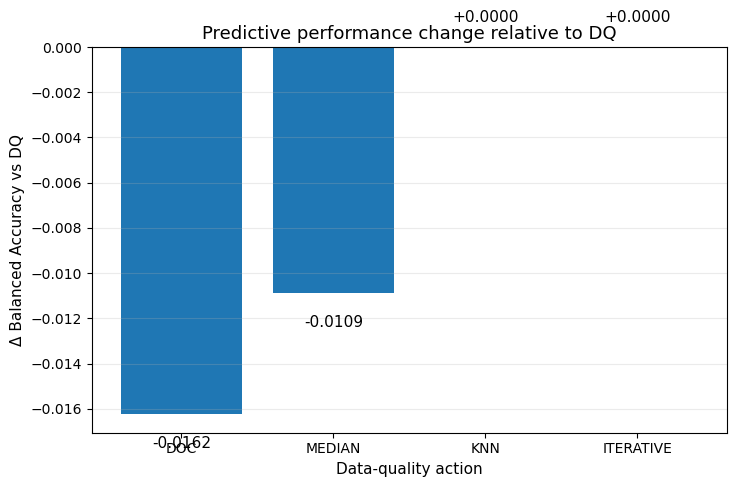

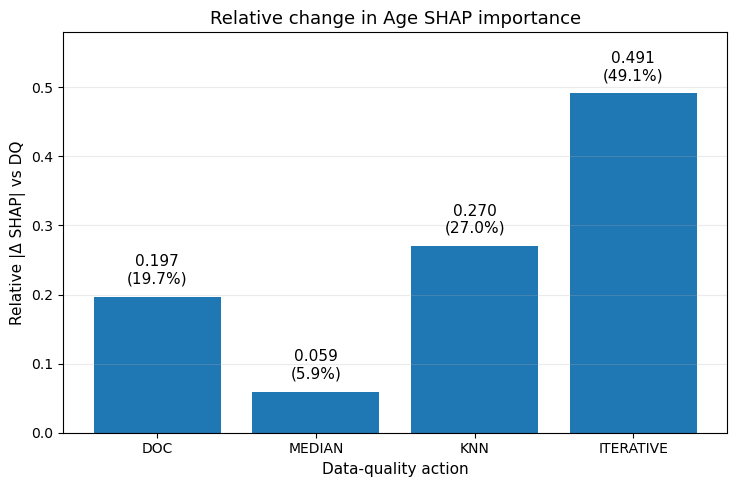

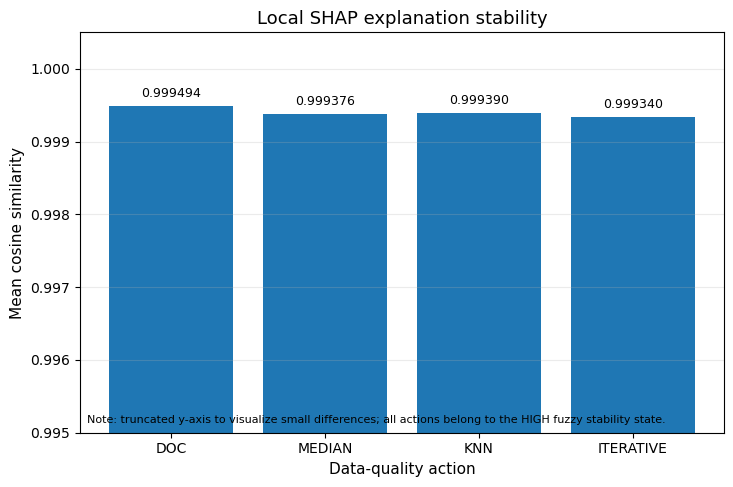

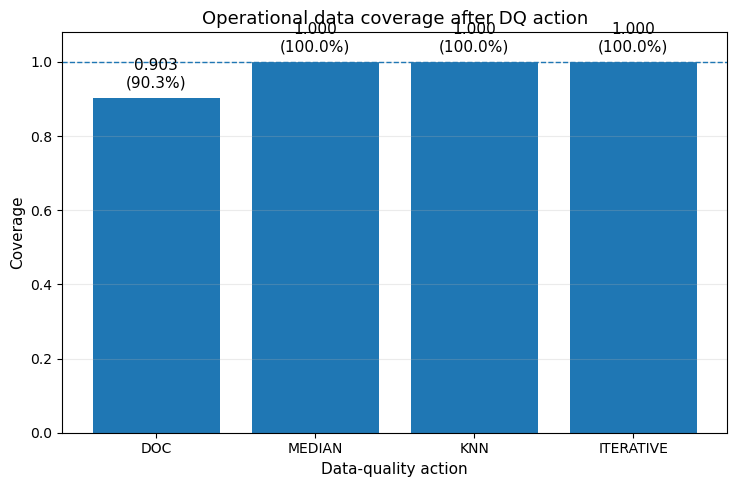



FINAL FOUR-METRIC VISUALIZATION

Source data:
 C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_4_DIABETES\results\18_final_fuzzy_explanation\figures\FINAL_FOUR_METRICS_FIGURE_SOURCE.csv

Generated figures:

FIG_FINAL_01_PERFORMANCE_DELTA_BA.pdf
SHA256 = e4582109d5d6033cdc9c5269d357306e4312a10624ab457a415f16f698cbb2ee

FIG_FINAL_01_PERFORMANCE_DELTA_BA.png
SHA256 = a375f60c1b547ffe6ad27c12b0dbb790794716d8d1160ec078e9b1d12fbedde0

FIG_FINAL_02_RELATIVE_AGE_SHAP_SHIFT.pdf
SHA256 = cb7078c6aba021685590e4cefe79157fe1d1676c7a6238ea6d82411a707ebbf3

FIG_FINAL_02_RELATIVE_AGE_SHAP_SHIFT.png
SHA256 = 84cdecd48b7db0612fe9649c5d23ae024ecda37ce99f9d97bfd6e48f243d1ba8

FIG_FINAL_03_SHAP_STABILITY.pdf
SHA256 = 7a158949bb9ced5f5806bddf86ac7331e1f68a54da4dc5beb3df628ee45d9672

FIG_FINAL_03_SHAP_STABILITY.png
SHA256 = 0f5aae78075f4b79eabbddc161fde7435ddc4cb7e7370d17e7d9eb1316fc24d1

FIG_FINAL_04_OPERATIONAL_COVERAGE.pdf
SHA256 = c9262af56ae88793742a30d00a56dced709f443bdf83a

In [11]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# FINAL VISUALIZATION OF THE FOUR FUZZY INPUT DIMENSIONS
#
# Purpose:
#   Produce publication-ready visualizations of:
#
#   1. Performance change vs DQ
#   2. Explanation shift vs DQ
#   3. Explanation stability
#   4. Operational coverage
#
# IMPORTANT:
#   - Pure visualization only
#   - No model retraining
#   - No SHAP recomputation
#   - No fuzzy recalibration
#   - No ranking
#   - No recommendation
# ============================================================


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import json
from datetime import datetime


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)

INPUT_FILE = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
    / "STEP17_FINAL_TEST_FUZZY_INPUT.csv"
)

OUT_DIR = (
    ROOT
    / "results"
    / "18_final_fuzzy_explanation"
    / "figures"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. LOAD FINAL TEST VALUES
# ============================================================

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found:\n{INPUT_FILE}"
    )


df = pd.read_csv(INPUT_FILE)


required_columns = [
    "Action",
    "FZ_PERFORMANCE_VALUE",
    "FZ_EXPLANATION_SHIFT_VALUE",
    "FZ_STABILITY_VALUE",
    "FZ_COVERAGE_VALUE"
]


missing = [
    c for c in required_columns
    if c not in df.columns
]


if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )


ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


df["Action"] = pd.Categorical(
    df["Action"],
    categories=ACTION_ORDER,
    ordered=True
)

df = (
    df
    .sort_values("Action")
    .reset_index(drop=True)
)


# ============================================================
# 3. SAVE SOURCE DATA FOR FIGURES
# ============================================================

SOURCE_FILE = (
    OUT_DIR
    / "FINAL_FOUR_METRICS_FIGURE_SOURCE.csv"
)

df[
    required_columns
].to_csv(
    SOURCE_FILE,
    index=False
)


# ============================================================
# 4. COMMON STYLE
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})


actions = (
    df["Action"]
    .astype(str)
    .tolist()
)


# ============================================================
# HELPER — SAVE FIGURE
# ============================================================

def save_figure(fig, name):

    png_path = (
        OUT_DIR
        / f"{name}.png"
    )

    pdf_path = (
        OUT_DIR
        / f"{name}.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    return png_path, pdf_path


# ============================================================
# 5. FIGURE 1 — PERFORMANCE CHANGE
# ============================================================

performance = (
    df[
        "FZ_PERFORMANCE_VALUE"
    ]
    .astype(float)
    .values
)


fig, ax = plt.subplots(
    figsize=(7.5, 5)
)


bars = ax.bar(
    actions,
    performance
)


# DQ reference: no change = 0

ax.axhline(
    0,
    linewidth=1.2,
    linestyle="--"
)


ax.set_title(
    "Predictive performance change relative to DQ"
)

ax.set_xlabel(
    "Data-quality action"
)

ax.set_ylabel(
    "Δ Balanced Accuracy vs DQ"
)


# Labels

offset = max(
    np.max(
        np.abs(performance)
    ) * 0.06,
    0.0005
)


for bar, value in zip(
    bars,
    performance
):

    if value >= 0:

        y = (
            value
            + offset
        )

        va = "bottom"

    else:

        y = (
            value
            - offset
        )

        va = "top"


    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        y,
        f"{value:+.4f}",
        ha="center",
        va=va
    )


ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


save_figure(
    fig,
    "FIG_FINAL_01_PERFORMANCE_DELTA_BA"
)


# ============================================================
# 6. FIGURE 2 — EXPLANATION SHIFT
# ============================================================

explanation_shift = (
    df[
        "FZ_EXPLANATION_SHIFT_VALUE"
    ]
    .astype(float)
    .values
)


fig, ax = plt.subplots(
    figsize=(7.5, 5)
)


bars = ax.bar(
    actions,
    explanation_shift
)


ax.set_title(
    "Relative change in Age SHAP importance"
)

ax.set_xlabel(
    "Data-quality action"
)

ax.set_ylabel(
    "Relative |Δ SHAP| vs DQ"
)


ax.set_ylim(
    0,
    max(
        0.55,
        explanation_shift.max()
        * 1.18
    )
)


for bar, value in zip(
    bars,
    explanation_shift
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}\n({value * 100:.1f}%)",
        ha="center",
        va="bottom"
    )


ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


save_figure(
    fig,
    "FIG_FINAL_02_RELATIVE_AGE_SHAP_SHIFT"
)


# ============================================================
# 7. FIGURE 3 — EXPLANATION STABILITY
# ============================================================

stability = (
    df[
        "FZ_STABILITY_VALUE"
    ]
    .astype(float)
    .values
)


fig, ax = plt.subplots(
    figsize=(7.5, 5)
)


bars = ax.bar(
    actions,
    stability
)


ax.set_title(
    "Local SHAP explanation stability"
)

ax.set_xlabel(
    "Data-quality action"
)

ax.set_ylabel(
    "Mean cosine similarity"
)


# Zoom is useful here because all values are close to 1.
# IMPORTANT: explicitly show the truncated axis.

lower_limit = min(
    0.995,
    stability.min() - 0.001
)

ax.set_ylim(
    lower_limit,
    1.0005
)


for bar, value in zip(
    bars,
    stability
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.00008,
        f"{value:.6f}",
        ha="center",
        va="bottom",
        fontsize=9
    )


ax.grid(
    axis="y",
    alpha=0.25
)


ax.text(
    0.01,
    0.02,
    "Note: truncated y-axis to visualize small differences; "
    "all actions belong to the HIGH fuzzy stability state.",
    transform=ax.transAxes,
    fontsize=8,
    va="bottom"
)


fig.tight_layout()


save_figure(
    fig,
    "FIG_FINAL_03_SHAP_STABILITY"
)


# ============================================================
# 8. FIGURE 4 — OPERATIONAL COVERAGE
# ============================================================

coverage = (
    df[
        "FZ_COVERAGE_VALUE"
    ]
    .astype(float)
    .values
)


fig, ax = plt.subplots(
    figsize=(7.5, 5)
)


bars = ax.bar(
    actions,
    coverage
)


ax.set_title(
    "Operational data coverage after DQ action"
)

ax.set_xlabel(
    "Data-quality action"
)

ax.set_ylabel(
    "Coverage"
)


ax.set_ylim(
    0,
    1.08
)


ax.axhline(
    1.0,
    linewidth=1,
    linestyle="--"
)


for bar, value in zip(
    bars,
    coverage
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}\n({value * 100:.1f}%)",
        ha="center",
        va="bottom"
    )


ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


save_figure(
    fig,
    "FIG_FINAL_04_OPERATIONAL_COVERAGE"
)


# ============================================================
# 9. HASHES
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(block)

    return h.hexdigest()


generated_files = sorted(
    list(
        OUT_DIR.glob(
            "FIG_FINAL_*"
        )
    )
)


hashes = {
    p.name: sha256_file(p)
    for p in generated_files
}


hashes[
    SOURCE_FILE.name
] = sha256_file(
    SOURCE_FILE
)


# ============================================================
# 10. METADATA
# ============================================================

metadata = {

    "title":
        "Final visualization of four evaluation dimensions",

    "timestamp":
        datetime.now().isoformat(),

    "source":
        "STEP17_FINAL_TEST_FUZZY_INPUT.csv",

    "baseline":
        "Dataset_DQ",

    "actions":
        ACTION_ORDER,

    "figures": {

        "FIG_FINAL_01":
            "Delta Balanced Accuracy vs DQ",

        "FIG_FINAL_02":
            "Relative Age SHAP shift vs DQ",

        "FIG_FINAL_03":
            "Local SHAP cosine stability",

        "FIG_FINAL_04":
            "Operational coverage"
    },

    "REF_used":
        False,

    "new_model_training":
        False,

    "new_SHAP_computation":
        False,

    "MF_recalibration":
        False,

    "global_score":
        False,

    "ranking":
        False,

    "recommendation":
        False,

    "purpose":
        "Publication-ready descriptive visualization only",

    "hashes":
        hashes
}


METADATA_FILE = (
    OUT_DIR
    / "final_four_metrics_figures_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 11. CONSOLE SUMMARY
# ============================================================

print("\n")
print("=" * 80)

print(
    "FINAL FOUR-METRIC VISUALIZATION"
)

print("=" * 80)


print(
    "\nSource data:\n",
    SOURCE_FILE
)


print(
    "\nGenerated figures:"
)


for p in generated_files:

    print(
        f"\n{p.name}"
    )

    print(
        "SHA256 =",
        hashes[p.name]
    )


print(
    "\nMetadata:",
    METADATA_FILE
)


print("\n")
print("=" * 80)

print(
    "STATUS: PASS_FINAL_VISUALIZATION"
)

print("=" * 80)


print(
    "\nNo model retraining."
)

print(
    "No SHAP recomputation."
)

print(
    "No fuzzy recalibration."
)

print(
    "No ranking."
)

print(
    "No recommendation."
)

In [12]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 4 DIABETES
#
# STEP 19 — CONSTRUCTION OF KB_EXPERIENCE
#
# ============================================================
#
# OBJECTIVE
# ---------
# Convert the completed Diabetes case study into a structured,
# traceable experimental experience that can later be used
# by the similarity mechanism for future DQ cases.
#
# IMPORTANT
# ---------
# This step:
#
#   - DOES NOT retrain any model
#   - DOES NOT recompute SHAP
#   - DOES NOT modify any dataset
#   - DOES NOT recalibrate fuzzy membership functions
#   - DOES NOT rank actions
#   - DOES NOT select a best action
#   - DOES NOT generate a recommendation
#   - DOES NOT infer that an action is reusable
#
# KB_EXPERIENCE stores observations from a completed case.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects"
    r"\Article 1 new demarche_encad3"
    r"\CASE_STUDY_4_DIABETES"
)


# ------------------------------------------------------------
# STEP 17 — final numerical results
# ------------------------------------------------------------

STEP17_DIR = (
    ROOT
    / "results"
    / "17_final_test_evaluation"
)

FINAL_MATRIX_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_MATRIX.csv"
)

PERFORMANCE_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_PERFORMANCE.csv"
)

COVERAGE_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_COVERAGE.csv"
)

SHAP_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_SHAP.csv"
)

STABILITY_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_STABILITY.csv"
)

FIDELITY_FILE = (
    STEP17_DIR
    / "STEP17_FINAL_TEST_FIDELITY.csv"
)


# ------------------------------------------------------------
# STEP 18 — final fuzzy interpretation
# ------------------------------------------------------------

STEP18_DIR = (
    ROOT
    / "results"
    / "18_final_fuzzy_explanation"
)

FUZZY_PROFILE_FILE = (
    STEP18_DIR
    / "STEP18_FINAL_TEST_FUZZY_PROFILES.csv"
)

FUZZY_EXPLANATION_FILE = (
    STEP18_DIR
    / "STEP18_FINAL_FUZZY_EXPLANATIONS.csv"
)


# ------------------------------------------------------------
# Rule base
# ------------------------------------------------------------

RULE_FILE = (
    ROOT
    / "knowledge"
    / "rules"
    / "action_rules"
    / "RULE_BASE_DQ_ACTION.csv"
)


# ------------------------------------------------------------
# KB_DOC
# ------------------------------------------------------------

KB_DOC_FILE = (
    ROOT
    / "knowledge"
    / "extracted"
    / "documentary_knowledge"
    / "consolidated"
    / "KB_DOC.csv"
)


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

KB_DIR = (
    ROOT
    / "knowledge"
    / "knowledge_base"
    / "KB_EXPERIENCE"
)

KB_DIR.mkdir(
    parents=True,
    exist_ok=True
)


RESULT_DIR = (
    ROOT
    / "results"
    / "19_kb_experience"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. REQUIRED FILE CHECK
# ============================================================

required_files = [
    FINAL_MATRIX_FILE,
    FUZZY_PROFILE_FILE,
    FUZZY_EXPLANATION_FILE,
    RULE_FILE
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )


# ============================================================
# 4. LOAD FINAL RESULTS
# ============================================================

final_matrix = pd.read_csv(
    FINAL_MATRIX_FILE
)

fuzzy_profiles = pd.read_csv(
    FUZZY_PROFILE_FILE
)

fuzzy_explanations = pd.read_csv(
    FUZZY_EXPLANATION_FILE
)

rules = pd.read_csv(
    RULE_FILE
)


# Optional documentary KB

if KB_DOC_FILE.exists():

    kb_doc = pd.read_csv(
        KB_DOC_FILE
    )

else:

    kb_doc = pd.DataFrame()


# ============================================================
# 5. ACTION INTEGRITY CHECK
# ============================================================

ACTION_ORDER = [
    "DOC",
    "MEDIAN",
    "KNN",
    "ITERATIVE"
]


if "Action" not in final_matrix.columns:

    raise ValueError(
        "Action column missing from STEP17 final matrix."
    )


actions_found = set(
    final_matrix["Action"]
    .astype(str)
)


if actions_found != set(ACTION_ORDER):

    raise ValueError(
        "Unexpected action set in STEP17.\n"
        f"Expected: {ACTION_ORDER}\n"
        f"Found: {sorted(actions_found)}"
    )


print(
    "\nAction integrity check: PASS"
)


# ============================================================
# 6. EXPERIENCE IDENTIFIER
# ============================================================

EXPERIENCE_ID = (
    "EXP_CASE4_DIABETES_001"
)


CASE_ID = (
    "CASE4_DIABETES"
)


# ============================================================
# 7. CASE CONTEXT
# ============================================================
#
# IMPORTANT:
# These fields describe the experiment.
#
# They are NOT a recommendation.
#
# ============================================================

case_context = {

    "experience_id":
        EXPERIENCE_ID,

    "case_id":
        CASE_ID,

    "domain":
        "HEALTHCARE",

    "dataset_family":
        "PIMA_DIABETES",

    "dataset_role":
        "TABULAR_BINARY_CLASSIFICATION",

    "prediction_target":
        "Outcome",

    "model_family":
        "CatBoostClassifier",

    "dq_feature":
        "Age",

    "dq_problem":
        "MISSING_VALUE",

    "dq_generation":
        "CONTROLLED_MCAR_INJECTION",

    "nominal_missing_rate":
        0.10,

    "observable_baseline":
        "Dataset_DQ",

    "reference_dataset_role":
        (
            "CONTROLLED_DQ_GENERATION_ONLY"
        ),

    "REF_used_for_action_comparison":
        False,

    "evaluation_support":
        "COMMON_TEST_SUPPORT",

    "test_total_n":
        154,

    "test_injected_missing_n":
        15,

    "common_test_n":
        139,

    "test_observed_missing_rate":
        15 / 154,

    "feature_selected_by":
        "REFERENCE_TREE_SHAP",

    "knowledge_sources":
        "DOCUMENT|STATISTICAL",

    "documentary_source_context":
        "WHO_STEPS",

    "action_count":
        4,

    "actions":
        ACTION_ORDER,

    "final_protocol_status":
        "COMPLETED",

    "human_decision_required":
        True
}


# ============================================================
# 8. SAVE CASE CONTEXT
# ============================================================

CONTEXT_FILE = (
    KB_DIR
    / "KB_EXPERIENCE_CASE_CONTEXT.json"
)


with open(
    CONTEXT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        case_context,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 9. BUILD ACTION-LEVEL EXPERIENCE RECORDS
# ============================================================

experience_records = []


def safe_value(row, column):

    if column not in row.index:
        return None

    value = row[column]

    if pd.isna(value):
        return None

    if isinstance(
        value,
        np.generic
    ):
        return value.item()

    return value


for action in ACTION_ORDER:

    # --------------------------------------------------------
    # Numerical results
    # --------------------------------------------------------

    result_rows = (
        final_matrix.loc[
            final_matrix["Action"]
            .astype(str)
            == action
        ]
    )


    if len(result_rows) != 1:

        raise ValueError(
            f"Expected exactly one STEP17 row for {action}."
        )


    result = (
        result_rows.iloc[0]
    )


    # --------------------------------------------------------
    # Fuzzy profiles
    # --------------------------------------------------------

    fp = (
        fuzzy_profiles.loc[
            fuzzy_profiles["Action"]
            .astype(str)
            == action
        ]
        .copy()
    )


    if len(fp) != 4:

        raise ValueError(
            f"{action}: expected four fuzzy dimensions, "
            f"found {len(fp)}."
        )


    fuzzy_state = {}


    for _, r in fp.iterrows():

        variable = str(
            r["FuzzyVariable"]
        )


        fuzzy_state[variable] = {

            "raw_value":
                safe_value(
                    r,
                    "RawValue"
                ),

            "dominant_term":
                safe_value(
                    r,
                    "DominantTerm"
                ),

            "dominant_degree":
                safe_value(
                    r,
                    "DominantDegree"
                ),

            "secondary_term":
                safe_value(
                    r,
                    "SecondaryTerm"
                ),

            "secondary_degree":
                safe_value(
                    r,
                    "SecondaryDegree"
                ),

            "boundary_state":
                bool(
                    r["BoundaryState"]
                )
        }


    # --------------------------------------------------------
    # Human-readable explanation
    # --------------------------------------------------------

    explanation_rows = (
        fuzzy_explanations.loc[
            fuzzy_explanations["Action"]
            .astype(str)
            == action
        ]
    )


    if len(explanation_rows) != 1:

        raise ValueError(
            f"Expected one fuzzy explanation for {action}."
        )


    explanation_row = (
        explanation_rows.iloc[0]
    )


    # --------------------------------------------------------
    # Rule provenance
    # --------------------------------------------------------

    rule_match = (
        rules.loc[
            rules["action_id"]
            .astype(str)
            .str.upper()
            .str.contains(
                action,
                na=False
            )
        ]
        if "action_id" in rules.columns
        else pd.DataFrame()
    )


    rule_ids = []


    if not rule_match.empty:

        if "rule_id" in rule_match.columns:

            rule_ids = (
                rule_match["rule_id"]
                .astype(str)
                .tolist()
            )


    # --------------------------------------------------------
    # Create experience record
    # --------------------------------------------------------

    record = {

        # ----------------------------------------------------
        # Identity
        # ----------------------------------------------------

        "experience_id":
            EXPERIENCE_ID,

        "case_id":
            CASE_ID,

        "action":
            action,


        # ----------------------------------------------------
        # Context
        # ----------------------------------------------------

        "domain":
            "HEALTHCARE",

        "dataset_family":
            "PIMA_DIABETES",

        "task_type":
            "BINARY_CLASSIFICATION",

        "target":
            "Outcome",

        "model_family":
            "CatBoostClassifier",


        # ----------------------------------------------------
        # DQ problem
        # ----------------------------------------------------

        "dq_feature":
            "Age",

        "dq_problem":
            "MISSING_VALUE",

        "dq_mechanism":
            "MCAR_CONTROLLED",

        "dq_rate":
            0.10,

        "baseline":
            "Dataset_DQ",


        # ----------------------------------------------------
        # Action provenance
        # ----------------------------------------------------

        "action_source":
            (
                "DOCUMENT"
                if action == "DOC"
                else "STATISTICAL"
            ),

        "rule_ids":
            rule_ids,


        # ----------------------------------------------------
        # Predictive performance
        # ----------------------------------------------------

        "roc_auc_test":
            safe_value(
                result,
                "ROC_AUC_TEST"
            ),

        "accuracy_test":
            safe_value(
                result,
                "Accuracy_TEST"
            ),

        "balanced_accuracy_test":
            safe_value(
                result,
                "BalancedAccuracy_TEST"
            ),

        "precision_test":
            safe_value(
                result,
                "Precision_TEST"
            ),

        "recall_test":
            safe_value(
                result,
                "Recall_TEST"
            ),

        "f1_test":
            safe_value(
                result,
                "F1_TEST"
            ),

        "delta_balanced_accuracy_vs_dq":
            safe_value(
                result,
                "Delta_BalancedAccuracy_vs_DQ"
            ),


        # ----------------------------------------------------
        # XAI impact
        # ----------------------------------------------------

        "age_shap_dq":
            safe_value(
                result,
                "Age_SHAP_DQ"
            ),

        "age_shap_action":
            safe_value(
                result,
                "Age_SHAP_Action"
            ),

        "delta_age_shap_vs_dq":
            safe_value(
                result,
                "Delta_Age_SHAP_vs_DQ"
            ),

        "relative_age_shap_shift":
            safe_value(
                result,
                "Relative_Age_SHAP_Shift"
            ),

        "rank_agreement_spearman_vs_dq":
            safe_value(
                result,
                "RankAgreement_Spearman_vs_DQ"
            ),


        # ----------------------------------------------------
        # Stability
        # ----------------------------------------------------

        "stability_cosine_mean":
            safe_value(
                result,
                "Stability_Cosine_Mean"
            ),

        "stability_cosine_sd":
            safe_value(
                result,
                "Stability_Cosine_SD"
            ),

        "stability_spearman_mean":
            safe_value(
                result,
                "Stability_Spearman_Mean"
            ),

        "stability_spearman_sd":
            safe_value(
                result,
                "Stability_Spearman_SD"
            ),


        # ----------------------------------------------------
        # Coverage
        # ----------------------------------------------------

        "coverage":
            safe_value(
                result,
                "Coverage"
            ),


        # ----------------------------------------------------
        # Fidelity
        # ----------------------------------------------------

        "fidelity_gate":
            safe_value(
                result,
                "FidelityGate"
            ),

        "max_additivity_error":
            safe_value(
                result,
                "MaxAdditivityError"
            ),


        # ----------------------------------------------------
        # Fuzzy interpretation
        # ----------------------------------------------------

        "fuzzy_profile":
            fuzzy_state,

        "intrinsic_explanation":
            safe_value(
                explanation_row,
                "IntrinsicExplanation"
            ),

        "comparative_explanation":
            safe_value(
                explanation_row,
                "ComparativeExplanation"
            ),


        # ----------------------------------------------------
        # Epistemic controls
        # ----------------------------------------------------

        "global_score":
            None,

        "global_rank":
            None,

        "automatic_recommendation":
            None,

        "selected_action":
            None,

        "human_validation":
            None,

        "reusable_without_new_validation":
            False,

        "epistemic_status":
            "OBSERVED_EXPERIMENTAL_EXPERIENCE"
    }


    experience_records.append(
        record
    )


# ============================================================
# 10. SAVE FULL JSON KNOWLEDGE BASE
# ============================================================

KB_JSON = (
    KB_DIR
    / "KB_EXPERIENCE.json"
)


kb_json_content = {

    "kb_name":
        "KB_EXPERIENCE",

    "kb_version":
        "1.0",

    "methodology":
        "DEMARCHE_ENCAD3",

    "case_context":
        case_context,

    "experiences":
        experience_records,

    "epistemic_policy": {

        "experience_is_observation":
            True,

        "experience_is_recommendation":
            False,

        "similarity_authorizes_reuse":
            False,

        "new_case_requires_validation":
            True,

        "automatic_best_action":
            False
    }
}


with open(
    KB_JSON,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        kb_json_content,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 11. CREATE FLAT CSV VERSION
# ============================================================
#
# The CSV is intentionally flatter than JSON.
# It will later be convenient for similarity analysis.
#
# ============================================================

flat_records = []


for record in experience_records:

    flat = {

        "experience_id":
            record["experience_id"],

        "case_id":
            record["case_id"],

        "domain":
            record["domain"],

        "dataset_family":
            record["dataset_family"],

        "task_type":
            record["task_type"],

        "target":
            record["target"],

        "model_family":
            record["model_family"],

        "dq_feature":
            record["dq_feature"],

        "dq_problem":
            record["dq_problem"],

        "dq_mechanism":
            record["dq_mechanism"],

        "dq_rate":
            record["dq_rate"],

        "baseline":
            record["baseline"],

        "action":
            record["action"],

        "action_source":
            record["action_source"],

        "delta_balanced_accuracy_vs_dq":
            record[
                "delta_balanced_accuracy_vs_dq"
            ],

        "relative_age_shap_shift":
            record[
                "relative_age_shap_shift"
            ],

        "stability_cosine_mean":
            record[
                "stability_cosine_mean"
            ],

        "coverage":
            record["coverage"],

        "fidelity_gate":
            record["fidelity_gate"],

        "performance_fuzzy":
            record[
                "fuzzy_profile"
            ][
                "PERFORMANCE"
            ][
                "dominant_term"
            ],

        "explanation_shift_fuzzy":
            record[
                "fuzzy_profile"
            ][
                "EXPLANATION_SHIFT"
            ][
                "dominant_term"
            ],

        "stability_fuzzy":
            record[
                "fuzzy_profile"
            ][
                "STABILITY"
            ][
                "dominant_term"
            ],

        "coverage_fuzzy":
            record[
                "fuzzy_profile"
            ][
                "COVERAGE"
            ][
                "dominant_term"
            ],

        "intrinsic_explanation":
            record[
                "intrinsic_explanation"
            ],

        "comparative_explanation":
            record[
                "comparative_explanation"
            ],

        "automatic_recommendation":
            None,

        "selected_action":
            None,

        "reusable_without_new_validation":
            False
    }


    flat_records.append(
        flat
    )


flat_df = pd.DataFrame(
    flat_records
)


KB_CSV = (
    KB_DIR
    / "KB_EXPERIENCE.csv"
)


flat_df.to_csv(
    KB_CSV,
    index=False
)


# ============================================================
# 12. CREATE CASE-LEVEL SIMILARITY PROFILE
# ============================================================
#
# IMPORTANT:
#
# This does NOT calculate similarity yet.
#
# It only creates the future searchable representation
# of this completed case.
#
# STEP20 will define the actual similarity mechanism.
#
# ============================================================

similarity_profile = {

    "experience_id":
        EXPERIENCE_ID,

    "case_id":
        CASE_ID,

    "domain":
        "HEALTHCARE",

    "data_modality":
        "TABULAR",

    "task_type":
        "BINARY_CLASSIFICATION",

    "target_type":
        "BINARY",

    "model_family":
        "TREE_ENSEMBLE",

    "xai_method":
        "TREE_SHAP",

    "dq_feature":
        "Age",

    "dq_feature_semantic_type":
        "DEMOGRAPHIC_NUMERIC",

    "dq_feature_data_type":
        "NUMERIC",

    "dq_problem":
        "MISSING_VALUE",

    "dq_mechanism":
        "MCAR_CONTROLLED",

    "dq_rate":
        0.10,

    "knowledge_available": [
        "DOCUMENT",
        "STATISTICAL"
    ],

    "candidate_action_families": [
        "EXCLUDE_FROM_ANALYSIS",
        "MEDIAN_IMPUTATION",
        "KNN_IMPUTATION",
        "ITERATIVE_IMPUTATION"
    ],

    "evaluation_dimensions": [
        "PREDICTIVE_PERFORMANCE",
        "EXPLANATION_SHIFT",
        "EXPLANATION_STABILITY",
        "COVERAGE",
        "FIDELITY_GATE"
    ],

    "observable_baseline":
        "Dataset_DQ",

    "reference_available_operationally":
        False,

    "human_validation_required":
        True,

    "reuse_policy":
        "SIMILARITY_DOES_NOT_AUTHORIZE_ACTION_REUSE"
}


SIMILARITY_PROFILE_FILE = (
    KB_DIR
    / "KB_EXPERIENCE_SIMILARITY_PROFILE.json"
)


with open(
    SIMILARITY_PROFILE_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        similarity_profile,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 13. DOCUMENTARY TRACEABILITY
# ============================================================

documentary_trace = []


if not kb_doc.empty:

    age_doc = (
        kb_doc.loc[
            (
                kb_doc["feature"]
                .astype(str)
                .str.lower()
                == "age"
            )
            &
            (
                kb_doc["dq_problem"]
                .astype(str)
                .str.upper()
                == "MISSING_VALUE"
            )
        ]
        .copy()
    )


    for _, row in age_doc.iterrows():

        trace = {}

        for column in [
            "knowledge_id",
            "candidate_id",
            "document_id",
            "chunk_id",
            "evidence_page",
            "feature",
            "dq_problem",
            "final_rule_role",
            "evidence",
            "condition",
            "final_action",
            "restrictions",
            "epistemic_status"
        ]:

            if column in row.index:

                value = row[column]

                if pd.isna(value):
                    value = None

                elif isinstance(
                    value,
                    np.generic
                ):
                    value = value.item()

                trace[column] = value


        documentary_trace.append(
            trace
        )


TRACE_FILE = (
    KB_DIR
    / "KB_EXPERIENCE_DOCUMENTARY_TRACE.json"
)


with open(
    TRACE_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        documentary_trace,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 14. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(65536),
            b""
        ):

            h.update(block)

    return h.hexdigest()


output_files = [
    CONTEXT_FILE,
    KB_JSON,
    KB_CSV,
    SIMILARITY_PROFILE_FILE,
    TRACE_FILE
]


hashes = {

    path.name:
        sha256_file(path)

    for path in output_files
}


# ============================================================
# 15. AUDIT METADATA
# ============================================================

metadata = {

    "step":
        "STEP19",

    "title":
        "Construction of KB_EXPERIENCE",

    "timestamp":
        datetime.now().isoformat(),

    "methodology":
        "DEMARCHE_ENCAD3",

    "experience_id":
        EXPERIENCE_ID,

    "case_id":
        CASE_ID,

    "source_step17":
        str(FINAL_MATRIX_FILE),

    "source_step18_profiles":
        str(FUZZY_PROFILE_FILE),

    "source_step18_explanations":
        str(FUZZY_EXPLANATION_FILE),

    "actions":
        ACTION_ORDER,

    "experience_records":
        len(
            experience_records
        ),

    "similarity_computed":
        False,

    "similarity_profile_created":
        True,

    "global_score":
        False,

    "action_ranking":
        False,

    "automatic_recommendation":
        False,

    "selected_action":
        False,

    "experience_reuse_authorized":
        False,

    "new_case_validation_required":
        True,

    "REF_used_for_action_comparison":
        False,

    "TEST_reopened":
        False,

    "new_model_training":
        False,

    "new_SHAP_computation":
        False,

    "dataset_modified":
        False,

    "fuzzy_recalibration":
        False,

    "status":
        "PASS_KB_EXPERIENCE_CONSTRUCTION",

    "hashes":
        hashes
}


METADATA_FILE = (
    RESULT_DIR
    / "step19_kb_experience_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 16. SCIENTIFIC SUMMARY
# ============================================================

SUMMARY_FILE = (
    RESULT_DIR
    / "step19_scientific_summary.txt"
)


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEMARCHE_ENCAD3 — STEP 19\n"
    )

    f.write(
        "CONSTRUCTION OF KB_EXPERIENCE\n\n"
    )


    f.write(
        "PURPOSE\n"
        "-------\n"
    )

    f.write(
        "Store the completed Diabetes DQ experiment "
        "as a structured, traceable experience for "
        "future case retrieval.\n\n"
    )


    f.write(
        "CASE\n"
        "----\n"
    )

    f.write(
        f"Experience ID: {EXPERIENCE_ID}\n"
    )

    f.write(
        f"Case ID: {CASE_ID}\n"
    )

    f.write(
        "Feature: Age\n"
    )

    f.write(
        "DQ problem: MISSING_VALUE\n"
    )

    f.write(
        "Observable baseline: Dataset_DQ\n"
    )

    f.write(
        "Final evaluation support: COMMON TEST SUPPORT\n\n"
    )


    f.write(
        "ACTIONS STORED\n"
        "--------------\n"
    )

    for action in ACTION_ORDER:

        f.write(
            f"- {action}\n"
        )


    f.write(
        "\nEPISTEMIC POLICY\n"
        "----------------\n"
    )

    f.write(
        "The stored experience represents observed "
        "experimental evidence, not a recommendation.\n"
    )

    f.write(
        "No action is globally ranked or selected.\n"
    )

    f.write(
        "Similarity with a future case will not "
        "authorize automatic reuse of an action.\n"
    )

    f.write(
        "Any future case requires new validation.\n\n"
    )


    f.write(
        "STATUS\n"
        "------\n"
    )

    f.write(
        "PASS_KB_EXPERIENCE_CONSTRUCTION\n"
    )


# ============================================================
# 17. DISPLAY
# ============================================================

print("\n")
print("=" * 80)

print(
    "STEP 19 — KB_EXPERIENCE CONSTRUCTION"
)

print("=" * 80)


print(
    "\nExperience ID:",
    EXPERIENCE_ID
)

print(
    "Case ID:",
    CASE_ID
)

print(
    "Actions stored:",
    len(experience_records)
)


print("\n")
print("-" * 80)

print(
    "KB_EXPERIENCE — FLAT VIEW"
)

print("-" * 80)


display_columns = [

    "action",
    "action_source",

    "delta_balanced_accuracy_vs_dq",

    "relative_age_shap_shift",

    "stability_cosine_mean",

    "coverage",

    "fidelity_gate",

    "performance_fuzzy",

    "explanation_shift_fuzzy",

    "stability_fuzzy",

    "coverage_fuzzy"
]


print(
    flat_df[
        display_columns
    ].to_string(
        index=False
    )
)


print("\n")
print("-" * 80)

print(
    "SIMILARITY PROFILE"
)

print("-" * 80)


for key, value in similarity_profile.items():

    print(
        f"{key}: {value}"
    )


print("\n")
print("=" * 80)

print(
    "OUTPUT FILES"
)

print("=" * 80)


for path in output_files:

    print(
        f"\n{path.name}"
    )

    print(
        "SHA256 =",
        hashes[path.name]
    )


print(
    "\nMetadata:",
    METADATA_FILE
)

print(
    "Summary:",
    SUMMARY_FILE
)


print("\n")
print("=" * 80)

print(
    "STEP 19 STATUS"
)

print("=" * 80)


print(
    "PASS_KB_EXPERIENCE_CONSTRUCTION"
)

print(
    "\nNo model retraining."
)

print(
    "No SHAP recomputation."
)

print(
    "No dataset modification."
)

print(
    "No fuzzy recalibration."
)

print(
    "No ranking."
)

print(
    "No selected action."
)

print(
    "No recommendation."
)

print(
    "Similarity NOT computed yet."
)

print(
    "\nNext step: STEP 20 — similarity mechanism "
    "for future DQ cases."
)


Action integrity check: PASS


STEP 19 — KB_EXPERIENCE CONSTRUCTION

Experience ID: EXP_CASE4_DIABETES_001
Case ID: CASE4_DIABETES
Actions stored: 4


--------------------------------------------------------------------------------
KB_EXPERIENCE — FLAT VIEW
--------------------------------------------------------------------------------
   action action_source  delta_balanced_accuracy_vs_dq  relative_age_shap_shift  stability_cosine_mean  coverage fidelity_gate performance_fuzzy explanation_shift_fuzzy stability_fuzzy    coverage_fuzzy
      DOC      DOCUMENT                      -0.016246                 0.196701               0.999494  0.902597          PASS          DEGRADED                MODERATE            HIGH          MODERATE
   MEDIAN   STATISTICAL                      -0.010870                 0.059148               0.999376  1.000000          PASS         PRESERVED                     LOW            HIGH FULL_OR_NEAR_FULL
      KNN   STATISTICAL                       0.000